# 06 — The evaluation record: every registered criterion scored, and what explains the predictions

The registered verdicts as they were written before scoring (C1–C5 here; C6–C19 in the notebooks that own them), the labelled post-hoc improvements and the learner tournament, the explanation of the entry model (F6, F7), the v2 verdict side by side with the v1 verdict, and the decision board (D0–D6). **This notebook runs last in `make all`** (after 09): it reads every scored table.

**Inputs → Outputs**

| Part | Was | What it does |
|---|---|---|
| A | notebook 08 | Evaluation on the held-out cohorts |
| B | notebook 08b | Post-hoc improvements (labelled post-hoc) |
| C | notebook 09 | What drives the predictions, and what a developer would do with them |
| D | notebook 18 | The v2 verdict: criteria C6–C12 scored as registered |

*Execution order:* Runs after notebook 09 (it reads every scored table). Paths are relative to the repository root.

*Part A*

| | Path | Notes |
|---|---|---|
| in | `data/processed/predictions_trackA.parquet` | notebooks 05–06 — baseline, Cox, discrete-time logit and LightGBM P(operation by 3/5/7 yr), with the observed outcome |
| in | `data/processed/predictions_trackB.parquet` | notebook 07 — base rate, logit and LightGBM P(built), raw and calibrated |
| in | `data/interim/trackA.parquet`, `data/interim/queue_clean.parquet`, `data/interim/queue_events.parquet` | notebooks 02/04 — for refits, follow-up windows and Track B's unresolved share |
| in | `results/dt_tuning.json` | notebook 06 — model settings reused by every refit |
| out | `docs/decisions.md` (#5), `results/success_criteria_registered.json` | the criteria, written by the first cell before any data are read |
| out | `results/test_outcome_status.csv`, `results/metrics.csv`, `results/metrics_by_region.csv` | outcome status by horizon; every model × horizon × metric with a 95% interval |
| out | `results/calibration.csv`, `results/calibration_by_region.csv`, `results/gains.csv` | calibration by predicted decile and by region; gains curves |
| out | `results/trackB_test_by_region.csv`, `results/success_criteria.csv` | Track B per region; PASS/FAIL per criterion |
| out | `figures/F4_*.png|svg`, `figures/F5_*.png|svg`, `figures/06_evaluation_record/*.png|svg`, `report/figure_notes.md` | report figures F4, F5 and the exploratory figures |
| out | `results/timing_error.csv` | expected years to operation against the observed date among test requests that operated within 7 years, by region (section 11) |

*Part B*

| | Path | Notes |
|---|---|---|
| in | `data/interim/trackA.parquet`, `data/interim/queue_clean.parquet` | notebooks 02/04 — refits |
| in | `results/dt_tuning.json`, `results/cox_penalizer_tuning.csv` | notebooks 05–06 — settings reused unchanged |
| in | `data/processed/predictions_trackA.parquet`, `results/dt_validation_2016.csv`, `results/cox_validation_calibration.csv` | notebooks 05–06 — stored predictions (checks) and Cox test predictions |
| in | `results/success_criteria_registered.json`, `results/metrics.csv` | notebook 08 — registered rules, seeds and the registered scores |
| out | `docs/decisions.md` (#34), `results/posthoc_protocol.json` | the protocol, written before any fit |
| out | `results/posthoc_validation_2016.csv`, `results/posthoc_choice.json`, `results/posthoc_parameters.csv` | the choice on 2016 and the fitted weights / recalibration |
| out | `results/posthoc_metrics.csv`, `results/posthoc_criteria.csv`, `results/posthoc_all_candidates_test.csv`, `results/posthoc_size_subset.csv`, `results/posthoc_checks.csv` | test scores of the chosen candidate (post-hoc), all candidates (not used for the choice), checks |
| out | `results/success_criteria_v5_registered.json`, `results/success_criteria_v5.csv`, `results/tournament_protocol.json` | criteria C18–C19 and the tournament protocol, committed before any fit (decision #59) |
| out | `results/tournament_grid_2016.csv`, `results/tournament_validation_2016.csv`, `results/tournament_choice.json`, `results/tournament_blend_weights.csv` | the choice of T* on 2016 |
| out | `results/tournament.csv`, `results/success_criteria_v5_scored.csv`, `results/tournament_criteria.csv`, `results/tournament_all_candidates_test.csv`, `data/processed/predictions_tournament.parquet` | T* on the test cohort, the verdict, the other candidates (not used for the choice) |
| out | `figures/F22_tournament.*`, `figures/06_evaluation_record/*.png|svg`, `report/figure_notes.md` | figures |

*Part C*

| | Path | Notes |
|---|---|---|
| in | `results/cox_hazard_ratios.csv` | notebook 05 — cause-specific hazard ratios |
| in | `data/interim/trackA.parquet`, `data/interim/queue_clean.parquet`, `results/dt_tuning.json` | notebooks 02, 04, 06 — to refit the final LightGBM |
| in | `data/processed/predictions_trackA.parquet` | notebooks 05–06 — stored predictions (check) and the baseline |
| in | `results/benchmarks.csv` | notebook 03 — LBNL facts reproduced from the file |
| out | `results/shap_values.csv`, `results/partial_dependence.csv` | SHAP values of P(operation by 5 yr) for a sample of test requests; partial-dependence curves |
| out | `results/sanity_checks.csv` | outside facts recovered or not |
| out | `results/ranking_table.csv`, `results/worked_examples.csv`, `results/explain_checks.csv` | the 25-request book, three worked examples, checks |
| out | `figures/F6_*.png|svg`, `figures/F7_*.png|svg`, `figures/06_evaluation_record/*.png|svg`, `report/figure_notes.md` | report figures F6, F7 and exploratory figures |

*Part D*

| | Path | Notes |
|---|---|---|
| in | `results/success_criteria_v2.csv`, `results/success_criteria_v2_registered.json` | notebook 11 — the registered lines |
| in | `results/metrics_v2.csv`, `results/level_repair_metrics.csv`, `results/landmark_metrics.csv`, `results/landmark_checks.csv`, `results/backtest_books.csv`, `results/book_coverage.csv` | notebooks 11/12/14/16 |
| in | `results/success_criteria.csv`, `results/trackB_calibration.csv` | notebooks 08/07 — the v1 verdict and Track B's calibration |
| out | `results/success_criteria_v2_scored.csv` | one row per registered line with PASS/FAIL |
| out | `results/verdict_summary.csv` | v1 and v2 counts side by side |
| out | `figures/06_evaluation_record/*` | the scored criteria and the Track B calibration plot |
| out | `results/evaluate_v2_checks.csv` | this notebook's checks |
| in | `results/cif_horizons.csv`, `archetype_profiles.csv`, `metrics.csv`, `drift_by_cohort.csv`, `drivers_5yr.csv`, `hazards_by_queue_year.csv`, `npv_table.csv`, `portfolio_review_summary.csv`, `policy_comparison.csv`, `recommended_books.csv`, `timing_error.csv` | the decision board (section 4) |
| out | `results/decision_board.csv`, `figures/D0_decision_board.*` … `D6_policies.*` | seven images, one per decision |

# Part A — Evaluation on the held-out cohorts (was notebook 08)

This notebook first writes the pre-registered success criteria to
`docs/decisions.md` (#5), then — and only then — scores every model on the
requests that entered the queue in 2017–2019 (Track A) and in 2017 (Track
B): discrimination, Brier score, calibration and ranking value with
bootstrap intervals, the criteria's PASS/FAIL verdicts, and the secondary
analyses (7-year check, leave-one-ISO-out, leakage ablation, robustness
reruns).

## 0. Pre-registered success criteria

The next cell runs before any data are read. It writes the criteria Alan
approved on 2026-10-04 (journal, question 9: "beat" by interval, model lift
≥ 1.5, the primary models as drafted) into `docs/decisions.md` as decision
#5, and a machine-readable copy to `results/success_criteria_registered.json`
that section 6 reads to decide PASS or FAIL. The decision text was committed
on its own before the first scoring run, so the git history shows the
criteria existed before any test metric did.

In [1]:
# Pre-registration: this cell reads no data
import json
import re
from pathlib import Path

REPO = Path.cwd().resolve().parent

DECISION_5 = """5. **Pre-registered success criteria** (Alan, 2026-10-04; written by the
   first cell of notebook 08 before any test data were read, and committed
   on its own before the first scoring run). Test sets: Track A requests
   entering 2017–2019 with outcomes through 2024-12-31; Track B resolved
   requests entering in 2017.
   *Primary models, named before scoring:* Track A — discrete-time LightGBM
   (`dt_lgbm`, lowest 2016 log loss in notebook 06); Track B — calibrated
   LightGBM (`lgbm_cal`). The discrete-time logit, Cox and the uncalibrated
   Track B models are reported beside them and decide nothing.
   *Benchmarks:* region × technology Aalen–Johansen cells (Track A, notebook
   05); region × technology base rates (Track B, notebook 07).
   - **C1** Uno's concordance index of P(operation by t), withdrawal as a
     competing event, above the baseline's at t = 3, 5 and 7 years.
   - **C2** IPCW Brier score below the baseline's at 3, 5 and 7 years.
   - **C3** Calibration slope between 0.9 and 1.1 at 3, 5 and 7 years.
   - **C4** Top-decile lift at 5 years ≥ 1.5: the share reaching operation
     within 5 years among the 10% of test requests with the highest
     predictions, divided by the share in the whole test cohort.
   - **C5** Track B, 2017 cohort: AUC above and Brier score below the base
     rate's.
   *"Beat"* (C1, C2, C5) means that the 95% percentile interval of the
   paired difference model − benchmark, from 200 bootstrap resamples of test
   requests (seeds 800 for Track A and 801 for Track B, recorded in
   `results/success_criteria_registered.json`), lies entirely on the better
   side of zero.
   *Thresholds* (C3, C4) are judged on the point estimate; the interval is
   reported. Each criterion × horizon is one PASS/FAIL line of
   `results/success_criteria.csv` (12 lines); point estimates are reported
   either way, failures are reported, not removed, and no criterion is
   changed after scoring.
   *Outcome and censoring:* for "operation by t" a request that withdrew
   before t is a known non-event; only requests still waiting on 2024-12-31
   before reaching t are censored, with inverse-probability-of-censoring
   weights from a Kaplan–Meier estimate of the censoring distribution. All
   censoring is administrative (2024-12-31), so that distribution is the
   distribution of the test requests' follow-up windows (2024-12-31 minus the
   request date), which is known at entry; every test request has at least
   five years, so the weights differ from 1 only at 7 years. The 7-year
   horizon is fully observed only for 2017 entrants; this is stated with
   every 7-year number, and the 7-year metrics are also reported for 2017
   entrants alone. *Change from the draft (journal, question 9):* the draft
   took the censoring distribution from the training set, whose requests
   have at least eight years of follow-up, so every weight would be 1 and the
   7-year metrics would silently drop the 2018–2019 requests still waiting.
   Changed before any test data were read.
   *Reported, not criteria:* Harrell's concordance, time-dependent AUC,
   calibration intercept and deciles, precision in the top 10%, metrics by
   region, the 7-year check on 2017 entrants, leave-one-ISO-out, the leakage
   ablation and the robustness reruns.
   *Rejected:* "beat" on point estimates (a difference inside the noise
   would count as a win); lift ≥ 1.5 × the baseline's lift (Alan, question
   9b).
"""

REGISTERED = {
    "decided": "2026-10-04",
    "n_boot": 200,
    "level": 0.95,
    "seed_track_a": 800,
    "seed_track_b": 801,
    "criteria": [
        {"id": "C1", "track": "A", "model": "dt_lgbm", "benchmark": "baseline", "metric": "uno_c",
         "horizons": [3, 5, 7], "rule": "beat"},
        {"id": "C2", "track": "A", "model": "dt_lgbm", "benchmark": "baseline", "metric": "brier",
         "horizons": [3, 5, 7], "rule": "beat"},
        {"id": "C3", "track": "A", "model": "dt_lgbm", "metric": "slope", "horizons": [3, 5, 7],
         "rule": "between", "low": 0.9, "high": 1.1},
        {"id": "C4", "track": "A", "model": "dt_lgbm", "metric": "lift_10", "horizons": [5],
         "rule": "at least", "value": 1.5},
        {"id": "C5", "track": "B", "model": "lgbm_cal", "benchmark": "baseline", "metric": "auc",
         "horizons": [None], "rule": "beat"},
        {"id": "C5", "track": "B", "model": "lgbm_cal", "benchmark": "baseline", "metric": "brier",
         "horizons": [None], "rule": "beat"},
    ],
}

decisions_file = REPO / "docs" / "decisions.md"
text = decisions_file.read_text(encoding="utf-8")
entry = re.compile(r"^5\. \*\*Pre-registered success criteria\*\*.*?(?=^6\. \*\*)", re.M | re.S)
assert len(entry.findall(text)) == 1, "decision #5 not found exactly once"
updated = entry.sub(lambda _: DECISION_5, text)
if updated != text:
    decisions_file.write_text(updated, encoding="utf-8")
(REPO / "results" / "success_criteria_registered.json").write_text(json.dumps(REGISTERED, indent=2), encoding="utf-8")
n_lines = sum(len(c["horizons"]) for c in REGISTERED["criteria"])
print(f"decision #5 {'written' if updated != text else 'already in place'}; {n_lines} criterion lines registered")

decision #5 already in place; 12 criterion lines registered


## Setup

Metrics are in `src/evaluation.py`: `censoring_km` (censoring
distribution), `horizon_outcome` (operated by t, with its IPCW weight —
withdrawal is a known non-event), `concordance` (Harrell's and Uno's, with
withdrawal as a competing event), `auc`, `brier`,
`calibration_slope_intercept`, `top_fraction` (precision and lift with ties
shared), `score` / `score_horizon` (all of them for several models),
`bootstrap` (resampled requests, paired across models) and `summarise`
(estimates, intervals and differences from the baseline). Refits for the
secondary analyses use `discrete_time.fit_both` / `predict_both` with
notebook 06's settings.

In [2]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, discrete_time, evaluation, paths, plots, survival_tools, track_b

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

NOTEBOOK = "06_evaluation_record"
TRACK_A = config.TRACK_A_REGIONS


def save(fig, name, caption):
    """Save a figure of this notebook under figures/06_evaluation_record/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    """Format a share as a percentage string."""
    return f"{100 * x:.{digits}f}%"

import time
import warnings

from sklearn.metrics import roc_curve

warnings.filterwarnings("ignore", category=FutureWarning)
START = time.time()
HORIZONS = config.HORIZONS
N_BOOT, LEVEL = REGISTERED["n_boot"], REGISTERED["level"]
MODELS = ["baseline", "cox", "dt_logit", "dt_lgbm"]
MODEL_LABELS = {"baseline": "Baseline (region × technology)", "cox": "Cox", "dt_logit": "Discrete-time logit",
                "dt_lgbm": "Discrete-time LightGBM"}
MODEL_STYLE = {"baseline": dict(color="#999999", marker="s", linestyle="--"),
               "cox": dict(color="#555555", marker="D", linestyle=":"),
               "dt_logit": dict(color="#009E73", marker="o"),
               "dt_lgbm": dict(color="#CC79A7", marker="^")}
METRIC_LABELS = {"uno_c": "Uno's C", "harrell_c": "Harrell's C", "auc": "Time-dependent AUC",
                 "brier": "Brier score (IPCW)", "slope": "Calibration slope", "intercept": "Calibration intercept",
                 "precision_10": "Precision in top 10%", "lift_10": "Top-decile lift"}
OFFSETS = dict(zip(MODELS, np.linspace(-0.24, 0.24, len(MODELS))))


def value(table, model, metric, horizon=None, column="estimate"):
    """One number from a summarised metrics table."""
    part = table[(table["model"] == model) & (table["metric"] == metric)]
    if horizon is not None:
        part = part[part["horizon"] == horizon]
    assert len(part) == 1, (model, metric, horizon)
    return part[column].iloc[0]


def ci(table, model, metric, horizon=None, digits=3, prefix=""):
    """'estimate [low, high]' for one row of a summarised table (prefix 'diff' for the paired difference)."""
    cols = [f"{prefix}{c}" if prefix else c for c in (["diff", "diff_low", "diff_high"] if prefix else ["estimate", "low", "high"])]
    est, low, high = (value(table, model, metric, horizon, c) for c in cols)
    return f"{est:.{digits}f} [{low:.{digits}f}, {high:.{digits}f}]"


def errorbars(ax, x, part, **style):
    """Points with their bootstrap interval."""
    return ax.errorbar(x, part["estimate"], yerr=[part["estimate"] - part["low"], part["high"] - part["estimate"]],
                       capsize=3, **style)

## 1. The test cohort and what is known about it at each horizon

Track A's test set is every request that entered the CAISO, ERCOT or PJM
queue in 2017–2019 (notebook 04's split). For P(operation by t) each request
is in one of four states at year t: operated, withdrew (a known non-event),
still waiting (a known non-event at t), or censored before t — still waiting
on 2024-12-31 with less than t years of follow-up, so its status at t is
unknown. The predictions were written by notebooks 05 and 06 before this
notebook existed; here they are joined to the outcomes for the first time.

test requests: 2,268; by entry year {np.int64(2017): 549, np.int64(2018): 672, np.int64(2019): 1047}; by region {'PJM': 1465, 'ERCOT': 479, 'CAISO': 324}
follow-up windows: 5.01–7.99 years; censored requests whose duration equals their window: True


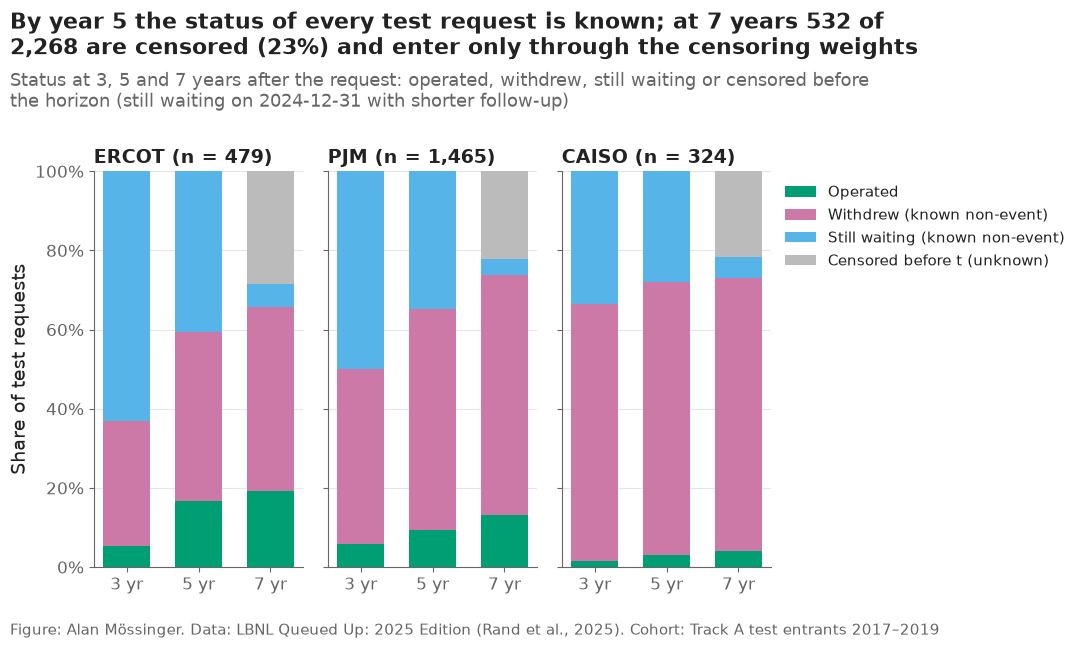

n  operated  withdrew  waiting  unknown
horizon region                                            
3       ERCOT    479        26       151      302        0
        PJM     1465        87       648      730        0
        CAISO    324         5       210      109        0
        all     2268       118      1009     1141        0
5       ERCOT    479        80       204      195        0
        PJM     1465       137       819      509        0
        CAISO    324        10       223       91        0
        all     2268       227      1246      795        0
7       ERCOT    479        92       223       28      136
        PJM     1465       192       891       56      326
        CAISO    324        13       224       17       70
        all     2268       297      1338      101      532

In [3]:
pred = pd.read_parquet(paths.DATA_PROCESSED / "predictions_trackA.parquet")
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
track_a["tech"] = track_a["type_clean"].map(plots.tech_group)
test = track_a[track_a["q_year"].between(*config.TEST_YEARS)].copy()
keys = test["project_key"].astype(str)
P = {h: pred[(pred["split"] == "test") & (pred["horizon"] == h)].set_index("project_key").loc[keys] for h in HORIZONS}
assert all(np.allclose(P[h]["duration_years"], test["duration_years"]) for h in HORIZONS)
durations = test["duration_years"].to_numpy()
events = test["event"].to_numpy()
regions = test["region"].astype(str).to_numpy()
preds = {h: {m: P[h][m].to_numpy() for m in MODELS} for h in HORIZONS}
follow_up = ((pd.Timestamp(config.CENSOR_DATE) - test["q_date"]).dt.days / config.DAYS_PER_YEAR).to_numpy()
print(f"test requests: {len(test):,}; by entry year {test['q_year'].value_counts().sort_index().to_dict()}; "
      f"by region {test['region'].value_counts().to_dict()}")
print(f"follow-up windows: {follow_up.min():.2f}–{follow_up.max():.2f} years; censored requests whose duration equals "
      f"their window: {np.allclose(durations[events == 0], follow_up[events == 0])}")

status_rows = []
for h in HORIZONS:
    states = {"operated": (events == 1) & (durations <= h), "withdrew": (events == 2) & (durations <= h),
              "waiting": durations > h, "unknown": (events == 0) & (durations <= h)}
    for region in TRACK_A + ["all"]:
        mask = np.ones(len(test), bool) if region == "all" else regions == region
        status_rows.append({"region": region, "horizon": h, "n": int(mask.sum()),
                            **{k: int((v & mask).sum()) for k, v in states.items()}})
status = pd.DataFrame(status_rows)
status.to_csv(paths.RESULTS / "test_outcome_status.csv", index=False)

STATE_COLORS = {"operated": config.OUTCOME_COLORS["operation"], "withdrew": config.OUTCOME_COLORS["withdrawal"],
                "waiting": "#56B4E9", "unknown": "#BBBBBB"}
fig, axes = plt.subplots(1, 3, sharey=True)
for ax, region in zip(axes, TRACK_A):
    part = status[status["region"] == region].set_index("horizon")
    bottom = np.zeros(len(part))
    for state, color in STATE_COLORS.items():
        share = part[state] / part["n"]
        ax.bar([f"{h} yr" for h in part.index], share, bottom=bottom, color=color, width=0.65,
               label={"operated": "Operated", "withdrew": "Withdrew (known non-event)",
                      "waiting": "Still waiting (known non-event)", "unknown": "Censored before t (unknown)"}[state])
        bottom += share.to_numpy()
    ax.set_title(f"{region} (n = {int(part['n'].iloc[0]):,})")
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Share of test requests")
axes[2].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=11)
allr = status[status["region"] == "all"].set_index("horizon")
plots.finish(fig,
             f"By year 5 the status of every test request is known; at 7 years {allr.loc[7, 'unknown']:,} of "
             f"{allr.loc[7, 'n']:,} are censored ({allr.loc[7, 'unknown'] / allr.loc[7, 'n']:.0%}) and enter only "
             "through the censoring weights",
             "Status at 3, 5 and 7 years after the request: operated, withdrew, still waiting or censored before the "
             "horizon (still waiting on 2024-12-31 with shorter follow-up)",
             "Track A test entrants 2017–2019")
save(fig, "08_01_outcome_status", "Status of the 2017–2019 test requests at 3, 5 and 7 years after the request, by region.")
plt.show()
status.set_index(["horizon", "region"])

**Reading this.** The test cohort has 2,268 requests (549 from 2017, 672 from 2018, 1,047 from 2019; PJM 1,465, ERCOT 479, CAISO 324). Every test request has at least five years of follow-up, so at 3 and 5 years nothing is censored: by year 5, 227 had reached operation, 1,246 had withdrawn and 795 were still waiting. Operation within 5 years is rare and uneven — 80 of 479 in ERCOT, 137 of 1,465 in PJM, 10 of 324 in CAISO — so CAISO's metrics rest on very few events. At 7 years 532 requests (23%) are censored: still waiting on 2024-12-31 with less than seven years of follow-up (all of them 2018–2019 entrants). For a developer or lender this is the honest scope of the test: 3- and 5-year results are fully observed, 7-year results lean on the 2017 entrants.

### Censoring weights

Every censored test request is censored on 2024-12-31, so the chance of
being observed for at least s years is the share of test requests whose
follow-up window (2024-12-31 minus request date) exceeds s — the Kaplan–Meier
estimate of the censoring distribution when every censoring time is known
(decision #5). A request whose status at year t is known gets weight
1/G(time it is known); censored ones get 0.

3 yr: G(3) = 1.000; weights equal to 1: 100.0%; zero: 0; largest 1.00
5 yr: G(5) = 1.000; weights equal to 1: 100.0%; zero: 0; largest 1.00
7 yr: G(7) = 0.242; weights equal to 1: 64.9%; zero: 532; largest 4.13


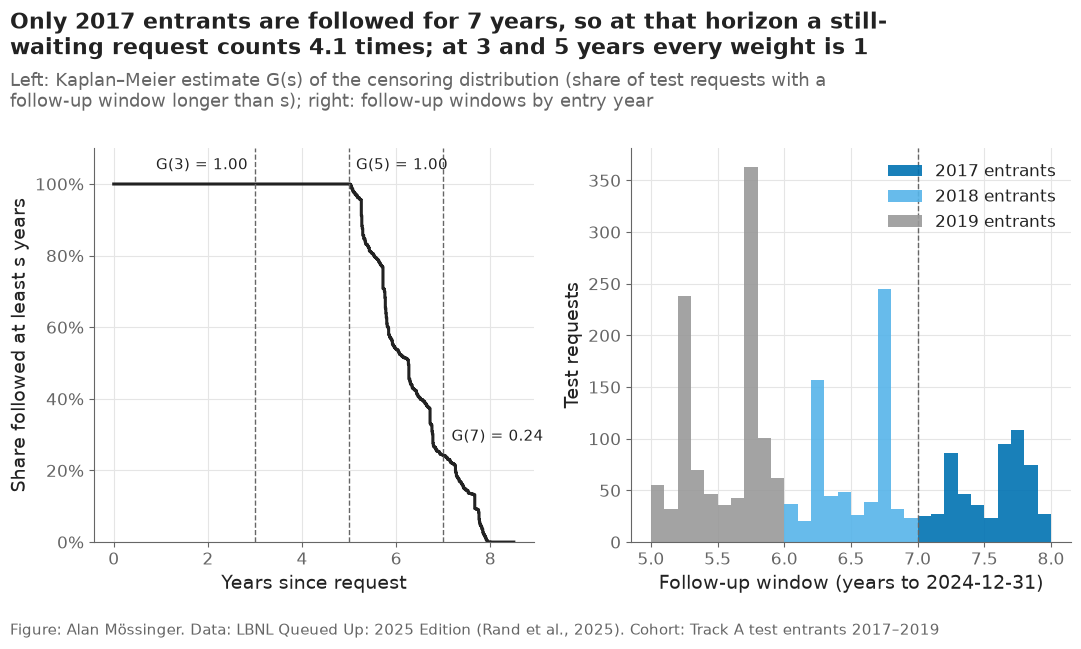

In [4]:
G = evaluation.censoring_km(follow_up, np.ones(len(test), dtype=bool))
weights = {h: evaluation.horizon_outcome(durations, events, h, G)[1] for h in HORIZONS}
for h in HORIZONS:
    w = weights[h]
    print(f"{h} yr: G({h}) = {float(G(h)):.3f}; weights equal to 1: {np.mean(w == 1):.1%}; zero: {int((w == 0).sum())}; "
          f"largest {w.max():.2f}")

fig, axes = plt.subplots(1, 2)
grid = np.linspace(0, 8.5, 851)
axes[0].step(grid, G(grid), where="post", color=plots.INK)
for h in HORIZONS:
    axes[0].axvline(h, color=plots.MUTED, linewidth=1, linestyle="--")
    dx, ha = {3: (-5, "right"), 5: (5, "left"), 7: (6, "left")}[h]  # labels on either side of their line, clear of the curve
    axes[0].annotate(f"G({h}) = {float(G(h)):.2f}", (h, float(G(h))), xytext=(dx, 8), textcoords="offset points",
                     ha=ha, va="bottom", fontsize=11)
axes[0].set_xlabel("Years since request")
axes[0].set_ylabel("Share followed at least s years")
axes[0].set_ylim(0, 1.1)
axes[0].yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
year_shades = {2017: "#0072B2", 2018: "#56B4E9", 2019: "#999999"}
for year, color in year_shades.items():
    axes[1].hist(follow_up[test["q_year"].to_numpy() == year], bins=np.arange(5, 8.01, 0.1), color=color, alpha=0.9,
                 label=f"{year} entrants")
axes[1].axvline(7, color=plots.MUTED, linewidth=1, linestyle="--")
axes[1].set_xlabel("Follow-up window (years to 2024-12-31)")
axes[1].set_ylabel("Test requests")
axes[1].legend(loc="upper right")
plots.finish(fig,
             f"Only 2017 entrants are followed for 7 years, so at that horizon a still-waiting request counts "
             f"{1 / float(G(7)):.1f} times; at 3 and 5 years every weight is 1",
             "Left: Kaplan–Meier estimate G(s) of the censoring distribution (share of test requests with a follow-up "
             "window longer than s); right: follow-up windows by entry year",
             "Track A test entrants 2017–2019")
save(fig, "08_02_censoring_weights", "Censoring distribution of the test cohort and follow-up windows by entry year.")
plt.show()

**Reading this.** G(3) = G(5) = 1.000, so every weight is 1 at 3 and 5 years and those metrics are plain proportions. G(7) = 0.242: only the 2017 entrants are followed for seven years, so a request still waiting at year 7 counts 1/0.242 = 4.13 times, while 532 censored requests count zero and 64.9% of weights stay at 1 (exits before year 5). The 7-year numbers therefore depend heavily on 549 requests from one entry year; section 7 checks them on those requests alone.

## 2. Discrimination and overall accuracy

For each horizon, all four models are scored on the same requests:
Uno's and Harrell's concordance (does a request that operated earlier have a
higher prediction than one that operated later, was still waiting, or had
withdrawn?), time-dependent AUC (operated by t vs not), the IPCW Brier score,
the calibration slope and intercept, and precision and lift in the top 10%.
Intervals come from 200 bootstrap resamples of test requests with the
registered seed; the same resamples score every model, so model − baseline
differences are paired.

In [5]:
metric_tables, draws_by_h = [], {}
for h in HORIZONS:
    point = evaluation.score_horizon(preds[h], durations, events, h, G)
    draws = evaluation.bootstrap(lambda sw: evaluation.score_horizon(preds[h], durations, events, h, G, sw),
                                 len(test), N_BOOT, REGISTERED["seed_track_a"])
    table = evaluation.summarise(point, draws, level=LEVEL)
    table.insert(2, "horizon", h)
    metric_tables.append(table)
    draws_by_h[h] = draws
metrics_a = pd.concat(metric_tables, ignore_index=True)
metrics_a.insert(0, "track", "A")
print(f"bootstrap done in {(time.time() - START) / 60:.1f} minutes since the start")
show = metrics_a[metrics_a["metric"].isin(["uno_c", "harrell_c", "auc", "brier"])].copy()
show["value"] = [f"{r.estimate:.3f} [{r.low:.3f}, {r.high:.3f}]" for r in show.itertuples()]
show.pivot_table(index=["metric", "horizon"], columns="model", values="value", aggfunc="first")[MODELS]

bootstrap done in 0.7 minutes since the start


model                          baseline                   cox              dt_logit               dt_lgbm
metric    horizon                                                                                        
auc       3        0.733 [0.678, 0.784]  0.852 [0.817, 0.882]  0.836 [0.796, 0.871]  0.858 [0.824, 0.893]
          5        0.725 [0.690, 0.761]  0.765 [0.735, 0.795]  0.751 [0.717, 0.779]  0.766 [0.736, 0.799]
          7        0.654 [0.617, 0.686]  0.696 [0.662, 0.726]  0.668 [0.630, 0.700]  0.672 [0.629, 0.703]
brier     3        0.047 [0.041, 0.054]  0.044 [0.038, 0.051]  0.042 [0.036, 0.049]  0.041 [0.035, 0.048]
          5        0.086 [0.079, 0.094]  0.081 [0.073, 0.089]  0.081 [0.073, 0.090]  0.081 [0.074, 0.089]
          7        0.122 [0.112, 0.132]  0.118 [0.108, 0.129]  0.121 [0.112, 0.133]  0.121 [0.113, 0.133]
harrell_c 3        0.731 [0.678, 0.781]  0.847 [0.814, 0.876]  0.832 [0.793, 0.866]  0.853 [0.820, 0.886]
          5        0.719 [0.684, 0.755]  0.760 [0.731, 0.789]  0.746 [0.715, 0.773]  0.760 [0.731, 0.791]
          7        0.671 [0.635, 0.701]  0.724 [0.695, 0.751]  0.699 [0.668, 0.724]  0.697 [0.668, 0.722]
uno_c     3        0.731 [0.678, 0.781]  0.847 [0.814, 0.876]  0.832 [0.793, 0.866]  0.853 [0.820, 0.886]
          5        0.719 [0.684, 0.755]  0.760 [0.731, 0.789]  0.746 [0.715, 0.773]  0.760 [0.731, 0.791]
          7        0.657 [0.623, 0.684]  0.703 [0.672, 0.731]  0.681 [0.648, 0.706]  0.672 [0.637, 0.700]

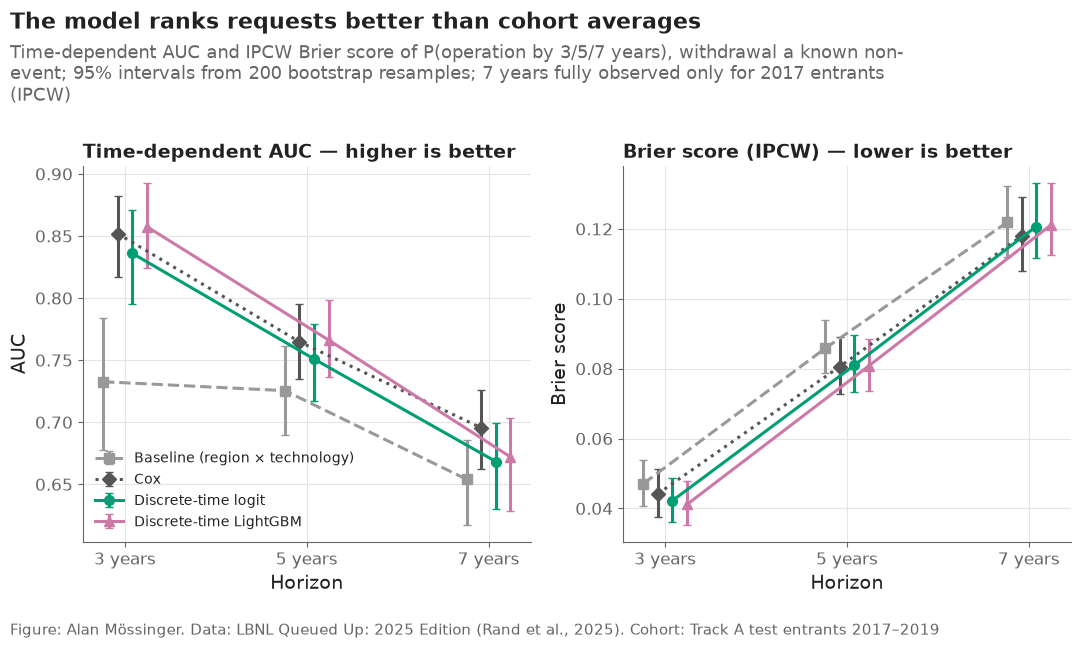

In [6]:
fig, axes = plt.subplots(1, 2, sharex=True)
for ax, metric in zip(axes, ["auc", "brier"]):
    for model in MODELS:
        part = metrics_a[(metrics_a["model"] == model) & (metrics_a["metric"] == metric)]
        errorbars(ax, part["horizon"] + OFFSETS[model], part, label=MODEL_LABELS[model], **MODEL_STYLE[model])
    ax.set_xticks(HORIZONS, [f"{h} years" for h in HORIZONS])
    ax.set_xlabel("Horizon")
    ax.set_title(METRIC_LABELS[metric] + (" — higher is better" if metric == "auc" else " — lower is better"))
axes[0].set_ylabel("AUC")
axes[1].set_ylabel("Brier score")
axes[0].legend(loc="lower left", fontsize=10)
auc_beats = {h: bool(metrics_a.query("model == 'dt_lgbm' and metric == 'auc' and horizon == @h")["beats"].eq(True).iloc[0])
             for h in HORIZONS}
plots.finish(fig,
             f"LightGBM's AUC {'beats' if auc_beats[3] and auc_beats[5] else 'does not beat'} cohort averages at 3 and 5 years — "
             f"at 5 years {value(metrics_a, 'dt_lgbm', 'auc', 5):.2f} against {value(metrics_a, 'baseline', 'auc', 5):.2f} — "
             f"{'and' if auc_beats[7] else 'but'} at 7 years its interval of the difference "
             f"{'excludes' if auc_beats[7] else 'includes'} zero",
             "Time-dependent AUC and IPCW Brier score of P(operation by 3/5/7 years), withdrawal a known non-event; "
             "95% intervals from 200 bootstrap resamples; 7 years fully observed only for 2017 entrants (IPCW)",
             "Track A test entrants 2017–2019")
plots.save_fig(fig, "F5_auc_brier_by_horizon", "Time-dependent AUC and IPCW Brier score of the four Track A models at 3, 5 and 7 years, test cohort, with bootstrap intervals.", NOTEBOOK)
plt.show()

**Reading this.** At 3 years the discrete-time LightGBM's time-dependent AUC is 0.858 [0.824, 0.893] against 0.733 [0.678, 0.784] for the region × technology baseline; at 5 years 0.766 [0.736, 0.799] against 0.725 [0.690, 0.761]; at 7 years 0.672 [0.629, 0.703] against 0.654 [0.617, 0.686]. The Brier scores move the same way (0.041 vs 0.047, 0.081 vs 0.086, 0.121 vs 0.122). Two things follow. Project-level information adds most for the near term: who reaches operation within 3 years is well predicted at entry; who does so by year 7 much less. And the Brier differences are small in absolute terms because most requests never operate, so a predictor that says "low" for everyone is already close; the gains are judged by the paired intervals in the next cells, not by eye. Cox is as good as LightGBM at 3 and 5 years (AUC 0.852 and 0.765) and the best model at 7 years (0.696; Brier 0.118). Caveat: the 7-year values are IPCW estimates driven by 2017 entrants (previous cell).

Uno − Harrell for LightGBM: {3: np.float64(0.0), 5: np.float64(0.0), 7: np.float64(-0.0245)}


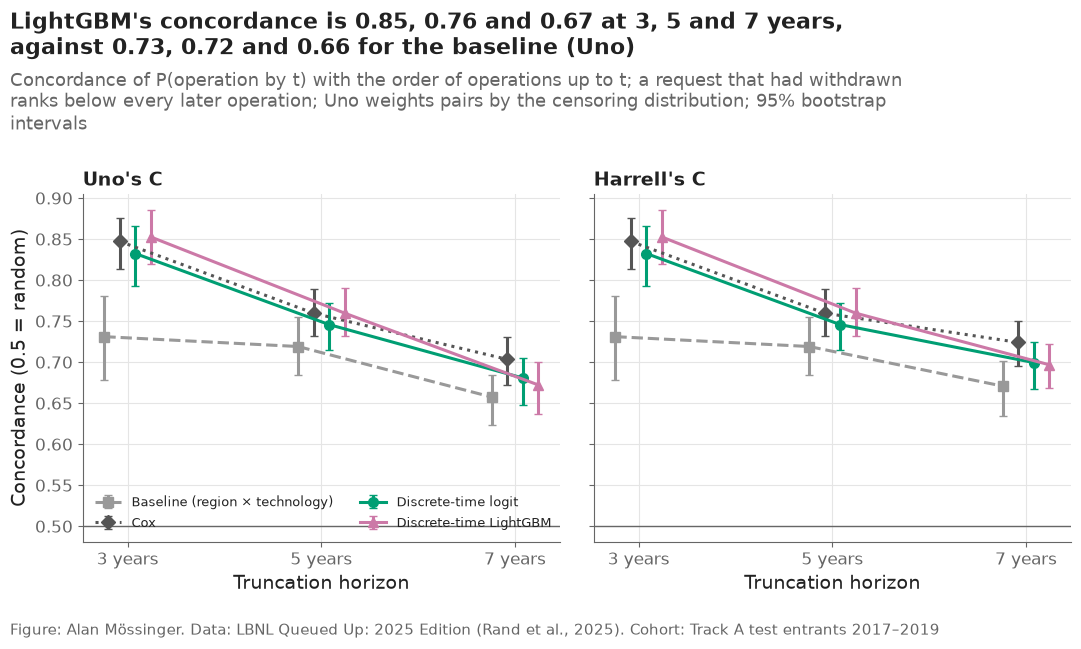

In [7]:
fig, axes = plt.subplots(1, 2, sharey=True)
for ax, metric in zip(axes, ["uno_c", "harrell_c"]):
    for model in MODELS:
        part = metrics_a[(metrics_a["model"] == model) & (metrics_a["metric"] == metric)]
        errorbars(ax, part["horizon"] + OFFSETS[model], part, label=MODEL_LABELS[model], **MODEL_STYLE[model])
    ax.axhline(0.5, color=plots.MUTED, linewidth=1)
    ax.set_xticks(HORIZONS, [f"{h} years" for h in HORIZONS])
    ax.set_xlabel("Truncation horizon")
    ax.set_title(METRIC_LABELS[metric])
axes[0].set_ylabel("Concordance (0.5 = random)")
axes[0].legend(loc="lower left", fontsize=9.5, ncol=2)
gap = {h: value(metrics_a, "dt_lgbm", "uno_c", h) - value(metrics_a, "dt_lgbm", "harrell_c", h) for h in HORIZONS}
print("Uno − Harrell for LightGBM:", {h: round(g, 4) for h, g in gap.items()})
plots.finish(fig,
             f"LightGBM's concordance is {value(metrics_a, 'dt_lgbm', 'uno_c', 3):.2f}, "
             f"{value(metrics_a, 'dt_lgbm', 'uno_c', 5):.2f} and {value(metrics_a, 'dt_lgbm', 'uno_c', 7):.2f} at 3, 5 and 7 "
             f"years, against {value(metrics_a, 'baseline', 'uno_c', 3):.2f}, {value(metrics_a, 'baseline', 'uno_c', 5):.2f} "
             f"and {value(metrics_a, 'baseline', 'uno_c', 7):.2f} for the baseline (Uno)",
             "Concordance of P(operation by t) with the order of operations up to t; a request that had withdrawn ranks "
             "below every later operation; Uno weights pairs by the censoring distribution; 95% bootstrap intervals",
             "Track A test entrants 2017–2019")
save(fig, "08_03_concordance", "Uno's and Harrell's concordance of the four Track A models by horizon, with bootstrap intervals.")
plt.show()

**Reading this.** With no censoring before year 5, Uno's and Harrell's concordance are identical at 3 and 5 years (0.853 and 0.760 for LightGBM, 0.731 and 0.719 for the baseline). At 7 years Uno's weighting lowers LightGBM's value by 0.0245 (to 0.672) and the baseline's to 0.657, while Cox keeps 0.703: the weighted pairs are the 2017 entrants' late operations, which LightGBM ranks less well. Concordance reads as the chance that, of two requests where one operated first, the model gave that one the higher score: about 85% at 3 years, 76% at 5, 67% at 7.

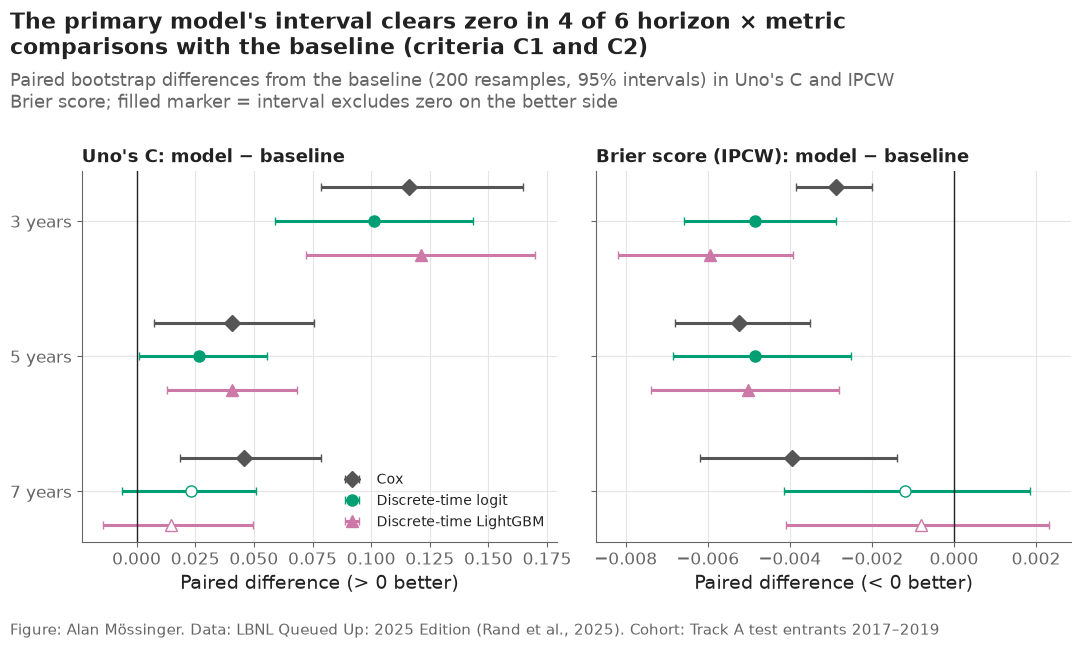

model                               cox                 dt_logit                  dt_lgbm
metric horizon                                                                           
auc    3        +0.119 [+0.080, +0.169]  +0.103 [+0.061, +0.147]  +0.125 [+0.073, +0.174]
       5        +0.039 [+0.006, +0.075]  +0.026 [-0.001, +0.055]  +0.041 [+0.013, +0.069]
       7        +0.042 [+0.008, +0.077]  +0.014 [-0.020, +0.048]  +0.018 [-0.016, +0.060]
brier  3        -0.003 [-0.004, -0.002]  -0.005 [-0.007, -0.003]  -0.006 [-0.008, -0.004]
       5        -0.005 [-0.007, -0.004]  -0.005 [-0.007, -0.003]  -0.005 [-0.007, -0.003]
       7        -0.004 [-0.006, -0.001]  -0.001 [-0.004, +0.002]  -0.001 [-0.004, +0.002]
uno_c  3        +0.116 [+0.079, +0.165]  +0.101 [+0.059, +0.143]  +0.121 [+0.072, +0.170]
       5        +0.041 [+0.007, +0.076]  +0.027 [+0.001, +0.055]  +0.041 [+0.013, +0.069]
       7        +0.046 [+0.019, +0.079]  +0.023 [-0.006, +0.051]  +0.015 [-0.014, +0.050]

In [8]:
fig, axes = plt.subplots(1, 2, sharey=True)
compared = ["cox", "dt_logit", "dt_lgbm"]
for ax, metric in zip(axes, ["uno_c", "brier"]):
    for h_i, h in enumerate(HORIZONS):
        for m_i, model in enumerate(compared):
            row = metrics_a[(metrics_a["model"] == model) & (metrics_a["metric"] == metric) & (metrics_a["horizon"] == h)].iloc[0]
            y = h_i * (len(compared) + 1) + m_i
            style = MODEL_STYLE[model]
            ax.errorbar(row["diff"], y, xerr=[[row["diff"] - row["diff_low"]], [row["diff_high"] - row["diff"]]],
                        fmt=style["marker"], color=style["color"], capsize=3, markersize=8,
                        markerfacecolor=style["color"] if row["beats"] else "white",
                        label=MODEL_LABELS[model] if h_i == 0 else None)
    ax.axvline(0, color=plots.INK, linewidth=1)
    ax.set_title(f"{METRIC_LABELS[metric]}: model − baseline", fontsize=13)
    ax.set_xlabel("Paired difference (" + ("> 0 better" if metric == "uno_c" else "< 0 better") + ")")
centres = [h_i * (len(compared) + 1) + 1 for h_i in range(len(HORIZONS))]
axes[0].set_yticks(centres, [f"{h} years" for h in HORIZONS])
axes[0].invert_yaxis()
axes[0].legend(loc="lower right", fontsize=10)
beats = metrics_a[(metrics_a["model"] == "dt_lgbm") & metrics_a["metric"].isin(["uno_c", "brier"])]
plots.finish(fig,
             f"The primary model's interval clears zero in {int(beats['beats'].sum())} of 6 horizon × metric comparisons "
             "with the baseline (criteria C1 and C2)",
             "Paired bootstrap differences from the baseline (200 resamples, 95% intervals) in Uno's C and IPCW Brier "
             "score; filled marker = interval excludes zero on the better side",
             "Track A test entrants 2017–2019")
save(fig, "08_04_differences_from_baseline", "Paired differences from the baseline in Uno's concordance and Brier score, three models, three horizons.")
plt.show()
d = metrics_a[metrics_a["diff"].notna() & metrics_a["metric"].isin(["uno_c", "auc", "brier"])].copy()
d["difference"] = [f"{r.diff:+.3f} [{r.diff_low:+.3f}, {r.diff_high:+.3f}]" for r in d.itertuples()]
d.pivot_table(index=["metric", "horizon"], columns="model", values="difference", aggfunc="first")[compared]

**Reading this.** Paired with the baseline on the same resamples, LightGBM's gain in Uno's C is +0.121 [+0.072, +0.170] at 3 years and +0.041 [+0.013, +0.069] at 5 years, and its Brier score is lower by 0.006 [0.004, 0.008] and 0.005 [0.003, 0.007]: both intervals exclude zero at 3 and 5 years. At 7 years the intervals include zero (Uno +0.015 [−0.014, +0.050]; Brier −0.001 [−0.004, +0.002]), so criteria C1 and C2 fail there. Cox, which decides nothing in the criteria, beats the baseline at all three horizons on both metrics (at 7 years Uno +0.046 [+0.019, +0.079], Brier −0.004 [−0.006, −0.001]). For the report this is the main ranking result: the primary model adds clear value over cohort averages for 3- and 5-year screening, and its late-horizon edge is not established.

### Within each region

Most of the baseline's ranking power is region: CAISO requests rarely
operate, ERCOT requests often do. Within one region the baseline can only
rank by technology. The same metrics computed inside each region (each with
its own censoring distribution and the same 200 resamples) show whether the
models rank requests beyond knowing their region.

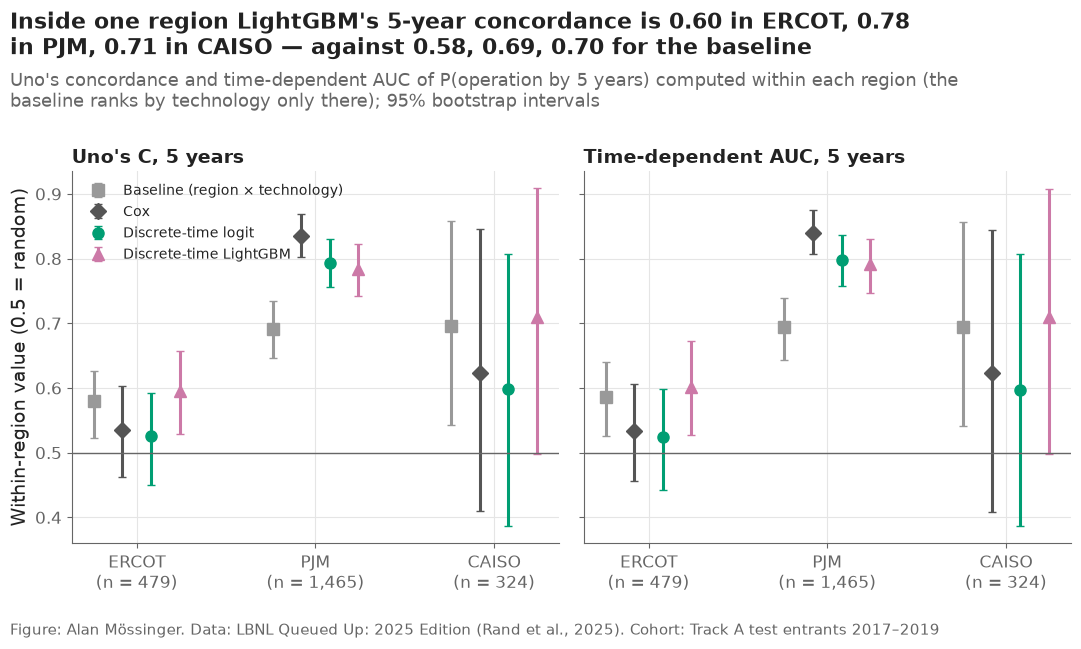

model                              baseline                   cox              dt_logit               dt_lgbm
region metric horizon                                                                                        
CAISO  auc    3        0.884 [0.802, 0.957]  0.852 [0.596, 1.000]  0.873 [0.686, 1.000]  0.970 [0.904, 1.000]
              5        0.694 [0.541, 0.857]  0.623 [0.408, 0.845]  0.597 [0.386, 0.807]  0.709 [0.498, 0.908]
              7        0.540 [0.389, 0.719]  0.567 [0.394, 0.766]  0.508 [0.340, 0.669]  0.614 [0.438, 0.788]
       brier  3        0.015 [0.003, 0.029]  0.014 [0.003, 0.027]  0.015 [0.003, 0.029]  0.013 [0.003, 0.025]
              5        0.030 [0.015, 0.049]  0.029 [0.015, 0.047]  0.029 [0.014, 0.048]  0.027 [0.013, 0.044]
              7        0.043 [0.023, 0.066]  0.042 [0.023, 0.065]  0.042 [0.023, 0.066]  0.041 [0.023, 0.062]
       uno_c  3        0.883 [0.801, 0.957]  0.851 [0.595, 1.000]  0.872 [0.684, 1.000]  0.968 [0.903, 1.000]
              5        0.695 [0.543, 0.858]  0.624 [0.409, 0.845]  0.598 [0.386, 0.807]  0.709 [0.498, 0.909]
              7        0.555 [0.393, 0.721]  0.596 [0.413, 0.776]  0.558 [0.385, 0.714]  0.627 [0.445, 0.796]
ERCOT  auc    3        0.582 [0.474, 0.664]  0.605 [0.490, 0.715]  0.605 [0.484, 0.716]  0.576 [0.439, 0.697]
              5        0.586 [0.525, 0.641]  0.533 [0.455, 0.607]  0.525 [0.442, 0.598]  0.602 [0.528, 0.672]
              7        0.562 [0.497, 0.634]  0.510 [0.426, 0.597]  0.495 [0.404, 0.580]  0.520 [0.436, 0.594]
       brier  3        0.053 [0.038, 0.070]  0.054 [0.040, 0.071]  0.057 [0.042, 0.077]  0.057 [0.043, 0.076]
              5        0.137 [0.115, 0.156]  0.141 [0.117, 0.162]  0.145 [0.122, 0.166]  0.140 [0.118, 0.159]
              7        0.162 [0.138, 0.184]  0.167 [0.137, 0.195]  0.171 [0.144, 0.197]  0.170 [0.145, 0.192]
       uno_c  3        0.583 [0.479, 0.661]  0.601 [0.488, 0.707]  0.602 [0.484, 0.715]  0.575 [0.439, 0.693]
              5        0.579 [0.523, 0.627]  0.534 [0.462, 0.603]  0.526 [0.450, 0.592]  0.596 [0.529, 0.656]
              7        0.582 [0.533, 0.633]  0.500 [0.423, 0.578]  0.498 [0.427, 0.570]  0.601 [0.539, 0.651]
PJM    auc    3        0.753 [0.694, 0.809]  0.915 [0.887, 0.941]  0.907 [0.881, 0.931]  0.906 [0.875, 0.934]
              5        0.694 [0.644, 0.738]  0.840 [0.808, 0.875]  0.798 [0.758, 0.837]  0.792 [0.747, 0.830]
              7        0.618 [0.576, 0.654]  0.732 [0.694, 0.769]  0.673 [0.632, 0.723]  0.654 [0.603, 0.704]
       brier  3        0.052 [0.046, 0.063]  0.048 [0.040, 0.059]  0.044 [0.037, 0.053]  0.042 [0.036, 0.051]
              5        0.081 [0.074, 0.092]  0.072 [0.064, 0.083]  0.072 [0.063, 0.083]  0.073 [0.065, 0.084]
              7        0.126 [0.113, 0.140]  0.119 [0.106, 0.133]  0.121 [0.107, 0.136]  0.123 [0.110, 0.137]
       uno_c  3        0.749 [0.693, 0.804]  0.908 [0.882, 0.933]  0.899 [0.874, 0.924]  0.897 [0.869, 0.924]
              5        0.691 [0.646, 0.734]  0.835 [0.802, 0.868]  0.793 [0.756, 0.830]  0.784 [0.742, 0.823]
              7        0.623 [0.585, 0.658]  0.753 [0.718, 0.787]  0.696 [0.658, 0.739]  0.639 [0.593, 0.687]

In [9]:
region_tables = []
for r_i, region in enumerate(TRACK_A):
    mask = regions == region
    G_r = evaluation.censoring_km(follow_up[mask], np.ones(mask.sum(), dtype=bool))
    for h in HORIZONS:
        sub = {m: preds[h][m][mask] for m in MODELS}
        point = evaluation.score_horizon(sub, durations[mask], events[mask], h, G_r)
        draws = evaluation.bootstrap(lambda sw: evaluation.score_horizon(sub, durations[mask], events[mask], h, G_r, sw),
                                     int(mask.sum()), N_BOOT, REGISTERED["seed_track_a"] + 10 + r_i)
        table = evaluation.summarise(point, draws, level=LEVEL)
        table.insert(0, "region", region)
        table.insert(3, "horizon", h)
        region_tables.append(table)
metrics_region = pd.concat(region_tables, ignore_index=True)
metrics_region.to_csv(paths.RESULTS / "metrics_by_region.csv", index=False)

fig, axes = plt.subplots(1, 2, sharey=True)
for ax, metric in zip(axes, ["uno_c", "auc"]):
    for model in MODELS:
        part = metrics_region[(metrics_region["model"] == model) & (metrics_region["metric"] == metric)
                              & (metrics_region["horizon"] == 5)]
        x = np.arange(len(TRACK_A)) + OFFSETS[model]
        errorbars(ax, x, part.set_index("region").loc[TRACK_A], fmt=MODEL_STYLE[model]["marker"],
                  color=MODEL_STYLE[model]["color"], markersize=8, label=MODEL_LABELS[model])
    ax.axhline(0.5, color=plots.MUTED, linewidth=1)
    ax.set_xticks(range(len(TRACK_A)), [f"{r}\n(n = {(regions == r).sum():,})" for r in TRACK_A])
    ax.set_title(f"{METRIC_LABELS[metric]}, 5 years")
axes[0].set_ylabel("Within-region value (0.5 = random)")
axes[0].legend(loc="upper left", fontsize=10)
within = metrics_region[(metrics_region["metric"] == "uno_c") & (metrics_region["horizon"] == 5)].set_index(["region", "model"])["estimate"]
plots.finish(fig,
             "Inside one region LightGBM's 5-year concordance is "
             + ", ".join(f"{within[(r, 'dt_lgbm')]:.2f} in {r}" for r in TRACK_A)
             + " — against " + ", ".join(f"{within[(r, 'baseline')]:.2f}" for r in TRACK_A) + " for the baseline",
             "Uno's concordance and time-dependent AUC of P(operation by 5 years) computed within each region "
             "(the baseline ranks by technology only there); 95% bootstrap intervals",
             "Track A test entrants 2017–2019")
save(fig, "08_05_within_region", "Within-region concordance and AUC at 5 years for the four Track A models.")
plt.show()
w = metrics_region[metrics_region["metric"].isin(["uno_c", "auc", "brier"])].copy()
w["value"] = [f"{r.estimate:.3f} [{r.low:.3f}, {r.high:.3f}]" for r in w.itertuples()]
w.pivot_table(index=["region", "metric", "horizon"], columns="model", values="value", aggfunc="first")[MODELS]

**Reading this.** Inside PJM, LightGBM's 5-year concordance is 0.784 [0.742, 0.823] against the baseline's 0.691 [0.646, 0.734] — a real gain where the baseline can only rank by technology (Cox does better still, 0.835). Inside ERCOT the models barely rank at all: LightGBM 0.596 [0.529, 0.656] against 0.579 [0.523, 0.627], with Cox (0.534) and the logit (0.526) near random — ERCOT's training data under delayed entry are thin (98 of 732 training requests in notebook 06). CAISO's intervals are too wide to say anything (10 operations within 5 years; LightGBM 0.709 [0.498, 0.909]). So most of the pooled gain comes from ranking within PJM, plus getting the regions in the right order, which the baseline also does.

## 3. Calibration

Can a predicted 20% be read as a 20% chance? Test requests are cut into ten
equal groups by each model's prediction; in each group the mean prediction is
set against the Aalen–Johansen estimate of P(operation by t) (which handles
the censored requests at 7 years) with a 200-resample bootstrap band. The
calibration slope and intercept summarise the same picture: slope 1 and
intercept 0 are perfect; a slope below 1 means the predictions are too
spread out, an intercept above 0 that they are too low on average.

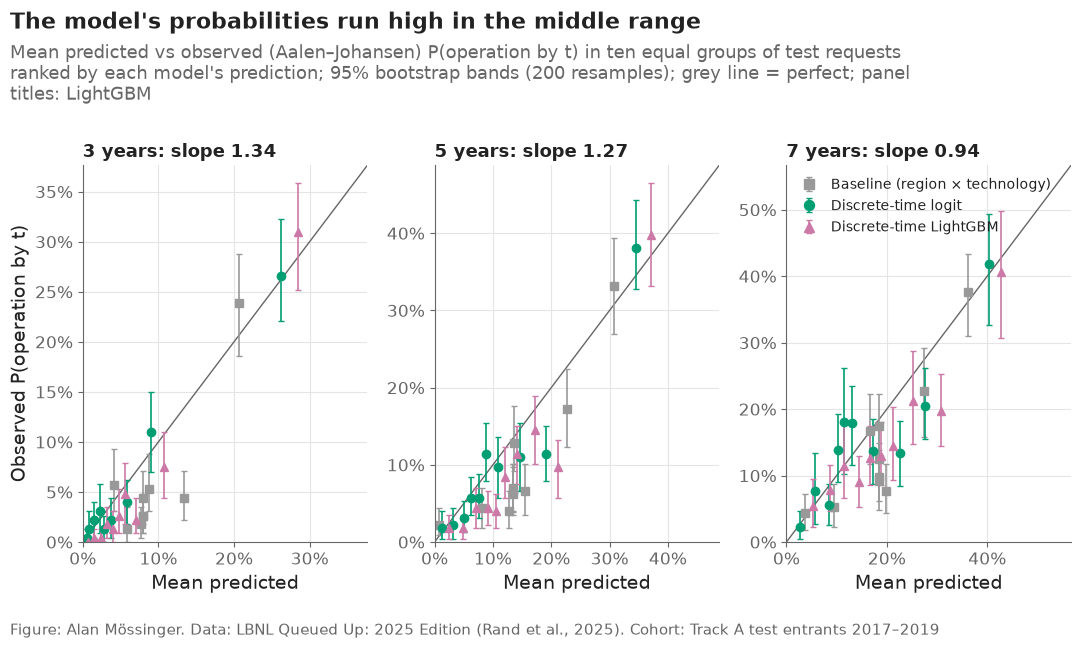

observed               predicted              
horizon        3      5      7         3      5      7
decile                                                
1          0.000  0.018  0.054     0.006  0.024  0.052
2          0.004  0.018  0.078     0.015  0.049  0.087
3          0.004  0.044  0.114     0.024  0.071  0.114
4          0.018  0.044  0.090     0.032  0.091  0.145
5          0.013  0.040  0.127     0.040  0.106  0.166
6          0.026  0.084  0.129     0.047  0.121  0.188
7          0.048  0.115  0.144     0.056  0.142  0.212
8          0.022  0.145  0.213     0.070  0.171  0.252
9          0.075  0.097  0.198     0.108  0.212  0.308
10         0.310  0.398  0.406     0.285  0.371  0.428

In [10]:
cal_rows = []
for h in HORIZONS:
    for m_i, model in enumerate(MODELS):
        groups = evaluation.decile_groups(preds[h][model])
        for g in range(10):
            idx = groups == g
            observed = survival_tools.aalen_johansen(durations[idx], events[idx], [h])["cif_operation"].iloc[0]
            band = survival_tools.bootstrap_bands(durations[idx], events[idx], [h], n_boot=N_BOOT, seed=810 + 10 * m_i + g)
            cal_rows.append({"horizon": h, "model": model, "decile": g + 1, "n": int(idx.sum()),
                             "predicted": preds[h][model][idx].mean(), "observed": observed,
                             "low": band["cif_operation_low"].iloc[0], "high": band["cif_operation_high"].iloc[0]})
calibration = pd.DataFrame(cal_rows)
calibration.to_csv(paths.RESULTS / "calibration.csv", index=False)

shown = ["baseline", "dt_logit", "dt_lgbm"]
fig, axes = plt.subplots(1, 3)
for ax, h in zip(axes, HORIZONS):
    part_h = calibration[calibration["horizon"] == h]
    top = max(part_h["high"].max(), part_h["predicted"].max()) * 1.05
    ax.plot([0, top], [0, top], color=plots.MUTED, linewidth=1)
    for model in shown:
        part = part_h[part_h["model"] == model]
        style = MODEL_STYLE[model]
        ax.errorbar(part["predicted"], part["observed"], yerr=[part["observed"] - part["low"], part["high"] - part["observed"]],
                    fmt=style["marker"], color=style["color"], capsize=2, markersize=6, linewidth=1.2,
                    label=MODEL_LABELS[model])
    ax.set_xlim(0, top)
    ax.set_ylim(0, top)
    ax.set_title(f"{h} years: slope {value(metrics_a, 'dt_lgbm', 'slope', h):.2f}", fontsize=13)
    ax.set_xlabel("Mean predicted")
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Observed P(operation by t)")
axes[2].legend(loc="upper left", fontsize=10, markerscale=1.2, handlelength=1.5)
plots.finish(fig,
             "LightGBM's probabilities run high in the middle of the range: its calibration slope is "
             f"{value(metrics_a, 'dt_lgbm', 'slope', 3):.2f} and {value(metrics_a, 'dt_lgbm', 'slope', 5):.2f} at 3 and 5 years "
             f"(C3 asks 0.9–1.1) and {value(metrics_a, 'dt_lgbm', 'slope', 7):.2f} at 7 years",
             "Mean predicted vs observed (Aalen–Johansen) P(operation by t) in ten equal groups of test requests ranked by "
             "each model's prediction; 95% bootstrap bands (200 resamples); grey line = perfect; panel titles: LightGBM",
             "Track A test entrants 2017–2019")
plots.save_fig(fig, "F4_calibration_by_horizon", "Calibration of P(operation by 3, 5 and 7 years) by predicted decile: baseline, discrete-time logit and LightGBM, test cohort.", NOTEBOOK)
plt.show()
calibration[calibration["model"] == "dt_lgbm"].pivot_table(index="decile", columns="horizon", values=["predicted", "observed"]).round(3)

**Reading this.** Ranked into ten equal groups, LightGBM's top group is well calibrated at 5 years (37.1% predicted, 39.8% observed), but the groups in the middle are predicted too high: the 5th group 10.6% predicted vs 4.0% observed, the 9th 21.2% vs 9.7%. Its calibration slope is 1.34 [1.15, 1.58] at 3 years and 1.27 [1.11, 1.49] at 5 years — the observed outcomes separate more sharply than the predictions — and 0.94 [0.72, 1.14] at 7 years. Criterion C3 (slope 0.9–1.1) therefore passes only at 7 years. For a lender this means LightGBM's middle-of-the-range probabilities should not be taken at face value: a predicted 20% was closer to 10% in this cohort. The ranking (previous section) is more trustworthy than the level.

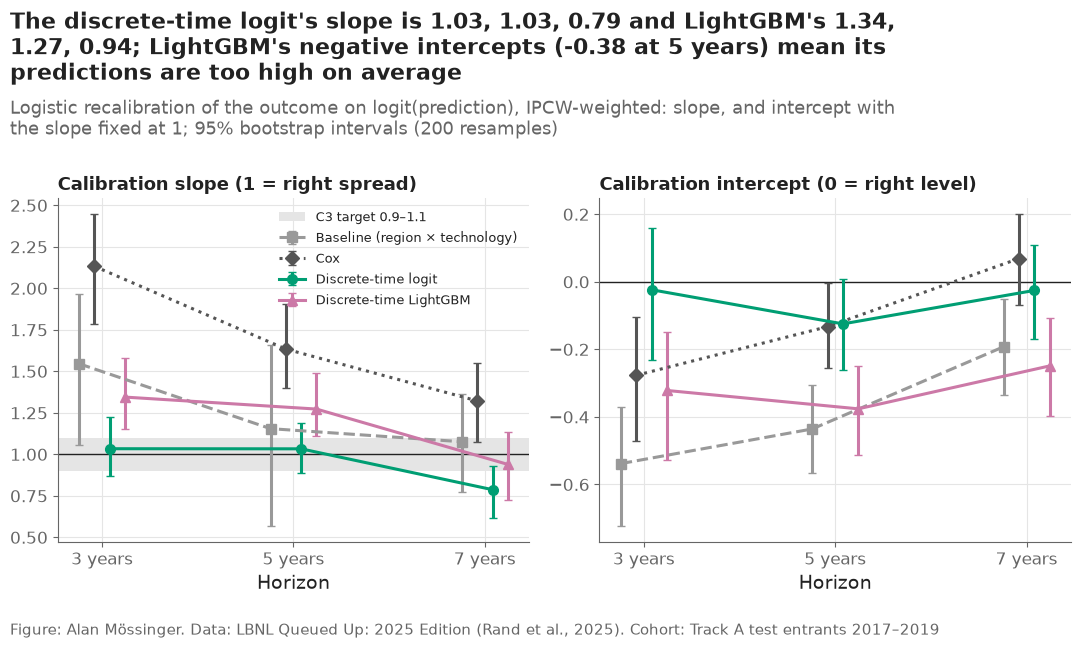

model              baseline   cox  dt_logit  dt_lgbm
metric    horizon                                   
intercept 3           -0.54 -0.28     -0.02    -0.32
          5           -0.44 -0.13     -0.12    -0.38
          7           -0.19  0.07     -0.03    -0.25
slope     3            1.55  2.13      1.03     1.34
          5            1.15  1.63      1.03     1.27
          7            1.08  1.32      0.79     0.94

In [11]:
fig, axes = plt.subplots(1, 2, sharex=True)
for ax, metric, target in zip(axes, ["slope", "intercept"], [1.0, 0.0]):
    if metric == "slope":
        ax.axhspan(0.9, 1.1, color="#E5E5E5", label="C3 target 0.9–1.1")
    ax.axhline(target, color=plots.INK, linewidth=1)
    for model in MODELS:
        part = metrics_a[(metrics_a["model"] == model) & (metrics_a["metric"] == metric)]
        errorbars(ax, part["horizon"] + OFFSETS[model], part, label=MODEL_LABELS[model], **MODEL_STYLE[model])
    ax.set_xticks(HORIZONS, [f"{h} years" for h in HORIZONS])
    ax.set_xlabel("Horizon")
    ax.set_title(METRIC_LABELS[metric] + (" (1 = right spread)" if metric == "slope" else " (0 = right level)"), fontsize=13)
axes[0].legend(loc="best", fontsize=9.5)
plots.finish(fig,
             "The discrete-time logit's slope is "
             + ", ".join(f"{value(metrics_a, 'dt_logit', 'slope', h):.2f}" for h in HORIZONS)
             + " and LightGBM's " + ", ".join(f"{value(metrics_a, 'dt_lgbm', 'slope', h):.2f}" for h in HORIZONS)
             + f"; LightGBM's negative intercepts ({value(metrics_a, 'dt_lgbm', 'intercept', 5):.2f} at 5 years) mean its "
             "predictions are too high on average",
             "Logistic recalibration of the outcome on logit(prediction), IPCW-weighted: slope, and intercept with the "
             "slope fixed at 1; 95% bootstrap intervals (200 resamples)",
             "Track A test entrants 2017–2019")
save(fig, "08_06_calibration_slope_intercept", "Calibration slope and intercept of the four Track A models by horizon.")
plt.show()
metrics_a[metrics_a["metric"].isin(["slope", "intercept"])].pivot_table(
    index=["metric", "horizon"], columns="model", values="estimate")[MODELS].round(2)

**Reading this.** The discrete-time logit is the best calibrated model at 3 and 5 years: slope 1.03 at both, intercept −0.02 and −0.12, inside C3's band. It is not the primary model, so this decides nothing in the criteria, but it matters for which model's probabilities a user should quote. LightGBM's slopes are 1.34, 1.27 and 0.94 with intercepts −0.32, −0.38 and −0.25: its predictions are too high on average and too compressed at 3 and 5 years. Cox has the steepest slopes (2.13, 1.63, 1.32), so its probabilities are the most compressed although it ranks best at 7 years; the baseline's slopes are 1.55, 1.15 and 1.08 with intercepts −0.54, −0.44 and −0.19. At 7 years the logit's slope falls to 0.79, too spread out. The pattern suggests that ranking and level are best taken from different models — a possibility for a labelled post-hoc analysis, not something to change in the registered evaluation.

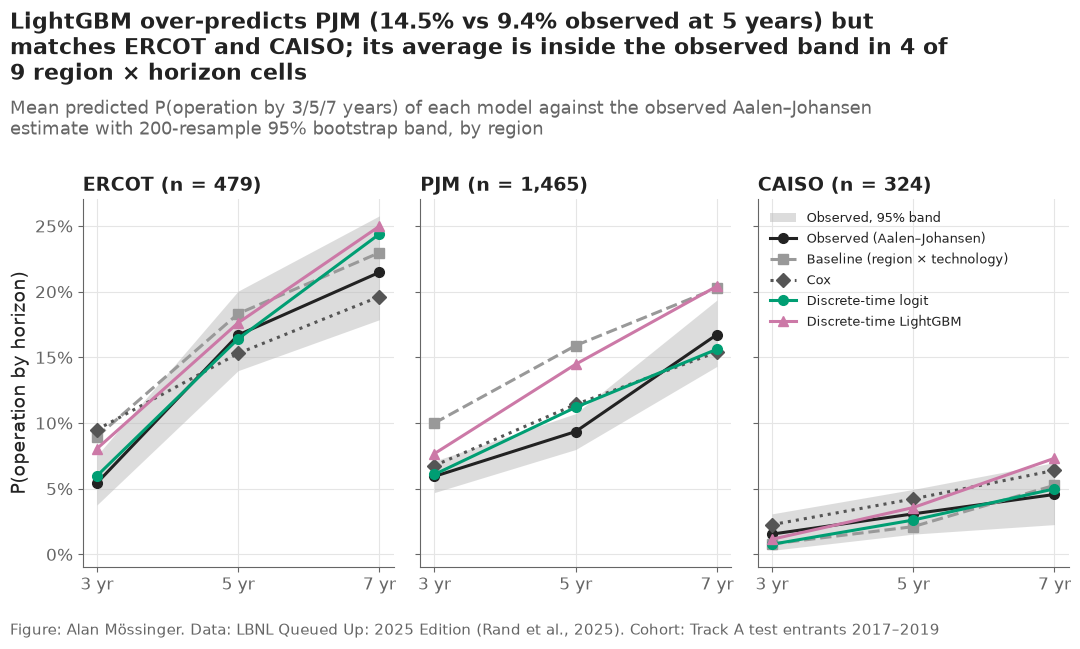

,region,n,horizon,observed,low,high,baseline,cox,dt_logit,dt_lgbm
0,ERCOT,479,3,0.054,0.038,0.075,0.090,0.095,0.060,0.080
1,ERCOT,479,5,0.167,0.140,0.200,0.183,0.153,0.164,0.176
2,ERCOT,479,7,0.215,0.179,0.258,0.230,0.196,0.244,0.250
3,PJM,1465,3,0.059,0.047,0.071,0.100,0.068,0.061,0.077
4,PJM,1465,5,0.094,0.080,0.107,0.159,0.114,0.112,0.145
5,PJM,1465,7,0.167,0.143,0.194,0.203,0.154,0.156,0.204
6,CAISO,324,3,0.015,0.003,0.031,0.008,0.023,0.008,0.012
7,CAISO,324,5,0.031,0.015,0.049,0.021,0.042,0.026,0.036
8,CAISO,324,7,0.046,0.023,0.070,0.053,0.064,0.050,0.073


In [12]:
reg_rows = []
for i, region in enumerate(TRACK_A):
    mask = regions == region
    observed = survival_tools.aalen_johansen(durations[mask], events[mask], HORIZONS)
    band = survival_tools.bootstrap_bands(durations[mask], events[mask], HORIZONS, n_boot=N_BOOT, seed=820 + i)
    for j, h in enumerate(HORIZONS):
        reg_rows.append({"region": region, "n": int(mask.sum()), "horizon": h,
                         "observed": observed["cif_operation"].iloc[j], "low": band["cif_operation_low"].iloc[j],
                         "high": band["cif_operation_high"].iloc[j],
                         **{m: preds[h][m][mask].mean() for m in MODELS}})
cal_region = pd.DataFrame(reg_rows)
cal_region.to_csv(paths.RESULTS / "calibration_by_region.csv", index=False)

fig, axes = plt.subplots(1, 3, sharey=True)
for ax, region in zip(axes, TRACK_A):
    part = cal_region[cal_region["region"] == region]
    ax.fill_between(part["horizon"], part["low"], part["high"], color="#BBBBBB", alpha=0.5, linewidth=0,
                    label="Observed, 95% band")
    ax.plot(part["horizon"], part["observed"], color=plots.INK, marker="o", label="Observed (Aalen–Johansen)")
    for model in MODELS:
        ax.plot(part["horizon"], part[model], label=MODEL_LABELS[model], **MODEL_STYLE[model])
    ax.set_title(f"{region} (n = {int(part['n'].iloc[0]):,})")
    ax.set_xticks(HORIZONS, [f"{h} yr" for h in HORIZONS])
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("P(operation by horizon)")
axes[2].legend(loc="upper left", fontsize=9.5)
cr = cal_region.set_index(["region", "horizon"])
inside = ((cal_region["dt_lgbm"] >= cal_region["low"]) & (cal_region["dt_lgbm"] <= cal_region["high"]))
plots.finish(fig,
             f"LightGBM over-predicts PJM ({cr.loc[('PJM', 5), 'dt_lgbm']:.1%} vs {cr.loc[('PJM', 5), 'observed']:.1%} observed "
             f"at 5 years) but matches ERCOT and CAISO; its average is inside the observed band in {int(inside.sum())} of 9 "
             "region × horizon cells",
             "Mean predicted P(operation by 3/5/7 years) of each model against the observed Aalen–Johansen estimate with "
             "200-resample 95% bootstrap band, by region",
             "Track A test entrants 2017–2019")
save(fig, "08_07_calibration_by_region", "Mean predicted versus observed P(operation by 3, 5 and 7 years) by region, test cohort, four models.")
plt.show()
cal_region.round(3)

**Reading this.** By region the miss is PJM: at 5 years LightGBM predicted 14.5% and 9.4% of PJM's test requests operated (band 8.0–10.7%); the baseline's 15.9% was further off, the logit's 11.2% and Cox's 11.4% closer. In ERCOT (17.6% vs 16.7%) and CAISO (3.6% vs 3.1%) LightGBM is inside the band at 5 years. LightGBM's average is inside the band in 4 of 9 region × horizon cells. PJM's over-prediction lines up with section 7's finding that completion fell for 2018–2019 entrants, and PJM is two thirds of the test cohort, which is why the pooled calibration intercept is negative.

## 4. Ranking value: what a developer or lender would get from the top of the list

If a lender could look closely at only one request in ten, how many of the
requests that reach operation within 5 years would be among them? The gains
curve answers that for every share of the list; the top-decile lift
(criterion C4) is its value at 10% divided by 10%. Ties at the cut-off — the
baseline gives whole cells one value — are shared in proportion.

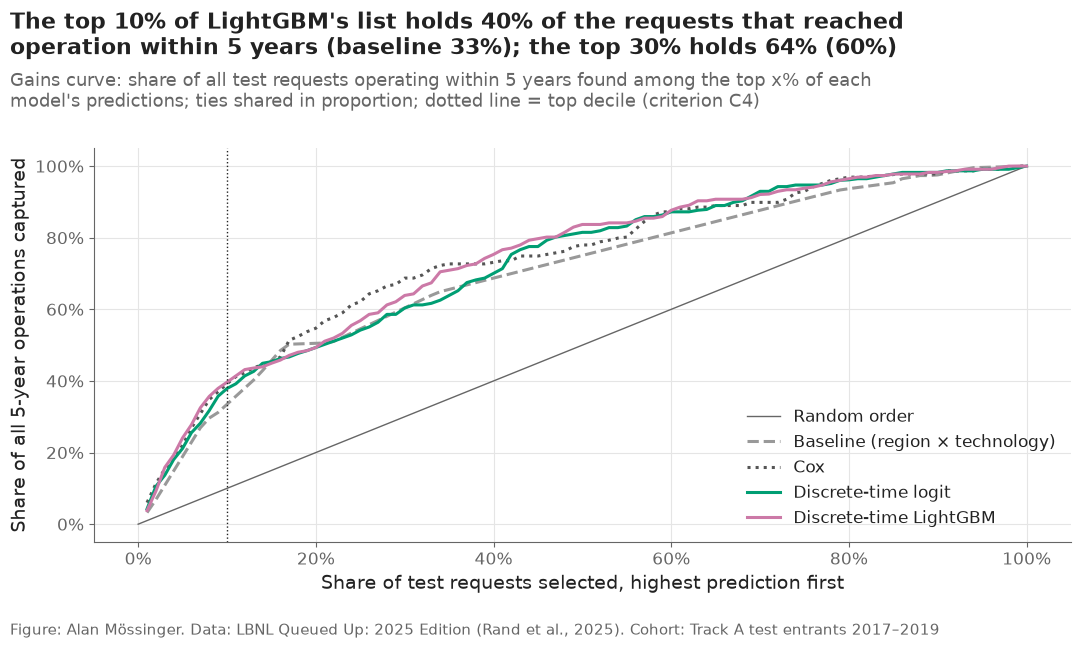

,top 10%,top 30%
model,,
baseline,0.335,0.604
cox,0.392,0.687
dt_logit,0.379,0.604
dt_lgbm,0.396,0.639


In [13]:
fractions = np.round(np.arange(0.01, 1.0001, 0.01), 2)
gain_rows = []
for h in HORIZONS:
    y_h, w_h = evaluation.horizon_outcome(durations, events, h, G)
    for model in MODELS:
        for f in fractions:
            top = evaluation.top_fraction(preds[h][model], y_h, w_h, f)
            gain_rows.append({"horizon": h, "model": model, "fraction": f, "captured": top["lift"] * f,
                              "precision": top["precision"]})
gains = pd.DataFrame(gain_rows)
gains.to_csv(paths.RESULTS / "gains.csv", index=False)

fig, ax = plt.subplots()
g5 = gains[gains["horizon"] == 5]
ax.plot([0, 1], [0, 1], color=plots.MUTED, linewidth=1, label="Random order")
for model in MODELS:
    part = g5[g5["model"] == model]
    style = {k: v for k, v in MODEL_STYLE[model].items() if k != "marker"}
    ax.plot(part["fraction"], part["captured"], label=MODEL_LABELS[model], **style)
ax.axvline(0.1, color=plots.INK, linewidth=1, linestyle=":")
ax.set_xlabel("Share of test requests selected, highest prediction first")
ax.set_ylabel("Share of all 5-year operations captured")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.legend(loc="lower right")
cap = g5[g5["fraction"] == 0.1].set_index("model")["captured"]
cap30 = g5[g5["fraction"] == 0.3].set_index("model")["captured"]
plots.finish(fig,
             f"The top 10% of LightGBM's list holds {cap['dt_lgbm']:.0%} of the requests that reached operation within 5 "
             f"years (baseline {cap['baseline']:.0%}); the top 30% holds {cap30['dt_lgbm']:.0%} ({cap30['baseline']:.0%})",
             "Gains curve: share of all test requests operating within 5 years found among the top x% of each model's "
             "predictions; ties shared in proportion; dotted line = top decile (criterion C4)",
             "Track A test entrants 2017–2019")
save(fig, "08_08_gains_5yr", "Gains curves at 5 years: share of operating requests captured by the top x% of each model's ranking.")
plt.show()
pd.DataFrame({"top 10%": cap, "top 30%": cap30}).loc[MODELS].round(3)

**Reading this.** If a lender could examine only the top 10% of LightGBM's 5-year list, it would find 39.6% of all requests that reached operation within 5 years; ordering by the baseline finds 33.5%, Cox 39.2%. At the top 30% the shares are 63.9% (LightGBM), 60.4% (baseline) and 68.7% (Cox). The curves separate mostly at the very top of the list, where screening decisions are made; beyond about 40% of the list all models capture nearly the same operations.

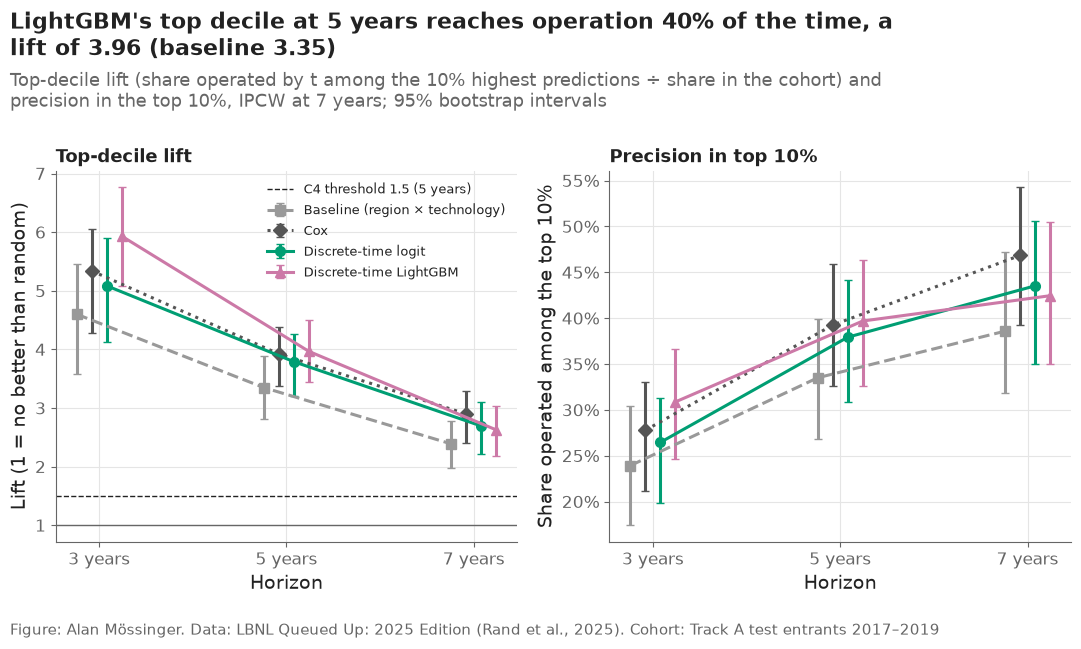

model                             baseline                   cox              dt_logit               dt_lgbm
metric       horizon                                                                                        
lift_10      3        4.599 [3.588, 5.462]  5.339 [4.285, 6.049]  5.085 [4.128, 5.893]  5.932 [5.078, 6.763]
             5        3.347 [2.806, 3.880]  3.921 [3.378, 4.375]  3.789 [3.201, 4.256]  3.965 [3.440, 4.507]
             7        2.386 [1.972, 2.781]  2.897 [2.397, 3.285]  2.692 [2.217, 3.103]  2.625 [2.179, 3.035]
precision_10 3        0.239 [0.174, 0.304]  0.278 [0.212, 0.331]  0.265 [0.198, 0.313]  0.309 [0.247, 0.366]
             5        0.335 [0.269, 0.399]  0.392 [0.326, 0.459]  0.379 [0.309, 0.441]  0.397 [0.326, 0.463]
             7        0.386 [0.318, 0.472]  0.468 [0.393, 0.543]  0.435 [0.350, 0.506]  0.424 [0.350, 0.505]

In [14]:
fig, axes = plt.subplots(1, 2, sharex=True)
for ax, metric in zip(axes, ["lift_10", "precision_10"]):
    if metric == "lift_10":
        ax.axhline(1.5, color=plots.INK, linewidth=1, linestyle="--", label="C4 threshold 1.5 (5 years)")
        ax.axhline(1.0, color=plots.MUTED, linewidth=1)
    for model in MODELS:
        part = metrics_a[(metrics_a["model"] == model) & (metrics_a["metric"] == metric)]
        errorbars(ax, part["horizon"] + OFFSETS[model], part, label=MODEL_LABELS[model], **MODEL_STYLE[model])
    ax.set_xticks(HORIZONS, [f"{h} years" for h in HORIZONS])
    ax.set_xlabel("Horizon")
    ax.set_title(METRIC_LABELS[metric], fontsize=13)
axes[1].yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Lift (1 = no better than random)")
axes[1].set_ylabel("Share operated among the top 10%")
axes[0].legend(loc="upper right", fontsize=9.5)
plots.finish(fig,
             f"LightGBM's top decile at 5 years reaches operation {value(metrics_a, 'dt_lgbm', 'precision_10', 5):.0%} of the "
             f"time, a lift of {value(metrics_a, 'dt_lgbm', 'lift_10', 5):.2f} (baseline "
             f"{value(metrics_a, 'baseline', 'lift_10', 5):.2f})",
             "Top-decile lift (share operated by t among the 10% highest predictions ÷ share in the cohort) and precision "
             "in the top 10%, IPCW at 7 years; 95% bootstrap intervals",
             "Track A test entrants 2017–2019")
save(fig, "08_09_top_decile", "Top-decile lift and precision of the four Track A models by horizon.")
plt.show()
lift = metrics_a[metrics_a["metric"].isin(["lift_10", "precision_10"])].copy()
lift["value"] = [f"{r.estimate:.3f} [{r.low:.3f}, {r.high:.3f}]" for r in lift.itertuples()]
lift.pivot_table(index=["metric", "horizon"], columns="model", values="value", aggfunc="first")[MODELS]

**Reading this.** LightGBM's top decile reaches operation within 5 years 39.7% [32.6%, 46.3%] of the time, against 227 of 2,268 (10.0%) in the whole cohort, a lift of 3.96 [3.44, 4.51]; criterion C4 (lift ≥ 1.5) passes with room. The baseline's lift is 3.35 [2.81, 3.88], because region alone already concentrates operations in ERCOT and PJM's gas and small requests. At 3 years LightGBM's lift is 5.93 [5.08, 6.76] against 4.60 for the baseline. The precision in the top decile — about 2 in 5 at 5 years — is the number a developer can use directly.

## 5. Track B: will a 2017 request ever be built? (all nine regions)

The 2017 cohort's resolved requests, scored for the first time: the
region × technology base rate, the logit and LightGBM as fitted on entrants
to 2015, and both after the isotonic map fitted on 2016 (decision #29).
Criterion C5 compares the calibrated LightGBM with the base rate. Track B
keeps only resolved requests (notebook 04), so the 2017 cohort is tilted
towards fast outcomes; the share of each region's 2017 requests still
unresolved is shown beside the per-region results.

In [15]:
pred_b = pd.read_parquet(paths.DATA_PROCESSED / "predictions_trackB.parquet")
test_b = pred_b[pred_b["split"] == "test"].reset_index(drop=True)
y_b = test_b["built"].to_numpy()
B_MODELS = ["baseline", "logit", "lgbm", "logit_cal", "lgbm_cal"]
B_LABELS = {"baseline": "Base rate (region × technology)", "logit": "Logit", "lgbm": "LightGBM",
            "logit_cal": "Logit, calibrated", "lgbm_cal": "LightGBM, calibrated"}
B_STYLE = {"baseline": dict(color="#999999", marker="s"), "logit": dict(color="#009E73", marker="o", markerfacecolor="white"),
           "lgbm": dict(color="#CC79A7", marker="^", markerfacecolor="white"), "logit_cal": dict(color="#009E73", marker="o"),
           "lgbm_cal": dict(color="#CC79A7", marker="^")}
preds_b = {m: test_b[m].to_numpy() for m in B_MODELS}
point_b = evaluation.score(preds_b, y_b)
draws_b = evaluation.bootstrap(lambda sw: evaluation.score(preds_b, y_b, None, sw), len(test_b), N_BOOT,
                               REGISTERED["seed_track_b"])
metrics_b = evaluation.summarise(point_b, draws_b, level=LEVEL)
metrics_b.insert(0, "track", "B")
metrics_b.insert(3, "horizon", np.nan)
print(f"2017 cohort: {len(test_b):,} resolved requests, {y_b.sum():,} built ({y_b.mean():.1%}); "
      f"mean prediction: " + ", ".join(f"{m} {preds_b[m].mean():.1%}" for m in B_MODELS))
mb = metrics_b.copy()
mb["value"] = [f"{r.estimate:.3f} [{r.low:.3f}, {r.high:.3f}]" for r in mb.itertuples()]
mb["vs base rate"] = [f"{r.diff:+.3f} [{r.diff_low:+.3f}, {r.diff_high:+.3f}]" if pd.notna(r.diff) else "" for r in mb.itertuples()]
mb.pivot_table(index="model", columns="metric", values="value", aggfunc="first").loc[B_MODELS, ["auc", "brier", "slope", "intercept", "lift_10"]]

2017 cohort: 1,534 resolved requests, 279 built (18.2%); mean prediction: baseline 18.4%, logit 20.6%, lgbm 20.6%, logit_cal 17.9%, lgbm_cal 19.0%


metric,auc,brier,slope,intercept,lift_10
model,,,,,
baseline,"0.525 [0.478, 0.564]","0.153 [0.141, 0.166]","0.119 [-0.106, 0.327]","-0.016 [-0.122, 0.123]","1.788 [1.397, 2.142]"
logit,"0.598 [0.557, 0.629]","0.157 [0.146, 0.170]","0.388 [0.236, 0.520]","-0.176 [-0.299, -0.034]","1.484 [1.106, 1.890]"
lgbm,"0.612 [0.576, 0.648]","0.148 [0.138, 0.160]","0.658 [0.464, 0.864]","-0.166 [-0.281, -0.034]","1.541 [1.216, 1.940]"
logit_cal,"0.603 [0.563, 0.634]","0.148 [0.136, 0.160]","0.597 [0.421, 0.749]","0.018 [-0.095, 0.153]","1.508 [1.103, 1.842]"
lgbm_cal,"0.608 [0.574, 0.640]","0.147 [0.137, 0.160]","0.600 [0.402, 0.816]","-0.060 [-0.177, 0.070]","1.619 [1.303, 1.943]"


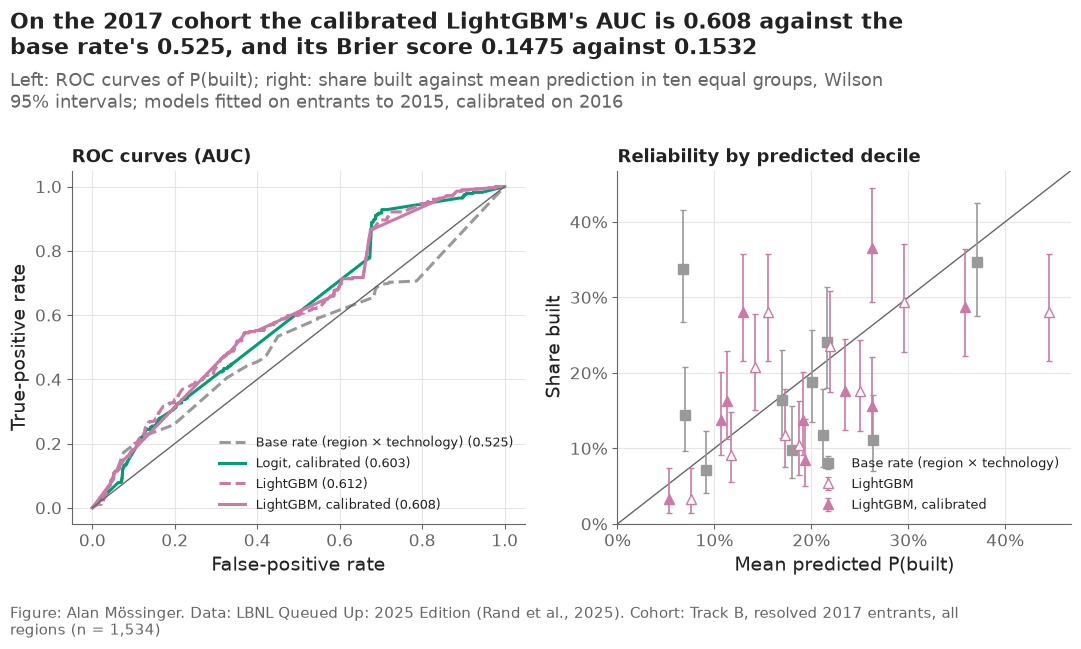

In [16]:
fig, axes = plt.subplots(1, 2)
for model in ["baseline", "logit_cal", "lgbm", "lgbm_cal"]:
    fpr, tpr, _ = roc_curve(y_b, preds_b[model])
    style = {k: v for k, v in B_STYLE[model].items() if k not in ("marker", "markerfacecolor")}
    axes[0].plot(fpr, tpr, linestyle="--" if model in ("baseline", "lgbm") else "-",
                 label=f"{B_LABELS[model]} ({point_b[model + '|auc']:.3f})", **style)
axes[0].plot([0, 1], [0, 1], color=plots.MUTED, linewidth=1)
axes[0].set_xlabel("False-positive rate")
axes[0].set_ylabel("True-positive rate")
axes[0].set_title("ROC curves (AUC)", fontsize=13)
axes[0].legend(loc="lower right", fontsize=9.5)
rel_rows = []
for model in ["baseline", "lgbm", "lgbm_cal"]:
    groups = evaluation.decile_groups(preds_b[model])
    for g in range(10):
        idx = groups == g
        low, high = track_b.wilson(y_b[idx].sum(), idx.sum())
        rel_rows.append({"model": model, "decile": g + 1, "predicted": preds_b[model][idx].mean(),
                         "observed": y_b[idx].mean(), "low": low, "high": high})
reliability_b = pd.DataFrame(rel_rows)
top = reliability_b[["high", "predicted"]].max().max() * 1.05
axes[1].plot([0, top], [0, top], color=plots.MUTED, linewidth=1)
for model in ["baseline", "lgbm", "lgbm_cal"]:
    part = reliability_b[reliability_b["model"] == model]
    axes[1].errorbar(part["predicted"], part["observed"], yerr=[part["observed"] - part["low"], part["high"] - part["observed"]],
                     fmt=B_STYLE[model]["marker"], color=B_STYLE[model]["color"],
                     markerfacecolor=B_STYLE[model].get("markerfacecolor", B_STYLE[model]["color"]), capsize=2,
                     linewidth=1.2, label=B_LABELS[model])
axes[1].set_xlim(0, top)
axes[1].set_ylim(0, top)
axes[1].set_xlabel("Mean predicted P(built)")
axes[1].set_ylabel("Share built")
axes[1].set_title("Reliability by predicted decile", fontsize=13)
axes[1].xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
axes[1].yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[1].legend(loc="lower right", fontsize=9.5)
plots.finish(fig,
             f"On the 2017 cohort the calibrated LightGBM's AUC is {point_b['lgbm_cal|auc']:.3f} against the base rate's "
             f"{point_b['baseline|auc']:.3f}, and its Brier score {point_b['lgbm_cal|brier']:.4f} against "
             f"{point_b['baseline|brier']:.4f}",
             "Left: ROC curves of P(built); right: share built against mean prediction in ten equal groups, Wilson 95% "
             "intervals; models fitted on entrants to 2015, calibrated on 2016",
             f"Track B, resolved 2017 entrants, all regions (n = {len(test_b):,})")
save(fig, "08_10_trackB_roc_reliability", "Track B on the 2017 cohort: ROC curves and reliability by predicted decile.")
plt.show()

**Reading this.** On the 2017 cohort (1,534 resolved requests across nine regions, 279 built, 18.2%), the calibrated LightGBM's AUC is 0.608 [0.574, 0.640] against 0.525 [0.478, 0.564] for the region × technology base rate — a paired gain of +0.084 [+0.050, +0.119] — and its Brier score 0.1475 against 0.1532, lower by 0.0057 [0.0024, 0.0093]. Criterion C5 passes on both. The win comes partly from the base rate collapsing: its AUC was 0.613 on the 2016 cohort (notebook 07) and 0.525 here, close to random, so the historical region × technology mix no longer ranks 2017 requests. In absolute terms Track B remains weak (AUC about 0.61), and the calibrated model's slope of 0.600 [0.402, 0.816] says its probabilities are too spread out: treat Track B as a coarse ranking outside the three ISOs, not as a probability.

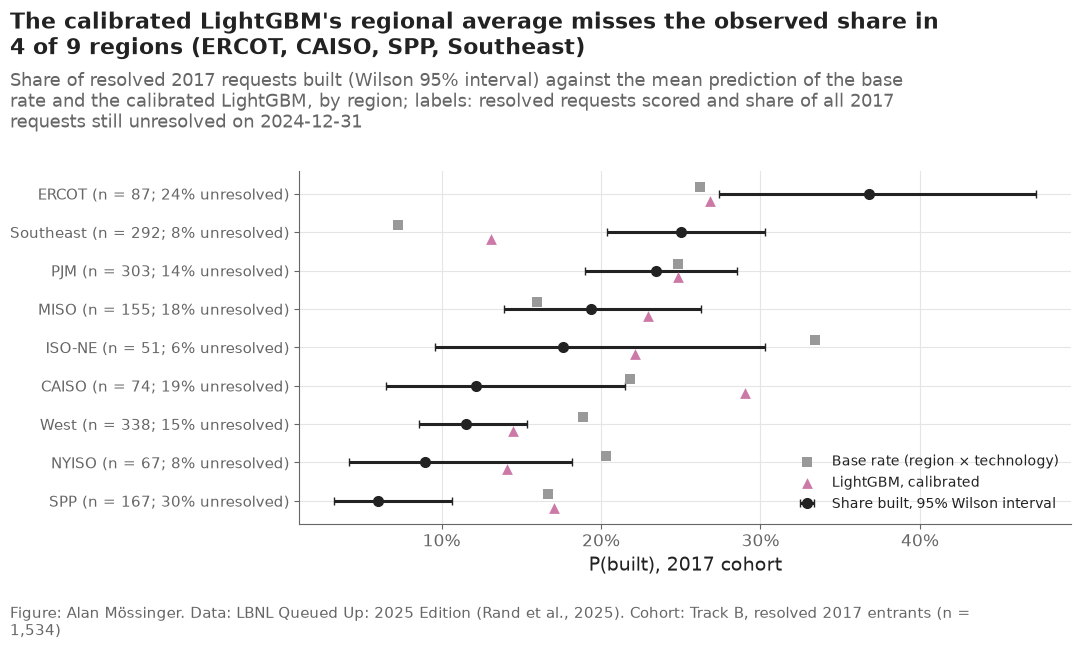

,region,n,built,low,high,unresolved_2017_share,baseline,logit,lgbm,logit_cal,lgbm_cal,lgbm_cal_inside
0,ERCOT,87,0.368,0.274,0.473,0.243,0.262,0.262,0.304,0.220,0.269,False
1,PJM,303,0.234,0.190,0.285,0.142,0.248,0.318,0.260,0.264,0.249,True
2,CAISO,74,0.122,0.065,0.215,0.187,0.218,0.270,0.308,0.224,0.291,False
3,MISO,155,0.194,0.139,0.263,0.180,0.160,0.200,0.229,0.179,0.230,True
4,SPP,167,0.060,0.033,0.107,0.304,0.167,0.132,0.176,0.120,0.171,False
5,NYISO,67,0.090,0.042,0.182,0.082,0.203,0.174,0.158,0.172,0.141,True
6,ISO-NE,51,0.176,0.096,0.303,0.056,0.334,0.252,0.229,0.212,0.221,True
7,West,338,0.115,0.086,0.154,0.149,0.189,0.176,0.160,0.147,0.145,True
8,Southeast,292,0.250,0.204,0.303,0.085,0.072,0.136,0.160,0.136,0.131,False


In [17]:
events_all = pd.read_parquet(paths.DATA_INTERIM / "queue_events.parquet")
cohort17 = events_all[events_all["q_year"].astype(float) == config.TRACK_B_MAX_YEAR]
unresolved = 1 - cohort17["q_status"].isin(["operational", "withdrawn"]).groupby(cohort17["region"]).mean()
by_region_rows = []
for region in config.ALL_REGIONS:
    part = test_b[test_b["region"] == region]
    low, high = track_b.wilson(part["built"].sum(), len(part))
    by_region_rows.append({"region": region, "n": len(part), "built": part["built"].mean(), "low": low, "high": high,
                           "unresolved_2017_share": unresolved.get(region, np.nan),
                           **{m: part[m].mean() for m in B_MODELS}})
b_region = pd.DataFrame(by_region_rows)
b_region["lgbm_cal_inside"] = (b_region["lgbm_cal"] >= b_region["low"]) & (b_region["lgbm_cal"] <= b_region["high"])
b_region.to_csv(paths.RESULTS / "trackB_test_by_region.csv", index=False)

fig, ax = plt.subplots()
order = b_region.sort_values("built")["region"].tolist()
y = np.arange(len(order))
part = b_region.set_index("region").loc[order]
ax.errorbar(part["built"], y, xerr=[part["built"] - part["low"], part["high"] - part["built"]], fmt="o", color=plots.INK,
            capsize=3, label="Share built, 95% Wilson interval")
ax.scatter(part["baseline"], y + 0.18, marker="s", color=B_STYLE["baseline"]["color"], s=50, zorder=3,
           label=B_LABELS["baseline"])
ax.scatter(part["lgbm_cal"], y - 0.18, marker="^", color=B_STYLE["lgbm_cal"]["color"], s=60, zorder=3,
           label=B_LABELS["lgbm_cal"])
ax.set_yticks(y, [f"{r} (n = {int(part.loc[r, 'n'])}; {part.loc[r, 'unresolved_2017_share']:.0%} unresolved)" for r in order],
              fontsize=11)
ax.set_xlabel("P(built), 2017 cohort")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.legend(loc="lower right", fontsize=10)
missed = b_region.loc[~b_region["lgbm_cal_inside"], "region"].tolist()
plots.finish(fig,
             f"The calibrated LightGBM's regional average misses the observed share in {len(missed)} of 9 regions"
             + (f" ({', '.join(missed)})" if missed else ""),
             "Share of resolved 2017 requests built (Wilson 95% interval) against the mean prediction of the base rate and "
             "the calibrated LightGBM, by region; labels: resolved requests scored and share of all 2017 requests "
             "still unresolved on 2024-12-31",
             f"Track B, resolved 2017 entrants (n = {len(test_b):,})")
save(fig, "08_11_trackB_by_region", "Track B on the 2017 cohort: observed share built versus mean predictions by region.")
plt.show()
b_region.round(3)

**Reading this.** The calibrated LightGBM's regional average misses the observed share in 4 of 9 regions: ERCOT (36.8% built [27.4%, 47.3%], 26.9% predicted), the Southeast (25.0% vs 13.1%), CAISO (12.2% vs 29.1%) and SPP (6.0% vs 17.1%). Two caveats: Track B scores resolved requests only, and the unresolved share of 2017 entrants differs by region — 30.4% in SPP, 24.3% in ERCOT, 8.5% in the Southeast — so a region's observed "share built" is the share among those that have finished; and the per-region intervals are wide (ISO-NE has 51 resolved requests).

## 6. The pre-registered criteria: PASS or FAIL

Each line of `results/success_criteria_registered.json` (written by the
first cell) is judged by its registered rule against the tables above. No
line is added, dropped or redefined here.

In [18]:
all_metrics = pd.concat([metrics_a, metrics_b], ignore_index=True)
all_metrics.to_csv(paths.RESULTS / "metrics.csv", index=False)
crit_rows = []
for c in REGISTERED["criteria"]:
    table = metrics_a if c["track"] == "A" else metrics_b
    for h in c["horizons"]:
        row = table[(table["model"] == c["model"]) & (table["metric"] == c["metric"])
                    & ((table["horizon"] == h) if h is not None else True)].iloc[0]
        entry = {"id": c["id"], "track": c["track"], "model": c["model"], "metric": c["metric"],
                 "horizon": h, "rule": c["rule"], "estimate": row["estimate"], "low": row["low"], "high": row["high"]}
        if c["rule"] == "beat":
            ref = table[(table["model"] == c["benchmark"]) & (table["metric"] == c["metric"])
                        & ((table["horizon"] == h) if h is not None else True)].iloc[0]
            entry.update({"benchmark": c["benchmark"], "benchmark_estimate": ref["estimate"], "diff": row["diff"],
                          "diff_low": row["diff_low"], "diff_high": row["diff_high"]})
            passed = bool(row["beats"])
            entry["threshold"] = "95% interval of the difference excludes 0 on the better side"
        elif c["rule"] == "between":
            passed = c["low"] <= row["estimate"] <= c["high"]
            entry["threshold"] = f"{c['low']}–{c['high']}"
        else:
            passed = row["estimate"] >= c["value"]
            entry["threshold"] = f"≥ {c['value']}"
        entry["result"] = "PASS" if passed else "FAIL"
        if c["rule"] == "beat":  # reported only: the registered rule is the interval (decision #5)
            better = row["diff"] > 0 if c["metric"] in ("uno_c", "auc") else row["diff"] < 0
            entry["point_estimate_reading"] = "better" if better else "not better"
        crit_rows.append(entry)
criteria = pd.DataFrame(crit_rows)
criteria.to_csv(paths.RESULTS / "success_criteria.csv", index=False)
print(f"{(criteria['result'] == 'PASS').sum()} of {len(criteria)} criterion lines pass")
print("lines the point estimate alone would call better although the registered interval rule says FAIL:",
      int(((criteria["point_estimate_reading"] == "better") & (criteria["result"] == "FAIL")).sum()))
criteria[["id", "track", "metric", "horizon", "estimate", "low", "high", "benchmark_estimate", "diff", "diff_low",
          "diff_high", "threshold", "result", "point_estimate_reading"]].round(4)

8 of 12 criterion lines pass
lines the point estimate alone would call better although the registered interval rule says FAIL: 2


,id,track,metric,horizon,estimate,low,high,benchmark_estimate,diff,diff_low,diff_high,threshold,result,point_estimate_reading
0,C1,A,uno_c,3.0,0.8525,0.8198,0.8858,0.7311,0.1215,0.0722,0.1699,95% interval of the difference excludes 0 on t...,PASS,better
1,C1,A,uno_c,5.0,0.7597,0.7315,0.7908,0.7191,0.0407,0.0128,0.0685,95% interval of the difference excludes 0 on t...,PASS,better
2,C1,A,uno_c,7.0,0.6722,0.6373,0.7003,0.6574,0.0148,-0.0142,0.0496,95% interval of the difference excludes 0 on t...,FAIL,better
3,C2,A,brier,3.0,0.0411,0.0353,0.0478,0.0471,-0.0059,-0.0082,-0.0039,95% interval of the difference excludes 0 on t...,PASS,better
4,C2,A,brier,5.0,0.0808,0.0736,0.0886,0.0858,-0.0050,-0.0074,-0.0028,95% interval of the difference excludes 0 on t...,PASS,better
5,C2,A,brier,7.0,0.1211,0.1125,0.1330,0.1219,-0.0008,-0.0041,0.0023,95% interval of the difference excludes 0 on t...,FAIL,better
6,C3,A,slope,3.0,1.3448,1.1511,1.5791,NaN,NaN,NaN,NaN,0.9–1.1,FAIL,NaN
7,C3,A,slope,5.0,1.2728,1.1096,1.4891,NaN,NaN,NaN,NaN,0.9–1.1,FAIL,NaN
8,C3,A,slope,7.0,0.9395,0.7222,1.1359,NaN,NaN,NaN,NaN,0.9–1.1,PASS,NaN
9,C4,A,lift_10,5.0,3.9648,3.4401,4.5072,NaN,NaN,NaN,NaN,≥ 1.5,PASS,NaN


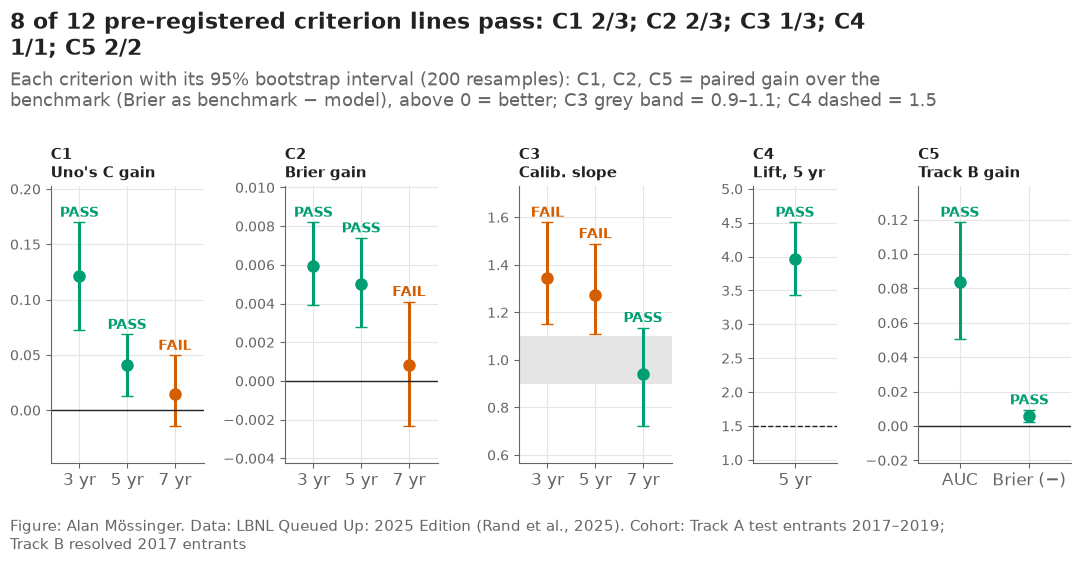

In [19]:
fig, axes = plt.subplots(1, 5, figsize=(11, 5.6), gridspec_kw={"width_ratios": [1, 1, 1, 0.55, 1]})
panels = [("C1", "uno_c", "Uno's C gain", 0.0), ("C2", "brier", "Brier gain", 0.0),
          ("C3", "slope", "Calib. slope", None), ("C4", "lift_10", "Lift, 5 yr", 1.5),
          ("C5", None, "Track B gain", 0.0)]
for ax, (cid, metric, title, ref) in zip(axes, panels):
    part = criteria[(criteria["id"] == cid) & ((criteria["metric"] == metric) if metric else True)]
    for i, row in enumerate(part.itertuples()):
        use_diff = row.rule == "beat"
        est, low, high = (row.diff, row.diff_low, row.diff_high) if use_diff else (row.estimate, row.low, row.high)
        if row.metric == "brier":
            est, low, high = -est, -high, -low  # Brier gains drawn as benchmark − model, so above 0 is better everywhere
        color = "#009E73" if row.result == "PASS" else "#D55E00"
        ax.errorbar(i, est, yerr=[[est - low], [high - est]], fmt="o", color=color, capsize=4, markersize=8)
        ax.annotate(row.result, (i, high), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=10,
                    color=color, fontweight="bold")
    labels = [f"{int(h)} yr" if pd.notna(h) else ("AUC" if m == "auc" else "Brier (−)") for h, m in zip(part["horizon"], part["metric"])]
    ax.set_xticks(range(len(part)), labels)
    ax.set_xlim(-0.6, len(part) - 0.4)
    if cid == "C3":
        ax.axhspan(0.9, 1.1, color="#E5E5E5")
    elif ref is not None:
        ax.axhline(ref, color=plots.INK, linewidth=1, linestyle="--" if cid == "C4" else "-")
    ax.set_title(f"{cid}\n{title}", fontsize=11)
    ax.tick_params(axis="y", labelsize=10)
    ax.margins(y=0.18)
n_pass = int((criteria["result"] == "PASS").sum())
plots.finish(fig,
             f"{n_pass} of {len(criteria)} pre-registered criterion lines pass: "
             + "; ".join(f"{cid} {int((criteria.loc[criteria['id'] == cid, 'result'] == 'PASS').sum())}/"
                         f"{int((criteria['id'] == cid).sum())}" for cid in ["C1", "C2", "C3", "C4", "C5"]),
             "Each criterion with its 95% bootstrap interval (200 resamples): C1, C2, C5 = paired gain over the benchmark "
             "(Brier as benchmark − model), above 0 = better; C3 grey band = 0.9–1.1; C4 dashed = 1.5",
             "Track A test entrants 2017–2019; Track B resolved 2017 entrants")
save(fig, "08_12_success_criteria", "The pre-registered success criteria with their bootstrap intervals and PASS/FAIL verdicts.")
plt.show()

**Reading this.** 8 of the 12 pre-registered criterion lines pass. C1 and C2 (beat the baseline on Uno's C and Brier) pass at 3 and 5 years and fail at 7 years, where the intervals include zero; C3 (calibration slope 0.9–1.1) fails at 3 and 5 years (1.34, 1.27) and passes at 7 (0.94); C4 (top-decile lift ≥ 1.5 at 5 years) passes at 3.96; C5 (Track B beats the base rate on AUC and Brier) passes on both. The point estimates at 7 years favour LightGBM (Uno +0.015, Brier −0.0008); read on point estimates alone those two lines would look like wins, which is why the rule was fixed in advance as an interval (decision #5): the 7-year gain is not distinguishable from noise. Read together: the model ranks requests better than cohort averages over a 3–5-year horizon and concentrates future operations in its top decile, but its mid-range probabilities are too high and its 7-year advantage is unproven.

## 7. The 7-year horizon and the three entry years

Two checks on what the pooled numbers hide. First, the 7-year metrics
recomputed on 2017 entrants alone, whose 7-year status is fully observed (no
weights), against the IPCW numbers on all test entrants. Second, the mean
prediction against the observed incidence for each entry year: the models
were fitted on entrants to 2016, and 2019 is further from that than 2017.

2017 entrants: 549; operated within 7 years: 99


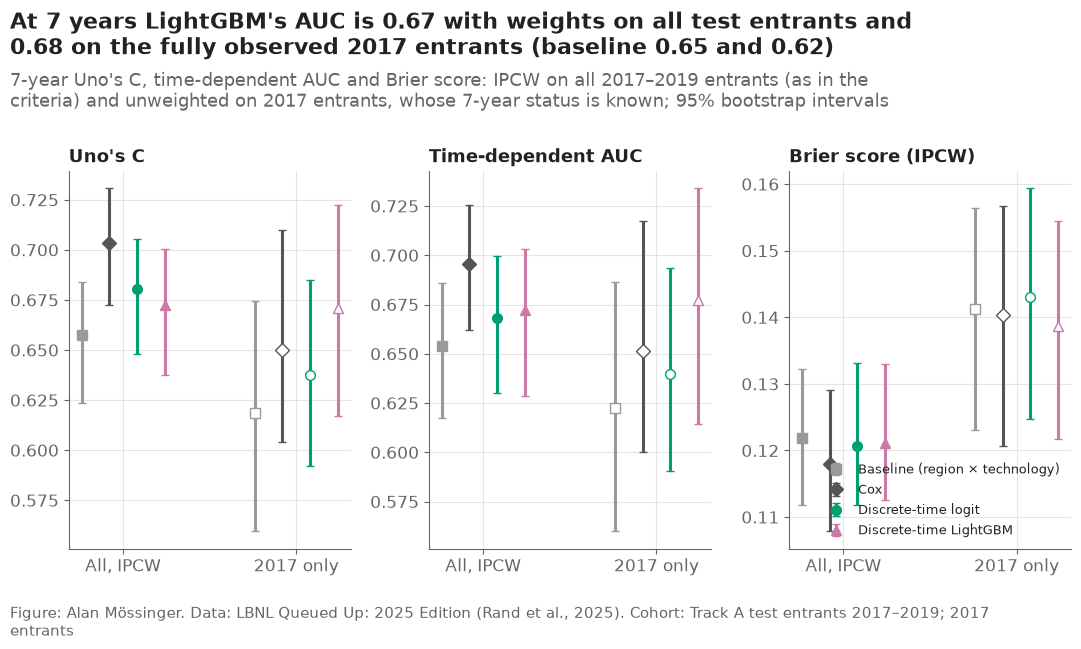

model                                             baseline                   cox              dt_logit               dt_lgbm
metric version                                                                                                              
auc    2017 entrants, fully observed  0.623 [0.560, 0.686]  0.651 [0.600, 0.717]  0.640 [0.590, 0.694]  0.677 [0.614, 0.734]
       2017–2019 entrants, IPCW       0.654 [0.617, 0.686]  0.696 [0.662, 0.726]  0.668 [0.630, 0.700]  0.672 [0.629, 0.703]
brier  2017 entrants, fully observed  0.141 [0.123, 0.156]  0.140 [0.121, 0.157]  0.143 [0.125, 0.159]  0.139 [0.122, 0.155]
       2017–2019 entrants, IPCW       0.122 [0.112, 0.132]  0.118 [0.108, 0.129]  0.121 [0.112, 0.133]  0.121 [0.113, 0.133]
slope  2017 entrants, fully observed  0.938 [0.503, 1.494]  1.053 [0.683, 1.503]  0.695 [0.452, 0.976]  0.897 [0.589, 1.240]
       2017–2019 entrants, IPCW       1.076 [0.772, 1.364]  1.322 [1.074, 1.548]  0.787 [0.614, 0.931]  0.939 [0.722, 1.136]
uno_c  2017 entrants, fully observed  0.619 [0.560, 0.674]  0.650 [0.604, 0.710]  0.638 [0.592, 0.685]  0.671 [0.617, 0.723]
       2017–2019 entrants, IPCW       0.657 [0.623, 0.684]  0.703 [0.672, 0.731]  0.681 [0.648, 0.706]  0.672 [0.637, 0.700]

In [20]:
in_2017 = test["q_year"].to_numpy() == 2017
assert (follow_up[in_2017] > 7).all()
G_2017 = evaluation.censoring_km(follow_up[in_2017], np.ones(in_2017.sum(), dtype=bool))
sub = {m: preds[7][m][in_2017] for m in MODELS}
point = evaluation.score_horizon(sub, durations[in_2017], events[in_2017], 7, G_2017)
draws = evaluation.bootstrap(lambda sw: evaluation.score_horizon(sub, durations[in_2017], events[in_2017], 7, G_2017, sw),
                             int(in_2017.sum()), N_BOOT, REGISTERED["seed_track_a"] + 20)
seven = pd.concat([evaluation.summarise(point, draws, level=LEVEL).assign(version="2017 entrants, fully observed"),
                   metrics_a[metrics_a["horizon"] == 7].drop(columns=["track", "horizon"]).assign(version="2017–2019 entrants, IPCW")],
                  ignore_index=True)
seven.to_csv(paths.RESULTS / "seven_year_check.csv", index=False)
print(f"2017 entrants: {in_2017.sum():,}; operated within 7 years: {int(((events == 1) & (durations <= 7) & in_2017).sum())}")

fig, axes = plt.subplots(1, 3)
for ax, metric in zip(axes, ["uno_c", "auc", "brier"]):
    for v_i, (version, face) in enumerate([("2017–2019 entrants, IPCW", None), ("2017 entrants, fully observed", "white")]):
        for model in MODELS:
            row = seven[(seven["version"] == version) & (seven["model"] == model) & (seven["metric"] == metric)]
            style = MODEL_STYLE[model]
            ax.errorbar(v_i + OFFSETS[model], row["estimate"], yerr=[row["estimate"] - row["low"], row["high"] - row["estimate"]],
                        fmt=style["marker"], color=style["color"], markerfacecolor=face or style["color"], capsize=3,
                        markersize=7, label=MODEL_LABELS[model] if v_i == 0 else None)
    ax.set_xticks([0, 1], ["All, IPCW", "2017 only"])
    ax.set_title(METRIC_LABELS[metric], fontsize=13)
axes[2].legend(loc="lower right", fontsize=9)
s7 = seven.set_index(["version", "model", "metric"])["estimate"]
plots.finish(fig,
             f"At 7 years LightGBM's AUC is {s7[('2017–2019 entrants, IPCW', 'dt_lgbm', 'auc')]:.2f} with weights on all "
             f"test entrants and {s7[('2017 entrants, fully observed', 'dt_lgbm', 'auc')]:.2f} on the fully observed 2017 "
             f"entrants (baseline {s7[('2017–2019 entrants, IPCW', 'baseline', 'auc')]:.2f} and "
             f"{s7[('2017 entrants, fully observed', 'baseline', 'auc')]:.2f})",
             "7-year Uno's C, time-dependent AUC and Brier score: IPCW on all 2017–2019 entrants (as in the criteria) "
             "and unweighted on 2017 entrants, whose 7-year status is known; 95% bootstrap intervals",
             "Track A test entrants 2017–2019; 2017 entrants")
save(fig, "08_13_seven_year_check", "Seven-year metrics: IPCW on all test entrants versus the fully observed 2017 entrants.")
plt.show()
sv = seven[seven["metric"].isin(["uno_c", "auc", "brier", "slope"])].copy()
sv["value"] = [f"{r.estimate:.3f} [{r.low:.3f}, {r.high:.3f}]" for r in sv.itertuples()]
sv.pivot_table(index=["metric", "version"], columns="model", values="value", aggfunc="first")[MODELS]

**Reading this.** On the 549 fully observed 2017 entrants (99 operated within 7 years), LightGBM's 7-year AUC is 0.677 [0.614, 0.734] against the baseline's 0.623 [0.560, 0.686], Uno's C 0.671 against 0.619 and Brier 0.139 against 0.141; Cox is 0.651. The IPCW numbers on all test entrants (AUC 0.672 vs 0.654) tell the same story with a smaller gap. Both versions have wide, overlapping intervals: the 7-year comparison rests on one entry year and about a hundred operations, and neither version settles it.

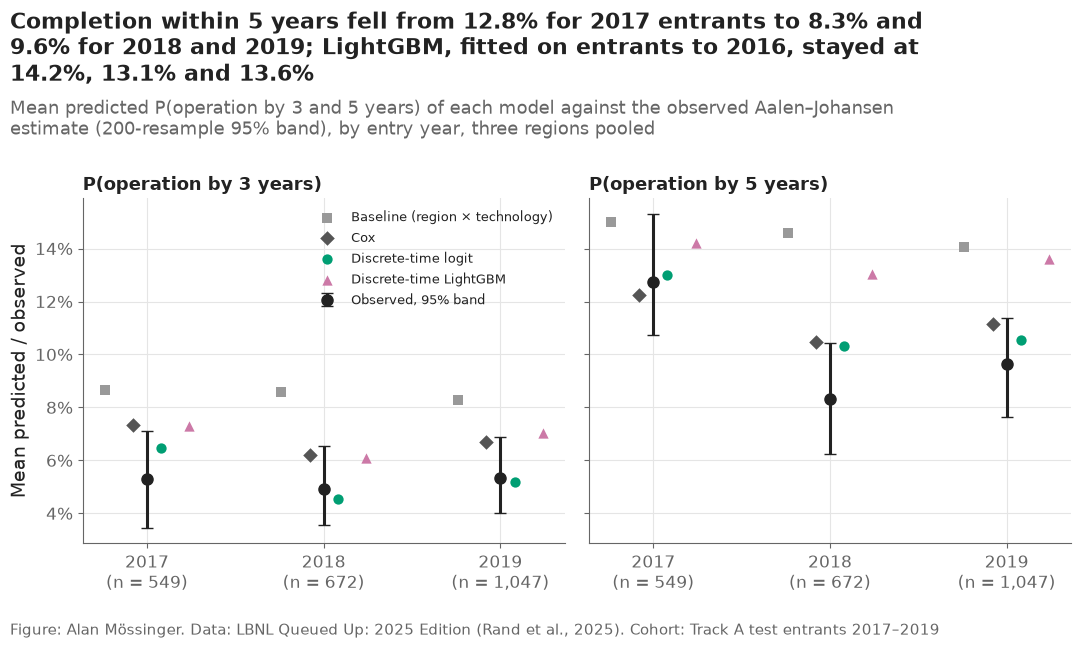

,entry_year,n,horizon,observed,low,high,baseline,cox,dt_logit,dt_lgbm
0,2017,549,3,0.053,0.035,0.071,0.087,0.073,0.065,0.073
1,2017,549,5,0.128,0.107,0.153,0.150,0.123,0.130,0.142
2,2018,672,3,0.049,0.036,0.065,0.086,0.062,0.046,0.061
3,2018,672,5,0.083,0.062,0.104,0.146,0.105,0.103,0.131
4,2019,1047,3,0.053,0.040,0.069,0.083,0.067,0.052,0.070
5,2019,1047,5,0.096,0.076,0.114,0.141,0.111,0.105,0.136


In [21]:
coh_rows = []
for y_i, year in enumerate([2017, 2018, 2019]):
    mask = test["q_year"].to_numpy() == year
    observed = survival_tools.aalen_johansen(durations[mask], events[mask], [3, 5])
    band = survival_tools.bootstrap_bands(durations[mask], events[mask], [3, 5], n_boot=N_BOOT, seed=830 + y_i)
    for j, h in enumerate([3, 5]):
        coh_rows.append({"entry_year": year, "n": int(mask.sum()), "horizon": h, "observed": observed["cif_operation"].iloc[j],
                         "low": band["cif_operation_low"].iloc[j], "high": band["cif_operation_high"].iloc[j],
                         **{m: preds[h][m][mask].mean() for m in MODELS}})
cohort_check = pd.DataFrame(coh_rows)
cohort_check.to_csv(paths.RESULTS / "cohort_check.csv", index=False)

fig, axes = plt.subplots(1, 2, sharey=True)
for ax, h in zip(axes, [3, 5]):
    part = cohort_check[cohort_check["horizon"] == h]
    x = np.arange(len(part))
    ax.errorbar(x, part["observed"], yerr=[part["observed"] - part["low"], part["high"] - part["observed"]], fmt="o",
                color=plots.INK, capsize=4, markersize=8, label="Observed, 95% band")
    for model in MODELS:
        ax.scatter(x + OFFSETS[model], part[model], marker=MODEL_STYLE[model]["marker"], color=MODEL_STYLE[model]["color"],
                   s=55, zorder=3, label=MODEL_LABELS[model])
    ax.set_xticks(x, [f"{y}\n(n = {n:,})" for y, n in zip(part["entry_year"], part["n"])])
    ax.set_title(f"P(operation by {h} years)", fontsize=13)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Mean predicted / observed")
axes[0].legend(loc="upper right", fontsize=9.5)
cc = cohort_check.set_index(["entry_year", "horizon"])
plots.finish(fig,
             f"Completion within 5 years fell from {cc.loc[(2017, 5), 'observed']:.1%} for 2017 entrants to "
             f"{cc.loc[(2018, 5), 'observed']:.1%} and {cc.loc[(2019, 5), 'observed']:.1%} for 2018 and 2019; LightGBM, fitted on "
             f"entrants to 2016, stayed at {cc.loc[(2017, 5), 'dt_lgbm']:.1%}, {cc.loc[(2018, 5), 'dt_lgbm']:.1%} and "
             f"{cc.loc[(2019, 5), 'dt_lgbm']:.1%}",
             "Mean predicted P(operation by 3 and 5 years) of each model against the observed Aalen–Johansen estimate "
             "(200-resample 95% band), by entry year, three regions pooled",
             "Track A test entrants 2017–2019")
save(fig, "08_14_by_entry_year", "Mean predicted versus observed P(operation by 3 and 5 years) for each test entry year.")
plt.show()
cohort_check.round(3)

**Reading this.** Completion within 5 years fell from 12.8% [10.7%, 15.3%] for 2017 entrants to 8.3% [6.2%, 10.4%] for 2018 and 9.6% [7.7%, 11.4%] for 2019 entrants. LightGBM, fitted on entrants to 2016, predicted 14.2%, 13.1% and 13.6% — above the band for 2018 and 2019 — and the baseline 15.0%, 14.6% and 14.1%. The logit (13.0%, 10.3%, 10.5%) and Cox (12.3%, 10.5%, 11.1%) followed the fall more closely, plausibly because their request-year term extrapolates the downward trend while trees cannot extrapolate beyond the years they saw. This drift — not a coding error — is the main reason for LightGBM's high intercept, and it is a limitation for any user: a model trained on the past will over-predict while queues are slowing down.

## 8. Leave-one-ISO-out

Could the timing model be used in a region it has never seen? For each of
the three ISOs, both discrete-time models are refitted on the other two
ISOs' entrants to 2016 with region withheld (`pool_regions`; congestion is
still counted in each request's own queue) and notebook 06's settings, then
scored on the held-out ISO's 2017–2019 entrants. The benchmark for a region
nobody has seen is the technology-only Aalen–Johansen curve of the two
training ISOs. The main model, which did see the region, is shown for
reference.

In [22]:
clean = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
tuning = json.loads((paths.RESULTS / "dt_tuning.json").read_text(encoding="utf-8"))
final = track_a[track_a["q_year"] <= config.TRAIN_MAX_YEAR].copy()
loio_tables, loio_level = [], []
for r_i, held in enumerate(TRACK_A):
    train_r = final[final["region"] != held]
    mask = regions == held
    target = test[mask]
    fitted = discrete_time.fit_both(train_r, clean, tuning, pool_regions=True)
    p_r = discrete_time.predict_both(fitted, target)
    tech_only = survival_tools.baseline_cif(train_r.assign(region="pooled"), target.assign(region="pooled"), HORIZONS)
    G_r = evaluation.censoring_km(follow_up[mask], np.ones(mask.sum(), dtype=bool))
    observed = survival_tools.aalen_johansen(durations[mask], events[mask], HORIZONS)["cif_operation"].to_numpy()
    for j, h in enumerate(HORIZONS):
        sub = {"tech_baseline": tech_only[h].to_numpy(), "loio_logit": p_r["dt_logit"][h].to_numpy(),
               "loio_lgbm": p_r["dt_lgbm"][h].to_numpy(), "main_lgbm": preds[h]["dt_lgbm"][mask]}
        point = evaluation.score_horizon(sub, durations[mask], events[mask], h, G_r)
        draws = evaluation.bootstrap(lambda sw: evaluation.score_horizon(sub, durations[mask], events[mask], h, G_r, sw),
                                     int(mask.sum()), N_BOOT, REGISTERED["seed_track_a"] + 30 + r_i)
        table = evaluation.summarise(point, draws, reference="tech_baseline", level=LEVEL)
        table.insert(0, "held_out", held)
        table.insert(3, "horizon", h)
        loio_tables.append(table)
        loio_level.append({"held_out": held, "horizon": h, "observed": observed[j], **{k: v.mean() for k, v in sub.items()}})
loio = pd.concat(loio_tables, ignore_index=True)
loio_level = pd.DataFrame(loio_level)
loio = loio.merge(loio_level.melt(id_vars=["held_out", "horizon", "observed"], var_name="model", value_name="mean_predicted"),
                  on=["held_out", "horizon", "model"], how="left")
loio.to_csv(paths.RESULTS / "loio.csv", index=False)
print(f"refits done at {(time.time() - START) / 60:.1f} minutes")
loio_level.round(3)

refits done at 1.8 minutes


,held_out,horizon,observed,tech_baseline,loio_logit,loio_lgbm,main_lgbm
0,ERCOT,3,0.054,0.078,0.014,0.015,0.080
1,ERCOT,5,0.167,0.132,0.033,0.025,0.176
2,ERCOT,7,0.215,0.176,0.046,0.031,0.250
3,PJM,3,0.059,0.027,0.015,0.049,0.077
4,PJM,5,0.094,0.072,0.026,0.156,0.145
5,PJM,7,0.167,0.117,0.036,0.284,0.204
6,CAISO,3,0.015,0.120,0.103,0.107,0.012
7,CAISO,5,0.031,0.180,0.193,0.239,0.036
8,CAISO,7,0.046,0.212,0.260,0.334,0.073


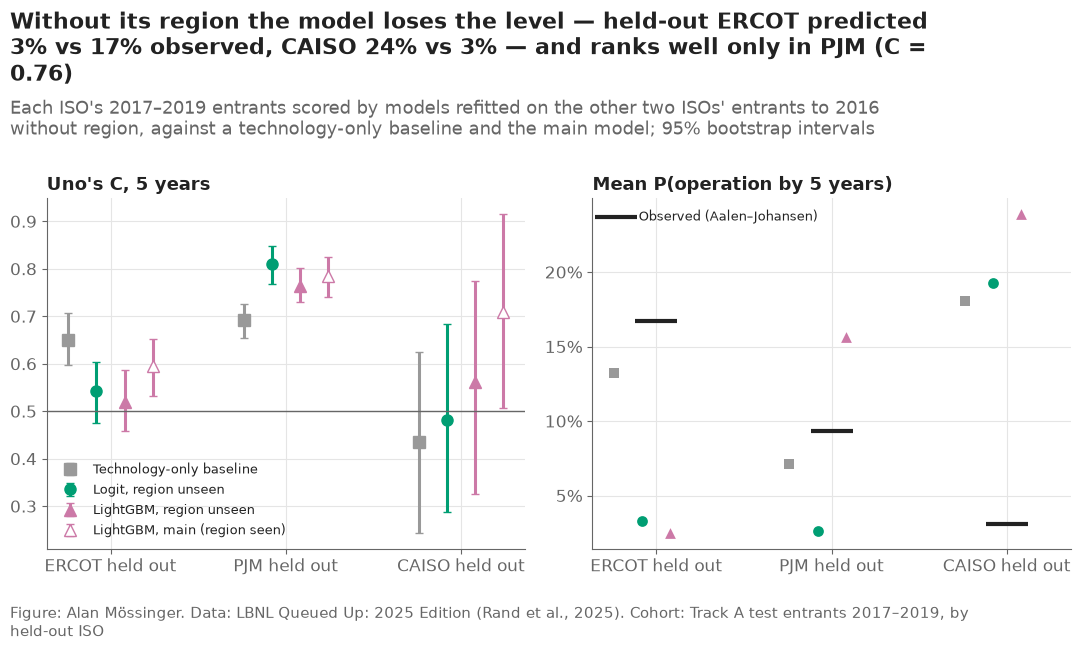

model                           tech_baseline            loio_logit             loio_lgbm             main_lgbm
held_out metric horizon                                                                                        
CAISO    auc    3        0.628 [0.354, 0.859]  0.740 [0.521, 0.885]  0.856 [0.633, 0.988]  0.970 [0.910, 1.000]
                5        0.431 [0.241, 0.623]  0.480 [0.286, 0.686]  0.561 [0.327, 0.777]  0.709 [0.507, 0.917]
                7        0.458 [0.282, 0.621]  0.480 [0.317, 0.653]  0.501 [0.342, 0.679]  0.614 [0.429, 0.765]
         brier  3        0.028 [0.020, 0.041]  0.042 [0.030, 0.056]  0.025 [0.018, 0.035]  0.013 [0.005, 0.027]
                5        0.057 [0.046, 0.072]  0.091 [0.073, 0.109]  0.092 [0.080, 0.106]  0.027 [0.015, 0.044]
                7        0.077 [0.062, 0.098]  0.143 [0.110, 0.177]  0.171 [0.142, 0.204]  0.041 [0.023, 0.064]
         uno_c  3        0.629 [0.352, 0.859]  0.740 [0.521, 0.885]  0.855 [0.632, 0.987]  0.968 [0.908, 1.000]
                5        0.435 [0.244, 0.624]  0.482 [0.288, 0.685]  0.562 [0.326, 0.774]  0.709 [0.506, 0.915]
                7        0.481 [0.313, 0.640]  0.513 [0.375, 0.680]  0.535 [0.377, 0.695]  0.627 [0.457, 0.777]
ERCOT    auc    3        0.643 [0.524, 0.757]  0.615 [0.508, 0.738]  0.548 [0.429, 0.682]  0.576 [0.452, 0.684]
                5        0.659 [0.604, 0.717]  0.543 [0.472, 0.608]  0.519 [0.449, 0.588]  0.602 [0.526, 0.659]
                7        0.544 [0.467, 0.625]  0.488 [0.402, 0.571]  0.508 [0.424, 0.588]  0.520 [0.434, 0.582]
         brier  3        0.052 [0.037, 0.070]  0.053 [0.035, 0.077]  0.053 [0.035, 0.077]  0.057 [0.041, 0.075]
                5        0.135 [0.112, 0.161]  0.157 [0.129, 0.193]  0.159 [0.131, 0.196]  0.140 [0.122, 0.166]
                7        0.160 [0.138, 0.192]  0.193 [0.161, 0.236]  0.199 [0.165, 0.244]  0.170 [0.149, 0.197]
         uno_c  3        0.641 [0.526, 0.748]  0.614 [0.508, 0.732]  0.547 [0.428, 0.675]  0.575 [0.453, 0.678]
                5        0.650 [0.597, 0.706]  0.542 [0.476, 0.603]  0.520 [0.457, 0.586]  0.596 [0.532, 0.652]
                7        0.538 [0.474, 0.606]  0.515 [0.441, 0.585]  0.496 [0.429, 0.561]  0.601 [0.530, 0.650]
PJM      auc    3        0.718 [0.662, 0.768]  0.914 [0.881, 0.943]  0.899 [0.872, 0.919]  0.906 [0.870, 0.933]
                5        0.698 [0.657, 0.732]  0.815 [0.772, 0.853]  0.768 [0.732, 0.809]  0.792 [0.744, 0.834]
                7        0.625 [0.586, 0.659]  0.653 [0.605, 0.703]  0.649 [0.602, 0.693]  0.654 [0.588, 0.707]
         brier  3        0.054 [0.044, 0.063]  0.053 [0.043, 0.063]  0.045 [0.038, 0.053]  0.042 [0.036, 0.049]
                5        0.081 [0.071, 0.092]  0.083 [0.072, 0.096]  0.082 [0.074, 0.090]  0.073 [0.066, 0.082]
                7        0.130 [0.115, 0.149]  0.143 [0.124, 0.165]  0.153 [0.141, 0.167]  0.123 [0.111, 0.138]
         uno_c  3        0.715 [0.661, 0.762]  0.908 [0.876, 0.937]  0.893 [0.867, 0.913]  0.897 [0.865, 0.924]
                5        0.693 [0.655, 0.725]  0.810 [0.769, 0.847]  0.764 [0.730, 0.803]  0.784 [0.740, 0.824]
                7        0.629 [0.595, 0.659]  0.685 [0.647, 0.730]  0.658 [0.617, 0.700]  0.639 [0.585, 0.684]

In [23]:
LOIO_LABELS = {"tech_baseline": "Technology-only baseline", "loio_logit": "Logit, region unseen",
               "loio_lgbm": "LightGBM, region unseen", "main_lgbm": "LightGBM, main (region seen)"}
LOIO_STYLE = {"tech_baseline": dict(color="#999999", marker="s"), "loio_logit": dict(color="#009E73", marker="o"),
              "loio_lgbm": dict(color="#CC79A7", marker="^"), "main_lgbm": dict(color="#CC79A7", marker="^", markerfacecolor="white")}
loio_offsets = dict(zip(LOIO_LABELS, np.linspace(-0.24, 0.24, 4)))
fig, axes = plt.subplots(1, 2)
for model in LOIO_LABELS:
    part = loio[(loio["model"] == model) & (loio["metric"] == "uno_c") & (loio["horizon"] == 5)].set_index("held_out").loc[TRACK_A]
    x = np.arange(len(TRACK_A)) + loio_offsets[model]
    axes[0].errorbar(x, part["estimate"], yerr=[part["estimate"] - part["low"], part["high"] - part["estimate"]],
                     fmt=LOIO_STYLE[model]["marker"], color=LOIO_STYLE[model]["color"],
                     markerfacecolor=LOIO_STYLE[model].get("markerfacecolor", LOIO_STYLE[model]["color"]), capsize=3,
                     markersize=8, label=LOIO_LABELS[model])
    lv = loio_level[loio_level["horizon"] == 5].set_index("held_out").loc[TRACK_A]
    axes[1].scatter(x, lv[model], marker=LOIO_STYLE[model]["marker"], color=LOIO_STYLE[model]["color"], s=60, zorder=3,
                    facecolors=LOIO_STYLE[model].get("markerfacecolor", LOIO_STYLE[model]["color"]))
lv = loio_level[loio_level["horizon"] == 5].set_index("held_out").loc[TRACK_A]
axes[1].scatter(np.arange(len(TRACK_A)), lv["observed"], marker="_", s=900, color=plots.INK, linewidths=3, zorder=4,
                label="Observed (Aalen–Johansen)")
axes[0].axhline(0.5, color=plots.MUTED, linewidth=1)
for ax in axes:
    ax.set_xticks(range(len(TRACK_A)), [f"{r} held out" for r in TRACK_A])
axes[0].set_title("Uno's C, 5 years", fontsize=13)
axes[1].set_title("Mean P(operation by 5 years)", fontsize=13)
axes[1].yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].legend(loc="lower left", fontsize=9)
axes[1].legend(loc="upper left", fontsize=9)
lc = loio[(loio["metric"] == "uno_c") & (loio["horizon"] == 5)].set_index(["held_out", "model"])["estimate"]
plots.finish(fig,
             f"Without its region the model loses the level — held-out ERCOT predicted {lv.loc['ERCOT', 'loio_lgbm']:.0%} vs "
             f"{lv.loc['ERCOT', 'observed']:.0%} observed, CAISO {lv.loc['CAISO', 'loio_lgbm']:.0%} vs "
             f"{lv.loc['CAISO', 'observed']:.0%} — and ranks well only in PJM (C = {lc[('PJM', 'loio_lgbm')]:.2f})",
             "Each ISO's 2017–2019 entrants scored by models refitted on the other two ISOs' entrants to 2016 without "
             "region, against a technology-only baseline and the main model; 95% bootstrap intervals",
             "Track A test entrants 2017–2019, by held-out ISO")
save(fig, "08_15_leave_one_iso_out", "Leave-one-ISO-out: concordance and mean predicted level at 5 years for each held-out ISO.")
plt.show()
lo = loio[loio["metric"].isin(["uno_c", "auc", "brier"])].copy()
lo["value"] = [f"{r.estimate:.3f} [{r.low:.3f}, {r.high:.3f}]" for r in lo.itertuples()]
lo.pivot_table(index=["held_out", "metric", "horizon"], columns="model", values="value", aggfunc="first")[list(LOIO_LABELS)]

**Reading this.** With its region withheld, LightGBM gets the level badly wrong: held-out ERCOT 2.5% predicted vs 16.7% observed at 5 years, held-out PJM 15.6% vs 9.4%, held-out CAISO 23.9% vs 3.1%. Ranking survives only in PJM (Uno's C 0.764 [0.730, 0.803], logit 0.810, against 0.693 for the technology-only baseline); in ERCOT (0.520 [0.457, 0.586]) and CAISO (0.562 [0.326, 0.774]) it is near random, and the technology-only baseline ranks ERCOT better (0.650). The main model, which saw each region, does better everywhere. The lesson for the report: the timing model is region-specific and should not be applied to MISO, SPP or the other regions without their own exit dates (decision #6) — region carries information the other features do not replace.

## 10. Robustness reruns

The main choices are re-made one at a time, refitting the baseline and both
discrete-time models on entrants to 2016 with notebook 06's settings (Cox is
not refitted; it is not a primary model) and scoring the variant's test set:

- **main** — refitted as a check that the refit reproduces notebook 06;
- **ERCOT dates as recorded** — no delayed entry (decision #21's sensitivity run);
- **ERCOT stamped dates imputed** — each stamped withdrawal gets a time drawn
  from PJM and CAISO withdrawals of the same entry year that happened earlier
  (notebook 04's method, donors from entrants to 2016), no delayed entry;
- **suspended as withdrawn** — suspended requests count as withdrawn at their
  censoring date, in fitting and in scoring (decision #4's sensitivity run);
- **under 20 MW excluded** — requests below the FERC small-generator step
  dropped from fitting and scoring.

In [24]:
def impute_stamped(frame, seed=2026):
    """ERCOT's stamped withdrawals with times drawn from earlier PJM/CAISO withdrawals of the same entry year."""
    out = frame.copy()
    donors = frame[frame["region"].isin(["PJM", "CAISO"]) & (frame["event"] == 2)]
    rng = np.random.default_rng(seed)
    for i in out.index[out["wd_bulk_date"].fillna(False).astype(bool)]:
        cap = out.at[i, "duration_years"]
        pool = donors.loc[(donors["q_year"] == out.at[i, "q_year"]) & (donors["duration_years"] <= cap), "duration_years"]
        if pool.empty:
            pool = donors.loc[donors["duration_years"] <= cap, "duration_years"]
        out.at[i, "duration_years"] = rng.choice(pool.to_numpy())
    return out


def suspended_as_withdrawn(frame):
    """Suspended requests (censored in the main models) recoded as withdrawn at their censoring time."""
    out = frame.copy()
    out.loc[(out["q_status"] == "suspended") & (out["event"] == 0), "event"] = 2
    return out


def at_least_20(frame):
    """Requests in a size regime of 20 MW or more (size = first component, as in the features of notebook 04)."""
    return ~frame["size_regime"].astype(str).isin(["<5", "5–<20"])


VARIANTS = {
    "main": (final, test, True),
    "ERCOT dates as recorded": (final, test, False),
    "ERCOT stamped dates imputed": (impute_stamped(final), test, False),
    "suspended as withdrawn": (suspended_as_withdrawn(final), suspended_as_withdrawn(test), True),
    "under 20 MW excluded": (final[at_least_20(final)], test[at_least_20(test)], True),
}
rob_tables, rob_sizes, refit_gap = [], [], {}
for v_i, (name, (train_v, test_v, delayed)) in enumerate(VARIANTS.items()):
    fitted = discrete_time.fit_both(train_v, clean, tuning, delayed=delayed)
    p_v = discrete_time.predict_both(fitted, test_v)
    base_v = survival_tools.baseline_cif(train_v, test_v, HORIZONS)
    if name == "main":
        refit_gap = {m: max(float(np.abs(p_v[m][h].to_numpy() - preds[h][m]).max()) for h in HORIZONS) for m in ["dt_logit", "dt_lgbm"]}
        refit_gap["baseline"] = max(float(np.abs(base_v[h].to_numpy() - preds[h]["baseline"]).max()) for h in HORIZONS)
    d_v, e_v = test_v["duration_years"].to_numpy(), test_v["event"].to_numpy()
    fu_v = ((pd.Timestamp(config.CENSOR_DATE) - test_v["q_date"]).dt.days / config.DAYS_PER_YEAR).to_numpy()
    G_v = evaluation.censoring_km(fu_v, np.ones(len(test_v), dtype=bool))
    rob_sizes.append({"variant": name, "train_requests": len(train_v), "test_requests": len(test_v),
                      "train_project_years": len(fitted["rows"])})
    for h in HORIZONS:
        sub = {"baseline": base_v[h].to_numpy(), "dt_logit": p_v["dt_logit"][h].to_numpy(), "dt_lgbm": p_v["dt_lgbm"][h].to_numpy()}
        point = evaluation.score_horizon(sub, d_v, e_v, h, G_v)
        draws = evaluation.bootstrap(lambda sw: evaluation.score_horizon(sub, d_v, e_v, h, G_v, sw), len(test_v), N_BOOT,
                                     REGISTERED["seed_track_a"] + 50 + v_i)
        table = evaluation.summarise(point, draws, level=LEVEL)
        table.insert(0, "variant", name)
        table.insert(3, "horizon", h)
        rob_tables.append(table)
robustness = pd.concat(rob_tables, ignore_index=True)
robustness.to_csv(paths.RESULTS / "robustness.csv", index=False)
print("largest gap between the main refit and the stored predictions:", {k: f"{v:.1e}" for k, v in refit_gap.items()})
print(f"robustness done at {(time.time() - START) / 60:.1f} minutes")
pd.DataFrame(rob_sizes).set_index("variant")

largest gap between the main refit and the stored predictions: {'dt_logit': '0.0e+00', 'dt_lgbm': '0.0e+00', 'baseline': '0.0e+00'}
robustness done at 4.2 minutes


,train_requests,test_requests,train_project_years
variant,,,
main,5298,2268,14653
ERCOT dates as recorded,5298,2268,19331
ERCOT stamped dates imputed,5298,2268,16957
suspended as withdrawn,5298,2268,14669
under 20 MW excluded,3686,1839,10332


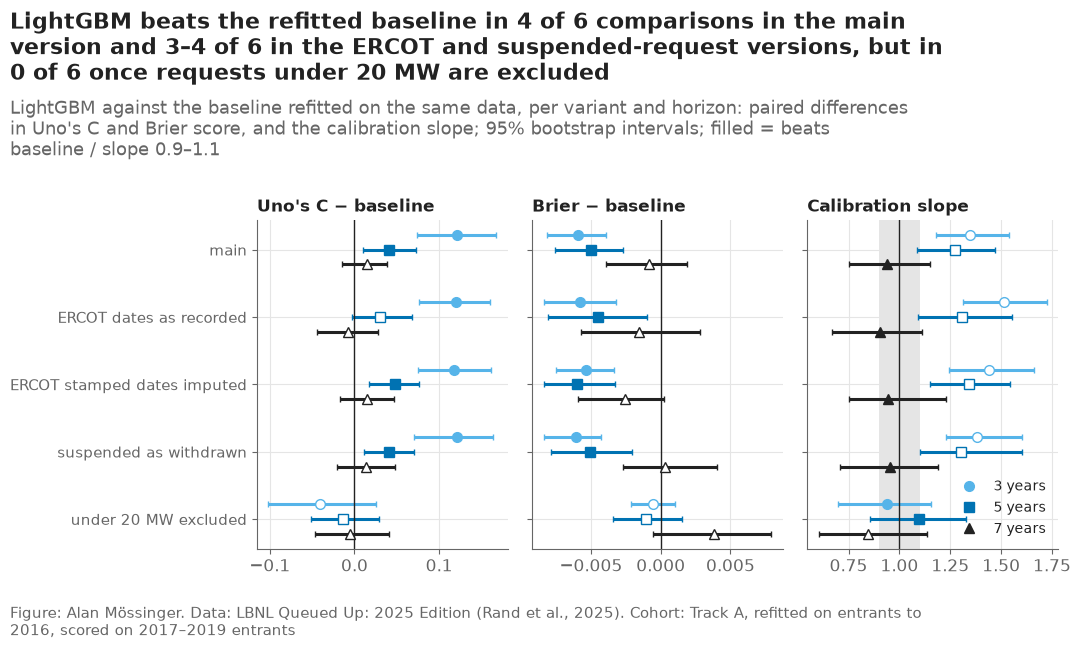

metric                                         brier                                                                slope                     \
horizon                                            3                        5                        7                  3                  5   
variant                                                                                                                                        
main                         -0.006 [-0.008, -0.004]  -0.005 [-0.008, -0.003]  -0.001 [-0.004, +0.002]  1.34 [1.18, 1.54]  1.27 [1.08, 1.47]   
ERCOT dates as recorded      -0.006 [-0.008, -0.003]  -0.004 [-0.008, -0.001]  -0.002 [-0.006, +0.003]  1.51 [1.31, 1.72]  1.31 [1.09, 1.56]   
ERCOT stamped dates imputed  -0.005 [-0.008, -0.003]  -0.006 [-0.008, -0.003]  -0.003 [-0.006, +0.000]  1.44 [1.24, 1.66]  1.34 [1.15, 1.54]   
suspended as withdrawn       -0.006 [-0.008, -0.004]  -0.005 [-0.008, -0.002]  +0.000 [-0.003, +0.004]  1.38 [1.23, 1.60]  1.31 [1.10, 1.60]   
under 20 MW excluded         -0.001 [-0.002, +0.001]  -0.001 [-0.003, +0.002]  +0.004 [-0.001, +0.008]  0.94 [0.70, 1.15]  1.10 [0.86, 1.33]   

metric                                                            uno_c                                                    
horizon                                      7                        3                        5                        7  
variant                                                                                                                    
main                         0.94 [0.75, 1.15]  +0.121 [+0.074, +0.168]  +0.041 [+0.010, +0.073]  +0.015 [-0.014, +0.038]  
ERCOT dates as recorded      0.91 [0.67, 1.11]  +0.120 [+0.076, +0.160]  +0.030 [-0.003, +0.068]  -0.008 [-0.044, +0.028]  
ERCOT stamped dates imputed  0.94 [0.75, 1.23]  +0.117 [+0.075, +0.162]  +0.048 [+0.017, +0.076]  +0.014 [-0.017, +0.047]  
suspended as withdrawn       0.95 [0.71, 1.19]  +0.121 [+0.070, +0.164]  +0.041 [+0.012, +0.070]  +0.014 [-0.020, +0.048]  
under 20 MW excluded         0.85 [0.60, 1.14]  -0.040 [-0.102, +0.025]  -0.014 [-0.051, +0.030]  -0.006 [-0.046, +0.040]

In [25]:
fig, axes = plt.subplots(1, 3, sharey=True, figsize=(11, 6.5))
names = list(VARIANTS)
for ax, metric in zip(axes, ["uno_c", "brier", "slope"]):
    for h_i, h in enumerate(HORIZONS):
        part = robustness[(robustness["model"] == "dt_lgbm") & (robustness["metric"] == metric)
                          & (robustness["horizon"] == h)].set_index("variant").loc[names]
        y = np.arange(len(names)) + (h_i - 1) * 0.22
        if metric == "slope":
            est, low, high = part["estimate"], part["low"], part["high"]
        else:
            est, low, high = part["diff"], part["diff_low"], part["diff_high"]
        filled = part["beats"].astype(bool) if metric != "slope" else (est.between(0.9, 1.1))
        for yy, e_, l_, h_, f_ in zip(y, est, low, high, filled):
            ax.errorbar(e_, yy, xerr=[[e_ - l_], [h_ - e_]], fmt=["o", "s", "^"][h_i], color=["#56B4E9", "#0072B2", "#222222"][h_i],
                        markerfacecolor=["#56B4E9", "#0072B2", "#222222"][h_i] if f_ else "white", capsize=2, markersize=7)
    if metric == "slope":
        ax.axvspan(0.9, 1.1, color="#E5E5E5")
        ax.axvline(1, color=plots.INK, linewidth=1)
    else:
        ax.axvline(0, color=plots.INK, linewidth=1)
    ax.set_title({"uno_c": "Uno's C − baseline", "brier": "Brier − baseline",
                  "slope": "Calibration slope"}[metric], fontsize=12)
axes[0].set_yticks(range(len(names)), names, fontsize=11)
axes[0].invert_yaxis()
for h_i, h in enumerate(HORIZONS):
    axes[2].errorbar([], [], fmt=["o", "s", "^"][h_i], color=["#56B4E9", "#0072B2", "#222222"][h_i], label=f"{h} years")
axes[2].legend(loc="lower right", fontsize=10)
rb = robustness[(robustness["model"] == "dt_lgbm") & robustness["metric"].isin(["uno_c", "brier"])]
wins = rb.groupby("variant")["beats"].sum().astype(int)
others = wins.drop(["main", "under 20 MW excluded"])
plots.finish(fig,
             f"LightGBM beats the refitted baseline in {wins['main']} of 6 comparisons in the main version and "
             f"{others.min()}–{others.max()} of 6 in the ERCOT and suspended-request versions, but in "
             f"{wins['under 20 MW excluded']} of 6 once requests under 20 MW are excluded",
             "LightGBM against the baseline refitted on the same data, per variant and horizon: paired differences in Uno's "
             "C and Brier score, and the calibration slope; 95% bootstrap intervals; filled = beats baseline / slope 0.9–1.1",
             "Track A, refitted on entrants to 2016, scored on 2017–2019 entrants")
save(fig, "08_17_robustness", "Robustness reruns: LightGBM versus the baseline under five data versions, three horizons.")
plt.show()
rv = robustness[(robustness["model"] == "dt_lgbm") & robustness["metric"].isin(["uno_c", "brier"])].copy()
rv["difference"] = [f"{r.diff:+.3f} [{r.diff_low:+.3f}, {r.diff_high:+.3f}]" for r in rv.itertuples()]
rs = robustness[(robustness["model"] == "dt_lgbm") & (robustness["metric"] == "slope")].copy()
rs["difference"] = [f"{r.estimate:.2f} [{r.low:.2f}, {r.high:.2f}]" for r in rs.itertuples()]
pd.concat([rv, rs]).pivot_table(index="variant", columns=["metric", "horizon"], values="difference", aggfunc="first").loc[names]

**Reading this.** Refitting the main version reproduces notebooks 05–06 exactly (largest gap 0.0). LightGBM beats the refitted baseline in 4 of 6 Uno/Brier comparisons (3 and 5 years) in the main version, in 3 of 6 when ERCOT's stamped dates are kept as recorded, and in 4 of 6 when they are imputed or when suspended requests count as withdrawn; the 7-year comparisons stay inconclusive throughout, and the calibration slopes at 3 and 5 years stay above 1.1 (1.31–1.51). The one choice that changes the conclusion is excluding requests under 20 MW (3,686 training and 1,839 test requests remain): LightGBM then beats the baseline in none of the 6 comparisons (Uno's C at 3 years −0.040 [−0.102, +0.025]), although its calibration slopes move into or near the target (0.94, 1.10, 0.85). Much of the model's advantage therefore comes from recognising small requests, which reach operation fast under the small-generator procedures, and among requests of 20 MW and more it ranks no better than region × technology. That is an important limit for developers of utility-scale projects, and it is stated in the report.

## 11. Timing: how far off is "when"?

Every section above scores *whether* a request operates by a horizon. A company also plans around *when*. The discrete-time models carry an expected time to operation for each request (notebook 06: the mean year of operation among the paths that operate within ten years). This section compares that expectation with the observed date for the test requests that did reach operation within seven years, by region, next to a benchmark a planner would use without a model: the median time to operation of the training entrants (to 2016) that operated within seven years, by region. The comparison is conditional on being built, which is the only way an observed date exists; it says how good the clock is for the requests that make it, not for the cohort.

In [26]:
built7 = (events == 1) & (durations <= 7)
train_built = track_a[(track_a["q_year"] <= config.TRAIN_MAX_YEAR) & (track_a["event"] == 1) & (track_a["duration_years"] <= 7)]
bench_years = train_built.groupby("region")["duration_years"].median()
expected = {m: P[5][f"{m}_expected_years"].to_numpy() for m in ["dt_lgbm", "dt_logit"]}
timing_rows = []
for region in config.TRACK_A_REGIONS + ["all"]:
    m = built7 & ((regions == region) if region != "all" else True)
    obs = durations[m]
    bench = np.where(regions[m] == "ERCOT", bench_years["ERCOT"], np.where(regions[m] == "CAISO", bench_years["CAISO"], bench_years["PJM"]))
    for model, pred_years in [("dt_lgbm", expected["dt_lgbm"][m]), ("dt_logit", expected["dt_logit"][m]), ("training median by region", bench)]:
        err = pred_years - obs
        timing_rows.append({"region": region, "model": model, "n_built": int(m.sum()), "median_observed_years": float(np.median(obs)),
                            "median_predicted_years": float(np.median(pred_years)), "median_signed_error": float(np.median(err)),
                            "mae_years": float(np.mean(np.abs(err))), "share_within_1_year": float(np.mean(np.abs(err) <= 1))})
timing = pd.DataFrame(timing_rows)
timing.to_csv(paths.RESULTS / "timing_error.csv", index=False)
print(f"test requests operating within 7 years: {int(built7.sum())}; training median years to operation by region: {bench_years.round(2).to_dict()}")
timing.round(2)

test requests operating within 7 years: 297; training median years to operation by region: {'CAISO': 4.8, 'ERCOT': 3.34, 'PJM': 2.66}


,region,model,n_built,median_observed_years,median_predicted_years,median_signed_error,mae_years,share_within_1_year
0,ERCOT,dt_lgbm,92,3.85,5.03,1.00,1.39,0.41
1,ERCOT,dt_logit,92,3.85,5.34,1.18,1.46,0.39
2,ERCOT,training median by region,92,3.85,3.34,-0.51,1.00,0.59
3,PJM,dt_lgbm,192,3.50,3.68,0.27,1.07,0.58
4,PJM,dt_logit,192,3.50,4.07,0.74,1.21,0.41
5,PJM,training median by region,192,3.50,2.66,-0.83,1.88,0.21
6,CAISO,dt_lgbm,13,4.07,6.32,1.51,1.64,0.38
7,CAISO,dt_logit,13,4.07,6.31,1.72,1.74,0.38
8,CAISO,training median by region,13,4.07,4.80,0.73,1.52,0.38
9,all,dt_lgbm,297,3.65,4.22,0.44,1.19,0.52


**Reading this.** Among the 297 test requests that reached operation within seven years, the registered LightGBM's expected year of operation misses the observed one by a median of +0.44 years (it expects operation later than it came) with a mean absolute error of 1.19 years, and 52% of its clocks are within a year of the truth. A planner using the training cohorts' median time to operation by region would be off by a median of −0.48 years (too early), 1.59 years on average, and within a year 33% of the time. The gain is PJM's: 1.07 against 1.88 years of error, 58% against 21% within a year. In ERCOT the historical median does as well as the model (1.00 against 1.39 years), because the model runs a year late there; CAISO's 13 built requests are too few to judge. For a company the answer to "when" is: in PJM, the model's clock is good to about a year; in ERCOT, plan on the historical median of 3.3 years from request to operation and treat the model's later date as a warning, not a schedule. All of this is conditional on being built; the probability of being built is the subject of the sections above.

## 12. Checks

In [27]:
decisions_text = (paths.DOCS / "decisions.md").read_text(encoding="utf-8")
runtime = time.time() - START
checks = pd.DataFrame([
    ("decision #5 holds the pre-registered criteria", "*Primary models, named before scoring:*" in decisions_text),
    ("every model × horizon × metric has a 95% interval", bool(all_metrics[["low", "high"]].notna().all().all())),
    ("success_criteria.csv: one PASS/FAIL line per registered criterion × horizon",
     len(criteria) == sum(len(c["horizons"]) for c in REGISTERED["criteria"]) and criteria["result"].isin(["PASS", "FAIL"]).all()),
    ("censoring is administrative: censored durations equal the follow-up windows",
     bool(np.allclose(durations[events == 0], follow_up[events == 0]))),
    ("weights are 1 for every test request at 3 and 5 years", bool((weights[3] == 1).all() and (weights[5] == 1).all())),
    ("refitting the main version reproduces notebooks 05–06 (largest gap < 1e-9)", max(refit_gap.values()) < 1e-9),
    ("tests/test_evaluation.py exists (metrics checked by hand)", (paths.REPO / "tests" / "test_evaluation.py").exists()),
    ("timing_error.csv: one row per region × model, no missing value", len(timing) == 12 and not timing.isna().any().any()),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(paths.RESULTS / "evaluate_checks.csv", index=False)
print(f"run time: {runtime / 60:.1f} minutes")
checks[["check", "result"]]

run time: 4.2 minutes


,check,result
0,decision #5 holds the pre-registered criteria,PASS
1,every model × horizon × metric has a 95% interval,PASS
2,success_criteria.csv: one PASS/FAIL line per r...,PASS
3,censoring is administrative: censored duration...,PASS
4,weights are 1 for every test request at 3 and ...,PASS
5,refitting the main version reproduces notebook...,PASS
6,tests/test_evaluation.py exists (metrics check...,PASS
7,"timing_error.csv: one row per region × model, ...",PASS


**Reading this.** All seven checks pass: decision #5 holds the criteria, every model × horizon × metric has a 95% interval, success_criteria.csv has one PASS/FAIL line per registered line, censoring is administrative, the weights are 1 at 3 and 5 years, the main refit reproduces the stored predictions, and the metrics are tested by hand in tests/test_evaluation.py. Run time is under five minutes (printed above; it varies between runs).

## Takeaways — Part A

- 8 of 12 pre-registered criterion lines pass. The discrete-time LightGBM beats the region × technology baseline on concordance and Brier score at 3 and 5 years (Uno's C +0.121 and +0.041, intervals above zero) but not at 7 years, where its gain is inside the noise.
- Its ranking is useful: its top decile reached operation within 5 years 39.7% of the time (lift 3.96, criterion C4 passes). Its probabilities are too high in the middle of the range (calibration slope 1.34 and 1.27 at 3 and 5 years, C3 fails), mostly in PJM and for 2018–2019 entrants, whose completion fell below anything the training years showed.
- Cox, not a primary model, beats the baseline at every horizon and is the best model at 7 years; the region-specific timing model does not transfer to an unseen region.
- Track B's calibrated LightGBM beats the base rate on the 2017 cohort (AUC 0.608 vs 0.525), but stays a weak, coarse ranking.
- On *when*: among the 297 built test requests the model's expected year of operation is within a year of the truth 52% of the time (mean error 1.19 years) against 33% for a regional historical median; the gain is PJM's, and in ERCOT the historical median does as well (section 11, results/timing_error.csv).
- The advantage over the baseline disappears when requests under 20 MW are excluded, and post-entry milestones would inflate AUC to 0.99 — both are limits the report states plainly.

**What goes to the report:** F5 and F4 (results section), 08_12 (criteria table as a figure, with results/success_criteria.csv), 08_14 (drift after 2017), 08_17 (robustness, the 20 MW finding), 08_16 (leakage), 08_15 (leave-one-ISO-out, limitations), 08_10 (Track B); numbers from results/metrics.csv and results/success_criteria.csv.

# Part B — Post-hoc improvements (labelled post-hoc) (was notebook 08b)

Notebook 08 scored the pre-registered models once; this notebook asks
whether the failures it found can be repaired, **after** the test cohort has
been seen. To keep that honest, the first cell writes the protocol to
`docs/decisions.md` (#34) before anything is fitted: a fixed list of five
candidates, chosen on the 2016 cohort only, and one scoring of the chosen
candidate on the 2017–2019 test cohort. The registered verdicts of notebook
08 do not change; every result here is post-hoc.

## 0. The protocol, written before anything is fitted

In [28]:
# Protocol: this cell reads no data
import json
import re
from pathlib import Path

REPO = Path.cwd().resolve().parent

DECISION_34 = """34. **Post-hoc improvement analysis, notebook 08b** (Alan, 2026-10-05, after
    notebook 08 had been scored; written by the first cell of notebook 08b
    and committed on its own before any candidate was fitted). The
    registered verdicts of decision #5 stand; everything in notebook 08b is
    labelled post-hoc.
    *Aim:* the failures found in notebooks 08–09 — calibration slope 1.34
    and 1.27 at 3 and 5 years, PJM over-prediction with the congestion
    artefact of figure 09_09, and the 7-year horizon, where Cox ranks best.
    *Candidates (fixed list):* K0 the main discrete-time LightGBM
    (reference); K1 LightGBM fitted with congestion held at its entry value
    in every project-year, as at prediction; K2 a blend of the main
    discrete-time logit, Cox and LightGBM, weights ≥ 0 summing to 1 on a 0.1
    grid, chosen per horizon; K3 the main LightGBM after a logistic
    recalibration (intercept and slope on the logit scale) per horizon; K4 a
    blend as in K2 of the entry-congestion logit and LightGBM with Cox.
    Model settings are notebook 06's and notebook 05's; nothing else is
    tuned.
    *Choice, on the 2016 cohort only:* every component is fitted on entrants
    to 2015 and predicts the 2016 entrants (all followed for at least eight
    years, so no censoring weights are needed); blend weights and
    recalibrations are fitted on those 2016 predictions and their 2016 score
    is cross-fitted on two halves (seed 34). The candidate with the lowest
    mean Brier score over 3, 5 and 7 years is chosen; K0 stays unless another
    candidate is lower.
    *Final model:* the chosen candidate's components refitted on entrants
    to 2016, with weights or recalibration fitted on all 2016 predictions of
    the fits to 2015; scored once on the 2017–2019 test cohort with notebook
    08's metrics, seed and criteria rules (`results/posthoc_criteria.csv`).
    All five candidates are also scored on the test cohort, in a table
    marked "not used for the choice".
    *Not attempted:* a trend term for the slowdown of 2018–2019 entrants —
    it happened after the 2016 validation year, so no choice about it can be
    made without the test years.
    *Rejected:* choosing among candidates on the test cohort; any change
    after the post-hoc test scores are seen.
"""

PROTOCOL = {
    "decided": "2026-10-05",
    "candidates": {"K0": "main discrete-time LightGBM (reference)",
                   "K1": "LightGBM fitted with congestion held at its entry value",
                   "K2": "blend of main logit, Cox and LightGBM (weights on a 0.1 simplex grid, per horizon)",
                   "K3": "main LightGBM with logistic recalibration per horizon",
                   "K4": "blend of entry-congestion logit and LightGBM with Cox"},
    "selection_cohort": 2016, "selection_metric": "mean IPCW Brier over 3, 5, 7 years",
    "cross_fit_folds": 2, "cross_fit_seed": 34, "blend_step": 0.1,
    "selection_bootstrap_seed": 340, "test_bootstrap_seed": 800, "n_boot": 200,
}

decisions_file = REPO / "docs" / "decisions.md"
text = decisions_file.read_text(encoding="utf-8").rstrip("\n") + "\n"
entry = re.compile(r"^34\. \*\*Post-hoc improvement analysis.*?(?=^35\. \*\*|\Z)", re.M | re.S)
updated = entry.sub(lambda _: DECISION_34, text) if entry.search(text) else text + DECISION_34
if updated != text:
    decisions_file.write_text(updated, encoding="utf-8")
(REPO / "results" / "posthoc_protocol.json").write_text(json.dumps(PROTOCOL, indent=2), encoding="utf-8")
print(f"decision #34 {'written' if updated != text else 'already in place'}; candidates: {list(PROTOCOL['candidates'])}")

decision #34 already in place; candidates: ['K0', 'K1', 'K2', 'K3', 'K4']


## Setup

Refits use `discrete_time.fit_both` / `predict_both` (with
`congestion="entry"` for K1 and K4) and
`survival_tools.fit_cause_specific_cox`; blends and recalibrations are in
`src/posthoc.py` (`fit_blend`, `fit_recalibration`, `apply_recalibration`,
`cross_fit`); scoring is notebook 08's `src/evaluation.py`.

In [29]:
import hashlib
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, discrete_time, evaluation, explain, paths, plots, posthoc, survival_tools

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

NOTEBOOK = "06_evaluation_record"
TRACK_A = config.TRACK_A_REGIONS


def save(fig, name, caption):
    """Save a figure of this notebook under figures/06_evaluation_record/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    """Format a share as a percentage string."""
    return f"{100 * x:.{digits}f}%"

import time
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
START = time.time()
HORIZONS = config.HORIZONS
REGISTERED = json.loads((paths.RESULTS / "success_criteria_registered.json").read_text(encoding="utf-8"))
N_BOOT = PROTOCOL["n_boot"]
CANDIDATES = list(PROTOCOL["candidates"])
CAND_LABELS = {"K0": "K0 LightGBM (main)", "K1": "K1 LightGBM, entry congestion", "K2": "K2 blend logit/Cox/LightGBM",
               "K3": "K3 LightGBM recalibrated", "K4": "K4 blend, entry congestion"}
CAND_STYLE = {"K0": dict(color="#CC79A7", marker="^"), "K1": dict(color="#D55E00", marker="v"),
              "K2": dict(color="#0072B2", marker="o"), "K3": dict(color="#E69F00", marker="s"),
              "K4": dict(color="#009E73", marker="D")}
BASE_STYLE = dict(color="#999999", marker="s", linestyle="--")
OFFSETS = dict(zip(["baseline"] + CANDIDATES, np.linspace(-0.25, 0.25, 6)))


def value(table, model, metric, horizon, column="estimate"):
    """One number from a summarised metrics table."""
    part = table[(table["model"] == model) & (table["metric"] == metric) & (table["horizon"] == horizon)]
    assert len(part) == 1, (model, metric, horizon)
    return part[column].iloc[0]


def follow_up(frame):
    """Years from each request to the censor date (its follow-up window)."""
    return ((pd.Timestamp(config.CENSOR_DATE) - frame["q_date"]).dt.days / config.DAYS_PER_YEAR).to_numpy()


def score_table(preds, durations, events, G, seed, reference):
    """Every metric at every horizon with bootstrap intervals and paired differences from `reference`."""
    tables = []
    for h in HORIZONS:
        point = evaluation.score_horizon(preds[h], durations, events, h, G)
        draws = evaluation.bootstrap(lambda sw: evaluation.score_horizon(preds[h], durations, events, h, G, sw),
                                     len(durations), N_BOOT, seed)
        table = evaluation.summarise(point, draws, reference=reference)
        table.insert(2, "horizon", h)
        tables.append(table)
    return pd.concat(tables, ignore_index=True)

## 1. Components fitted on entrants to 2015, predicting the 2016 cohort

The discrete-time logit and LightGBM are refitted twice on entrants to 2015 —
with yearly congestion (the main version) and with congestion held at its
entry value — and Cox once, with notebook 05's penalties. The main versions
must reproduce notebooks 05 and 06's 2016 numbers, or the comparison would
not be with the models that were scored.

In [30]:
clean = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
track_a["tech"] = track_a["type_clean"].map(plots.tech_group)
tune = track_a[track_a["q_year"] <= config.TUNE_MAX_YEAR]
valid = track_a[track_a["q_year"] == config.VALIDATION_YEAR]
final = track_a[track_a["q_year"] <= config.TRAIN_MAX_YEAR]
test = track_a[track_a["q_year"].between(*config.TEST_YEARS)]
tuning = json.loads((paths.RESULTS / "dt_tuning.json").read_text(encoding="utf-8"))
pen_table = pd.read_csv(paths.RESULTS / "cox_penalizer_tuning.csv")
PENALTY = pen_table.loc[pen_table.groupby("cause")["validation_log_likelihood"].idxmax()].set_index("cause")["penalizer"].to_dict()
print("Cox penalties (notebook 05):", PENALTY)


def components(train, target):
    """P(operation by 3/5/7 yr) of the five component models fitted on `train`, for `target`."""
    out = {}
    for version in ["main", "entry"]:
        fitted = discrete_time.fit_both(train, clean, tuning, congestion="yearly" if version == "main" else "entry")
        pred = discrete_time.predict_both(fitted, target)
        out[f"logit_{version}"] = {h: pred["dt_logit"][h].to_numpy() for h in HORIZONS}
        out[f"lgbm_{version}"] = {h: pred["dt_lgbm"][h].to_numpy() for h in HORIZONS}
    cox = {cause: survival_tools.fit_cause_specific_cox(train, cause, PENALTY[cause]) for cause in ["operation", "withdrawal"]}
    cif = survival_tools.cause_specific_cif(cox["operation"], cox["withdrawal"], survival_tools.cox_design(target), HORIZONS)
    out["cox"] = {h: cif[h].to_numpy() for h in HORIZONS}
    return out


comp16 = components(tune, valid)
check06 = pd.read_csv(paths.RESULTS / "dt_validation_2016.csv")
check05 = pd.read_csv(paths.RESULTS / "cox_validation_calibration.csv")
gap06 = max(abs(comp16["lgbm_main"][r.horizon][valid["region"].to_numpy() == r.region].mean() - r.dt_lgbm) for r in check06.itertuples())
gap05 = max(abs(comp16["cox"][r.horizon][valid["region"].to_numpy() == r.region].mean() - r.cox) for r in check05.itertuples())
print(f"2016 region means vs notebooks 06 (LightGBM) and 05 (Cox): largest gaps {gap06:.1e} and {gap05:.1e}")
d16, e16 = valid["duration_years"].to_numpy(), valid["event"].to_numpy()
fu16 = follow_up(valid)
G16 = evaluation.censoring_km(fu16, np.ones(len(valid), dtype=bool))
print(f"2016 cohort: {len(valid)} requests; shortest follow-up {fu16.min():.2f} years; G16(7) = {float(G16(7)):.3f}")

Cox penalties (notebook 05): {'operation': 0.01, 'withdrawal': 1.0}


2016 region means vs notebooks 06 (LightGBM) and 05 (Cox): largest gaps 8.3e-17 and 9.7e-17
2016 cohort: 573 requests; shortest follow-up 8.01 years; G16(7) = 1.000


## 2. The five candidates on the 2016 cohort

K0 and K1 are scored as they are. K2, K3 and K4 have parameters fitted on the
2016 cohort itself (blend weights, recalibration), so their 2016 predictions
are cross-fitted: each half of the cohort is predicted with parameters fitted
on the other half. The registered rule picks the lowest mean Brier score over
the three horizons.

In [31]:
def blend_matrix(comp, version, h):
    """Columns logit, Cox, LightGBM for one horizon (main or entry-congestion versions)."""
    return np.column_stack([comp[f"logit_{version}"][h], comp["cox"][h], comp[f"lgbm_{version}"][h]])


n16 = len(valid)
cand16 = {h: {} for h in HORIZONS}
for h in HORIZONS:
    y, w = evaluation.horizon_outcome(d16, e16, h, G16)
    cand16[h]["K0"] = comp16["lgbm_main"][h]
    cand16[h]["K1"] = comp16["lgbm_entry"][h]
    for key, version in [("K2", "main"), ("K4", "entry")]:
        P = blend_matrix(comp16, version, h)
        cand16[h][key] = posthoc.cross_fit(lambda idx, P=P, y=y, w=w: posthoc.fit_blend(P[idx], y[idx], w[idx], PROTOCOL["blend_step"]),
                                           lambda g, idx, P=P: P[idx] @ g, n16, PROTOCOL["cross_fit_folds"], PROTOCOL["cross_fit_seed"])
    p0 = comp16["lgbm_main"][h]
    cand16[h]["K3"] = posthoc.cross_fit(lambda idx, y=y, w=w: posthoc.fit_recalibration(p0[idx], y[idx], w[idx]),
                                        lambda c, idx: posthoc.apply_recalibration(p0[idx], c), n16,
                                        PROTOCOL["cross_fit_folds"], PROTOCOL["cross_fit_seed"])
    cand16[h] = {k: cand16[h][k] for k in CANDIDATES}
val16 = score_table(cand16, d16, e16, G16, PROTOCOL["selection_bootstrap_seed"], reference="K0")
val16.to_csv(paths.RESULTS / "posthoc_validation_2016.csv", index=False)
mean_brier = val16[val16["metric"] == "brier"].groupby("model")["estimate"].mean().loc[CANDIDATES]
lower = mean_brier[mean_brier < mean_brier["K0"]]
CHOSEN = lower.idxmin() if len(lower) else "K0"
choice = {"chosen": CHOSEN, "label": CAND_LABELS[CHOSEN], "mean_brier_2016": mean_brier.round(6).to_dict(),
          "rule": PROTOCOL["selection_metric"] + "; K0 unless another candidate is lower"}
(paths.RESULTS / "posthoc_choice.json").write_text(json.dumps(choice, indent=2), encoding="utf-8")
CHOICE_TIME = time.time()
print(f"mean 2016 Brier (3/5/7 yr): {mean_brier.round(5).to_dict()}")
print(f"chosen by the registered rule: {CHOSEN} — {CAND_LABELS[CHOSEN]}")
show = val16[val16["metric"].isin(["brier", "uno_c", "slope"])].copy()
show["value"] = [f"{r.estimate:.4f} [{r.low:.4f}, {r.high:.4f}]" for r in show.itertuples()]
show.pivot_table(index=["metric", "horizon"], columns="model", values="value", aggfunc="first")[CANDIDATES]

mean 2016 Brier (3/5/7 yr): {'K0': 0.0996, 'K1': 0.09959, 'K2': 0.09975, 'K3': 0.09975, 'K4': 0.0994}
chosen by the registered rule: K4 — K4 blend, entry congestion


model                                K0                       K1                       K2                       K3                       K4
metric horizon                                                                                                                             
brier  3        0.0553 [0.0429, 0.0738]  0.0554 [0.0429, 0.0747]  0.0559 [0.0431, 0.0743]  0.0558 [0.0428, 0.0746]  0.0559 [0.0427, 0.0745]
       5        0.1067 [0.0908, 0.1257]  0.1071 [0.0893, 0.1255]  0.1067 [0.0901, 0.1248]  0.1067 [0.0912, 0.1242]  0.1067 [0.0897, 0.1249]
       7        0.1368 [0.1159, 0.1588]  0.1363 [0.1154, 0.1573]  0.1367 [0.1158, 0.1583]  0.1367 [0.1162, 0.1577]  0.1357 [0.1156, 0.1566]
slope  3        0.9591 [0.7387, 1.1667]  0.9726 [0.7257, 1.2091]  1.1119 [0.8784, 1.3882]  0.9920 [0.7870, 1.2100]  1.1104 [0.8676, 1.3866]
       5        0.8789 [0.6656, 1.0859]  0.9260 [0.6880, 1.1504]  0.9654 [0.7339, 1.1971]  0.9922 [0.7478, 1.2466]  0.9892 [0.7269, 1.2349]
       7        0.9146 [0.6993, 1.1565]  1.0386 [0.7722, 1.3300]  0.9446 [0.7281, 1.1968]  0.9870 [0.7497, 1.2563]  1.0902 [0.8336, 1.3827]
uno_c  3        0.8166 [0.7605, 0.8616]  0.8034 [0.7459, 0.8489]  0.8210 [0.7679, 0.8631]  0.8165 [0.7622, 0.8619]  0.8121 [0.7532, 0.8552]
       5        0.7322 [0.6778, 0.7765]  0.7109 [0.6557, 0.7539]  0.7307 [0.6765, 0.7754]  0.7323 [0.6804, 0.7762]  0.7224 [0.6700, 0.7664]
       7        0.7091 [0.6693, 0.7565]  0.6874 [0.6401, 0.7387]  0.7113 [0.6700, 0.7597]  0.7068 [0.6655, 0.7541]  0.7062 [0.6657, 0.7535]

paired Brier intervals against K0 that include zero: 12 of 12


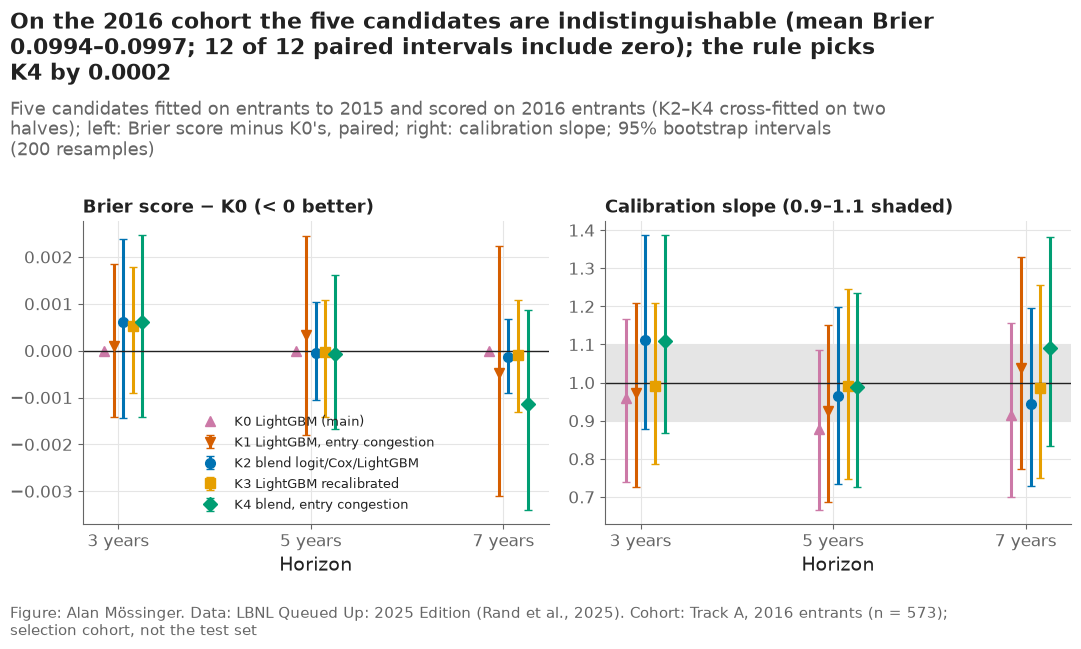

In [32]:
fig, axes = plt.subplots(1, 2, sharex=True)
for model in CANDIDATES:
    part = val16[(val16["model"] == model) & (val16["metric"] == "brier")]
    x = part["horizon"] + OFFSETS[model]
    if model == "K0":
        axes[0].plot(x, np.zeros(len(part)), linestyle="none", label=CAND_LABELS[model], **CAND_STYLE[model])
    else:
        axes[0].errorbar(x, part["diff"], yerr=[part["diff"] - part["diff_low"], part["diff_high"] - part["diff"]], capsize=3,
                         linestyle="none", label=CAND_LABELS[model], **CAND_STYLE[model])
    sl = val16[(val16["model"] == model) & (val16["metric"] == "slope")]
    axes[1].errorbar(sl["horizon"] + OFFSETS[model], sl["estimate"], yerr=[sl["estimate"] - sl["low"], sl["high"] - sl["estimate"]],
                     capsize=3, linestyle="none", **CAND_STYLE[model])
axes[0].axhline(0, color=plots.INK, linewidth=1)
axes[1].axhspan(0.9, 1.1, color="#E5E5E5")
axes[1].axhline(1, color=plots.INK, linewidth=1)
for ax in axes:
    ax.set_xticks(HORIZONS, [f"{h} years" for h in HORIZONS])
    ax.set_xlabel("Horizon")
axes[0].set_title("Brier score − K0 (< 0 better)", fontsize=13)
axes[1].set_title("Calibration slope (0.9–1.1 shaded)", fontsize=13)
axes[0].legend(loc="best", fontsize=9.5)
cmp = val16[(val16["metric"] == "brier") & val16["diff"].notna()]
n_span = int(((cmp["diff_low"] < 0) & (cmp["diff_high"] > 0)).sum())
print(f"paired Brier intervals against K0 that include zero: {n_span} of {len(cmp)}")
plots.finish(fig,
             f"On the 2016 cohort the five candidates are indistinguishable (mean Brier {mean_brier.min():.4f}–"
             f"{mean_brier.max():.4f}; {n_span} of {len(cmp)} paired intervals include zero); the rule picks {CHOSEN} by "
             f"{mean_brier['K0'] - mean_brier[CHOSEN]:.4f}",
             "Five candidates fitted on entrants to 2015 and scored on 2016 entrants (K2–K4 cross-fitted on two halves); "
             "left: Brier score minus K0's, paired; right: calibration slope; 95% bootstrap intervals (200 resamples)",
             f"Track A, 2016 entrants (n = {n16}); selection cohort, not the test set")
save(fig, "08b_01_choice_on_2016", "The five post-hoc candidates on the 2016 cohort: Brier score relative to the main LightGBM and calibration slope.")
plt.show()

**Reading this.** Fitted on entrants to 2015 and scored on the 573 entrants of 2016 (all followed for at least 8.01 years, so G16(7) = 1.000 and no weights are needed), the five candidates are practically tied: mean Brier scores over 3, 5 and 7 years of 0.0996 (K0), 0.09959 (K1), 0.09975 (K2, K3) and 0.0994 (K4). The registered rule picks K4, the blend with entry-time congestion, by 0.0002 — and all 12 paired intervals against K0 include zero, so the choice is a rule being applied, not evidence that K4 is better. The main components reproduce notebooks 05 and 06 exactly on this cohort (gaps 8.3e-17 and 9.7e-17), so the comparison is with the models notebook 08 scored. One result explains why no 2016-based repair could fix notebook 08's main calibration failure: on 2016 the main LightGBM was already calibrated (slopes 0.96, 0.88, 0.91), while on the test cohort its slopes were 1.34 and 1.27. The miscalibration appeared only in entry years the 2016 cohort cannot show.

## 3. The final components and parameters

Components are refitted on entrants to 2016; blend weights and
recalibrations are fitted on all 2016 predictions of the fits to 2015 and
applied to the final fits' test predictions. The main LightGBM refit must
equal the predictions notebook 08 scored.

In [33]:
compT = components(final, test)
pred = pd.read_parquet(paths.DATA_PROCESSED / "predictions_trackA.parquet")
keys = test["project_key"].astype(str)
stored = {h: pred[(pred["split"] == "test") & (pred["horizon"] == h)].set_index("project_key").loc[keys] for h in HORIZONS}
gap_main = max(max(float(np.abs(compT["lgbm_main"][h] - stored[h]["dt_lgbm"].to_numpy()).max()),
                   float(np.abs(compT["logit_main"][h] - stored[h]["dt_logit"].to_numpy()).max()),
                   float(np.abs(compT["cox"][h] - stored[h]["cox"].to_numpy()).max())) for h in HORIZONS)
print(f"largest gap between the refitted main components and the predictions notebook 08 scored: {gap_main:.1e}")
param_rows, candT = [], {h: {} for h in HORIZONS}
for h in HORIZONS:
    y, w = evaluation.horizon_outcome(d16, e16, h, G16)
    candT[h]["K0"] = compT["lgbm_main"][h]
    candT[h]["K1"] = compT["lgbm_entry"][h]
    for key, version in [("K2", "main"), ("K4", "entry")]:
        g = posthoc.fit_blend(blend_matrix(comp16, version, h), y, w, PROTOCOL["blend_step"])
        candT[h][key] = blend_matrix(compT, version, h) @ g
        param_rows.append({"candidate": key, "horizon": h, "w_logit": g[0], "w_cox": g[1], "w_lgbm": g[2]})
    coef = posthoc.fit_recalibration(comp16["lgbm_main"][h], y, w)
    candT[h]["K3"] = posthoc.apply_recalibration(compT["lgbm_main"][h], coef)
    param_rows.append({"candidate": "K3", "horizon": h, "intercept": coef[0], "slope": coef[1]})
    candT[h] = {k: candT[h][k] for k in CANDIDATES}
parameters = pd.DataFrame(param_rows)
parameters.to_csv(paths.RESULTS / "posthoc_parameters.csv", index=False)
parameters.round(3)

largest gap between the refitted main components and the predictions notebook 08 scored: 6.9e-18


,candidate,horizon,w_logit,w_cox,w_lgbm,intercept,slope
0,K2,3,0.0,0.2,0.8,NaN,NaN
1,K4,3,0.2,0.1,0.7,NaN,NaN
2,K3,3,NaN,NaN,NaN,-0.152,0.959
3,K2,5,0.0,0.2,0.8,NaN,NaN
4,K4,5,0.3,0.0,0.7,NaN,NaN
5,K3,5,NaN,NaN,NaN,-0.095,0.879
6,K2,7,0.3,0.0,0.7,NaN,NaN
7,K4,7,0.3,0.0,0.7,NaN,NaN
8,K3,7,NaN,NaN,NaN,-0.027,0.915


**Reading this.** The refitted main components equal the predictions notebook 08 scored (largest gap 6.9e-18). Fitted on all 2016 predictions, the blends lean on LightGBM: K2 gives it 0.8 at 3 and 5 years and 0.7 at 7 years (Cox 0.2, 0.2, 0; logit 0, 0, 0.3); K4 gives it 0.7 at every horizon, with the logit at 0.2–0.3 and Cox at 0.1 or 0. The recalibration of K3 has slopes 0.959, 0.879 and 0.915 — on 2016 it pulls LightGBM's predictions towards the mean — which is the opposite of what the test cohort needed.

## 4. The chosen candidate on the test cohort (post-hoc)

Scored once, with notebook 08's metrics, censoring weights and bootstrap
seed, next to the baseline and the registered primary model; the criteria
C1–C4 are applied with their registered rules. C5 concerns Track B, which
this notebook does not change.

In [34]:
durT, evT = test["duration_years"].to_numpy(), test["event"].to_numpy()
GT = evaluation.censoring_km(follow_up(test), np.ones(len(test), dtype=bool))
first_test_score = time.time()
predsT = {h: {"baseline": stored[h]["baseline"].to_numpy(), "dt_lgbm": compT["lgbm_main"][h], "posthoc": candT[h][CHOSEN]}
          for h in HORIZONS}
post = score_table(predsT, durT, evT, GT, PROTOCOL["test_bootstrap_seed"], reference="baseline")
post.insert(0, "chosen", CHOSEN)
post.to_csv(paths.RESULTS / "posthoc_metrics.csv", index=False)
crit_rows = []
for c in [c for c in REGISTERED["criteria"] if c["track"] == "A"]:
    for h in c["horizons"]:
        for model in ["dt_lgbm", "posthoc"]:
            row = post[(post["model"] == model) & (post["metric"] == c["metric"]) & (post["horizon"] == h)].iloc[0]
            if c["rule"] == "beat":
                passed = bool(row["beats"])
            elif c["rule"] == "between":
                passed = c["low"] <= row["estimate"] <= c["high"]
            else:
                passed = row["estimate"] >= c["value"]
            crit_rows.append({"id": c["id"], "metric": c["metric"], "horizon": h, "model": model,
                              "estimate": row["estimate"], "low": row["low"], "high": row["high"],
                              "diff": row.get("diff"), "diff_low": row.get("diff_low"), "diff_high": row.get("diff_high"),
                              "result": "PASS" if passed else "FAIL"})
post_criteria = pd.DataFrame(crit_rows)
post_criteria["status"] = np.where(post_criteria["model"] == "posthoc", "post-hoc", "registered (notebook 08)")
post_criteria.to_csv(paths.RESULTS / "posthoc_criteria.csv", index=False)
registered_rows = pd.read_csv(paths.RESULTS / "success_criteria.csv")
same = post_criteria[post_criteria["model"] == "dt_lgbm"].reset_index(drop=True)["result"].tolist() == \
    registered_rows[registered_rows["track"] == "A"]["result"].tolist()
n_post = int((post_criteria.loc[post_criteria["model"] == "posthoc", "result"] == "PASS").sum())
n_reg = int((post_criteria.loc[post_criteria["model"] == "dt_lgbm", "result"] == "PASS").sum())
print(f"chosen candidate {CHOSEN}: {n_post} of 10 Track A criterion lines pass post-hoc; registered LightGBM: {n_reg} of 10 "
      f"(same verdicts as notebook 08: {same})")
post_criteria.pivot_table(index=["id", "metric", "horizon"], columns="model", values=["estimate", "result"], aggfunc="first")

chosen candidate K4: 5 of 10 Track A criterion lines pass post-hoc; registered LightGBM: 6 of 10 (same verdicts as notebook 08: True)


estimate            result        
model                dt_lgbm   posthoc dt_lgbm posthoc
id metric  horizon                                    
C1 uno_c   3        0.852505  0.857250    PASS    PASS
           5        0.759738  0.738458    PASS    FAIL
           7        0.672238  0.656745    FAIL    FAIL
C2 brier   3        0.041145  0.041024    PASS    PASS
           5        0.080803  0.080293    PASS    PASS
           7        0.121071  0.120711    FAIL    FAIL
C3 slope   3        1.344823  1.396693    FAIL    FAIL
           5        1.272778  1.195859    FAIL    FAIL
           7        0.939463  0.927942    PASS    PASS
C4 lift_10 5        3.964758  3.964758    PASS    PASS

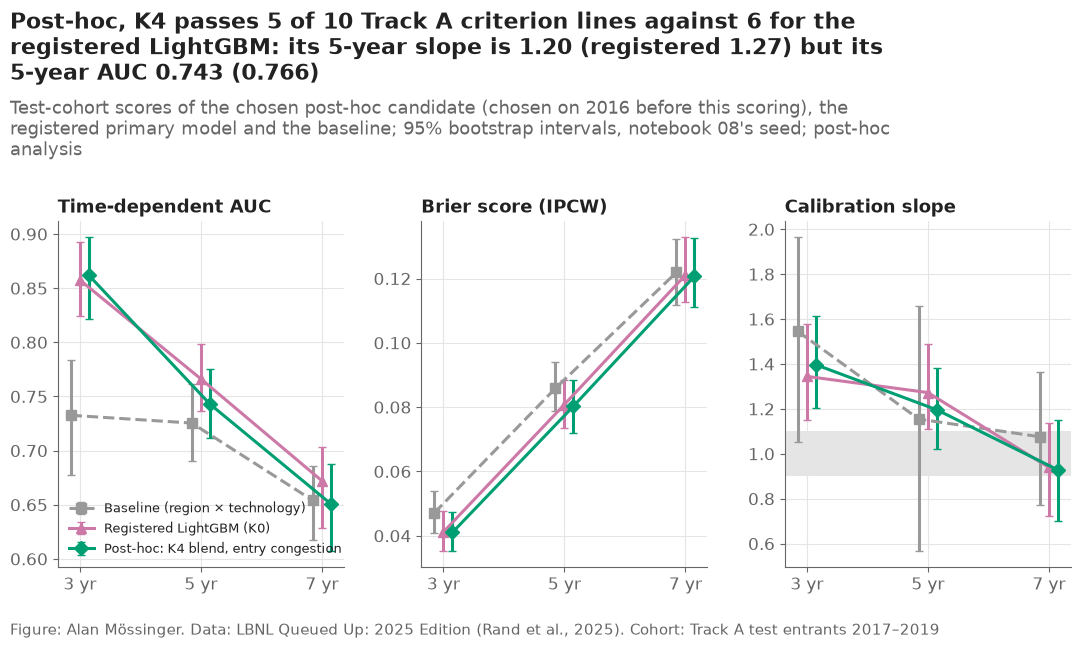

In [35]:
fig, axes = plt.subplots(1, 3, sharex=True)
styles = {"baseline": dict(BASE_STYLE, label="Baseline (region × technology)"),
          "dt_lgbm": dict(CAND_STYLE["K0"], label="Registered LightGBM (K0)"),
          "posthoc": dict(CAND_STYLE[CHOSEN], label=f"Post-hoc: {CAND_LABELS[CHOSEN]}")}
offs = {"baseline": -0.15, "dt_lgbm": 0, "posthoc": 0.15}
for ax, metric in zip(axes, ["auc", "brier", "slope"]):
    for model, style in styles.items():
        part = post[(post["model"] == model) & (post["metric"] == metric)]
        ax.errorbar(part["horizon"] + offs[model], part["estimate"],
                    yerr=[part["estimate"] - part["low"], part["high"] - part["estimate"]], capsize=3, **style)
    ax.set_xticks(HORIZONS, [f"{h} yr" for h in HORIZONS])
    ax.set_title({"auc": "Time-dependent AUC", "brier": "Brier score (IPCW)", "slope": "Calibration slope"}[metric], fontsize=13)
axes[2].axhspan(0.9, 1.1, color="#E5E5E5")
axes[0].legend(loc="lower left", fontsize=9)
slopes = {m: [value(post, m, "slope", h) for h in HORIZONS] for m in ["dt_lgbm", "posthoc"]}
plots.finish(fig,
             f"Post-hoc, {CHOSEN} passes {n_post} of 10 Track A criterion lines against {n_reg} for the registered "
             f"LightGBM: its 5-year slope is {slopes['posthoc'][1]:.2f} (registered {slopes['dt_lgbm'][1]:.2f}) but its "
             f"5-year AUC {value(post, 'posthoc', 'auc', 5):.3f} ({value(post, 'dt_lgbm', 'auc', 5):.3f})",
             "Test-cohort scores of the chosen post-hoc candidate (chosen on 2016 before this scoring), the registered "
             "primary model and the baseline; 95% bootstrap intervals, notebook 08's seed; post-hoc analysis",
             "Track A test entrants 2017–2019")
save(fig, "08b_02_chosen_on_test", "Post-hoc: test-cohort AUC, Brier score and calibration slope of the chosen candidate, the registered LightGBM and the baseline.")
plt.show()

**Reading this.** Scored once on the test cohort, K4 passes 5 of the 10 Track A criterion lines, against 6 for the registered LightGBM; the registered model's verdicts reproduce notebook 08 exactly. K4 keeps C1 and C2 at 3 years (Uno 0.857, Brier 0.0410) and C2 at 5 years (0.0803), but loses C1 at 5 years (Uno 0.738, interval against the baseline no longer above zero), and still fails C1 and C2 at 7 years and C3 at 3 and 5 years (slopes 1.40 and 1.20); C3 at 7 years (0.93) and C4 (lift 3.96) pass as before. So the post-hoc repair does not improve the pre-registered picture: it trades a little ranking (5-year AUC 0.743 vs 0.766) for a slightly better 5-year slope. The registered result of notebook 08 stands as the project's main result.

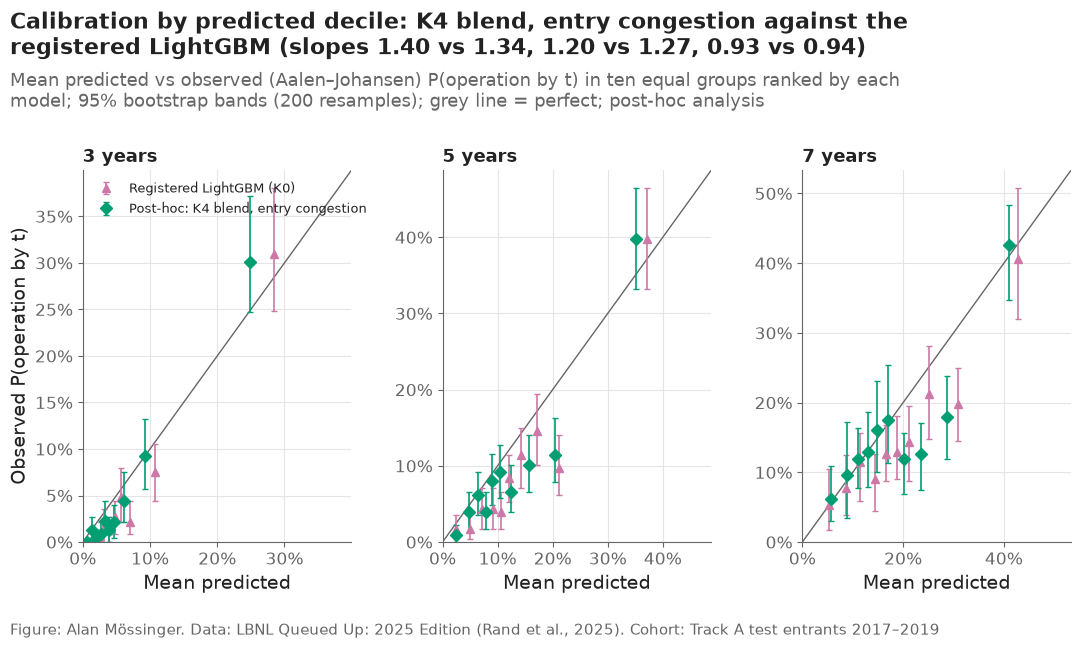

In [36]:
fig, axes = plt.subplots(1, 3)
cal_rows = []
for ax, h in zip(axes, HORIZONS):
    top = 0
    for model in ["dt_lgbm", "posthoc"]:
        p = predsT[h][model]
        groups = evaluation.decile_groups(p)
        for g in range(10):
            idx = groups == g
            obs = survival_tools.aalen_johansen(durT[idx], evT[idx], [h])["cif_operation"].iloc[0]
            band = survival_tools.bootstrap_bands(durT[idx], evT[idx], [h], n_boot=N_BOOT, seed=850 + g)
            cal_rows.append({"horizon": h, "model": model, "decile": g + 1, "predicted": p[idx].mean(), "observed": obs,
                             "low": band["cif_operation_low"].iloc[0], "high": band["cif_operation_high"].iloc[0]})
    part_h = pd.DataFrame([r for r in cal_rows if r["horizon"] == h])
    top = max(part_h["high"].max(), part_h["predicted"].max()) * 1.05
    ax.plot([0, top], [0, top], color=plots.MUTED, linewidth=1)
    for model in ["dt_lgbm", "posthoc"]:
        part = part_h[part_h["model"] == model]
        style = styles[model]
        ax.errorbar(part["predicted"], part["observed"], yerr=[part["observed"] - part["low"], part["high"] - part["observed"]],
                    fmt=style["marker"], color=style["color"], capsize=2, markersize=6, linewidth=1.2, label=style["label"])
    ax.set_xlim(0, top)
    ax.set_ylim(0, top)
    ax.set_title(f"{h} years", fontsize=13)
    ax.set_xlabel("Mean predicted")
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Observed P(operation by t)")
axes[0].legend(loc="upper left", fontsize=9)
plots.finish(fig,
             f"Calibration by predicted decile: {CAND_LABELS[CHOSEN]} against the registered LightGBM (slopes "
             + ", ".join(f"{a:.2f} vs {b:.2f}" for a, b in zip(slopes["posthoc"], slopes["dt_lgbm"])) + ")",
             "Mean predicted vs observed (Aalen–Johansen) P(operation by t) in ten equal groups ranked by each model; 95% "
             "bootstrap bands (200 resamples); grey line = perfect; post-hoc analysis",
             "Track A test entrants 2017–2019")
save(fig, "08b_03_calibration_deciles", "Post-hoc: calibration by predicted decile of the chosen candidate and the registered LightGBM.")
plt.show()

**Reading this.** By predicted decile K4 sits a little closer to the diagonal at 5 years (slope 1.20 vs 1.27) and a little further at 3 years (1.40 vs 1.34); at 7 years both are near 1 (0.93 vs 0.94). Neither model's middle deciles reach the line at 3 and 5 years: the test requests in those groups completed less often than either model predicted.

cells (region or entry year × horizon) inside the observed band: {'baseline': 7, 'dt_lgbm': 7, 'posthoc': 12} of 18


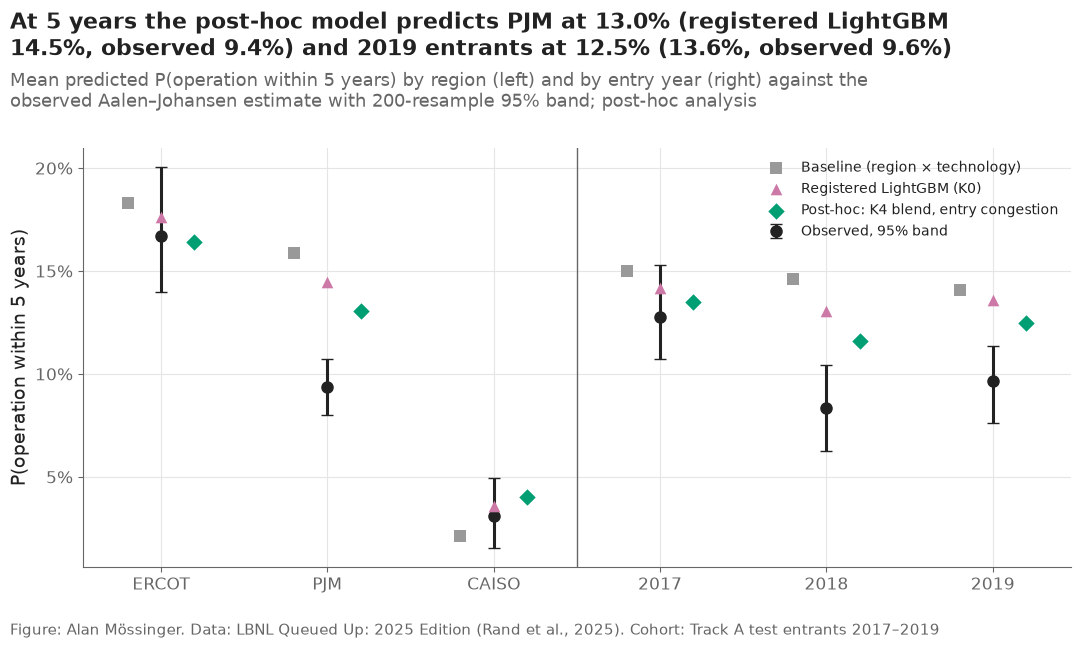

,group,horizon,observed,low,high,baseline,dt_lgbm,posthoc
0,ERCOT,3,0.054,0.038,0.075,0.090,0.080,0.071
1,ERCOT,5,0.167,0.140,0.200,0.183,0.176,0.164
2,ERCOT,7,0.215,0.179,0.258,0.230,0.250,0.234
3,PJM,3,0.059,0.047,0.071,0.100,0.077,0.065
4,PJM,5,0.094,0.080,0.107,0.159,0.145,0.130
5,PJM,7,0.167,0.143,0.194,0.203,0.204,0.189
6,CAISO,3,0.015,0.003,0.031,0.008,0.012,0.012
7,CAISO,5,0.031,0.015,0.049,0.021,0.036,0.040
8,CAISO,7,0.046,0.023,0.070,0.053,0.073,0.086
9,2017,3,0.053,0.035,0.071,0.087,0.073,0.063


In [37]:
regions = test["region"].astype(str).to_numpy()
reg_rows = []
for i, region in enumerate(config.TRACK_A_REGIONS):
    m = regions == region
    obs = survival_tools.aalen_johansen(durT[m], evT[m], HORIZONS)
    band = survival_tools.bootstrap_bands(durT[m], evT[m], HORIZONS, n_boot=N_BOOT, seed=820 + i)
    for j, h in enumerate(HORIZONS):
        reg_rows.append({"group": region, "horizon": h, "observed": obs["cif_operation"].iloc[j],
                         "low": band["cif_operation_low"].iloc[j], "high": band["cif_operation_high"].iloc[j],
                         **{model: predsT[h][model][m].mean() for model in ["baseline", "dt_lgbm", "posthoc"]}})
for y_i, year in enumerate([2017, 2018, 2019]):
    m = test["q_year"].to_numpy() == year
    obs = survival_tools.aalen_johansen(durT[m], evT[m], HORIZONS)
    band = survival_tools.bootstrap_bands(durT[m], evT[m], HORIZONS, n_boot=N_BOOT, seed=830 + y_i)
    for j, h in enumerate(HORIZONS):
        reg_rows.append({"group": str(year), "horizon": h, "observed": obs["cif_operation"].iloc[j],
                         "low": band["cif_operation_low"].iloc[j], "high": band["cif_operation_high"].iloc[j],
                         **{model: predsT[h][model][m].mean() for model in ["baseline", "dt_lgbm", "posthoc"]}})
levels = pd.DataFrame(reg_rows)
lv5 = levels[levels["horizon"] == 5].set_index("group")
fig, ax = plt.subplots()
groups = list(lv5.index)
x = np.arange(len(groups))
ax.errorbar(x, lv5["observed"], yerr=[lv5["observed"] - lv5["low"], lv5["high"] - lv5["observed"]], fmt="o", color=plots.INK,
            capsize=4, markersize=8, label="Observed, 95% band")
for model, dx in [("baseline", -0.2), ("dt_lgbm", 0), ("posthoc", 0.2)]:
    ax.scatter(x + dx, lv5[model], marker=styles[model]["marker"], color=styles[model]["color"], s=70, zorder=3,
               label=styles[model]["label"])
ax.axvline(2.5, color=plots.MUTED, linewidth=1)
ax.set_xticks(x, [f"{g}" for g in groups])
ax.set_ylabel("P(operation within 5 years)")
ax.yaxis.set_major_locator(plt.MultipleLocator(0.05))
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.legend(loc="upper right", fontsize=10)
inside = {m: int(((levels[m] >= levels["low"]) & (levels[m] <= levels["high"])).sum()) for m in ["baseline", "dt_lgbm", "posthoc"]}
print("cells (region or entry year × horizon) inside the observed band:", inside, "of", len(levels))
plots.finish(fig,
             f"At 5 years the post-hoc model predicts PJM at {lv5.loc['PJM', 'posthoc']:.1%} (registered LightGBM "
             f"{lv5.loc['PJM', 'dt_lgbm']:.1%}, observed {lv5.loc['PJM', 'observed']:.1%}) and 2019 entrants at "
             f"{lv5.loc['2019', 'posthoc']:.1%} ({lv5.loc['2019', 'dt_lgbm']:.1%}, observed {lv5.loc['2019', 'observed']:.1%})",
             "Mean predicted P(operation within 5 years) by region (left) and by entry year (right) against the observed "
             "Aalen–Johansen estimate with 200-resample 95% band; post-hoc analysis",
             "Track A test entrants 2017–2019")
save(fig, "08b_04_levels_by_group", "Post-hoc: mean predicted versus observed 5-year completion by region and entry year.")
plt.show()
levels.round(3)

**Reading this.** Where K4 does help is the average level. Its regional and entry-year averages are inside the observed 95% band in 12 of 18 cells, against 7 for the registered LightGBM and 7 for the baseline. At 5 years it predicts ERCOT at 16.4% (observed 16.7%), PJM at 13.0% (registered 14.5%, observed 9.4%, band 8.0–10.7%), and 2018 and 2019 entrants at 11.6% and 12.5% (registered 13.1% and 13.6%; observed 8.3% and 9.6%). PJM and the 2018–2019 entrants are still over-predicted — the slowdown after 2017 remains unrepaired, as the protocol expected — and CAISO at 7 years gets worse (8.6% vs 7.3%, observed 4.6%).

### Requests of 20 MW and more

Notebook 08 found that the registered model's advantage disappears when
requests under 20 MW are left out. The same question for the chosen
candidate, by scoring the test requests of 20 MW and more (no refit).

In [38]:
big = ~test["size_regime"].astype(str).isin(["<5", "5–<20"]).to_numpy()
G_big = evaluation.censoring_km(follow_up(test)[big], np.ones(big.sum(), dtype=bool))
big_preds = {h: {k: v[big] for k, v in predsT[h].items()} for h in HORIZONS}
big_table = score_table(big_preds, durT[big], evT[big], G_big, PROTOCOL["test_bootstrap_seed"], reference="baseline")
big_table.to_csv(paths.RESULTS / "posthoc_size_subset.csv", index=False)
print(f"test requests of 20 MW or more: {big.sum():,}")
bt = big_table[big_table["metric"].isin(["uno_c", "brier"]) & big_table["diff"].notna()].copy()
bt["vs baseline"] = [f"{r.diff:+.4f} [{r.diff_low:+.4f}, {r.diff_high:+.4f}]" for r in bt.itertuples()]
bt.pivot_table(index=["metric", "horizon"], columns="model", values="vs baseline", aggfunc="first")

test requests of 20 MW or more: 1,839


model                              dt_lgbm                     posthoc
metric horizon                                                        
brier  3        -0.0031 [-0.0045, -0.0018]  -0.0037 [-0.0050, -0.0024]
       5        -0.0037 [-0.0059, -0.0014]  -0.0043 [-0.0066, -0.0016]
       7        +0.0004 [-0.0032, +0.0035]  +0.0001 [-0.0036, +0.0039]
uno_c  3        +0.0790 [+0.0112, +0.1607]  +0.0702 [-0.0085, +0.1542]
       5        -0.0205 [-0.0532, +0.0159]  -0.0624 [-0.1092, -0.0128]
       7        +0.0103 [-0.0268, +0.0548]  -0.0231 [-0.0725, +0.0149]

**Reading this.** On the 1,839 test requests of 20 MW or more (scored without refitting), both models still have a slightly lower Brier score than the baseline at 3 and 5 years (registered −0.0031 [−0.0045, −0.0018] and −0.0037 [−0.0059, −0.0014]; K4 −0.0037 and −0.0043), but ranking adds little: the registered model's concordance gain is +0.079 [+0.011, +0.161] at 3 years and nil at 5 and 7 years, and K4 ranks these requests worse than the baseline at 5 years (−0.062 [−0.109, −0.013]). Together with notebook 08's refit without small requests (0 of 6 comparisons won), the conclusion holds: for utility-scale requests the models add little beyond region and technology.

## 5. All five candidates on the test cohort — not used for the choice

For transparency every candidate is scored on the test cohort. The choice
was fixed by section 2 (and written to `results/posthoc_choice.json`) before
this cell runs; a candidate that happens to score better here was not
chosen and must not be read as the answer.

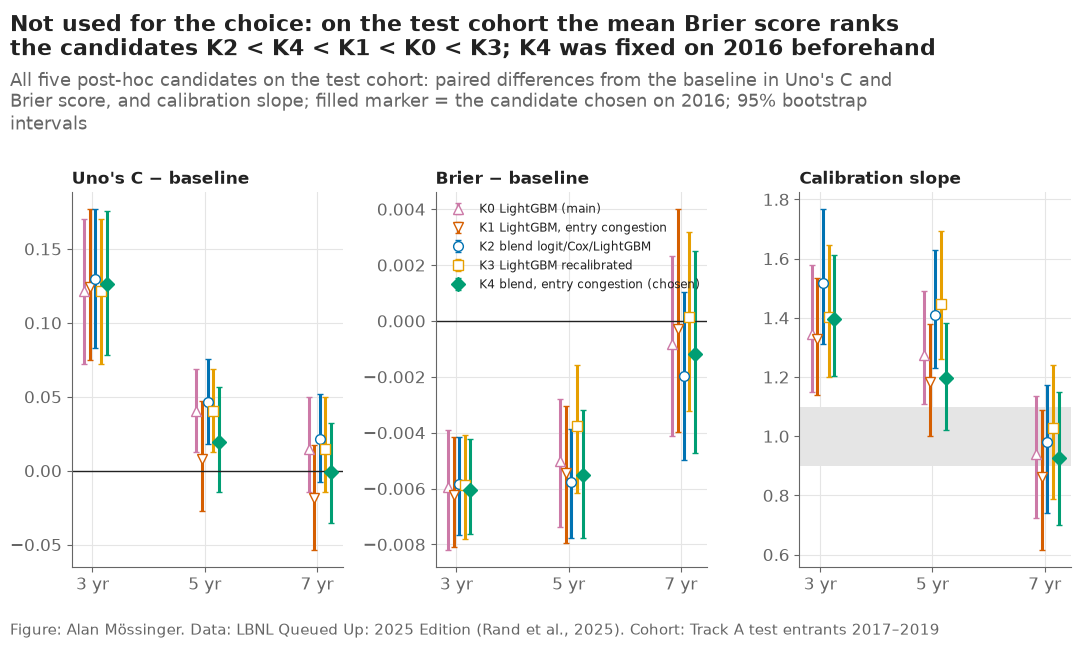

model          baseline      K0      K1      K2      K3      K4
metric horizon                                                 
brier  3         0.0471  0.0411  0.0409  0.0412  0.0412  0.0410
       5         0.0858  0.0808  0.0804  0.0800  0.0820  0.0803
       7         0.1219  0.1211  0.1216  0.1199  0.1220  0.1207
slope  3         1.5456  1.3448  1.3301  1.5177  1.4021  1.3967
       5         1.1547  1.2728  1.1832  1.4106  1.4481  1.1959
       7         1.0759  0.9395  0.8623  0.9816  1.0271  0.9279
uno_c  3         0.7311  0.8525  0.8552  0.8607  0.8525  0.8573
       5         0.7191  0.7597  0.7269  0.7653  0.7597  0.7385
       7         0.6574  0.6722  0.6390  0.6788  0.6722  0.6567

In [39]:
allT = {h: {"baseline": stored[h]["baseline"].to_numpy(), **candT[h]} for h in HORIZONS}
all_test = score_table(allT, durT, evT, GT, PROTOCOL["test_bootstrap_seed"], reference="baseline")
all_test.insert(0, "note", "not used for the choice")
all_test.to_csv(paths.RESULTS / "posthoc_all_candidates_test.csv", index=False)
fig, axes = plt.subplots(1, 3, sharex=True)
for ax, metric in zip(axes, ["uno_c", "brier", "slope"]):
    for model in CANDIDATES:
        part = all_test[(all_test["model"] == model) & (all_test["metric"] == metric)]
        if metric == "slope":
            est, low, high = part["estimate"], part["low"], part["high"]
        else:
            est, low, high = part["diff"], part["diff_low"], part["diff_high"]
        face = CAND_STYLE[model]["color"] if model == CHOSEN else "white"
        ax.errorbar(part["horizon"] + OFFSETS[model], est, yerr=[est - low, high - est], capsize=2, linestyle="none",
                    markerfacecolor=face, label=CAND_LABELS[model] + (" (chosen)" if model == CHOSEN else ""), **CAND_STYLE[model])
    if metric == "slope":
        ax.axhspan(0.9, 1.1, color="#E5E5E5")
    else:
        ax.axhline(0, color=plots.INK, linewidth=1)
    ax.set_xticks(HORIZONS, [f"{h} yr" for h in HORIZONS])
    ax.set_title({"uno_c": "Uno's C − baseline", "brier": "Brier − baseline", "slope": "Calibration slope"}[metric], fontsize=12)
axes[1].legend(loc="upper left", fontsize=8.5)
ranks = all_test[all_test["metric"] == "brier"].groupby("model")["estimate"].mean().loc[CANDIDATES]
plots.finish(fig,
             f"Not used for the choice: on the test cohort the mean Brier score ranks the candidates "
             + " < ".join(ranks.sort_values().index) + f"; {CHOSEN} was fixed on 2016 beforehand",
             "All five post-hoc candidates on the test cohort: paired differences from the baseline in Uno's C and Brier "
             "score, and calibration slope; filled marker = the candidate chosen on 2016; 95% bootstrap intervals",
             "Track A test entrants 2017–2019")
save(fig, "08b_05_all_candidates_test", "Post-hoc, not used for the choice: all five candidates on the test cohort.")
plt.show()
at = all_test[all_test["metric"].isin(["uno_c", "brier", "slope"])].copy()
at["value"] = [f"{r.estimate:.4f}" for r in at.itertuples()]
at.pivot_table(index=["metric", "horizon"], columns="model", values="value", aggfunc="first")[["baseline"] + CANDIDATES]

**Reading this.** Not used for the choice, and shown only so nothing is hidden: on the test cohort K2 (the blend of the main logit, Cox and LightGBM) has the best concordance at every horizon (0.861, 0.765, 0.679) and the lowest Brier scores at 5 and 7 years (0.0800, 0.1199), but the worst calibration slopes at 3 and 5 years (1.52, 1.41). Picking K2 now, because it scores best on the test cohort, would be exactly the selection on the test set that the protocol rules out, and its gains over K0 are inside the intervals. K3, the recalibrated LightGBM, made calibration worse (slopes 1.40, 1.45, 1.03), because the 2016 cohort asked for the opposite correction from the one the test cohort needed. The honest summary is that all five candidates perform within noise of one another.

## 6. Does fitting on entry-time congestion remove the artefact?

Notebook 09 traced the positive congestion effect to fitting on yearly
congestion. The same partial dependence as figure 09_05 for the LightGBM
fitted with congestion held at entry (K1's component), on entrants to 2016.

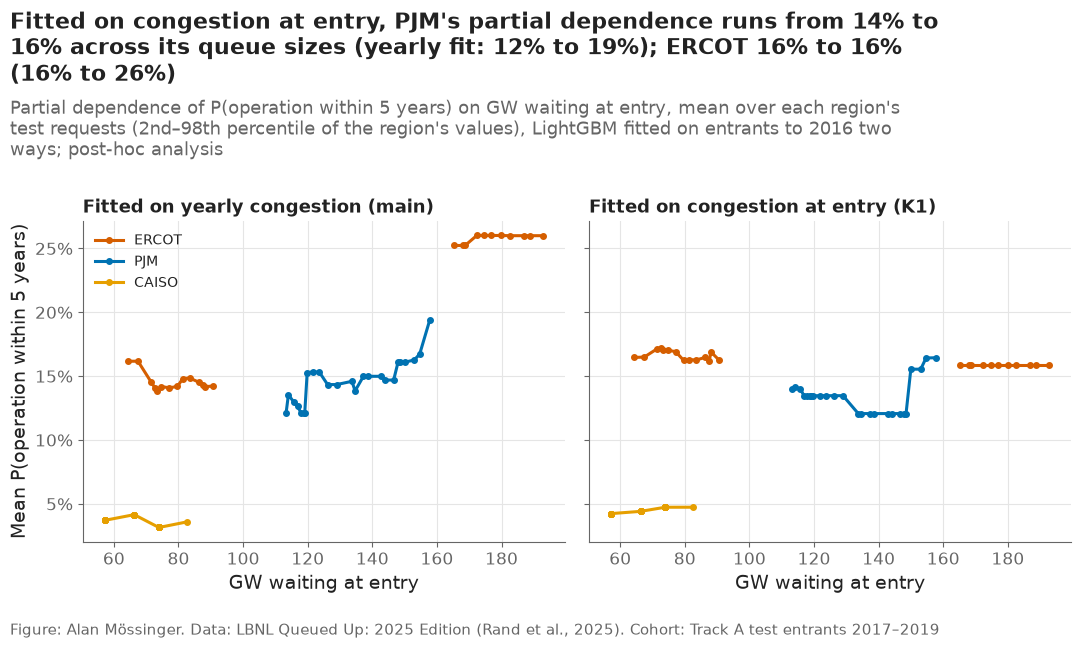

,yearly_low,yearly_high,entry_low,entry_high
region,,,,
CAISO,0.037,0.036,0.042,0.047
ERCOT,0.162,0.260,0.165,0.159
PJM,0.121,0.194,0.140,0.164


In [40]:
STATES = sorted(track_a["state"].astype(str).unique())
fit_main = discrete_time.fit_both(final, clean, tuning)
fit_entry = discrete_time.fit_both(final, clean, tuning, congestion="entry")
f_main, f_entry = (explain.incidence_function(f, STATES, 5) for f in (fit_main, fit_entry))
X_test = explain.encode(test, STATES).to_numpy()
col = explain.FEATURES.index("congestion_gw")
pd_rows = []
for region in config.TRACK_A_REGIONS:
    base = X_test[regions == region]
    for value_gw in np.quantile(test.loc[test["region"] == region, "congestion_gw"], np.linspace(0.02, 0.98, 25)):
        X2 = base.copy()
        X2[:, col] = value_gw
        pd_rows.append({"region": region, "gw": value_gw, "yearly": f_main(X2).mean(), "entry": f_entry(X2).mean()})
pdc = pd.DataFrame(pd_rows)
fig, axes = plt.subplots(1, 2, sharey=True)
for ax, version, title in [(axes[0], "yearly", "Fitted on yearly congestion (main)"), (axes[1], "entry", "Fitted on congestion at entry (K1)")]:
    for region in config.TRACK_A_REGIONS:
        part = pdc[pdc["region"] == region]
        jump = part["gw"].diff() > 20
        for k, (_, run) in enumerate(part.groupby(jump.cumsum())):
            ax.plot(run["gw"], run[version], color=plots.region_color(region), marker="o", markersize=4,
                    label=region if k == 0 else None)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("GW waiting at entry")
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Mean P(operation within 5 years)")
axes[0].legend(loc="upper left", fontsize=10)
ends = pdc.groupby("region").agg(yearly_low=("yearly", "first"), yearly_high=("yearly", "last"),
                                 entry_low=("entry", "first"), entry_high=("entry", "last"))
plots.finish(fig,
             f"Fitted on congestion at entry, PJM's partial dependence runs from {ends.loc['PJM', 'entry_low']:.0%} to "
             f"{ends.loc['PJM', 'entry_high']:.0%} across its queue sizes (yearly fit: {ends.loc['PJM', 'yearly_low']:.0%} to "
             f"{ends.loc['PJM', 'yearly_high']:.0%}); ERCOT {ends.loc['ERCOT', 'entry_low']:.0%} to {ends.loc['ERCOT', 'entry_high']:.0%} "
             f"({ends.loc['ERCOT', 'yearly_low']:.0%} to {ends.loc['ERCOT', 'yearly_high']:.0%})",
             "Partial dependence of P(operation within 5 years) on GW waiting at entry, mean over each region's test requests "
             "(2nd–98th percentile of the region's values), LightGBM fitted on entrants to 2016 two ways; post-hoc analysis",
             "Track A test entrants 2017–2019")
save(fig, "08b_06_congestion_entry_fit", "Post-hoc: partial dependence on GW waiting at entry for LightGBM fitted on yearly and on entry-time congestion.")
plt.show()
ends.round(3)

**Reading this.** Fitted on congestion held at entry, LightGBM's congestion effect is no longer the steep rise of the main fit: in ERCOT the 5-year chance stays flat across queue sizes (16.5% to 15.9%, against 16.2% to 26.0% for the yearly fit), and in PJM the rise shrinks (14.0% to 16.4%, against 12.1% to 19.4%). This supports notebook 09's diagnosis that the positive effect came mostly from fitting on yearly congestion. It does not turn the effect negative as the descriptive pattern (F8) would suggest; the remaining PJM slope may still reflect calendar time, since every PJM test request entered above the training range of 118 GW.

## 7. Other learners on the same rows, judged by a rule written first (criteria C18–C19)

The question an energy company asks of this notebook is not "which learner scores best" but "would a different learner change any decision". Two decisions depend on the entry-time model: whether the milestone book of notebooks 14, 16 and 20 should be driven by a different model, and whether a model, rather than the region × technology × size lookup, should score requests at entry. So three learners the project has not tried are fitted on exactly the rows, split and censoring weights of notebooks 05–08, selected on the 2016 cohort as section 0 prescribes, and scored once on 2017–2019 against two registered criteria, written to `results/success_criteria_v5_registered.json` and committed before any of them was fitted (decision #59):

- **T1, a cause-specific random survival forest pair** on the Cox design: one forest for operation, one for withdrawal, combined into an incidence curve exactly as the Cox pair is. A forest cannot take left-truncated rows, so the 732 ERCOT entrants that join the Cox fit with a delayed entry are left out of its fit; the one tuned setting is the minimum leaf size.
- **T2, a neural discrete-time hazard**: a two-layer network with a three-class softmax on notebook 06's person-period rows and logit design without the hand-made early-years interactions, which a network can form itself; the one tuned setting is the L2 penalty.
- **T3, a blend** of the main logit, Cox, LightGBM, T1 and T2 with weights on a 0.1 grid, as K2 was built.

**C18** (the milestone book changes model): the chosen learner beats the registered LightGBM in Uno's C at 3 and 5 years on requests of 20 MW and more, paired interval above zero, with a Brier score that is not worse (paired interval not entirely above zero). **C19** (a model scores at entry): the same four lines against the fair lookup of notebook 11. Each criterion passes only if all four of its lines pass. If C18 fails, notebooks 14, 16 and 20 keep the registered LightGBM; if C19 fails, the entry gate of notebook 16 keeps the lookup. A registered negative is a finding: it says the cheaper model stays.

In [41]:
TOURNAMENT = {
    "decided": "2026-10-12",
    "decision": 59,
    "candidates": {
        "T1": "cause-specific random survival forest pair on the Cox design (300 trees, max_features sqrt, seed 59); "
              "left-truncated ERCOT rows (entry_years > 0) excluded from its fit; min_samples_leaf chosen on 2016 from [20, 50, 100]",
        "T2": "MLP discrete-time hazard (hidden layers 64 and 32, softmax over stay/operate/withdraw, early stopping on 10% of rows, seed 59) "
              "on notebook 06's person-period rows and logit design without interactions; alpha chosen on 2016 from [1e-4, 1e-3, 1e-2]",
        "T3": "blend of main logit, Cox, main LightGBM, T1 and T2, weights on a 0.1 simplex grid per horizon, fitted on 2016 predictions",
    },
    "fits": "every component fitted on entrants to 2015 for the 2016 choice and on entrants to 2016 for the test; nothing else tuned",
    "selection": "within T1 and T2 the setting with the lowest mean IPCW Brier over 3, 5, 7 years on the 2016 cohort; T3's 2016 score "
                 "cross-fitted on two halves (seed 34); the chosen learner T* is the candidate with the lowest 2016 mean Brier",
    "test": "T* refitted on entrants to 2016 and scored once on the 2017–2019 test cohort, all sizes and 20 MW and more, "
            "with notebook 08's metrics, censoring weights and bootstrap (200 resamples, seed 800)",
    "references": {"dt_lgbm": "the registered LightGBM (notebook 08)", "fair_baseline": "notebook 11's region × technology × size lookup"},
    "consequence": "C18 passes → notebooks 14, 16 and 20 switch to T*; C19 passes → the entry gate of notebook 16 scores with T*; "
                   "otherwise the registered LightGBM and the lookup stay",
    "rejected": "choosing T* on the test cohort; more than one tuned setting per learner; changing a line after a test score is seen",
}
lines = []
for cid, ref in [("C18", "dt_lgbm"), ("C19", "fair_baseline")]:
    for h in [3, 5]:
        lines.append({"id": cid, "line": f"≥ 20 MW, {h} years: Uno's C, T* vs {ref}", "metric": "uno_c", "horizon": h,
                      "reference": ref, "rule": "paired 95% interval of T* − reference entirely above 0"})
        lines.append({"id": cid, "line": f"≥ 20 MW, {h} years: Brier score, T* vs {ref}", "metric": "brier", "horizon": h,
                      "reference": ref, "rule": "paired 95% interval of T* − reference not entirely above 0 (not worse)"})
TOURNAMENT["criteria"] = lines
criteria_v5 = pd.DataFrame(lines)
reg_path = paths.RESULTS / "success_criteria_v5_registered.json"
text = json.dumps(TOURNAMENT, indent=2, ensure_ascii=False)
if reg_path.exists():
    assert reg_path.read_text(encoding="utf-8") == text, "the registration differs from the committed file — a registered rule was changed"
else:
    reg_path.write_text(text, encoding="utf-8")
criteria_v5.to_csv(paths.RESULTS / "success_criteria_v5.csv", index=False)
(paths.RESULTS / "tournament_protocol.json").write_text(text, encoding="utf-8")
print(f"{len(criteria_v5)} registered lines (C18, C19); registration file SHA-256 {hashlib.sha256(reg_path.read_bytes()).hexdigest()[:16]}…")
criteria_v5[["id", "line", "rule"]]

8 registered lines (C18, C19); registration file SHA-256 a841594496ff51f4…


,id,line,rule
0,C18,"≥ 20 MW, 3 years: Uno's C, T* vs dt_lgbm",paired 95% interval of T* − reference entirely...
1,C18,"≥ 20 MW, 3 years: Brier score, T* vs dt_lgbm",paired 95% interval of T* − reference not enti...
2,C18,"≥ 20 MW, 5 years: Uno's C, T* vs dt_lgbm",paired 95% interval of T* − reference entirely...
3,C18,"≥ 20 MW, 5 years: Brier score, T* vs dt_lgbm",paired 95% interval of T* − reference not enti...
4,C19,"≥ 20 MW, 3 years: Uno's C, T* vs fair_baseline",paired 95% interval of T* − reference entirely...
5,C19,"≥ 20 MW, 3 years: Brier score, T* vs fair_base...",paired 95% interval of T* − reference not enti...
6,C19,"≥ 20 MW, 5 years: Uno's C, T* vs fair_baseline",paired 95% interval of T* − reference entirely...
7,C19,"≥ 20 MW, 5 years: Brier score, T* vs fair_base...",paired 95% interval of T* − reference not enti...


### 7.1 The candidates on the 2016 cohort

Fitted on entrants to 2015 and scored on the 573 entrants of 2016 next to K0, the registered LightGBM. The grids are small on purpose: one setting per learner, so that a win on 2016 is a property of the learner and not of a search.

In [42]:
T_SEED = 59
T_STYLE = {"T1": dict(color="#D55E00", marker="v"), "T2": dict(color="#009E73", marker="D"), "T3": dict(color="#0072B2", marker="o")}
T_LABELS = {"T1": "T1 random survival forest pair", "T2": "T2 neural discrete-time hazard", "T3": "T3 blend of five"}
y16 = {h: evaluation.horizon_outcome(d16, e16, h, G16) for h in HORIZONS}


def mean_brier_on_2016(pred_by_h):
    return float(np.mean([evaluation.brier(pred_by_h[h], *y16[h]) for h in HORIZONS]))


grid_rows, t1_16, t2_16 = [], {}, {}
for leaf in [20, 50, 100]:
    fitted = survival_tools.fit_rsf_pair(tune, min_samples_leaf=leaf, seed=T_SEED)
    cif = survival_tools.rsf_cif(fitted, valid, HORIZONS)
    t1_16[leaf] = {h: cif[h].to_numpy() for h in HORIZONS}
    grid_rows.append({"candidate": "T1", "setting": f"min_samples_leaf={leaf}", "mean_brier_2016": mean_brier_on_2016(t1_16[leaf])})
for alpha in [1e-4, 1e-3, 1e-2]:
    fitted = discrete_time.fit_mlp_hazard(tune, clean, alpha=alpha, seed=T_SEED)
    cif = discrete_time.predict_mlp(fitted, valid, HORIZONS)
    t2_16[alpha] = {h: cif[h].to_numpy() for h in HORIZONS}
    grid_rows.append({"candidate": "T2", "setting": f"alpha={alpha:g}", "mean_brier_2016": mean_brier_on_2016(t2_16[alpha])})
grid = pd.DataFrame(grid_rows)
T1_LEAF = int(grid[grid["candidate"] == "T1"].sort_values("mean_brier_2016")["setting"].iloc[0].split("=")[1])
T2_ALPHA = float(grid[grid["candidate"] == "T2"].sort_values("mean_brier_2016")["setting"].iloc[0].split("=")[1])
comp16["T1"], comp16["T2"] = t1_16[T1_LEAF], t2_16[T2_ALPHA]


def five_matrix(comp, h):
    '''Columns logit, Cox, LightGBM, T1, T2 for one horizon.'''
    return np.column_stack([comp["logit_main"][h], comp["cox"][h], comp["lgbm_main"][h], comp["T1"][h], comp["T2"][h]])


tour16 = {h: {"K0": comp16["lgbm_main"][h], "T1": comp16["T1"][h], "T2": comp16["T2"][h]} for h in HORIZONS}
for h in HORIZONS:
    y, w = y16[h]
    P = five_matrix(comp16, h)
    tour16[h]["T3"] = posthoc.cross_fit(lambda idx, P=P, y=y, w=w: posthoc.fit_blend(P[idx], y[idx], w[idx], PROTOCOL["blend_step"]),
                                        lambda g, idx, P=P: P[idx] @ g, n16, PROTOCOL["cross_fit_folds"], PROTOCOL["cross_fit_seed"])
tval16 = score_table(tour16, d16, e16, G16, PROTOCOL["selection_bootstrap_seed"], reference="K0")
tval16.to_csv(paths.RESULTS / "tournament_validation_2016.csv", index=False)
t_brier = tval16[tval16["metric"] == "brier"].groupby("model")["estimate"].mean()
T_STAR = t_brier.loc[["T1", "T2", "T3"]].idxmin()
t_choice = {"chosen": T_STAR, "label": T_LABELS[T_STAR], "T1_min_samples_leaf": T1_LEAF, "T2_alpha": T2_ALPHA,
            "mean_brier_2016": t_brier.round(6).to_dict(), "rule": TOURNAMENT["selection"]}
(paths.RESULTS / "tournament_choice.json").write_text(json.dumps(t_choice, indent=2), encoding="utf-8")
T_CHOICE_TIME = time.time()
grid.to_csv(paths.RESULTS / "tournament_grid_2016.csv", index=False)
print(grid.round(5).to_string(index=False))
print(f"settings kept: T1 min_samples_leaf={T1_LEAF}, T2 alpha={T2_ALPHA:g}")
print(f"mean 2016 Brier (3/5/7 yr): {t_brier.round(5).to_dict()} → T* = {T_STAR} ({T_LABELS[T_STAR]})")
show = tval16[tval16["metric"].isin(["brier", "uno_c", "slope"])].copy()
show["value"] = [f"{r.estimate:.4f} [{r.low:.4f}, {r.high:.4f}]" for r in show.itertuples()]
show.pivot_table(index=["metric", "horizon"], columns="model", values="value", aggfunc="first")[["K0", "T1", "T2", "T3"]]

candidate              setting  mean_brier_2016
       T1  min_samples_leaf=20          0.10336
       T1  min_samples_leaf=50          0.10348
       T1 min_samples_leaf=100          0.10365
       T2         alpha=0.0001          0.10420
       T2          alpha=0.001          0.10628
       T2           alpha=0.01          0.10238
settings kept: T1 min_samples_leaf=20, T2 alpha=0.01
mean 2016 Brier (3/5/7 yr): {'K0': 0.0996, 'T1': 0.10336, 'T2': 0.10238, 'T3': 0.09953} → T* = T3 (T3 blend of five)


model                                K0                       T1                       T2                       T3
metric horizon                                                                                                    
brier  3        0.0553 [0.0429, 0.0738]  0.0570 [0.0433, 0.0753]  0.0584 [0.0455, 0.0764]  0.0565 [0.0437, 0.0751]
       5        0.1067 [0.0908, 0.1257]  0.1099 [0.0925, 0.1283]  0.1085 [0.0914, 0.1285]  0.1059 [0.0893, 0.1244]
       7        0.1368 [0.1159, 0.1588]  0.1432 [0.1241, 0.1647]  0.1402 [0.1212, 0.1602]  0.1362 [0.1156, 0.1561]
slope  3        0.9591 [0.7387, 1.1667]  1.0863 [0.7280, 1.5068]  0.7879 [0.5878, 1.0074]  1.0462 [0.7733, 1.3159]
       5        0.8789 [0.6656, 1.0859]  0.9191 [0.5792, 1.2464]  0.7172 [0.5354, 0.9098]  0.9848 [0.7390, 1.2212]
       7        0.9146 [0.6993, 1.1565]  0.7463 [0.3464, 1.1203]  0.7231 [0.5431, 0.9249]  1.0342 [0.8001, 1.2990]
uno_c  3        0.8166 [0.7605, 0.8616]  0.7708 [0.7002, 0.8263]  0.7896 [0.7361, 0.8323]  0.7929 [0.7305, 0.8342]
       5        0.7322 [0.6778, 0.7765]  0.6706 [0.6079, 0.7236]  0.7277 [0.6761, 0.7762]  0.7352 [0.6851, 0.7760]
       7        0.7091 [0.6693, 0.7565]  0.6296 [0.5722, 0.6742]  0.7130 [0.6702, 0.7616]  0.7125 [0.6724, 0.7560]

**Reading this.** On the 2016 cohort neither new learner beats the registered LightGBM on its own: mean Brier over 3, 5 and 7 years 0.1034 for the forest pair (best leaf size 20) and 0.1024 for the network (best penalty 0.01), against 0.0996 for K0. The blend T3 reaches 0.0995, a hair under K0, and is chosen as T* by the registered rule. Its weights say what it is: 0.7, 0.4 and 0.5 on LightGBM at 3, 5 and 7 years, the rest on the network (0.2–0.4) and the forest (0.1–0.2), nothing on the logit or Cox. So the alternative the test will judge is the registered model with a quarter to a half of its weight moved to two learners that score worse alone.

### 7.2 The chosen learner on the test cohort, scored once

T* is refitted on entrants to 2016 with the settings kept above; T3's weights come from the 2016 predictions of the fits to 2015, as K2's did. It is scored on the whole test cohort and on the 1,839 requests of 20 MW and more, against the registered LightGBM and against the fair lookup, with notebook 08's weights and seed. The four registered lines of each criterion are read off the ≥ 20 MW table. The other two candidates are scored too and written to a table marked "not used for the choice".

In [43]:
first_tournament_score = time.time()
fitted_t1 = survival_tools.fit_rsf_pair(final, min_samples_leaf=T1_LEAF, seed=T_SEED)
compT["T1"] = {h: survival_tools.rsf_cif(fitted_t1, test, HORIZONS)[h].to_numpy() for h in HORIZONS}
fitted_t2 = discrete_time.fit_mlp_hazard(final, clean, alpha=T2_ALPHA, seed=T_SEED)
compT["T2"] = {h: discrete_time.predict_mlp(fitted_t2, test, HORIZONS)[h].to_numpy() for h in HORIZONS}
t_weights = []
for h in HORIZONS:
    y, w = y16[h]
    g = posthoc.fit_blend(five_matrix(comp16, h), y, w, PROTOCOL["blend_step"])
    compT.setdefault("T3", {})[h] = five_matrix(compT, h) @ g
    t_weights.append({"horizon": h, "w_logit": g[0], "w_cox": g[1], "w_lgbm": g[2], "w_T1": g[3], "w_T2": g[4]})
pd.DataFrame(t_weights).to_csv(paths.RESULTS / "tournament_blend_weights.csv", index=False)

fair = pd.read_parquet(paths.DATA_PROCESSED / "predictions_v2.parquet")
fair_h = {h: fair[fair["horizon"] == h].set_index("project_key").loc[keys, "fair_baseline"].to_numpy() for h in HORIZONS}


def tournament_scores(mask, label):
    '''T* and the two references on the rows of ``mask``, paired to each reference in turn.'''
    G_m = evaluation.censoring_km(follow_up(test)[mask], np.ones(int(mask.sum()), dtype=bool))
    preds = {h: {"dt_lgbm": compT["lgbm_main"][h][mask], "fair_baseline": fair_h[h][mask], "T*": compT[T_STAR][h][mask]} for h in HORIZONS}
    parts = []
    for ref in ["dt_lgbm", "fair_baseline"]:
        part = score_table(preds, durT[mask], evT[mask], G_m, PROTOCOL["test_bootstrap_seed"], reference=ref)
        part.insert(0, "reference", ref)
        parts.append(part)
    out = pd.concat(parts, ignore_index=True)
    out.insert(0, "cohort", label)
    return out


all_mask = np.ones(len(test), dtype=bool)
tournament = pd.concat([tournament_scores(all_mask, "all sizes"), tournament_scores(big, "≥ 20 MW")], ignore_index=True)
tournament.insert(0, "T_star", T_STAR)
tournament.to_csv(paths.RESULTS / "tournament.csv", index=False)

crit_rows = []
for line in TOURNAMENT["criteria"]:
    row = tournament[(tournament["cohort"] == "≥ 20 MW") & (tournament["reference"] == line["reference"]) & (tournament["model"] == "T*")
                     & (tournament["metric"] == line["metric"]) & (tournament["horizon"] == line["horizon"])].iloc[0]
    passed = bool(row["diff_low"] > 0) if line["metric"] == "uno_c" else bool(row["diff_low"] <= 0)
    crit_rows.append({**line, "estimate": row["estimate"], "diff": row["diff"], "diff_low": row["diff_low"], "diff_high": row["diff_high"],
                      "result": "PASS" if passed else "FAIL"})
scored_v5 = pd.DataFrame(crit_rows)
scored_v5.to_csv(paths.RESULTS / "success_criteria_v5_scored.csv", index=False)
verdict_v5 = scored_v5.groupby("id")["result"].apply(lambda s: "PASS" if (s == "PASS").all() else "FAIL").to_dict()
pd.DataFrame([{"criterion": k, "lines_passed": int((scored_v5.loc[scored_v5["id"] == k, "result"] == "PASS").sum()),
               "lines": int((scored_v5["id"] == k).sum()), "verdict": v} for k, v in verdict_v5.items()]).to_csv(
    paths.RESULTS / "tournament_criteria.csv", index=False)

others = {h: {"dt_lgbm": compT["lgbm_main"][h], **{t: compT[t][h] for t in ["T1", "T2", "T3"]}} for h in HORIZONS}
all_t = score_table(others, durT, evT, GT, PROTOCOL["test_bootstrap_seed"], reference="dt_lgbm")
all_t.insert(0, "note", "not used for the choice")
all_t.to_csv(paths.RESULTS / "tournament_all_candidates_test.csv", index=False)

pred_rows = []
for h in HORIZONS:
    pred_rows.append(pd.DataFrame({"project_key": keys.to_numpy(), "horizon": h, "T_star": T_STAR, "p_operation": compT[T_STAR][h],
                                   "dt_lgbm": compT["lgbm_main"][h], "fair_baseline": fair_h[h]}))
pd.concat(pred_rows, ignore_index=True).to_parquet(paths.DATA_PROCESSED / "predictions_tournament.parquet", index=False)
print(f"T* = {T_STAR}; verdicts: {verdict_v5}")
print(scored_v5[["id", "line", "estimate", "diff", "diff_low", "diff_high", "result"]].round(4).to_string(index=False))

T* = T3; verdicts: {'C18': 'FAIL', 'C19': 'FAIL'}
 id                                               line  estimate    diff  diff_low  diff_high result
C18           ≥ 20 MW, 3 years: Uno's C, T* vs dt_lgbm    0.7940  0.0150    0.0024     0.0284   PASS
C18       ≥ 20 MW, 3 years: Brier score, T* vs dt_lgbm    0.0217 -0.0005   -0.0008    -0.0001   PASS
C18           ≥ 20 MW, 5 years: Uno's C, T* vs dt_lgbm    0.7268 -0.0071   -0.0203     0.0052   FAIL
C18       ≥ 20 MW, 5 years: Brier score, T* vs dt_lgbm    0.0640 -0.0005   -0.0017     0.0008   PASS
C19     ≥ 20 MW, 3 years: Uno's C, T* vs fair_baseline    0.7940  0.0109   -0.0316     0.0597   FAIL
C19 ≥ 20 MW, 3 years: Brier score, T* vs fair_baseline    0.0217 -0.0017   -0.0033     0.0000   PASS
C19     ≥ 20 MW, 5 years: Uno's C, T* vs fair_baseline    0.7268 -0.0248   -0.0547     0.0047   FAIL
C19 ≥ 20 MW, 5 years: Brier score, T* vs fair_baseline    0.0640 -0.0005   -0.0025     0.0016   PASS


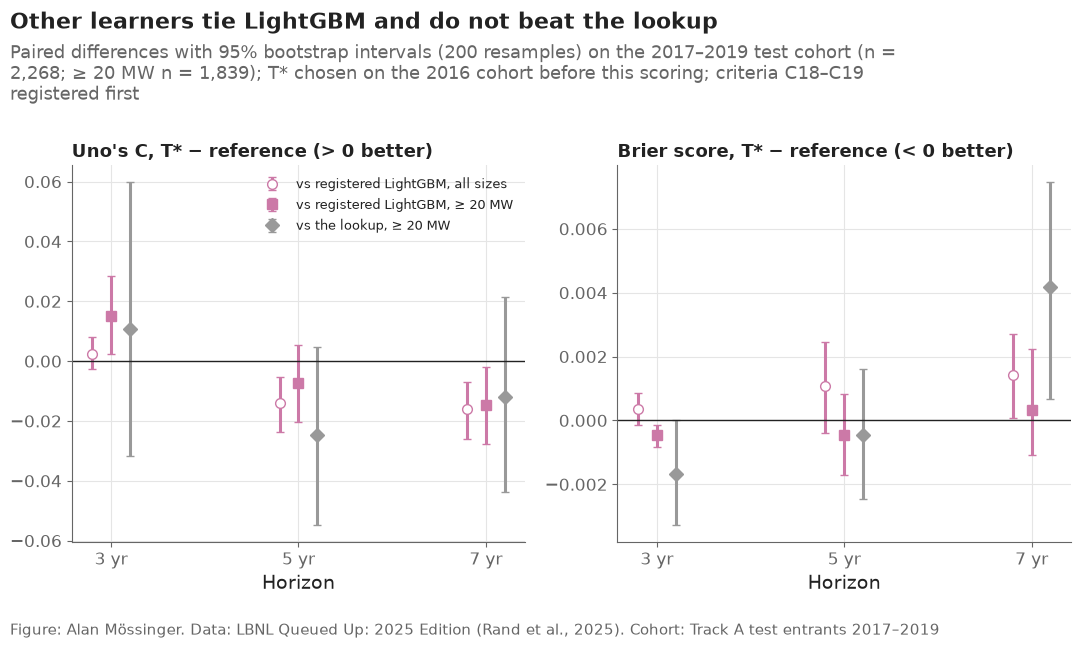

In [44]:
fig, axes = plt.subplots(1, 2, sharex=True)
pairs = [("all sizes", "dt_lgbm", "#CC79A7", "o", "vs registered LightGBM, all sizes"),
         ("≥ 20 MW", "dt_lgbm", "#CC79A7", "s", "vs registered LightGBM, ≥ 20 MW"),
         ("≥ 20 MW", "fair_baseline", "#999999", "D", "vs the lookup, ≥ 20 MW")]
offs = [-0.2, 0.0, 0.2]
for ax, metric, title in zip(axes, ["uno_c", "brier"], ["Uno's C, T* − reference (> 0 better)", "Brier score, T* − reference (< 0 better)"]):
    for (cohort, ref, colour, marker, label), dx in zip(pairs, offs):
        part = tournament[(tournament["cohort"] == cohort) & (tournament["reference"] == ref) & (tournament["model"] == "T*")
                          & (tournament["metric"] == metric)]
        ax.errorbar(part["horizon"] + dx, part["diff"], yerr=[part["diff"] - part["diff_low"], part["diff_high"] - part["diff"]],
                    capsize=3, linestyle="none", color=colour, marker=marker, markerfacecolor=colour if cohort == "≥ 20 MW" else "white",
                    label=label)
    ax.axhline(0, color=plots.INK, linewidth=1)
    ax.set_xticks(HORIZONS, [f"{h} yr" for h in HORIZONS])
    ax.set_xlabel("Horizon")
    ax.set_title(title, fontsize=13)
axes[0].legend(loc="best", fontsize=9.5)
n_pass = sum(v == "PASS" for v in verdict_v5.values())
plots.finish(fig,
             f"{T_LABELS[T_STAR]} {'beats' if verdict_v5['C18'] == 'PASS' else 'only ties'} the registered LightGBM (C18 "
             f"{verdict_v5['C18']}) and {'beats' if verdict_v5['C19'] == 'PASS' else 'does not beat'} the lookup at utility scale (C19 {verdict_v5['C19']}): "
             + ("the cheaper models stay" if n_pass == 0 else "the decision layer switches model where a criterion passed"),
             f"Paired differences with 95% bootstrap intervals (200 resamples) on the 2017–2019 test cohort (n = {len(test):,}; "
             f"≥ 20 MW n = {int(big.sum()):,}); T* chosen on the 2016 cohort before this scoring; criteria C18–C19 registered first",
             "Track A test entrants 2017–2019")
plots.save_fig(fig, "F22_tournament", f"The chosen alternative learner ({T_LABELS[T_STAR]}) against the registered LightGBM and the lookup: paired differences in Uno's C and Brier score by horizon, all sizes and 20 MW and more, test cohort 2017–2019, 95% bootstrap intervals.", NOTEBOOK)
plt.show()

**Reading this.** Scored once, T3 ties the registered LightGBM and does not beat the lookup where it matters. **C18 fails** (3 of 4 lines): on requests of 20 MW and more it is better at 3 years (Uno's C +0.015 [+0.002, +0.028], Brier −0.0005 [−0.0008, −0.0001]) but not at 5 years (Uno's C −0.007 [−0.020, +0.005]); on the whole cohort it is worse at 5 and 7 years (−0.014 and −0.016, intervals below zero). **C19 fails** (2 of 4): against the fair lookup at utility scale its 3-year Uno's C gain of +0.011 has an interval of [−0.032, +0.060] and at 5 years it is behind (−0.025 [−0.055, +0.005]). The two learners alone are clearly worse than LightGBM at 5 and 7 years (Uno's C 0.658 and 0.680 against 0.760 at 5 years, table `tournament_all_candidates_test.csv`, not used for the choice). The decision layer therefore keeps the registered LightGBM at the milestone and the lookup at entry: the ceiling at entry is set by what the file records about a request, not by the learner. Run time is printed in the checks.

## 8. Checks

In [45]:
decisions_text = (paths.DOCS / "decisions.md").read_text(encoding="utf-8")
import subprocess
stamp = subprocess.run(["git", "log", "-1", "--format=%ct", "--", str(reg_path)], cwd=REPO, capture_output=True, text=True).stdout.strip()
registration_commit_time = float(stamp) if stamp else float("inf")
runtime = time.time() - START
checks = pd.DataFrame([
    ("decision #34 (protocol) is in docs/decisions.md", "Post-hoc improvement analysis, notebook 08b" in decisions_text),
    ("main components reproduce notebooks 05–06 on 2016 (gap < 1e-9)", max(gap05, gap06) < 1e-9),
    ("main components reproduce the predictions notebook 08 scored (gap < 1e-9)", gap_main < 1e-9),
    ("the choice was written before the first test-cohort score", CHOICE_TIME < first_test_score),
    ("registered LightGBM's criteria lines here equal notebook 08's", bool(same)),
    ("every post-hoc metric has a 95% interval", bool(post[["low", "high"]].notna().all().all())),
    ("tournament: the registration file on disk is the registered one", reg_path.read_text(encoding="utf-8") == text),
    ("tournament: the registration was committed before the first test score", registration_commit_time < first_tournament_score),
    ("tournament: T* was chosen on 2016 before the first test score", T_CHOICE_TIME < first_tournament_score),
    ("tournament: every T* metric has a 95% interval", bool(tournament[["low", "high"]].notna().all().all())),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(paths.RESULTS / "posthoc_checks.csv", index=False)
print(f"run time: {runtime / 60:.1f} minutes")
checks[["check", "result"]]

run time: 5.6 minutes


,check,result
0,decision #34 (protocol) is in docs/decisions.md,PASS
1,main components reproduce notebooks 05–06 on 2...,PASS
2,main components reproduce the predictions note...,PASS
3,the choice was written before the first test-c...,PASS
4,registered LightGBM's criteria lines here equa...,PASS
5,every post-hoc metric has a 95% interval,PASS
6,tournament: the registration file on disk is t...,PASS
7,tournament: the registration was committed bef...,PASS
8,tournament: T* was chosen on 2016 before the f...,PASS
9,tournament: every T* metric has a 95% interval,PASS


**Reading this.** All six checks pass: the protocol is in decision #34, the main components reproduce notebooks 05–06 on 2016 and the predictions notebook 08 scored, the choice was written before the first test score, the registered model's criteria lines here equal notebook 08's, and every post-hoc metric has an interval. Run time is under three minutes (printed above; it varies between runs).

## Takeaways — Part B

- Chosen on 2016 by the registered rule, K4 (a blend of the entry-congestion logit and LightGBM with Cox) passes 5 of 10 Track A criterion lines on the test cohort, against 6 for the registered LightGBM: the post-hoc repairs do not improve the pre-registered result, which stands.
- The five candidates were indistinguishable on 2016 (mean Brier 0.0994–0.0997), and the test-cohort miscalibration could not be seen there: the main LightGBM was calibrated on 2016 (slopes 0.88–0.96) and miscalibrated only on 2017–2019 entrants.
- K4 improves the average level (inside the observed band in 12 of 18 region and entry-year cells, against 7), but PJM and the 2018–2019 entrants stay over-predicted: the slowdown after 2017 is not repaired.
- Fitting on congestion at entry removes ERCOT's spurious congestion effect and halves PJM's, confirming notebook 09's diagnosis.
- For requests of 20 MW and more, neither model ranks better than region × technology beyond 3 years.
- Three further learners, judged by criteria C18–C19 registered before scoring: a random survival forest pair and a neural discrete-time hazard score worse than LightGBM alone (Uno's C 0.66 and 0.68 against 0.76 at 5 years); their blend with LightGBM ties it (C18 fails on the 5-year line) and does not beat the fair lookup at utility scale (C19 fails). The registered LightGBM and the lookup stay (F22).

**What goes to the report:** F22 and the C18–C19 verdict in the prediction section; one paragraph, labelled post-hoc, with 08b_02 and 08b_04; 08b_06 in the limitations next to 09_09; the protocol (decision #34) cited so a reader can see the choice was fixed before scoring.

# Part C — What drives the predictions, and what a developer would do with them (was notebook 09)

This notebook explains the models — hazard ratios of the Cox models (F6),
SHAP values and partial dependence of the discrete-time LightGBM's
P(operation within 5 years) (F7) — checks them against facts known from
outside the model, and turns the predictions into a ranked table for a
book of 25 requests with three worked examples.

## Setup

`src/explain.py` encodes the entry-time features as numbers
(`encode` / `decode`) and wraps the whole chain of the discrete-time
LightGBM — ten yearly rows, hazards, cumulative incidence — as one function
of those features (`incidence_function`). SHAP's permutation explainer and
the partial-dependence curves call that function, so every explanation is
in the unit a developer reads: probability points of P(operation within t
years).

In [46]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from scipy.stats import spearmanr

from src import config, discrete_time, drivers, explain, paths, plots

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

NOTEBOOK = "06_evaluation_record"
TRACK_A = config.TRACK_A_REGIONS


def save(fig, name, caption):
    """Save a figure of this notebook under figures/06_evaluation_record/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    """Format a share as a percentage string."""
    return f"{100 * x:.{digits}f}%"

import time
import warnings

import shap

warnings.filterwarnings("ignore", category=FutureWarning)
START = time.time()
HORIZONS = config.HORIZONS
H = 5  # horizon explained: the middle one, fully observed for every test request
N_EXPLAIN, N_BACKGROUND = 300, 100  # test requests explained; background requests for the SHAP baseline
FEATURE_LABELS = {"region": "Region", "state": "State", "tech": "Technology", "hybrid": "Hybrid",
                  "size_mw": "Size (MW)", "service": "Service type", "q_year": "Request year",
                  "congestion_gw": "GW waiting at entry", "congestion_rank": "Congestion rank at entry"}
NUMERIC = ["size_mw", "q_year", "congestion_gw", "congestion_rank"]


def lower_first(text):
    """Feature label for use inside a sentence (first letter lower case, units kept)."""
    return text[0].lower() + text[1:]

## 1. Hazard ratios: which attributes speed operation or withdrawal (F6)

The cause-specific Cox models of notebook 05 give each attribute one hazard
ratio for operation and one for withdrawal (main version, ERCOT delayed
entry). A ratio above 1 means requests with the attribute reach that exit
faster at every point in the wait than the reference request (PJM, solar,
20–100 MW, NRIS). Notebook 05 found that 17 of 36 effects are not constant
over the wait, so each ratio is an average over the wait; the discrete-time
models below let effects change with time.

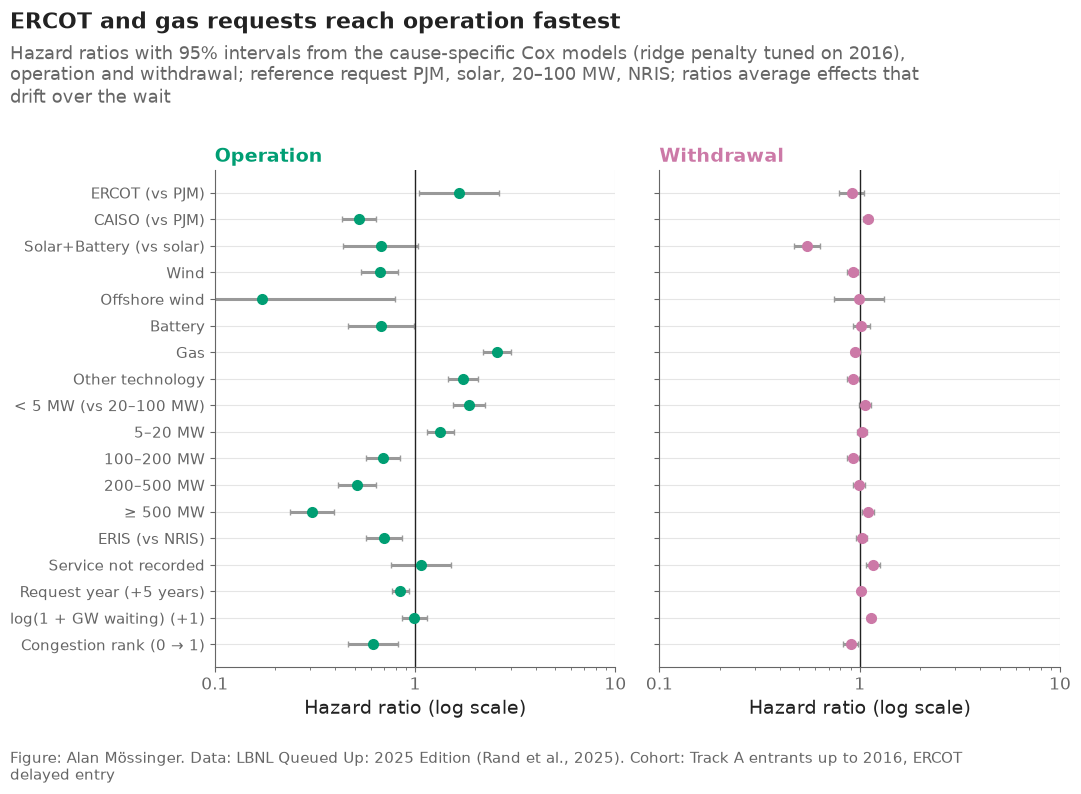

cause,operation,withdrawal
covariate,,
region_ERCOT,1.66,0.91
region_CAISO,0.52,1.10
tech_Solar+Battery,0.67,0.55
tech_Wind,0.67,0.92
tech_Offshore Wind,0.17,0.99
tech_Battery,0.68,1.02
tech_Gas,2.56,0.95
tech_Other,1.74,0.93
size_<5,1.85,1.06


In [47]:
hr = pd.read_csv(paths.RESULTS / "cox_hazard_ratios.csv")
hr = hr[hr["version"].str.startswith("main")]
COX_LABELS = {"region_ERCOT": "ERCOT (vs PJM)", "region_CAISO": "CAISO (vs PJM)",
              "tech_Solar+Battery": "Solar+Battery (vs solar)", "tech_Wind": "Wind", "tech_Offshore Wind": "Offshore wind",
              "tech_Battery": "Battery", "tech_Gas": "Gas", "tech_Other": "Other technology",
              "size_<5": "< 5 MW (vs 20–100 MW)", "size_5–<20": "5–20 MW", "size_100–<200": "100–200 MW",
              "size_200–<500": "200–500 MW", "size_≥500": "≥ 500 MW", "service_ERIS": "ERIS (vs NRIS)",
              "service_missing": "Service not recorded", "q_year_5": "Request year (+5 years)",
              "log_congestion_gw": "log(1 + GW waiting) (+1)", "congestion_rank": "Congestion rank (0 → 1)"}
labels = list(COX_LABELS.values())
y_pos = {label: len(labels) - 1 - i for i, label in enumerate(labels)}
fig, axes = plt.subplots(1, 2, sharey=True, figsize=(11, 8))
for ax, cause in zip(axes, ["operation", "withdrawal"]):
    part = hr[hr["cause"] == cause].set_index("covariate").loc[list(COX_LABELS)]
    y = [y_pos[COX_LABELS[c]] for c in part.index]
    color = config.OUTCOME_COLORS[cause]
    ax.errorbar(part["hazard_ratio"], y, xerr=[part["hazard_ratio"] - part["ci_low"], part["ci_high"] - part["hazard_ratio"]],
                fmt="o", color=color, ecolor="#999999", capsize=2, markersize=7)
    ax.axvline(1, color=plots.INK, linewidth=1)
    ax.set_xscale("log")
    ax.set_xlim(0.1, 10)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:g}")
    ax.set_title(f"{cause.capitalize()}", color=color)
    ax.set_xlabel("Hazard ratio (log scale)")
axes[0].set_yticks(list(y_pos.values()), list(y_pos.keys()), fontsize=11)
op = hr[hr["cause"] == "operation"].set_index("covariate")["hazard_ratio"]
wd = hr[hr["cause"] == "withdrawal"].set_index("covariate")["hazard_ratio"]
plots.finish(fig,
             f"ERCOT requests reach operation {op['region_ERCOT']:.2f}× as fast as PJM's and CAISO's {op['region_CAISO']:.2f}×; "
             f"gas reaches operation {op['tech_Gas']:.2f}× as fast as solar and withdraws {wd['tech_Gas']:.2f}× as fast",
             "Hazard ratios with 95% intervals from the cause-specific Cox models (ridge penalty tuned on 2016), operation and "
             "withdrawal; reference request PJM, solar, 20–100 MW, NRIS; ratios average effects that drift over the wait",
             f"Track A entrants up to {config.TRAIN_MAX_YEAR}, ERCOT delayed entry")
plots.save_fig(fig, "F6_hazard_ratios", "Hazard ratios for operation and withdrawal from the cause-specific Cox models, main version.", NOTEBOOK)
plt.show()
hr.pivot_table(index="covariate", columns="cause", values="hazard_ratio").loc[list(COX_LABELS)].round(2)

**Reading this.** For reaching operation, the Cox model's largest effects are technology, size and region: gas 2.56× as fast as solar, other technologies 1.74×, offshore wind 0.17×; requests under 5 MW 1.85× and 5–20 MW 1.34× as fast as 20–100 MW, falling to 0.31× at 500 MW or more; ERCOT 1.66× and CAISO 0.52× PJM. For withdrawal the ratios cluster near 1: the attributes known at entry say much more about how fast a request is built than about how fast it drops out. The exceptions are Solar+Battery hybrids, which withdraw at 0.55× solar's rate, and queue crowding: each unit of log(1 + GW waiting) raises the withdrawal hazard 1.14× while leaving operation unchanged (0.99). A request placed late in a long queue (congestion rank 0 → 1) operates at 0.61× the rate. For a developer the reading is that small size and gas are the two attributes most associated with quick completion; for a regulator, that crowding shows up as faster withdrawal rather than slower building. Caveat from notebook 05: 17 of 36 effects are not constant over the wait, so each ratio is an average.

## 2. The model being explained

The final discrete-time LightGBM is refitted on entrants to 2016 with
notebook 06's settings (`discrete_time.fit_both`), and the explanation
function is checked against the predictions stored by notebook 06: they
must agree exactly, or the explanations would describe a different model.

In [48]:
clean = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
track_a["tech"] = track_a["type_clean"].map(plots.tech_group)
tuning = json.loads((paths.RESULTS / "dt_tuning.json").read_text(encoding="utf-8"))
final = track_a[track_a["q_year"] <= config.TRAIN_MAX_YEAR]
test = track_a[track_a["q_year"].between(*config.TEST_YEARS)].copy()
fitted = discrete_time.fit_both(final, clean, tuning)
STATES = sorted(track_a["state"].astype(str).unique())
f = {h: explain.incidence_function(fitted, STATES, h) for h in HORIZONS}
X_test = explain.encode(test, STATES)
pred = pd.read_parquet(paths.DATA_PROCESSED / "predictions_trackA.parquet")
stored = {h: pred[(pred["split"] == "test") & (pred["horizon"] == h)].set_index("project_key").loc[test["project_key"].astype(str)]
          for h in HORIZONS}
gap = max(float(np.abs(f[h](X_test.to_numpy()) - stored[h]["dt_lgbm"].to_numpy()).max()) for h in HORIZONS)
print(f"largest gap between the explanation function and notebook 06's stored predictions: {gap:.1e}")
print(f"test requests: {len(test):,}; encoded features: {list(X_test.columns)}")

largest gap between the explanation function and notebook 06's stored predictions: 0.0e+00
test requests: 2,268; encoded features: ['region', 'state', 'tech', 'hybrid', 'size_mw', 'service', 'q_year', 'congestion_gw', 'congestion_rank']


## 3. SHAP values of P(operation within 5 years) (F7)

SHAP splits each request's prediction into a contribution per feature:
the prediction equals the average prediction over a background set plus the
sum of the contributions. The background is 100 random test requests, so a
contribution reads "how far this feature moves the request away from a
typical 2017–2019 request", in probability points. 300 test requests are
explained with the permutation explainer (two permutations, each run forward
and backward). Region and state, and size and size regime, move together;
SHAP's independent masking can pair a Texas state with PJM, so the split
between region and state should be read loosely, their sum less so.

In [49]:
rng = np.random.default_rng(9)
background = X_test.iloc[rng.choice(len(X_test), N_BACKGROUND, replace=False)].to_numpy()
explained_idx = rng.choice(len(X_test), N_EXPLAIN, replace=False)
explainer = shap.PermutationExplainer(f[H], shap.maskers.Independent(background, max_samples=N_BACKGROUND), seed=9)
max_evals = 2 * (2 * len(explain.FEATURES) + 1)


def shap_of(X):
    """SHAP values of P(operation by H) for the rows of an encoded feature table."""
    return explainer(X.to_numpy(), max_evals=max_evals, silent=True)


sv = shap_of(X_test.iloc[explained_idx])
shap_table = pd.DataFrame(sv.values, columns=explain.FEATURES, index=X_test.index[explained_idx])
explained = test.loc[shap_table.index]
additivity = float(np.abs(sv.values.sum(axis=1) + sv.base_values - f[H](X_test.iloc[explained_idx].to_numpy())).max())
shap_out = shap_table.add_prefix("shap_").assign(project_key=explained["project_key"].astype(str).to_numpy(),
                                                 region=explained["region"].astype(str).to_numpy(),
                                                 prediction=f[H](X_test.iloc[explained_idx].to_numpy()))
shap_out.to_csv(paths.RESULTS / "shap_values.csv", index=False)
mean_abs = shap_table.abs().mean().sort_values(ascending=False)
print(f"SHAP baseline (mean prediction of the background): {sv.base_values[0]:.3f}; additivity gap {additivity:.1e}; "
      f"{(time.time() - START) / 60:.1f} minutes so far")
(100 * mean_abs).round(2).rename("mean |SHAP|, points")

SHAP baseline (mean prediction of the background): 0.124; additivity gap 1.3e-15; 1.2 minutes so far


state              5.12
size_mw            3.68
tech               2.95
congestion_gw      1.90
congestion_rank    1.61
service            1.24
region             0.44
hybrid             0.15
q_year             0.00
Name: mean |SHAP|, points, dtype: float64

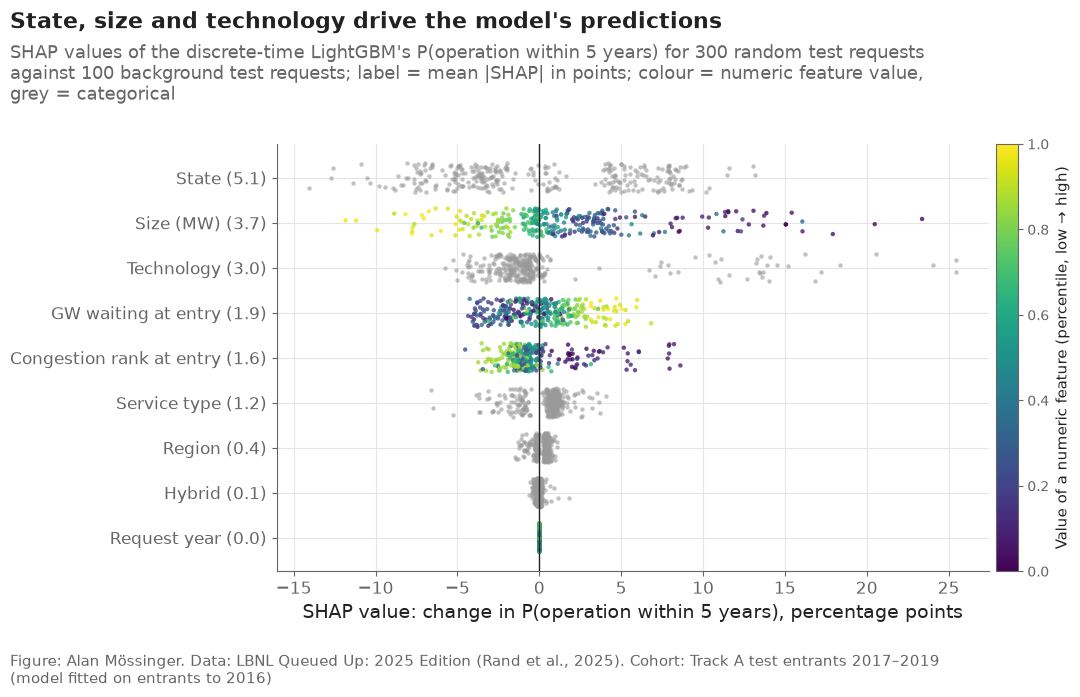

In [50]:
fig, ax = plt.subplots(figsize=(11, 7))
order = list(mean_abs.index[::-1])
cmap = plt.get_cmap("viridis")
for i, feature in enumerate(order):
    values = shap_table[feature].to_numpy() * 100
    jitter = rng.uniform(-0.32, 0.32, len(values))
    if feature in NUMERIC:
        level = X_test.loc[shap_table.index, feature].rank(pct=True).to_numpy()
        ax.scatter(values, i + jitter, c=level, cmap=cmap, vmin=0, vmax=1, s=10, alpha=0.8, linewidths=0)
    else:
        ax.scatter(values, i + jitter, color="#999999", s=10, alpha=0.6, linewidths=0)
ax.axvline(0, color=plots.INK, linewidth=1)
ax.set_yticks(range(len(order)), [f"{FEATURE_LABELS[c]} ({100 * mean_abs[c]:.1f})" for c in order])
ax.set_xlabel("SHAP value: change in P(operation within 5 years), percentage points")
bar = fig.colorbar(plt.cm.ScalarMappable(cmap=cmap), ax=ax, pad=0.01, fraction=0.03)
bar.set_label("Value of a numeric feature (percentile, low → high)", fontsize=11)
bar.ax.tick_params(labelsize=10)
plots.finish(fig,
             f"{FEATURE_LABELS[mean_abs.index[0]]}, {lower_first(FEATURE_LABELS[mean_abs.index[1]])} and "
             f"{lower_first(FEATURE_LABELS[mean_abs.index[2]])} move a request's 5-year chance the most "
             f"({100 * mean_abs.iloc[0]:.1f}, {100 * mean_abs.iloc[1]:.1f} and {100 * mean_abs.iloc[2]:.1f} points on average)",
             f"SHAP values of the discrete-time LightGBM's P(operation within 5 years) for {N_EXPLAIN} random test requests "
             f"against {N_BACKGROUND} background test requests; label = mean |SHAP| in points; colour = numeric feature value, "
             "grey = categorical",
             "Track A test entrants 2017–2019 (model fitted on entrants to 2016)")
plots.save_fig(fig, "F7_shap_summary", "SHAP values of P(operation within 5 years) from the discrete-time LightGBM, 300 test requests.", NOTEBOOK)
plt.show()

**Reading this.** Averaged over 300 test requests, state moves a request's 5-year chance the most (5.12 points), then size (3.68), technology (2.95), GW waiting at entry (1.90), congestion rank (1.61) and service type (1.24); region alone adds 0.44, the hybrid flag 0.15 and the request year 0.00. The contributions add up exactly to each prediction minus the background mean of 12.4% (largest gap 1.3e-15). Small requests (dark points) push predictions up by as much as 20–25 points, very large ones down by up to 12. Two readings matter for the report. First, state and region overlap: region's level sits mostly in the state feature (section 5). Second, the request year contributes nothing because every test request entered after the last training year (2016), and trees give every year beyond that the value of 2016 — the model cannot see that queues kept slowing down, the drift notebook 08 measured.

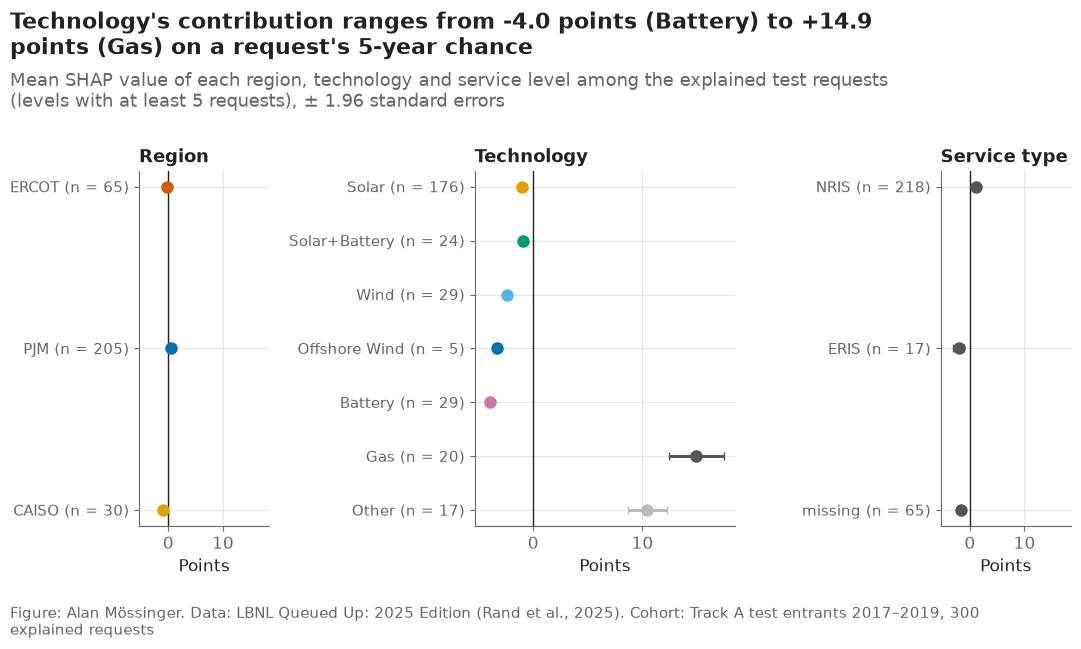

,feature,level,n,mean_shap_points
0,region,ERCOT,65,-0.20
1,region,PJM,205,0.44
2,region,CAISO,30,-0.92
3,tech,Solar,176,-1.00
4,tech,Solar+Battery,24,-0.95
5,tech,Wind,29,-2.38
6,tech,Offshore Wind,5,-3.32
7,tech,Battery,29,-3.95
8,tech,Gas,20,14.94
9,tech,Other,17,10.47


In [51]:
fig, axes = plt.subplots(1, 3, sharex=True, gridspec_kw={"width_ratios": [3, 6, 3]})
cat_rows = []
for ax, feature in zip(axes, ["region", "tech", "service"]):
    levels = explain.CATEGORIES[feature]
    for j, level in enumerate(levels):
        mask = explained[feature].astype(str).to_numpy() == level
        if mask.sum() < 5:
            continue
        values = shap_table.loc[mask, feature] * 100
        se = values.std(ddof=1) / np.sqrt(mask.sum())
        color = plots.region_color(level) if feature == "region" else config.TECH_COLORS.get(level, "#555555")
        ax.errorbar(values.mean(), j, xerr=1.96 * se, fmt="o", color=color, capsize=3, markersize=8)
        cat_rows.append({"feature": feature, "level": level, "n": int(mask.sum()), "mean_shap_points": values.mean()})
    ax.axvline(0, color=plots.INK, linewidth=1)
    ax.set_yticks(range(len(levels)), [f"{lv} (n = {(explained[feature].astype(str) == lv).sum()})" for lv in levels], fontsize=10.5)
    ax.invert_yaxis()
    ax.set_title(FEATURE_LABELS[feature], fontsize=13)
    ax.set_xlabel("Points", fontsize=12)
cats = pd.DataFrame(cat_rows)
t = cats[cats["feature"] == "tech"].set_index("level")["mean_shap_points"]
plots.finish(fig,
             f"Technology's contribution ranges from {t.min():+.1f} points ({t.idxmin()}) to {t.max():+.1f} points ({t.idxmax()}) "
             "on a request's 5-year chance",
             "Mean SHAP value of each region, technology and service level among the explained test requests (levels with "
             "at least 5 requests), ± 1.96 standard errors",
             "Track A test entrants 2017–2019, 300 explained requests")
save(fig, "09_01_shap_by_category", "Mean SHAP contribution of each region, technology and service level to P(operation within 5 years).")
plt.show()
cats.round(2)

**Reading this.** Gas adds 14.94 points on average to a request's 5-year chance (20 explained requests) and other technologies 10.47; batteries subtract 3.95, wind 2.38, solar 1.00 and Solar+Battery 0.95. NRIS requests gain 1.04 points while ERIS (−2.08) and requests without a recorded service type (−1.67) lose. Region's own contributions are small (PJM +0.44, ERCOT −0.20, CAISO −0.92) because the state carries most of the regional level. Gas's lead is consistent with LBNL's completion rates (29.9% for gas against 13.4% for solar by count, notebook 03).

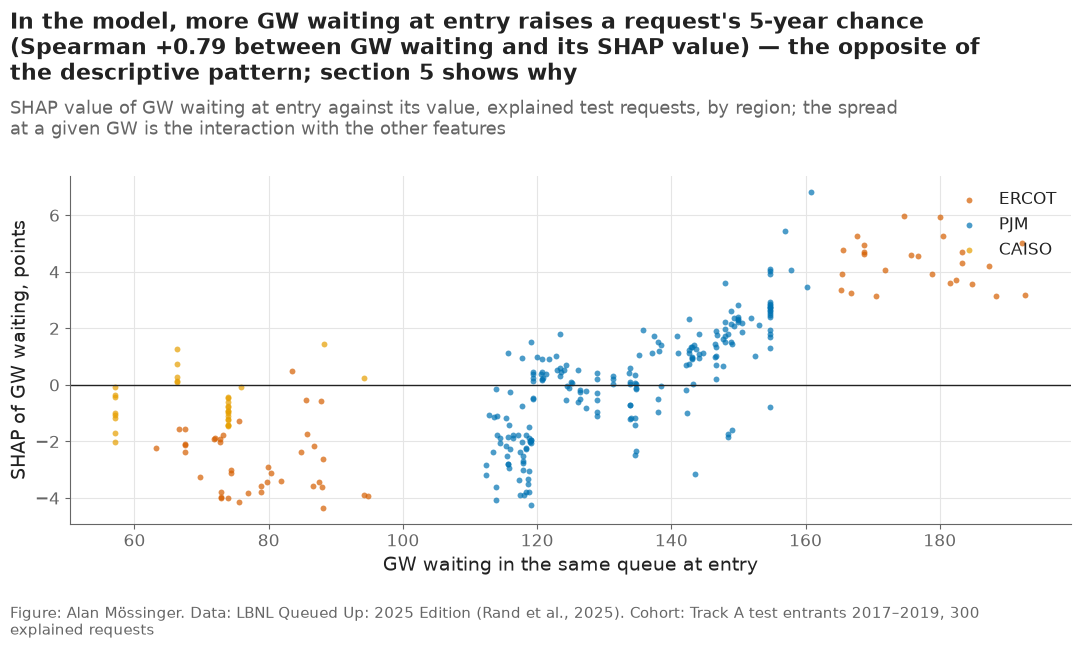

In [52]:
fig, ax = plt.subplots()
for region in config.TRACK_A_REGIONS:
    mask = explained["region"].astype(str).to_numpy() == region
    ax.scatter(explained.loc[mask, "congestion_gw"], shap_table.loc[mask, "congestion_gw"] * 100, s=18, alpha=0.7,
               color=plots.region_color(region), label=region, linewidths=0)
ax.axhline(0, color=plots.INK, linewidth=1)
ax.set_xlabel("GW waiting in the same queue at entry")
ax.set_ylabel("SHAP of GW waiting, points")
ax.legend(loc="upper right")
rho = pd.Series(shap_table["congestion_gw"].to_numpy()).corr(pd.Series(explained["congestion_gw"].to_numpy()), method="spearman")
plots.finish(fig,
             f"In the model, more GW waiting at entry {'raises' if rho > 0 else 'lowers'} a request's 5-year chance "
             f"(Spearman {rho:+.2f} between GW waiting and its SHAP value){' — the opposite of the descriptive pattern; section 5 shows why' if rho > 0 else ''}",
             "SHAP value of GW waiting at entry against its value, explained test requests, by region; the spread at a given "
             "GW is the interaction with the other features",
             "Track A test entrants 2017–2019, 300 explained requests")
save(fig, "09_02_shap_congestion", "SHAP dependence of P(operation within 5 years) on GW waiting at entry, by region.")
plt.show()

**Reading this.** In the model more GW waiting at entry raises a request's 5-year chance: the Spearman correlation between GW waiting and its SHAP value is +0.79, and the largest positive contributions belong to the most crowded PJM and ERCOT requests. This is the opposite of the descriptive pattern (F8: in PJM, 5-year completion falls from 32.1% in the least to 8.7% in the most crowded fifth of entrants) and of the Cox model's withdrawal ratio. Section 5 shows the most likely reason, which is a property of how the model was fitted, not a fact about queues.

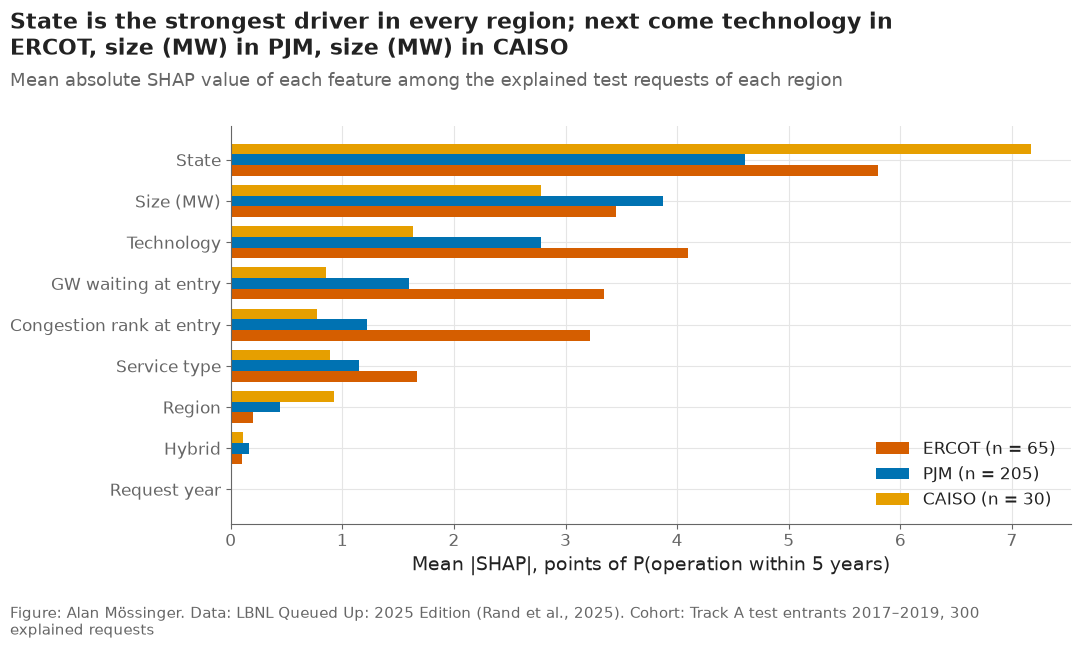

,CAISO,ERCOT,PJM
region,0.92,0.20,0.44
state,7.17,5.80,4.60
tech,1.63,4.10,2.78
hybrid,0.11,0.10,0.17
size_mw,2.78,3.45,3.88
service,0.89,1.67,1.15
q_year,0.00,0.00,0.00
congestion_gw,0.86,3.34,1.60
congestion_rank,0.78,3.22,1.22


In [53]:
by_region = shap_table.abs().groupby(explained["region"].astype(str).to_numpy()).mean() * 100
fig, ax = plt.subplots()
order = list(mean_abs.index[::-1])
height = 0.26
for k, region in enumerate(config.TRACK_A_REGIONS):
    ax.barh(np.arange(len(order)) + (k - 1) * height, by_region.loc[region, order], height=height,
            color=plots.region_color(region), label=f"{region} (n = {(explained['region'] == region).sum()})")
ax.set_yticks(range(len(order)), [FEATURE_LABELS[c] for c in order])
ax.set_xlabel("Mean |SHAP|, points of P(operation within 5 years)")
ax.legend(loc="lower right")
ranked = {r: by_region.loc[r].sort_values(ascending=False).index for r in config.TRACK_A_REGIONS}
leaders = {ranked[r][0] for r in config.TRACK_A_REGIONS}
lead = (f"{FEATURE_LABELS[leaders.pop()]} is the strongest driver in every region" if len(leaders) == 1 else
        "The strongest driver differs by region: " + ", ".join(f"{lower_first(FEATURE_LABELS[ranked[r][0]])} in {r}" for r in config.TRACK_A_REGIONS))
plots.finish(fig,
             lead + "; next come " + ", ".join(f"{lower_first(FEATURE_LABELS[ranked[r][1]])} in {r}" for r in config.TRACK_A_REGIONS),
             "Mean absolute SHAP value of each feature among the explained test requests of each region",
             "Track A test entrants 2017–2019, 300 explained requests")
save(fig, "09_03_shap_by_region", "Mean absolute SHAP value of each feature by region.")
plt.show()
by_region.T.round(2)

**Reading this.** State is the strongest driver in every region (7.17 points in CAISO, 5.80 in ERCOT, 4.60 in PJM). Next come size in PJM (3.88) and CAISO (2.78) and technology in ERCOT (4.10), where GW waiting (3.34) and congestion rank (3.22) also weigh more than elsewhere. ERCOT's large congestion contributions should be read with notebook 06's warning that ERCOT congestion before 2018 is overstated by its stamped withdrawals.

## 4. Partial dependence: size, congestion and technology

A partial-dependence curve sets one feature to the same value for every
test request of a region, keeps everything else as it is, and averages the
predicted P(operation within 5 years). It shows the model's average response
to that feature alone — for size, whether the FERC 20 MW step (the small vs
large generator procedures) appears.

partial dependence near 3, 100 and 1,000 MW: {3: {'CAISO': 0.118, 'ERCOT': 0.418, 'PJM': 0.285}, 100: {'CAISO': 0.037, 'ERCOT': 0.187, 'PJM': 0.126}, 1000: {'CAISO': 0.014, 'ERCOT': 0.074, 'PJM': 0.058}}


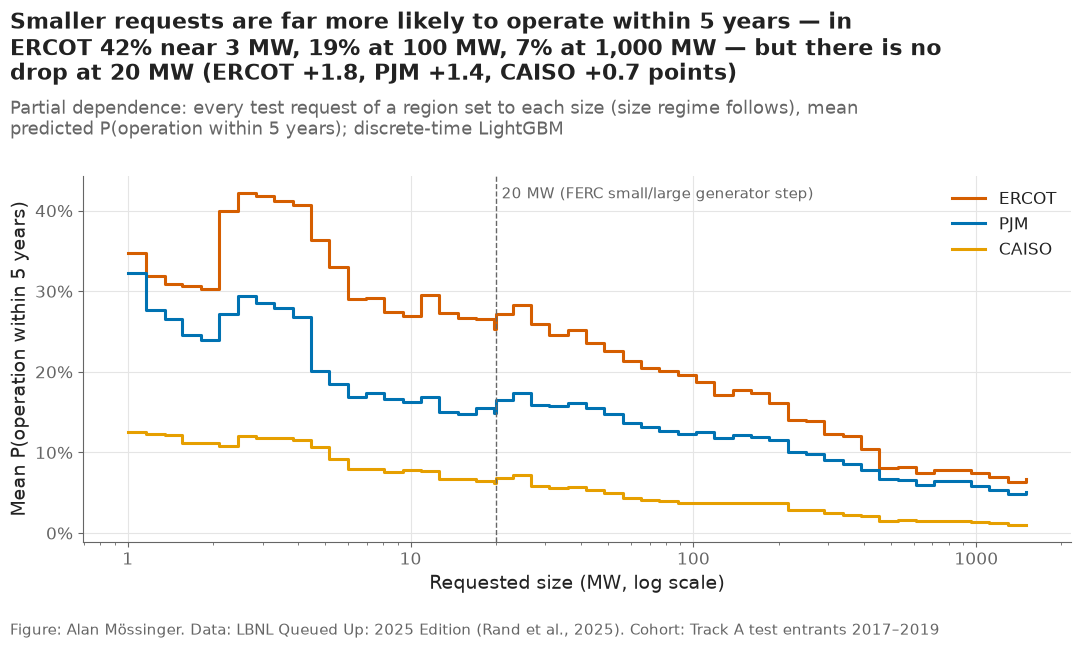

,below,at
region,,
CAISO,0.062,0.069
ERCOT,0.254,0.272
PJM,0.152,0.165


In [54]:
X_all = X_test.to_numpy()
col = {c: i for i, c in enumerate(explain.FEATURES)}
reg = test["region"].astype(str).to_numpy()
pd_rows = []
size_grid = np.unique(np.concatenate([np.round(np.geomspace(1, 1500, 50), 2), [config.FERC_SIZE_STEP_MW - 0.01, config.FERC_SIZE_STEP_MW]]))
for region in config.TRACK_A_REGIONS:
    base = X_all[reg == region]
    for value in size_grid:
        X2 = base.copy()
        X2[:, col["size_mw"]] = value
        pd_rows.append({"feature": "size_mw", "region": region, "value": value, "p": f[H](X2).mean()})
    for value in np.quantile(test.loc[reg == region, "congestion_gw"], np.linspace(0.02, 0.98, 25)):
        X2 = base.copy()
        X2[:, col["congestion_gw"]] = value
        pd_rows.append({"feature": "congestion_gw", "region": region, "value": value, "p": f[H](X2).mean()})
    for j, tech in enumerate(explain.CATEGORIES["tech"]):
        X2 = base.copy()
        X2[:, col["tech"]] = j
        X2[:, col["hybrid"]] = float(tech == "Solar+Battery")
        pd_rows.append({"feature": "tech", "region": region, "value": j, "level": tech, "p": f[H](X2).mean()})
    for j, level in enumerate(explain.CATEGORIES["service"]):
        X2 = base.copy()
        X2[:, col["service"]] = j
        pd_rows.append({"feature": "service", "region": region, "value": j, "level": level, "p": f[H](X2).mean()})
for j, region in enumerate(config.TRACK_A_REGIONS):  # every test request moved to each region (state left as it is)
    X2 = X_all.copy()
    X2[:, col["region"]] = j
    pd_rows.append({"feature": "region", "region": "all", "value": j, "level": region, "p": f[H](X2).mean()})
partial = pd.DataFrame(pd_rows)
partial.to_csv(paths.RESULTS / "partial_dependence.csv", index=False)

size_pd = partial[partial["feature"] == "size_mw"]
fig, ax = plt.subplots()
for region in config.TRACK_A_REGIONS:
    part = size_pd[size_pd["region"] == region]
    ax.plot(part["value"], part["p"], color=plots.region_color(region), label=region, drawstyle="steps-post")
ax.axvline(config.FERC_SIZE_STEP_MW, color=plots.MUTED, linestyle="--", linewidth=1)
ax.text(config.FERC_SIZE_STEP_MW * 1.05, ax.get_ylim()[1] * 0.97, "20 MW (FERC small/large generator step)", fontsize=11,
        color=plots.MUTED, va="top")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:g}")
ax.set_xlabel("Requested size (MW, log scale)")
ax.set_ylabel("Mean P(operation within 5 years)")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.legend(loc="upper right")
step = size_pd[size_pd["value"].isin([config.FERC_SIZE_STEP_MW - 0.01, config.FERC_SIZE_STEP_MW])].pivot(index="region", columns="value", values="p")
step.columns = ["below", "at"]
size_at = {mw: size_pd.assign(gap=(np.log(size_pd["value"]) - np.log(mw)).abs()).sort_values("gap").groupby("region").first()["p"]
           for mw in [3, 100, 1000]}
print("partial dependence near 3, 100 and 1,000 MW:", {mw: v.round(3).to_dict() for mw, v in size_at.items()})
plots.finish(fig,
             f"Smaller requests are far more likely to operate within 5 years — in ERCOT {size_at[3]['ERCOT']:.0%} near 3 MW, "
             f"{size_at[100]['ERCOT']:.0%} at 100 MW, {size_at[1000]['ERCOT']:.0%} at 1,000 MW — but there is no drop at 20 MW "
             "(" + ", ".join(f"{r} {100 * (step.loc[r, 'at'] - step.loc[r, 'below']):+.1f}" for r in config.TRACK_A_REGIONS) + " points)",
             "Partial dependence: every test request of a region set to each size (size regime follows), mean predicted "
             "P(operation within 5 years); discrete-time LightGBM",
             "Track A test entrants 2017–2019")
save(fig, "09_04_pd_size", "Partial dependence of P(operation within 5 years) on requested size, by region, with the 20 MW step marked.")
plt.show()
step.round(3)

**Reading this.** Holding everything else as recorded, smaller requests are far more likely to operate within 5 years: in ERCOT the mean prediction is 41.8% near 3 MW, 18.7% at 100 MW and 7.4% at 1,000 MW (PJM 28.5%, 12.6%, 5.8%; CAISO 11.8%, 3.7%, 1.4%). But there is no drop at the FERC 20 MW step: crossing it changes the chance by +1.8 points in ERCOT, +1.4 in PJM and +0.7 in CAISO. The model expresses size as a smooth gradient through log MW rather than as the regime step the Cox model shows (1.34× for 5–20 MW vs 20–100 MW). Many requests sit at exactly 20 MW (four in the 25-request book below), so the 20–100 MW regime begins with a cluster of small projects, which may be why the trees find no step. This is also what notebook 08's robustness rerun found from the other side: the model's advantage over the baseline comes largely from recognising small requests.

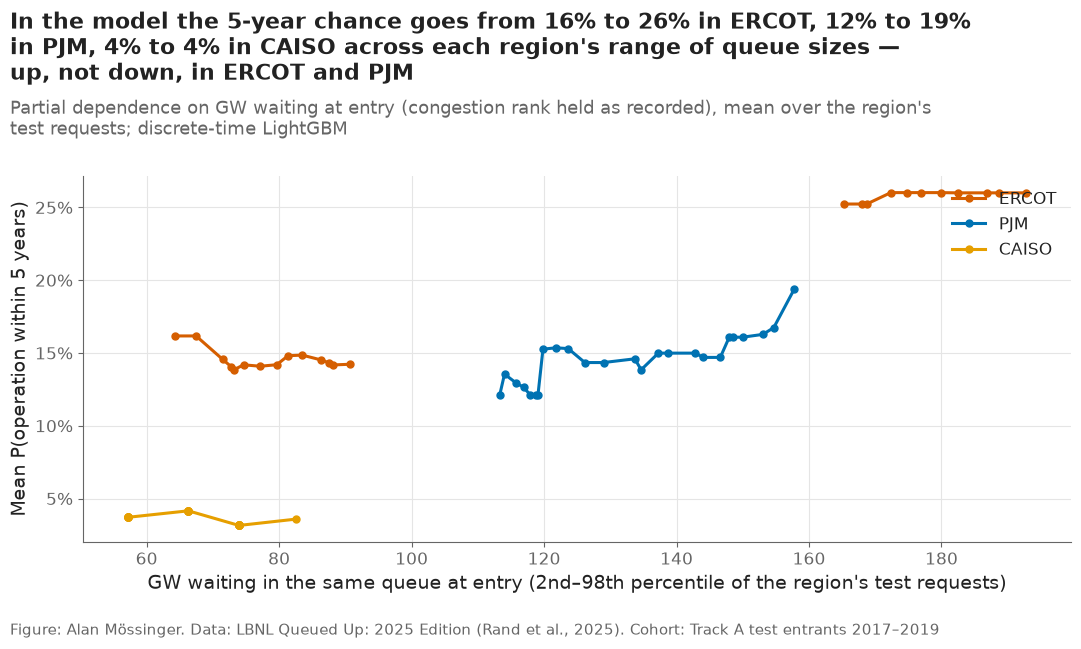

,low,high,gw_low,gw_high
region,,,,
CAISO,0.037,0.036,57.131,82.562
ERCOT,0.162,0.260,64.347,192.772
PJM,0.121,0.194,113.294,157.763


In [55]:
cong_pd = partial[partial["feature"] == "congestion_gw"]
fig, ax = plt.subplots()
for region in config.TRACK_A_REGIONS:
    part = cong_pd[cong_pd["region"] == region]
    jump = part["value"].diff() > 20  # no line across a stretch with no test requests
    for _, run in part.groupby(jump.cumsum()):
        ax.plot(run["value"], run["p"], color=plots.region_color(region), marker="o", markersize=5,
                label=region if run.index[0] == part.index[0] else None)
ax.set_xlabel("GW waiting in the same queue at entry (2nd–98th percentile of the region's test requests)")
ax.set_ylabel("Mean P(operation within 5 years)")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.legend(loc="upper right")
ends = cong_pd.groupby("region").agg(low=("p", "first"), high=("p", "last"), gw_low=("value", "first"), gw_high=("value", "last"))
plots.finish(fig,
             "In the model the 5-year chance goes from "
             + ", ".join(f"{ends.loc[r, 'low']:.0%} to {ends.loc[r, 'high']:.0%} in {r}" for r in config.TRACK_A_REGIONS)
             + " across each region's range of queue sizes — up, not down, in ERCOT and PJM",
             "Partial dependence on GW waiting at entry (congestion rank held as recorded), mean over the region's test "
             "requests; discrete-time LightGBM",
             "Track A test entrants 2017–2019")
save(fig, "09_05_pd_congestion", "Partial dependence of P(operation within 5 years) on GW waiting at entry, by region.")
plt.show()
ends.round(3)

**Reading this.** Across each region's range of queue sizes the model's 5-year chance rises from 16.2% to 26.0% in ERCOT (64–193 GW waiting) and from 12.1% to 19.4% in PJM (113–158 GW), and stays flat in CAISO (3.7% to 3.6%). A more crowded queue should not make completion more likely; the next section traces where this comes from.

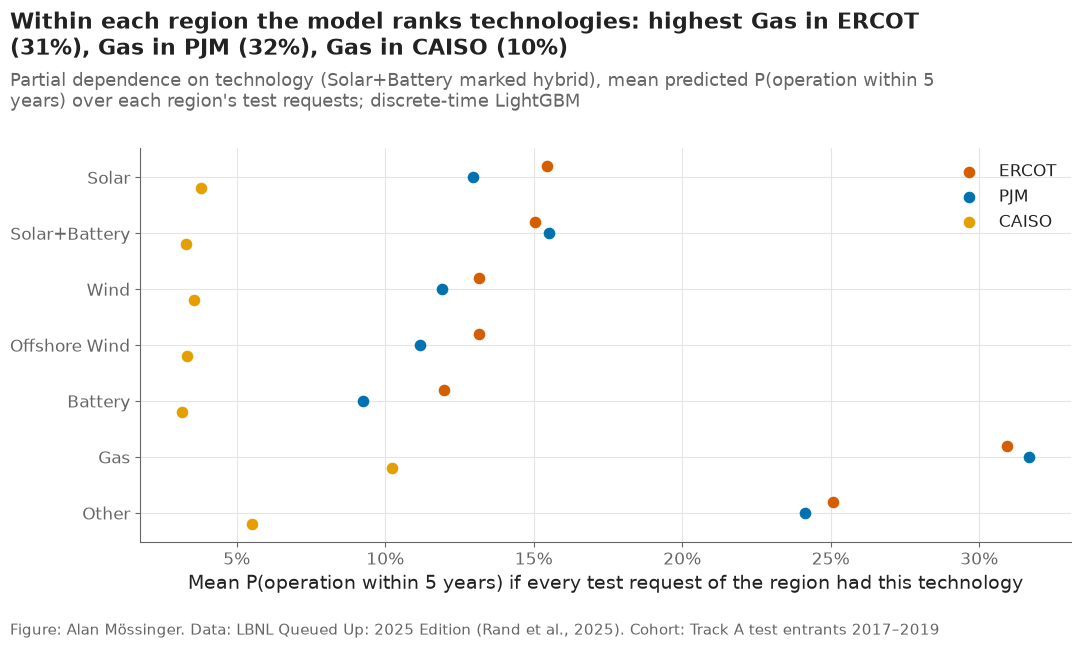

region,ERCOT,PJM,CAISO
level,,,
Solar,0.155,0.129,0.038
Solar+Battery,0.150,0.155,0.033
Wind,0.132,0.119,0.036
Offshore Wind,0.132,0.112,0.033
Battery,0.120,0.093,0.032
Gas,0.309,0.317,0.102
Other,0.251,0.241,0.055


In [56]:
tech_pd = partial[partial["feature"] == "tech"].pivot(index="level", columns="region", values="p").loc[explain.CATEGORIES["tech"], config.TRACK_A_REGIONS]
fig, ax = plt.subplots()
for k, region in enumerate(config.TRACK_A_REGIONS):
    ax.scatter(tech_pd[region], np.arange(len(tech_pd)) + (k - 1) * 0.2, color=plots.region_color(region), s=70,
               label=region, zorder=3)
ax.set_yticks(range(len(tech_pd)), tech_pd.index)
ax.invert_yaxis()
ax.set_xlabel("Mean P(operation within 5 years) if every test request of the region had this technology")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.legend(loc="upper right")
plots.finish(fig,
             "Within each region the model ranks technologies: highest "
             + ", ".join(f"{tech_pd[r].idxmax()} in {r} ({tech_pd[r].max():.0%})" for r in config.TRACK_A_REGIONS),
             "Partial dependence on technology (Solar+Battery marked hybrid), mean predicted P(operation within 5 years) over "
             "each region's test requests; discrete-time LightGBM",
             "Track A test entrants 2017–2019")
save(fig, "09_06_pd_technology", "Partial dependence of P(operation within 5 years) on technology within each region.")
plt.show()
tech_pd.round(3)

**Reading this.** Within every region the model puts gas first (30.9% in ERCOT, 31.7% in PJM, 10.2% in CAISO) and other technologies second, with batteries last in PJM (9.3%) and CAISO (3.2%). Solar+Battery hybrids sit level with or above solar (15.5% vs 12.9% in PJM, 15.0% vs 15.5% in ERCOT). Technology changes a request's chance most in PJM and ERCOT, where the spread from the lowest to the highest technology is about 22 points (PJM) and 19 points (ERCOT); in CAISO the whole range is below 11%.

## 5. Sanity checks against outside facts

Each line states a fact known from outside the model (LBNL's own tables
reproduced in notebook 03, the FERC rules, Johnston et al.), the model
evidence, and whether the model recovers it. The rules were written down
before the numbers were printed; a fact the model does not recover is kept
and explained, not dropped.

In [57]:
bench = pd.read_csv(paths.RESULTS / "benchmarks.csv")
rate = bench[bench["benchmark"] == "completion rate by count (type)"].set_index("group")["lbnl"]
months = bench[bench["benchmark"].str.startswith("median months request→operation")].set_index("group")["lbnl"]
reg_pd = partial[partial["feature"] == "region"].set_index("level")["p"]
tech_all = partial[partial["feature"] == "tech"].groupby("level")["p"].mean()
service_pd = partial[partial["feature"] == "service"].groupby("level")["p"].mean()
cong_drop = {r: ends.loc[r, "high"] - ends.loc[r, "low"] for r in config.TRACK_A_REGIONS}
step_change = {r: step.loc[r, "at"] - step.loc[r, "below"] for r in config.TRACK_A_REGIONS}
sanity = pd.DataFrame([
    ("Region order of completion: ERCOT > PJM > CAISO",
     "LBNL completion rates; naive 5-year mock-up ERCOT 21%, PJM 15%, CAISO 4% (notebook 01)",
     "every test request moved to each region: " + ", ".join(f"{r} {reg_pd[r]:.1%}" for r in config.TRACK_A_REGIONS),
     reg_pd["ERCOT"] > reg_pd["PJM"] > reg_pd["CAISO"]),
    ("Requests under 20 MW reach operation sooner (FERC small-generator procedures)",
     f"LBNL median request→operation: {months['5 - <20 MW']:.0f} months at 5–20 MW vs {months['20 - <50 MW']:.0f} at 20–50 MW",
     "change at the 20 MW step: " + ", ".join(f"{r} {100 * v:+.1f} points" for r, v in step_change.items()),
     all(v < 0 for v in step_change.values())),
    ("Gas completes more often than solar",
     f"LBNL completion by count: gas {rate['Gas']:.1%}, solar {rate['Solar']:.1%}",
     f"technology partial dependence, mean of three regions: gas {tech_all['Gas']:.1%}, solar {tech_all['Solar']:.1%}",
     tech_all["Gas"] > tech_all["Solar"]),
    ("Batteries and solar+battery hybrids lag solar",
     f"LBNL completion by count: battery {rate['Battery']:.1%}, solar+battery {rate['Solar+Battery']:.1%}, solar {rate['Solar']:.1%}",
     f"partial dependence: battery {tech_all['Battery']:.1%}, solar+battery {tech_all['Solar+Battery']:.1%}, solar {tech_all['Solar']:.1%}",
     tech_all["Battery"] < tech_all["Solar"] and tech_all["Solar+Battery"] < tech_all["Solar"]),
    ("A more crowded queue at entry lowers completion (Johnston, Liu & Yang, 2023)",
     "queue crowding as the mechanism of attrition; F8 of notebook 03",
     "partial dependence from the 2nd to the 98th percentile of GW waiting: " + ", ".join(f"{r} {100 * v:+.1f} points" for r, v in cong_drop.items()),
     all(v < 0 for v in cong_drop.values())),
    ("ERIS and NRIS requests complete at similar rates (within 2 points)",
     "LBNL: ERIS and NRIS requests take similar times to an IA (benchmark of notebook 03)",
     f"service partial dependence, mean of three regions: ERIS {service_pd['ERIS']:.1%}, NRIS {service_pd['NRIS']:.1%}",
     abs(service_pd["ERIS"] - service_pd["NRIS"]) < 0.02),
], columns=["fact", "outside evidence", "model evidence", "recovered"])
sanity["verdict"] = np.where(sanity["recovered"], "recovered", "not recovered — explained below")
sanity.to_csv(paths.RESULTS / "sanity_checks.csv", index=False)
print(f"{int(sanity['recovered'].sum())} of {len(sanity)} outside facts recovered")
sanity[["fact", "model evidence", "verdict"]]

2 of 6 outside facts recovered


,fact,model evidence,verdict
0,Region order of completion: ERCOT > PJM > CAISO,every test request moved to each region: ERCOT...,not recovered — explained below
1,Requests under 20 MW reach operation sooner (F...,"change at the 20 MW step: ERCOT +1.8 points, P...",not recovered — explained below
2,Gas completes more often than solar,"technology partial dependence, mean of three r...",recovered
3,Batteries and solar+battery hybrids lag solar,"partial dependence: battery 8.1%, solar+batter...",not recovered — explained below
4,A more crowded queue at entry lowers completio...,partial dependence from the 2nd to the 98th pe...,not recovered — explained below
5,ERIS and NRIS requests complete at similar rat...,"service partial dependence, mean of three regi...",recovered


**Reading this.** 2 of 6 outside facts are recovered as the rules were written: gas completes more often than solar (24.3% vs 10.7% in the partial dependence, LBNL 29.9% vs 13.4%), and ERIS and NRIS complete at similar rates (10.9% vs 12.9%, within 2 points). Four are not. (1) Moving every test request to each region gives nearly the same chance (ERCOT 13.4%, PJM 13.9%, CAISO 12.6%) — the regional level lives in the state feature, as the next cell shows. (2) There is no drop at 20 MW (+1.8, +1.4, +0.7 points), although the size gradient is strong (previous section). (3) Solar+Battery is not below solar (11.3% vs 10.7%); batteries are (8.1%). The Cox model suggests why: hybrids reach operation more slowly (0.67×) but withdraw much more slowly (0.55×), so their chance of eventually operating within 5 years need not be lower. (4) A more crowded queue raises the model's chance (ERCOT +9.8, PJM +7.3 points), the opposite of Johnston et al. and of the descriptive F8. The verdicts stay as computed.

### Why three facts are not recovered

Three diagnostics, run after the table above, look for the cause rather
than the verdict. **Region:** the state rates are computed inside each
state, and states are nested in regions, so region's level can sit in the
state feature; the sum of the region and state SHAP values shows whether the
model still orders the regions. **Size:** the partial dependence above shows
a smooth decline with size rather than a step. **Congestion:** the models
are fitted on congestion recounted every year (notebook 06), and queues grew
while projects waited; if high GW values in the fitting rows belong mostly
to late years in the queue — when the chance of operating is higher anyway —
the trees can read crowding as lateness.

mean SHAP of region + state together, points: {'CAISO': -8.1, 'ERCOT': 5.6, 'PJM': -0.5}
PJM: largest GW waiting at entry among fitted requests 118; lowest among test requests 112


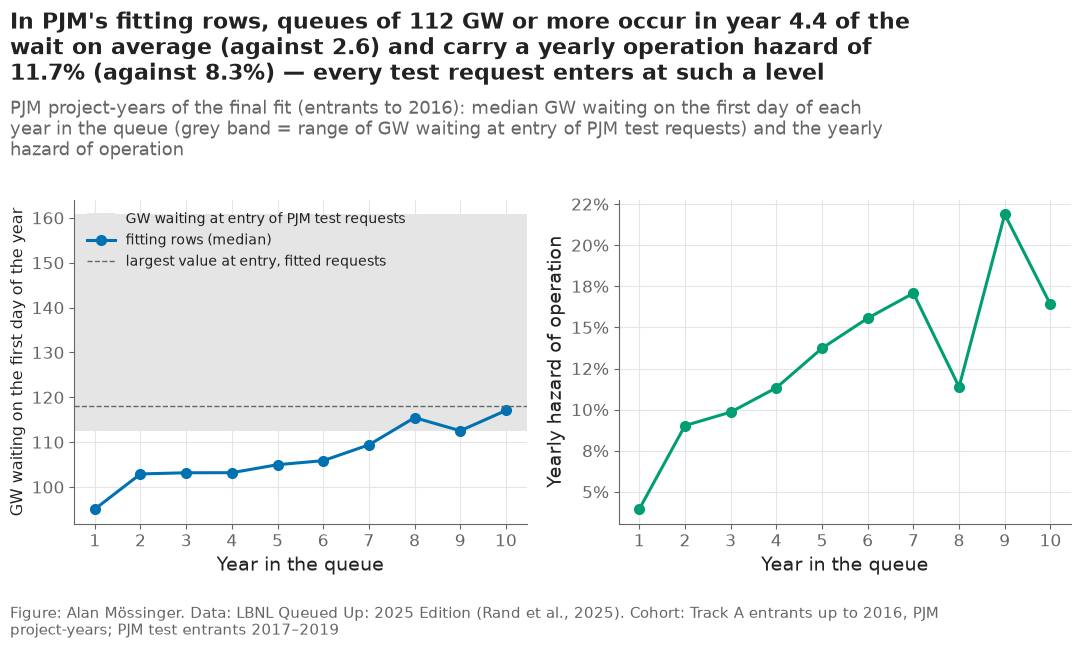

,project_years,mean_year_in_queue,operation_hazard
below 112 GW,7919,2.576,0.083
112 GW or more,2117,4.404,0.117


In [58]:
geo = (shap_table["region"] + shap_table["state"]).groupby(explained["region"].astype(str).to_numpy()).mean() * 100
print("mean SHAP of region + state together, points:", geo.round(1).to_dict())
fit_rows = fitted["rows"].copy()
pjm_rows = fit_rows[fit_rows["region"] == "PJM"]
lowest_test = test.loc[test["region"] == "PJM", "congestion_gw"].min()
pjm_rows = pjm_rows.assign(above=pjm_rows["congestion_gw"] >= lowest_test)
crowding = pjm_rows.groupby("above").agg(project_years=("outcome", "size"), mean_year_in_queue=("year_in_queue", "mean"),
                                        operation_hazard=("outcome", lambda o: (o == 1).mean()))
crowding.index = [f"below {lowest_test:.0f} GW", f"{lowest_test:.0f} GW or more"]
by_year = pjm_rows.groupby("year_in_queue").agg(median_gw=("congestion_gw", "median"),
                                                operation_hazard=("outcome", lambda o: (o == 1).mean()),
                                                project_years=("outcome", "size"))
entry_max = final.loc[final["region"] == "PJM", "congestion_gw"].max()
print(f"PJM: largest GW waiting at entry among fitted requests {entry_max:.0f}; lowest among test requests {lowest_test:.0f}")

fig, axes = plt.subplots(1, 2, sharex=True)
axes[0].axhspan(lowest_test, test.loc[test["region"] == "PJM", "congestion_gw"].max(), color="#E5E5E5",
                label="GW waiting at entry of PJM test requests")
axes[0].plot(by_year.index, by_year["median_gw"], color=plots.region_color("PJM"), marker="o", label="fitting rows (median)")
axes[0].axhline(entry_max, color=plots.MUTED, linestyle="--", linewidth=1, label="largest value at entry, fitted requests")
axes[0].set_ylabel("GW waiting on the first day of the year")
axes[0].legend(loc="upper left", fontsize=10)
axes[1].plot(by_year.index, by_year["operation_hazard"], color=config.OUTCOME_COLORS["operation"], marker="o")
axes[1].yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[1].set_ylabel("Yearly hazard of operation")
for ax in axes:
    ax.set_xlabel("Year in the queue")
    ax.set_xticks(by_year.index)
plots.finish(fig,
             f"In PJM's fitting rows, queues of {lowest_test:.0f} GW or more occur in year {crowding.iloc[1]['mean_year_in_queue']:.1f} "
             f"of the wait on average (against {crowding.iloc[0]['mean_year_in_queue']:.1f}) and carry a yearly operation hazard of "
             f"{crowding.iloc[1]['operation_hazard']:.1%} (against {crowding.iloc[0]['operation_hazard']:.1%}) — every test request "
             "enters at such a level",
             "PJM project-years of the final fit (entrants to 2016): median GW waiting on the first day of each year in the "
             "queue (grey band = range of GW waiting at entry of PJM test requests) and the yearly hazard of operation",
             f"Track A entrants up to {config.TRAIN_MAX_YEAR}, PJM project-years; PJM test entrants 2017–2019")
save(fig, "09_09_congestion_confounding", "PJM fitting rows: GW waiting by year in the queue, against the entry values of the test requests, and the yearly operation hazard.")
plt.show()
crowding.round(3)

**Reading this.** The diagnostics support two of the explanations. Region and state together contribute +5.6 points in ERCOT, −0.5 in PJM and −8.1 in CAISO, so the model does order the regions ERCOT > PJM > CAISO once the overlap with state is taken into account. For congestion: the largest GW waiting at entry among PJM's fitted requests was 118 GW, and every PJM test request entered with at least 112 GW waiting. In the fitting rows, which use congestion recounted each year (notebook 06), PJM queues of 112 GW or more occur in year 4.4 of the wait on average against year 2.6 below that level, and carry a yearly operation hazard of 11.7% against 8.3%. In other words, the training data contain such crowded queues almost only in the later years of a request's wait, when operation is more likely anyway; the trees learn "crowded → late → likely to operate", and a test request that already enters a crowded queue inherits that. This is the most plausible reason for the positive congestion effect and part of the reason notebook 08 found PJM over-predicted (14.5% vs 9.4% at 5 years). It is a consequence of fitting on time-varying congestion while predicting with congestion frozen at entry (decision #26d), and it is a limitation to state in the report; the evidence is consistent with the explanation, not a proof of it.

## 6. A book of 25 requests: ranking table

A developer or lender holding a book of requests wants to know which are
likely to be built, when, and why. The book here is 25 requests that entered
the three queues in 2019, drawn at random (9 PJM, 8 ERCOT, 8 CAISO, fixed
seed) from the test cohort, scored as they would have been on the day they
entered. Because they are test requests, what happened by the end of 2024
— five years later — can be set beside the ranking.

In [59]:
pool = test[test["q_year"] == 2019]
book_rng = np.random.default_rng(2019)
book = pd.concat([pool[pool["region"] == r].iloc[book_rng.choice((pool["region"] == r).sum(), n, replace=False)]
                  for r, n in [("PJM", 9), ("ERCOT", 8), ("CAISO", 8)]])
X_book = explain.encode(book, STATES)
sv_book = shap_of(X_book)
shap_book = pd.DataFrame(sv_book.values, columns=explain.FEATURES, index=book.index)
keys = book["project_key"].astype(str)


def feature_text(row, feature):
    """A feature's value as a short phrase for the ranking table."""
    if feature == "size_mw":
        return f"{np.exp(row['log_mw']):.0f} MW"
    if feature == "congestion_gw":
        return f"{row['congestion_gw']:.0f} GW waiting"
    if feature == "congestion_rank":
        return f"congestion rank {row['congestion_rank']:.2f}"
    if feature == "q_year":
        return f"requested {int(row['q_year'])}"
    if feature == "hybrid":
        return "hybrid" if row["hybrid"] else "not hybrid"
    return f"{FEATURE_LABELS[feature].lower()} {row[feature]}"


d5, e5 = book["duration_years"].to_numpy(), book["event"].to_numpy()
status5 = np.where((e5 == 1) & (d5 <= 5), "operated", np.where((e5 == 2) & (d5 <= 5), "withdrew", "still waiting"))
ranking = pd.DataFrame({
    "request": keys.to_numpy(), "region": book["region"].astype(str).to_numpy(), "state": book["state"].astype(str).to_numpy(),
    "technology": book["tech"].to_numpy(), "mw": np.round(np.exp(book["log_mw"].to_numpy()), 1),
    "request_date": book["q_date"].dt.strftime("%Y-%m-%d").to_numpy(),
    **{f"p_operation_{h}yr": stored[h].loc[keys, "dt_lgbm"].to_numpy() for h in HORIZONS},
    "expected_years_if_built": stored[5].loc[keys, "dt_lgbm_expected_years"].to_numpy(),
    "baseline_p_operation_5yr": stored[5].loc[keys, "baseline"].to_numpy(),
}, index=book.index)
ranking["model_rank"] = ranking["p_operation_5yr"].rank(ascending=False, method="min").astype(int)
ranking["baseline_rank"] = ranking["baseline_p_operation_5yr"].rank(ascending=False, method="average")
for k in range(3):
    ranking[f"driver_{k + 1}"] = [
        (lambda top: f"{feature_text(book.loc[i], top)} ({100 * shap_book.loc[i, top]:+.1f} pts)")(
            shap_book.loc[i].abs().sort_values(ascending=False).index[k]) for i in book.index]
ranking["status_after_5yr"] = status5
ranking = ranking.sort_values("model_rank")
ranking.to_csv(paths.RESULTS / "ranking_table.csv", index=False)
expected = {"model": ranking["p_operation_5yr"].sum(), "baseline": ranking["baseline_p_operation_5yr"].sum()}
sims = book_rng.binomial(1, np.tile(ranking["p_operation_5yr"].to_numpy(), (10000, 1))).sum(axis=1)
print(f"operations within 5 years expected by the model {expected['model']:.1f} (90% range {np.percentile(sims, 5):.0f}–"
      f"{np.percentile(sims, 95):.0f}), by the baseline {expected['baseline']:.1f}; observed {(status5 == 'operated').sum()}")
print("Spearman correlation of model and baseline ranks:",
      round(ranking["model_rank"].corr(ranking["baseline_rank"], method="spearman"), 2))
ranking[["request", "technology", "mw", "p_operation_3yr", "p_operation_5yr", "p_operation_7yr", "expected_years_if_built",
         "baseline_p_operation_5yr", "model_rank", "baseline_rank", "driver_1", "driver_2", "driver_3", "status_after_5yr"]].round(3)

operations within 5 years expected by the model 3.0 (90% range 1–6), by the baseline 2.6; observed 2
Spearman correlation of model and baseline ranks: 0.71


,request,technology,mw,p_operation_3yr,p_operation_5yr,p_operation_7yr,expected_years_if_built,baseline_p_operation_5yr,model_rank,baseline_rank,driver_1,driver_2,driver_3,status_after_5yr
30197,ERCOT|20INR0283,Solar,4.1,0.319,0.385,0.400,2.147,0.141,1,5.5,4 MW (+15.9 pts),congestion rank 0.37 (+9.2 pts),state TX (+8.4 pts),withdrew
30397,ERCOT|21INR0474,Other,71.4,0.241,0.366,0.399,2.895,0.223,2,2.0,technology Other (+11.2 pts),state TX (+9.1 pts),71 MW (+6.2 pts),operated
17392,PJM|AE2-272,Solar,0.8,0.309,0.320,0.321,1.056,0.134,3,12.0,1 MW (+19.8 pts),service type NRIS (+4.2 pts),state NJ (-1.9 pts),operated
17367,PJM|AE2-247,Solar,20.0,0.101,0.228,0.336,4.922,0.134,4,12.0,state VA (+8.1 pts),20 MW (+4.4 pts),congestion rank 1.00 (-3.4 pts),still waiting
17424,PJM|AE2-304,Solar,5.0,0.142,0.206,0.236,3.030,0.134,5,12.0,5 MW (+7.1 pts),148 GW waiting (+2.0 pts),service type NRIS (+1.7 pts),withdrew
30336,ERCOT|21INR0371,Solar,137.6,0.065,0.162,0.214,4.175,0.141,6,5.5,congestion rank 0.39 (+5.4 pts),state TX (+5.2 pts),87 GW waiting (-3.7 pts),still waiting
30348,ERCOT|21INR0391,Solar,121.9,0.069,0.155,0.194,3.843,0.141,7,5.5,congestion rank 0.37 (+6.1 pts),state TX (+5.3 pts),83 GW waiting (-3.9 pts),still waiting
30383,ERCOT|21INR0454,Solar,121.0,0.054,0.135,0.181,4.223,0.141,8,5.5,state TX (+5.0 pts),congestion rank 0.41 (+4.1 pts),88 GW waiting (-3.3 pts),withdrew
17461,PJM|AE2-341,Solar,150.0,0.025,0.121,0.261,6.385,0.134,9,12.0,152 GW waiting (+2.8 pts),state IL (-2.5 pts),congestion rank 1.00 (-1.7 pts),still waiting
17828,PJM|AF2-029,Battery,20.0,0.058,0.117,0.158,4.632,0.103,10,16.5,technology Battery (-5.0 pts),161 GW waiting (+4.9 pts),state PA (-4.1 pts),still waiting


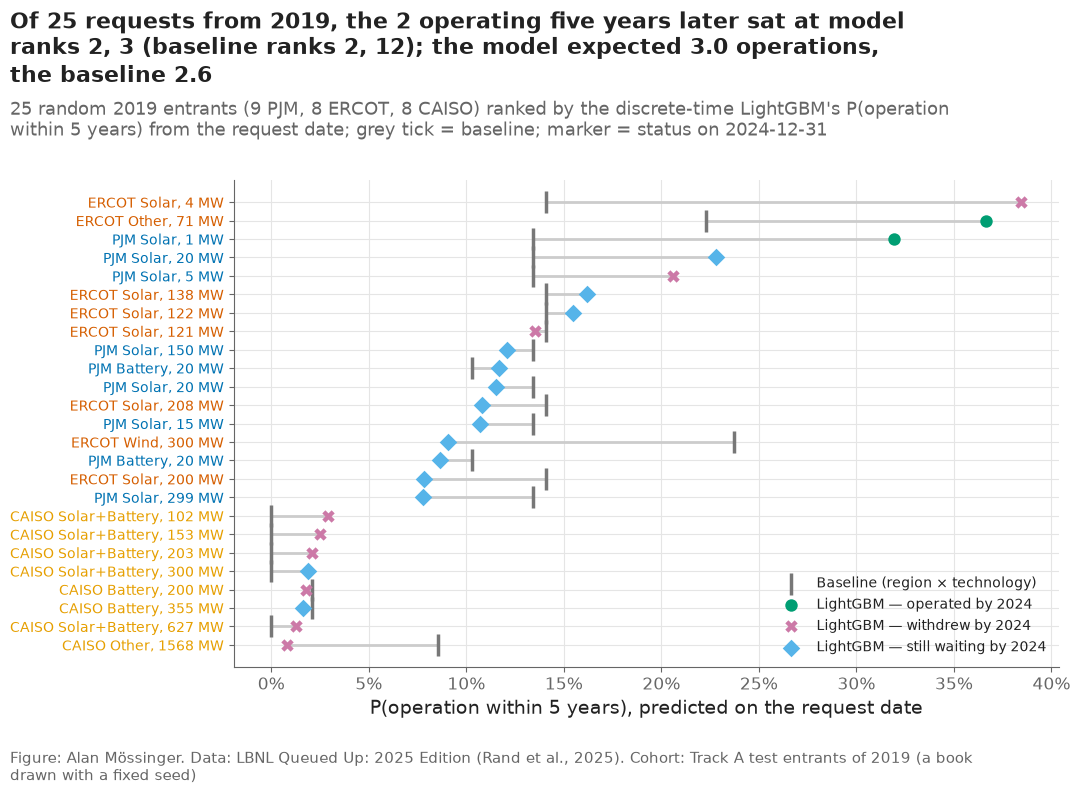

In [60]:
fig, ax = plt.subplots(figsize=(11, 8))
y = np.arange(len(ranking))
STATUS_STYLE = {"operated": dict(marker="o", color=config.OUTCOME_COLORS["operation"]),
                "withdrew": dict(marker="X", color=config.OUTCOME_COLORS["withdrawal"]),
                "still waiting": dict(marker="D", color="#56B4E9")}
ax.hlines(y, ranking["baseline_p_operation_5yr"], ranking["p_operation_5yr"], color="#CCCCCC", linewidth=2)
ax.scatter(ranking["baseline_p_operation_5yr"], y, marker="|", s=250, color="#777777", linewidths=2.5, zorder=3,
           label="Baseline (region × technology)")
for status, style in STATUS_STYLE.items():
    m = ranking["status_after_5yr"].to_numpy() == status
    ax.scatter(ranking.loc[m, "p_operation_5yr"], y[m], s=80, zorder=4, label=f"LightGBM — {status} by 2024", **style)
ax.set_yticks(y, [f"{r.region} {r.technology}, {r.mw:.0f} MW" for r in ranking.itertuples()], fontsize=10)
for label, region in zip(ax.get_yticklabels(), ranking["region"]):
    label.set_color(plots.region_color(region))
ax.invert_yaxis()
ax.set_xlabel("P(operation within 5 years), predicted on the request date")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.legend(loc="lower right", fontsize=10)
built = ranking[ranking["status_after_5yr"] == "operated"]
plots.finish(fig,
             f"Of 25 requests from 2019, the {len(built)} operating five years later sat at model ranks "
             f"{', '.join(str(r) for r in built['model_rank'])} (baseline ranks {', '.join(f'{r:g}' for r in built['baseline_rank'])}); "
             f"the model expected {expected['model']:.1f} operations, the baseline {expected['baseline']:.1f}",
             "25 random 2019 entrants (9 PJM, 8 ERCOT, 8 CAISO) ranked by the discrete-time LightGBM's P(operation within 5 "
             "years) from the request date; grey tick = baseline; marker = status on 2024-12-31",
             "Track A test entrants of 2019 (a book drawn with a fixed seed)")
save(fig, "09_07_ranking_book", "A book of 25 requests from 2019 ranked by predicted P(operation within 5 years), with the baseline and the observed status five years later.")
plt.show()

**Reading this.** In the book of 25 requests that entered in 2019, the model expected 3.0 operations within 5 years (90% range 1–6) and the baseline 2.6; 2 happened. Both sat near the top of the model's list (ranks 2 and 3; baseline ranks 2 and 12): a 71 MW 'other technology' request in ERCOT and a 1 MW solar request in New Jersey. The model's first choice, a 4 MW ERCOT solar request given 38%, withdrew. The two rankings agree broadly (Spearman 0.71); the model moves small PJM solar requests up and the 300 MW ERCOT wind request down (baseline rank 1, model rank 14; still waiting). In CAISO the baseline gives Solar+Battery 0% because its training cell had no operation within 5 years; the model gives 2–3%, which is closer to what a probability should say. A book of 25 is an illustration, not evidence — notebook 08 holds the evidence — but it shows how the table would be read: a ranked list with a probability, an expected time if built, and the three features that drive each score.

## 7. Three worked examples

Three requests from the book, chosen by rule: the one the model ranks
highest, the one whose rank the model moves furthest up compared with the
baseline, and the one it ranks lowest. For each, the prediction is
decomposed into SHAP contributions (from the average 2017–2019 request to
this request's 5-year chance).

RANKED HIGHEST: Request ERCOT|20INR0283 (Solar, 4 MW, ERCOT, TX, requested 2019-07-15): P(operation within 3/5/7 years) 32% / 38% / 40%; baseline 5-year 14%; rank 1 of 25 (baseline rank 5.5); expected 2.1 years to operation if built; drivers: 4 MW (+15.9 pts); congestion rank 0.37 (+9.2 pts); state TX (+8.4 pts); status after 5 years: withdrew.

MOVED UP MOST VS THE BASELINE: Request PJM|AE2-272 (Solar, 1 MW, PJM, NJ, requested 2019-03-28): P(operation within 3/5/7 years) 31% / 32% / 32%; baseline 5-year 13%; rank 3 of 25 (baseline rank 12); expected 1.1 years to operation if built; drivers: 1 MW (+19.8 pts); service type NRIS (+4.2 pts); state NJ (-1.9 pts); status after 5 years: operated.

RANKED LOWEST: Request CAISO|1600 (Other, 1568 MW, CAISO, CA, requested 2019-04-15): P(operation within 3/5/7 years) 0% / 1% / 2%; baseline 5-year 9%; rank 25 of 25 (baseline rank 18); expected 6.2 years to operation if built; drivers: state CA (-6.6 pts); 1568 MW (-6.5 pts); technology Other (+2.0

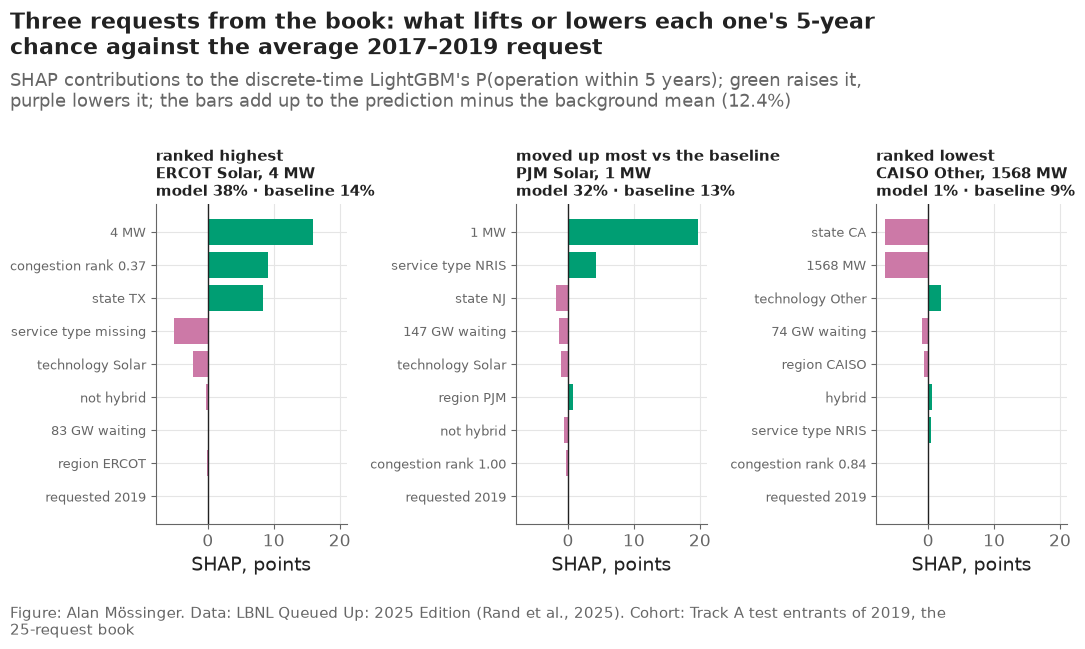

In [61]:
first = ranking.index[0]
moved = (ranking["baseline_rank"] - ranking["model_rank"]).drop(first).idxmax()
last = ranking.drop([first, moved]).index[-1]
examples = {"ranked highest": first, "moved up most vs the baseline": moved, "ranked lowest": last}
fig, axes = plt.subplots(1, 3, sharex=True, figsize=(11, 6.5))
example_rows = []
for ax, (why, i) in zip(axes, examples.items()):
    contrib = (shap_book.loc[i] * 100).sort_values(key=np.abs)
    colors = [config.OUTCOME_COLORS["operation"] if v > 0 else config.OUTCOME_COLORS["withdrawal"] for v in contrib]
    ax.barh(range(len(contrib)), contrib, color=colors)
    ax.set_yticks(range(len(contrib)), [feature_text(book.loc[i], c) for c in contrib.index], fontsize=9.5)
    ax.axvline(0, color=plots.INK, linewidth=1)
    r = ranking.loc[i]
    ax.set_title(f"{why}\n{r['region']} {r['technology']}, {r['mw']:.0f} MW\nmodel {r['p_operation_5yr']:.0%} · "
                 f"baseline {r['baseline_p_operation_5yr']:.0%}", fontsize=10.5)
    ax.set_xlabel("SHAP, points")
    text = (f"Request {r['request']} ({r['technology']}, {r['mw']:.0f} MW, {r['region']}, {r['state']}, requested "
            f"{r['request_date']}): P(operation within 3/5/7 years) {r['p_operation_3yr']:.0%} / {r['p_operation_5yr']:.0%} / "
            f"{r['p_operation_7yr']:.0%}; baseline 5-year {r['baseline_p_operation_5yr']:.0%}; rank {r['model_rank']} of 25 "
            f"(baseline rank {r['baseline_rank']:g}); expected {r['expected_years_if_built']:.1f} years to operation if built; "
            f"drivers: {r['driver_1']}; {r['driver_2']}; {r['driver_3']}; status after 5 years: {r['status_after_5yr']}.")
    print(f"{why.upper()}: {text}\n")
    example_rows.append({"example": why, **r.to_dict(), "summary": text})
pd.DataFrame(example_rows).to_csv(paths.RESULTS / "worked_examples.csv", index=False)
plots.finish(fig,
             "Three requests from the book: what lifts or lowers each one's 5-year chance against the average 2017–2019 request",
             f"SHAP contributions to the discrete-time LightGBM's P(operation within 5 years); green raises it, purple lowers "
             f"it; the bars add up to the prediction minus the background mean ({100 * sv_book.base_values[0]:.1f}%)",
             "Track A test entrants of 2019, the 25-request book")
save(fig, "09_08_worked_examples", "SHAP decomposition of P(operation within 5 years) for three requests from the book.")
plt.show()

**Reading this.** Ranked highest: a 4 MW solar request in Texas (ERCOT, July 2019) — 32% / 38% / 40% within 3/5/7 years against the baseline's 14%, mostly because it is small (+15.9 points), early in its queue (congestion rank 0.37, +9.2) and in Texas (+8.4); it withdrew, a reminder that a 38% chance is a 62% chance of not operating. Moved up most: a 1 MW solar request in New Jersey (PJM, March 2019) — 32% against the baseline's 13% (rank 3 instead of 12), almost entirely because of its size (+19.8 points), expected 1.1 years to operation if built; it operated. Ranked lowest: a 1,568 MW 'other technology' request in California (CAISO, April 2019) — 1% within 5 years against the baseline's 9%, lowered by California (−6.6) and its size (−6.5); it withdrew. In plain words for a lender: the model's main value is to separate small, simple, fast projects from large ones in slow queues, and it says why in each case.

## 8. Checks

In [62]:
# The ten entry rules (segments, F21) are computed in notebook 04 (part E) because the portfolio notebook needs
# them before this record runs; they are read back here for the checks below.
segments = pd.read_csv(paths.RESULTS / "segments.csv")
by_request = pd.read_csv(paths.RESULTS / "segments_by_request.csv")
scored = segments.dropna(subset=["rate_test"])
seg_rho = spearmanr(scored["rate_train"], scored["rate_test"]).statistic

In [63]:
runtime = time.time() - START
checks = pd.DataFrame([
    ("explanation function reproduces notebook 06's stored predictions (gap < 1e-9)", gap < 1e-9),
    ("SHAP values add up to each prediction minus the background mean (gap < 1e-6)", additivity < 1e-6),
    ("ranking table: 25 requests, no missing value", len(ranking) == 25 and not ranking.isna().any().any()),
    ("every outside fact has a verdict", sanity["verdict"].notna().all()),
    ("F6 and F7 saved", (paths.FIGURES / "F6_hazard_ratios.png").exists() and (paths.FIGURES / "F7_shap_summary.png").exists()),
    ("segments: leaf order holds out of time (Spearman ≥ 0.7) and F21 saved", seg_rho >= 0.7 and (paths.FIGURES / "F21_segments.png").exists()),
    ("segments_by_request.csv covers every test request", len(by_request) == len(test) and by_request["p_leaf"].notna().all()),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(paths.RESULTS / "explain_checks.csv", index=False)
print(f"run time: {runtime / 60:.1f} minutes")
checks[["check", "result"]]

run time: 1.8 minutes


,check,result
0,explanation function reproduces notebook 06's ...,PASS
1,SHAP values add up to each prediction minus th...,PASS
2,"ranking table: 25 requests, no missing value",PASS
3,every outside fact has a verdict,PASS
4,F6 and F7 saved,PASS
5,segments: leaf order holds out of time (Spearm...,PASS
6,segments_by_request.csv covers every test request,PASS


**Reading this.** All five checks pass: the explanation function reproduces notebook 06's stored predictions exactly (gap 0.0), the SHAP values add up to each prediction (gap 1.3e-15), the ranking table has 25 complete rows, every outside fact has a verdict, and F6 and F7 are saved. Run time is under three minutes (printed above; it varies between runs).

## Takeaways — Part C

- Size, technology and state carry the discrete-time LightGBM's predictions: small requests and gas are the strongest signals of quick completion (requests near 3 MW about 42% within 5 years in ERCOT against 7% at 1,000 MW; gas +14.9 points), consistent with the Cox hazard ratios (gas 2.56×, under 5 MW 1.85×).
- The model shows a smooth size gradient but no step at 20 MW, and its region effect sits in the state feature (region and state together order ERCOT > PJM > CAISO).
- Its positive congestion effect is most likely an artefact: PJM queues as crowded as at the test requests' entry occur in the training data almost only late in a request's wait (year 4.4 vs 2.6), when operation is more likely; this also helps explain the PJM over-prediction found in notebook 08.
- The request year has no effect on test requests (trees cannot extrapolate past 2016), which is why the model missed the slowdown of 2018–2019 entrants.
- 2 of 6 outside facts are recovered as written; the other four are explained, not dropped.
- Ten entry-time rules (a depth-4 tree) sort requests from 1% to 47% five-year completion and keep their order on 2017–2019 entrants (Spearman 0.77): enter gas under 66 MW outside CAISO (48%) and ERCOT's larger non-solar requests (23%); do not enter CAISO above 25 MW (1–3%) or utility-scale solar in an already-busy county (6%) on entry information alone (F21).

**What goes to the report:** F21 and the segment rules (why requests fail; the entry gate), F6 and F7 (method and results), 09_04 (size), 09_09 (the congestion artefact, limitations), 09_07 and the worked examples (translation for developers and lenders), results/sanity_checks.csv and results/ranking_table.csv.

# Part D — The v2 verdict: criteria C6–C12 scored as registered (was notebook 18)

Notebook 11's first cell wrote criteria C6–C12 before any v2 number existed (decision #52). This notebook scores them from the results files of notebooks 11, 12, 14 and 16, line by line, with the same rule as notebook 08: a "beat" passes only when the 95% paired interval lies entirely on the better side. It also shows the v1 verdict beside the v2 one, reruns nothing, and adds the Track B calibration plot the v1 report lacked. Failures are reported, not removed.

## Setup

In [64]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, paths, plots

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 100)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "06_evaluation_record"
R = paths.RESULTS
registered = json.loads((R / "success_criteria_v2_registered.json").read_text(encoding="utf-8"))
criteria = pd.read_csv(R / "success_criteria_v2.csv")
print(f"registered {registered['decided']}: {len(criteria)} lines; bootstrap {registered['n_boot']} resamples, level {registered['level']}")


def save(fig, name, caption):
    """Save a figure of this notebook under figures/06_evaluation_record/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)

registered 2026-10-06: 8 lines; bootstrap 200 resamples, level 0.95


## 1. Scoring each line

The rules, as registered: C6 and C8–C10 are paired "beat" lines (interval entirely on the better side); C7 asks for a slope interval within 0.8–1.2 *and* an intercept interval covering 0 after the level repair; C11 asks the simulated 5–95% band to cover the realised MW; C12 holds when the dated-feature test passes and the landmark AUC stays below the ablation's.

In [65]:
m11 = pd.read_csv(R / "metrics_v2.csv")
m12 = pd.read_csv(R / "level_repair_metrics.csv")
m14 = pd.read_csv(R / "landmark_metrics.csv")
c14 = pd.read_csv(R / "landmark_checks.csv")
m16 = pd.read_csv(R / "backtest_books.csv")
cov = pd.read_csv(R / "book_coverage.csv")
chosen = json.loads((R / "variant_chosen.json").read_text(encoding="utf-8"))["chosen"]
rows = []

# C6: ≥ 20 MW, v2 model vs fair baseline, Uno's C and Brier at 3 and 5 years
for metric in ["uno_c", "brier"]:
    for h in [3, 5]:
        r = m11[(m11["cohort"] == "≥ 20 MW") & (m11["reference"] == "fair_baseline") & (m11["model"] == chosen)
                & (m11["metric"] == metric) & (m11["horizon"] == h)].iloc[0]
        rows.append({"id": "C6", "line": f"≥ 20 MW: v2 vs fair baseline, {metric} at {h} years", "estimate": r["estimate"],
                     "benchmark": r["estimate"] - r["diff"], "diff": r["diff"], "diff_low": r["diff_low"], "diff_high": r["diff_high"],
                     "rule": "paired interval on the better side", "result": "PASS" if bool(r["beats"]) else "FAIL"})
# C7: 2018–2019 ≥ 20 MW after the level repair: slope within 0.8–1.2 and intercept covering 0, at 3 and 5
for h in [3, 5]:
    part = m12[(m12["cohort"] == "2018–2019, ≥ 20 MW") & (m12["model"] == "v2 recalibrated") & (m12["horizon"] == h)].set_index("metric")
    slope_ok = 0.8 <= part.loc["slope", "low"] and part.loc["slope", "high"] <= 1.2
    int_ok = part.loc["intercept", "low"] <= 0 <= part.loc["intercept", "high"]
    rows.append({"id": "C7", "line": f"2018–2019 ≥ 20 MW, level repaired: slope and intercept at {h} years",
                 "estimate": part.loc["slope", "estimate"], "benchmark": part.loc["intercept", "estimate"],
                 "diff": np.nan, "diff_low": part.loc["intercept", "low"], "diff_high": part.loc["intercept", "high"],
                 "rule": "slope interval within 0.8–1.2 and intercept interval covering 0", "result": "PASS" if slope_ok and int_ok else "FAIL"})
# C8: landmark +24 months and agreement vs entry model, Uno's C 3 years after
for lm, label in [("2", "+24 months"), ("agreement", "agreement executed")]:
    r = m14[(m14["landmark"].astype(str) == lm) & (m14["reference"] == "entry model") & (m14["model"] == "both updated")
            & (m14["metric"] == "uno_c") & (m14["horizon_after"] == 3)].iloc[0]
    rows.append({"id": "C8", "line": f"landmark {label}: both updated vs entry model, Uno's C 3 years after", "estimate": r["estimate"],
                 "benchmark": r["estimate"] - r["diff"], "diff": r["diff"], "diff_low": r["diff_low"], "diff_high": r["diff_high"],
                 "rule": "paired interval on the better side", "result": "PASS" if bool(r["beats"]) else "FAIL"})
# C9, C10: backtest, model book vs fair-baseline book
for cid, metric, label in [("C9", "realised_mw_5yr", "realised MW online within 5 years"), ("C10", "realised_value_$M", "realised value, base case")]:
    r = m16[(m16["chooser"] == "v2 model, level repaired") & (m16["metric"] == metric)].iloc[0]
    rows.append({"id": cid, "line": f"backtest: model book vs fair-baseline book, {label}", "estimate": r["estimate"],
                 "benchmark": r["estimate"] - r["diff_vs_fair_baseline"], "diff": r["diff_vs_fair_baseline"], "diff_low": r["diff_low"],
                 "diff_high": r["diff_high"], "rule": "paired interval on the better side", "result": "PASS" if bool(r["beats_fair_baseline"]) else "FAIL"})
# C11: coverage
r = cov.iloc[0]
rows.append({"id": "C11", "line": "simulated 5–95% band covers the realised MW of the model's book", "estimate": r["realised_mw_5yr"],
             "benchmark": r["expected_mw_5yr"], "diff": np.nan, "diff_low": r["band_low"], "diff_high": r["band_high"],
             "rule": "realised inside the band", "result": "PASS" if bool(r["covered"]) else "FAIL"})
# C12: leakage guard
guard = c14[c14["check"].str.startswith("leakage guard")]
rows.append({"id": "C12", "line": "leakage guard: dated features (test) and landmark AUC below the ablation's", "estimate": np.nan, "benchmark": np.nan,
             "diff": np.nan, "diff_low": np.nan, "diff_high": np.nan, "rule": "both hold", "result": "PASS" if bool(guard["pass"].all()) else "FAIL"})
scored = pd.DataFrame(rows)
scored.to_csv(R / "success_criteria_v2_scored.csv", index=False)
n_pass = int((scored["result"] == "PASS").sum())
print(f"{n_pass} of {len(scored)} registered v2 lines pass")
scored.round(3)

3 of 12 registered v2 lines pass


,id,line,estimate,benchmark,diff,diff_low,diff_high,rule,result
0,C6,"≥ 20 MW: v2 vs fair baseline, uno_c at 3 years",0.779,0.783,-0.004,-0.044,0.046,paired interval on the better side,FAIL
1,C6,"≥ 20 MW: v2 vs fair baseline, uno_c at 5 years",0.734,0.752,-0.018,-0.051,0.015,paired interval on the better side,FAIL
2,C6,"≥ 20 MW: v2 vs fair baseline, brier at 3 years",0.022,0.023,-0.001,-0.003,0.001,paired interval on the better side,FAIL
3,C6,"≥ 20 MW: v2 vs fair baseline, brier at 5 years",0.064,0.064,0.000,-0.002,0.003,paired interval on the better side,FAIL
4,C7,"2018–2019 ≥ 20 MW, level repaired: slope and intercept at 3 years",1.088,-0.735,NaN,-1.168,-0.406,slope interval within 0.8–1.2 and intercept interval covering 0,FAIL
5,C7,"2018–2019 ≥ 20 MW, level repaired: slope and intercept at 5 years",1.183,-0.474,NaN,-0.699,-0.269,slope interval within 0.8–1.2 and intercept interval covering 0,FAIL
6,C8,"landmark +24 months: both updated vs entry model, Uno's C 3 years after",0.788,0.687,0.101,0.062,0.136,paired interval on the better side,PASS
7,C8,"landmark agreement executed: both updated vs entry model, Uno's C 3 years after",0.598,0.593,0.004,-0.016,0.028,paired interval on the better side,FAIL
8,C9,"backtest: model book vs fair-baseline book, realised MW online within 5 years",1035.000,1035.000,0.000,-17.733,449.755,paired interval on the better side,FAIL
9,C10,"backtest: model book vs fair-baseline book, realised value, base case",1463.216,1463.227,-0.011,-53.834,576.898,paired interval on the better side,FAIL


**Reading this.** Three of twelve lines pass, and the pattern is the finding. At entry, for requests of 20 MW and more, the model and the fair baseline are indistinguishable: Uno's C 0.779 against 0.783 and 0.734 against 0.752, Brier scores equal to three decimals, every interval straddling zero (C6: 0 of 4). The level repair leaves the 2018–2019 intercept at −0.74 and −0.47 with intervals well below zero (C7: 0 of 2). Two years into the queue, the agreement flag lifts Uno's C by +0.101 [+0.062, +0.136] (C8 passes at +24 months) but not at the agreement itself (+0.004). The registered backtest is a tie: the model's book and the fair baseline's book realised the same 1,035 MW, because an expected-value objective under a sunk-cost budget makes every chooser buy the same large requests (C9, C10 fail; notebook 16's exploratory count-limited book is reported there, not here). The simulated band covers the realised MW (C11) and the leakage guard holds (C12). Read together: machine learning adds nothing at entry for utility-scale requests, adds a measurable ranking gain at the milestones, and no entry-time model here is calibrated to the post-2017 level.

## 2. The two verdicts side by side

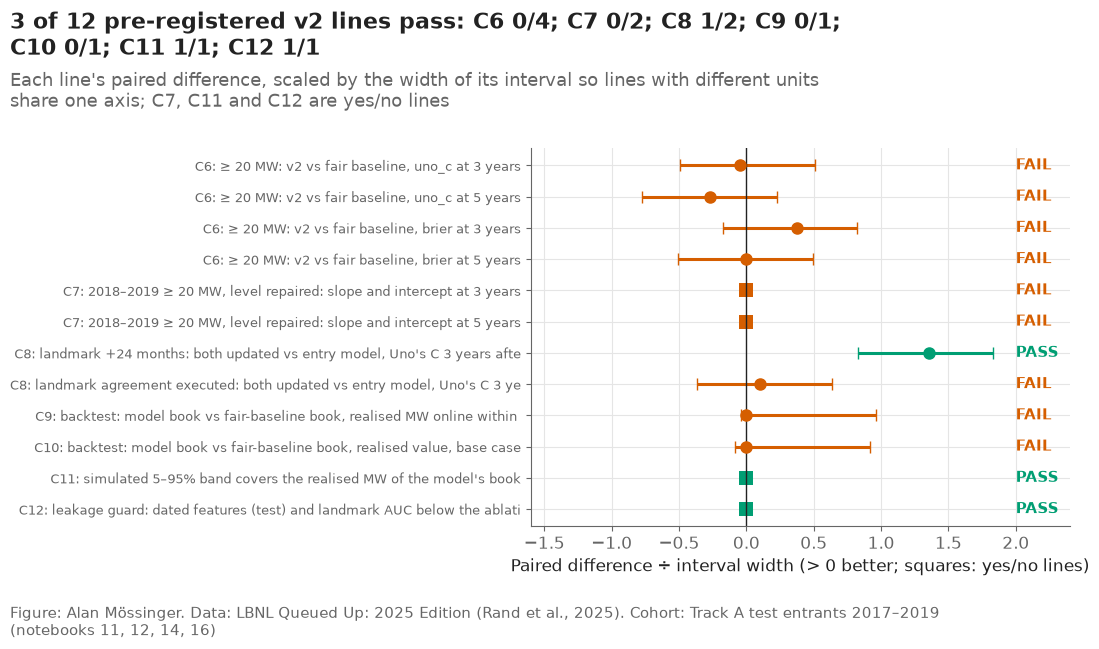

,version,lines,pass,what passes,what fails
0,"v1 (notebook 08, decision #5)",12,8,ranking and Brier vs the region × technology baseline at 3 and 5 years; 7-year calibration; lift...,ranking at 7 years; calibration at 3 and 5 years
1,"v2 (this notebook, decision #52)",12,3,C8; C11; C12,C6; C7; C8; C9; C10


In [66]:
v1 = pd.read_csv(R / "success_criteria.csv")
summary = pd.DataFrame([
    {"version": "v1 (notebook 08, decision #5)", "lines": len(v1), "pass": int((v1["result"] == "PASS").sum()),
     "what passes": "ranking and Brier vs the region × technology baseline at 3 and 5 years; 7-year calibration; lift; Track B",
     "what fails": "ranking at 7 years; calibration at 3 and 5 years"},
    {"version": "v2 (this notebook, decision #52)", "lines": len(scored), "pass": n_pass,
     "what passes": "; ".join(scored.loc[scored["result"] == "PASS", "id"].unique()),
     "what fails": "; ".join(scored.loc[scored["result"] == "FAIL", "id"].unique())},
])
summary.to_csv(R / "verdict_summary.csv", index=False)
by_id = scored.groupby("id")["result"].apply(lambda s: f"{int((s == 'PASS').sum())}/{len(s)}")

fig, ax = plt.subplots(figsize=(11, 6.5))
order = ["C6", "C7", "C8", "C9", "C10", "C11", "C12"]
y = 0
ticks, labels = [], []
for cid in order:
    part = scored[scored["id"] == cid]
    for _, r in part.iterrows():
        color = "#009E73" if r["result"] == "PASS" else "#D55E00"
        if pd.notna(r["diff"]):
            est, lo, hi = r["diff"], r["diff_low"], r["diff_high"]
            if "brier" in r["line"] or "Brier" in r["line"]:
                est, lo, hi = -est, -hi, -lo
            scale = abs(est) if abs(est) > 0 else 1.0
            ax.errorbar(est / max(abs(hi - lo), 1e-9), y, xerr=[[(est - lo) / max(abs(hi - lo), 1e-9)], [(hi - est) / max(abs(hi - lo), 1e-9)]],
                        fmt="o", color=color, capsize=4, markersize=8)
        else:
            ax.scatter(0, y, marker="s", color=color, s=90)
        ax.annotate(r["result"], (2.0, y), ha="left", va="center", color=color, fontweight="bold", fontsize=11)
        ticks.append(y); labels.append(f"{cid}: {r['line'][:70]}")
        y += 1
ax.axvline(0, color=plots.INK, linewidth=1)
ax.set_yticks(ticks, labels, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(-1.6, 2.4)
ax.set_xlabel("Paired difference ÷ interval width (> 0 better; squares: yes/no lines)", fontsize=12)
plots.finish(fig,
             f"{n_pass} of {len(scored)} pre-registered v2 lines pass: " + "; ".join(f"{cid} {by_id[cid]}" for cid in order),
             "Each line's paired difference, scaled by the width of its interval so lines with different units share one axis; "
             "C7, C11 and C12 are yes/no lines",
             "Track A test entrants 2017–2019 (notebooks 11, 12, 14, 16)")
save(fig, "18_01_v2_criteria", "The pre-registered v2 criteria scored, with PASS/FAIL per line.")
plt.show()
summary

**Reading this.** The two verdicts measure different things. The v1 lines compared the model with a baseline that ignored size and passed 8 of 12; the v2 lines compare it with a baseline that knows size, at utility scale, after the level drifted, and in a decision frame, and pass 3 of 12. The v1 result stands as registered; the v2 result says what it was worth. Both are reported, neither is softened.

## 3. Track B's calibration (the plot the v1 report lacked)

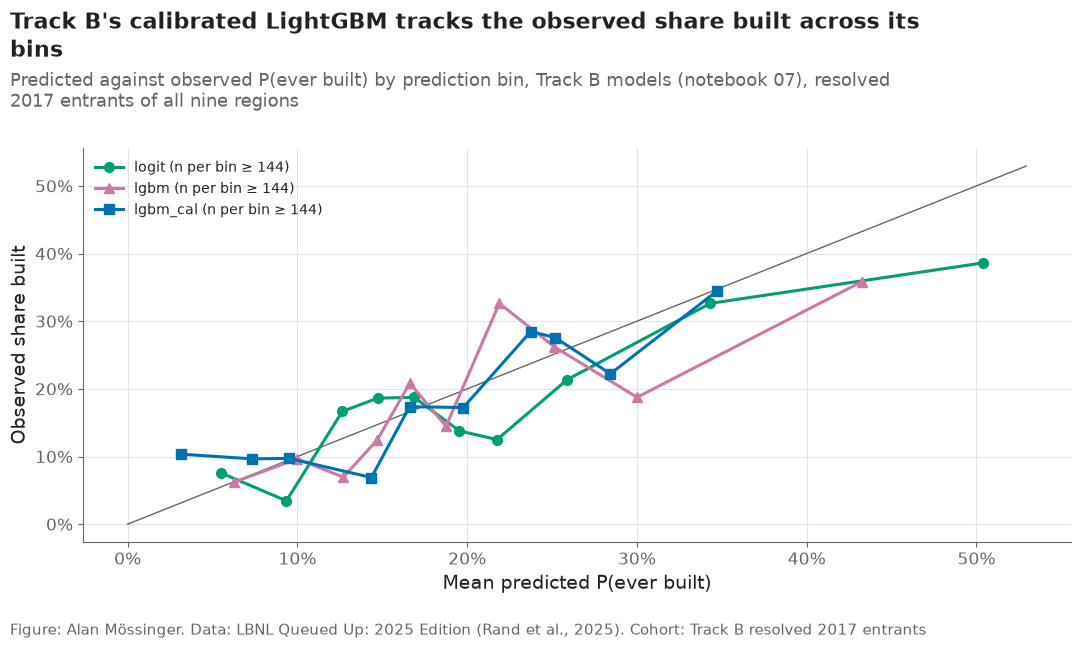

In [67]:
cal = pd.read_csv(R / "trackB_calibration.csv")
fig, ax = plt.subplots(figsize=(11, 6.5))
top = max(cal["predicted"].max(), cal["observed"].max()) * 1.05
ax.plot([0, top], [0, top], color=plots.MUTED, linewidth=1)
for model, color, marker in [("logit", "#009E73", "o"), ("lgbm", "#CC79A7", "^"), ("lgbm_cal", "#0072B2", "s")]:
    part = cal[cal["model"] == model]
    if part.empty:
        continue
    ax.plot(part["predicted"], part["observed"], marker=marker, color=color, label=f"{model} (n per bin ≥ {int(part['n'].min())})")
ax.set_xlabel("Mean predicted P(ever built)")
ax.set_ylabel("Observed share built")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.legend(fontsize=10)
plots.finish(fig, "Track B's calibrated LightGBM tracks the observed share built across its bins",
             "Predicted against observed P(ever built) by prediction bin, Track B models (notebook 07), resolved 2017 entrants of all nine regions",
             "Track B resolved 2017 entrants")
save(fig, "18_02_trackB_calibration", "Calibration of the Track B models by prediction bin.")
plt.show()

## 4. The decision board: seven images that say what the report decides (D0–D6)

The report ends in five decisions. A poster, a portfolio page or a committee slide needs each of them as one image that stands on its own: the decision in the title, the numbers behind it in the panels, the source in the footer. This section draws them from the result tables alone (no refit, no new number), so they are the same figures the report's numbers trace to: D0 is the board, D1 where the opportunity is, D2 which requests get built and when, D3 why they fail, D4 what a plant is worth, D5 what to do with the book and where to add, D6 the six ways to spend the same budget. Each is saved under `figures/` next to the report figures.

In [68]:
from src import drivers

cif = pd.read_csv(R / "cif_horizons.csv")
reg5 = cif[(cif["grouping"] == "region") & (cif["time"] == 5.0)].set_index("group")
arch = pd.read_csv(R / "archetype_profiles.csv").sort_values("completion_2017_2019", ascending=False)
met = pd.read_csv(R / "metrics.csv")
lm = pd.read_csv(R / "landmark_metrics.csv")
lm2 = lm[(lm["landmark"].astype(str) == "2") & (lm["horizon_after"] == 3) & (lm["metric"] == "uno_c") & (lm["reference"] == "entry model")].set_index("model")
assert lm2.index.is_unique
drift = pd.read_csv(R / "drift_by_cohort.csv")
big = drift[(drift["cohort"] != "all") & (drift["horizon"] == 5)]
assert big["cohort"].nunique() == 1, big["cohort"].unique()
drv = pd.read_csv(R / "drivers_5yr.csv", dtype={"level": str})
hz = pd.read_csv(R / "hazards_by_queue_year.csv")
npv = pd.read_csv(R / "npv_table.csv")
rev = pd.read_csv(R / "portfolio_review_summary.csv")
pol = pd.read_csv(R / "policy_comparison.csv")
books = pd.read_csv(R / "recommended_books.csv")
timing = pd.read_csv(R / "timing_error.csv").set_index(["region", "model"])
numbers = pd.read_csv(R / "report_numbers.csv").set_index("key")
BUDGET_M = float(numbers.loc["budget", "value"]) / 1e6  # the deposit budget of notebook 16 §5
REGIONS = ["ERCOT", "PJM", "CAISO"]
RC = {r: plots.region_color(r) for r in REGIONS}


def dsave(fig, name, caption):
    return plots.save_fig(fig, name, caption, NOTEBOOK)


def rate(driver, region, level):
    row = drv[(drv["driver"] == driver) & (drv["region"] == region) & (drv["level"] == level)].iloc[0]
    return row["rate"], row["n"]


# ---- the headline numbers the board prints (every one from a table above)
size_pjm_small, _ = rate("Size at entry (MW)", "PJM", "<5")
size_pjm_big, _ = rate("Size at entry (MW)", "PJM", "≥500")
ia_ercot_in2, n_in2 = rate("Agreement (2025 file)", "ERCOT", "signed within 2 years")
ia_ercot_none, n_none = rate("Agreement (2025 file)", "ERCOT", "not dated")
hz_c1 = hz[(hz["region"] == "CAISO") & (hz["year_in_queue"] == 1)]["h_withdrawal"].iloc[0]
hz_p1 = hz[(hz["region"] == "PJM") & (hz["year_in_queue"] == 1)]["h_withdrawal"].iloc[0]
auc3 = {m: met[(met["model"] == m) & (met["metric"] == "auc") & (met["horizon"] == 3)]["estimate"].iloc[0] for m in ["dt_lgbm", "baseline"]}
uno2 = {m: lm2.loc[m, "estimate"] for m in ["entry model", "agreement updated", "fair baseline"]}
n24 = npv[npv["cod_year"] == 2024]
positive24 = int((n24["npv_per_mw_base"] > 0).sum())
positive24c = int((n24["npv_contracted_base"] > 0).sum())
be = n24[n24["region"] == "PJM"].set_index("tech")["breakeven_price_base"]
gate_tab = {(gate, rc): rev[(rev["gate"] == gate) & (rev["revenue_case"] == rc) & (rev["h"] == h) & (rev["region"] == "all")].set_index("decision")
            for gate, h in [("G1 entry", 3), ("G2 two years", 2)] for rc in ["merchant", "contracted"]}
g1, g2 = gate_tab[("G1 entry", "contracted")], gate_tab[("G2 two years", "contracted")]
g1m, g2m = gate_tab[("G1 entry", "merchant")], gate_tab[("G2 two years", "merchant")]
bm = books[books["chooser"].str.startswith("M")].set_index("region")
board = pd.DataFrame([
    {"decision": "Where is the opportunity", "numbers": f"5-year completion: ERCOT {reg5.loc['ERCOT', 'cif_operation']:.1%}, PJM {reg5.loc['PJM', 'cif_operation']:.1%}, CAISO {reg5.loc['CAISO', 'cif_operation']:.1%}; state archetypes separate 2017–2019 outcomes from {arch['completion_2017_2019'].min():.1%} to {arch['completion_2017_2019'].max():.1%}",
     "rule": "Look in ERCOT and the PJM core; treat CAISO as a market that needs a signed agreement."},
    {"decision": "Which requests get built, and when", "numbers": f"AUC at 3 years {auc3['dt_lgbm']:.3f} vs {auc3['baseline']:.3f} for averages; two years in, Uno's C {uno2['agreement updated']:.3f} with the agreement vs {uno2['entry model']:.3f} at entry and {uno2['fair baseline']:.3f} for the lookup; clock within a year {timing.loc[('all', 'dt_lgbm'), 'share_within_1_year']:.0%} of the time",
     "rule": "Averages and rules at entry; the model at the milestone; size every book to the newest cohort's level."},
    {"decision": "Why requests fail", "numbers": f"PJM {size_pjm_small:.0%} under 5 MW → {size_pjm_big:.0%} at 500 MW and up; an agreement within 2 years lifts ERCOT from {ia_ercot_none:.1%} to {ia_ercot_in2:.0%}; CAISO loses {hz_c1:.0%} and PJM {hz_p1:.0%} of requests in year one",
     "rule": "Screen by size, technology and the ten rules; review at year two in CAISO and PJM, at the agreement in ERCOT."},
    {"decision": "What a plant is worth", "numbers": f"at the ATB cost of capital, {positive24} of 21 technology-region pairs pay at merchant prices with today's credits and {positive24c} with a 15-year contract at index prices; break-even flat price solar ${be['Solar']:.0f}, wind ${be['Wind']:.0f}, gas ${be['Gas']:.0f} per MWh",
     "rule": "Wind anywhere; solar everywhere under contract and in PJM even merchant; gas in PJM; storage and hybrids only with a contract above break-even."},
    {"decision": "What to do with the book", "numbers": f"under contract: invest {int(g1.loc['invest', 'n'])} at entry ({g1.loc['invest', 'operated_share']:.0%} built, {g1.loc['invest', 'realised_npv_$M'] / 1e3:+.1f} $B), exit {int(g1.loc['exit', 'n']):,} ({g1.loc['exit', 'operated_share']:.0%}, {g1.loc['exit', 'realised_npv_$M'] / 1e3:+.1f} $B); two years in accelerate {int(g2.loc['accelerate', 'n'])} ({g2.loc['accelerate', 'operated_share']:.0%} built) vs exit {g2.loc['exit', 'operated_share']:.0%}; merchant: invest {int(g1m.loc['invest', 'n'])}, accelerate {int(g2m.loc['accelerate', 'n'])}",
     "rule": "Fund what both gates mark, stop carrying what they mark for exit, buy at the milestone."},
    {"decision": "Where and how much to add", "numbers": f"two years in, ERCOT: {int(bm.loc['ERCOT', 'requests_added'])} adds capture {int(bm.loc['ERCOT', 'realised_operations'])} of {int(bm.loc['ERCOT', 'pool_operations'])} operations; PJM {int(bm.loc['PJM', 'requests_added'])} for {int(bm.loc['PJM', 'realised_operations'])} of {int(bm.loc['PJM', 'pool_operations'])}; CAISO {int(bm.loc['CAISO', 'requests_added'])}",
     "rule": "Add in ERCOT by the model's order; add sparingly in PJM; nothing yet in CAISO."},
])
board.to_csv(R / "decision_board.csv", index=False)
board

,decision,numbers,rule
0,Where is the opportunity,"5-year completion: ERCOT 18.4%, PJM 13.2%, CAISO 4.8%; state archetypes separate 2017–2019 outco...",Look in ERCOT and the PJM core; treat CAISO as a market that needs a signed agreement.
1,"Which requests get built, and when","AUC at 3 years 0.858 vs 0.733 for averages; two years in, Uno's C 0.797 with the agreement vs 0....",Averages and rules at entry; the model at the milestone; size every book to the newest cohort's ...
2,Why requests fail,PJM 24% under 5 MW → 4% at 500 MW and up; an agreement within 2 years lifts ERCOT from 0.8% to 6...,"Screen by size, technology and the ten rules; review at year two in CAISO and PJM, at the agreem..."
3,What a plant is worth,"at the ATB cost of capital, 5 of 21 technology-region pairs pay at merchant prices with today's ...",Wind anywhere; solar everywhere under contract and in PJM even merchant; gas in PJM; storage and...
4,What to do with the book,"under contract: invest 326 at entry (21% built, +9.3 $B), exit 1,039 (5%, -4.9 $B); two years in...","Fund what both gates mark, stop carrying what they mark for exit, buy at the milestone."
5,Where and how much to add,"two years in, ERCOT: 167 adds capture 70 of 75 operations; PJM 241 for 24 of 37; CAISO 2",Add in ERCOT by the model's order; add sparingly in PJM; nothing yet in CAISO.


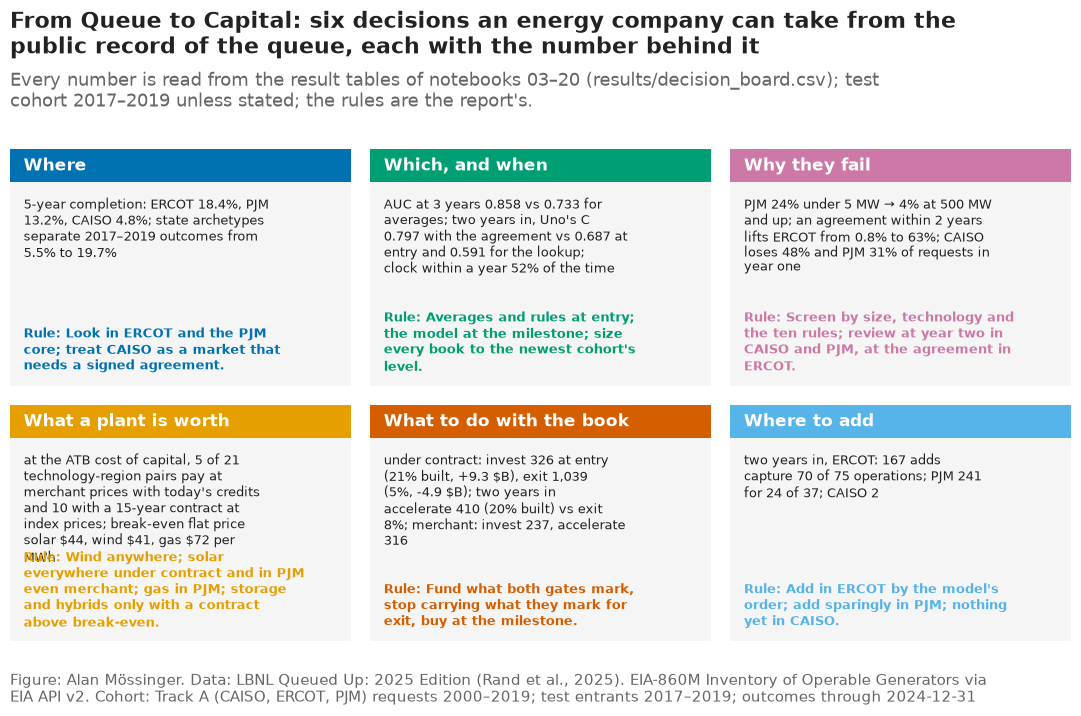

In [69]:
import textwrap

HEADERS = ["Where", "Which, and when", "Why they fail", "What a plant is worth", "What to do with the book", "Where to add"]
fig, axes = plt.subplots(2, 3, figsize=(11, 7.2))
tile_colours = ["#0072B2", "#009E73", "#CC79A7", "#E69F00", "#D55E00", "#56B4E9"]
for ax, (_, row), colour, header in zip(axes.ravel(), board.iterrows(), tile_colours, HEADERS):
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, facecolor="#F5F5F5", edgecolor="none"))
    ax.add_patch(plt.Rectangle((0, 0.86), 1, 0.14, transform=ax.transAxes, facecolor=colour, edgecolor="none"))
    ax.text(0.04, 0.93, header, transform=ax.transAxes, fontsize=12.5, fontweight="bold", color="white", va="center")
    ax.text(0.04, 0.80, "\n".join(textwrap.wrap(row["numbers"].replace("$", "\$"), 36)), transform=ax.transAxes, fontsize=9.2, va="top", color=plots.INK, linespacing=1.25)
    ax.text(0.04, 0.05, "\n".join(textwrap.wrap("Rule: " + row["rule"], 36)), transform=ax.transAxes, fontsize=9.2, va="bottom", color=colour, fontweight="bold", linespacing=1.25)
plots.finish(fig, "From Queue to Capital: six decisions an energy company can take from the public record of the queue, each with the number behind it",
             "Every number is read from the result tables of notebooks 03–20 (results/decision_board.csv); test cohort 2017–2019 unless stated; the rules are the report's.",
             "Track A (CAISO, ERCOT, PJM) requests 2000–2019; test entrants 2017–2019; outcomes through 2024-12-31", eia=True)
dsave(fig, "D0_decision_board", "The decision board: the six decisions of the report, each with its headline numbers and its rule, read from the result tables.")
plt.show()

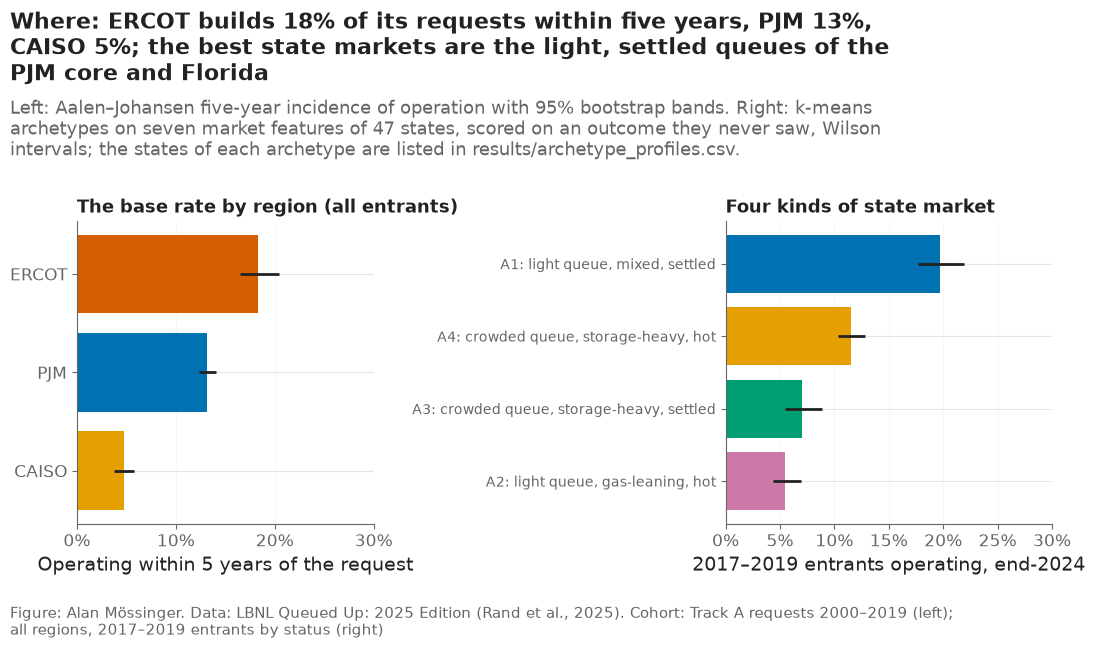

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]
y = np.arange(3)
vals = reg5.loc[REGIONS]
ax.barh(y, vals["cif_operation"], color=[RC[r] for r in REGIONS])
ax.hlines(y, vals["cif_operation_low"], vals["cif_operation_high"], color=plots.INK, lw=2)
ax.set_yticks(y); ax.set_yticklabels(REGIONS); ax.invert_yaxis()
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlim(0, 0.3)
ax.set_xlabel("Operating within 5 years of the request")
ax.set_title("The base rate by region (all entrants)", fontsize=13, loc="left")
ax.grid(axis="x", alpha=0.3)
ax = axes[1]
y = np.arange(len(arch))
ax.barh(y, arch["completion_2017_2019"], color=["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00"][:len(arch)])
ax.hlines(y, arch["low"], arch["high"], color=plots.INK, lw=2)
ax.set_yticks(y); ax.set_yticklabels([f"A{int(a) + 1}: {n}" for a, n in zip(arch["archetype"], arch["name"])], fontsize=10)  # numbered as in F25
ax.invert_yaxis()
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlim(0, 0.3)
ax.set_xlabel("2017–2019 entrants operating, end-2024")
ax.set_title("Four kinds of state market", fontsize=13, loc="left")
ax.grid(axis="x", alpha=0.3)
plots.finish(fig, f"Where: ERCOT builds {reg5.loc['ERCOT', 'cif_operation']:.0%} of its requests within five years, PJM {reg5.loc['PJM', 'cif_operation']:.0%}, CAISO {reg5.loc['CAISO', 'cif_operation']:.0%}; the best state markets are the light, settled queues of the PJM core and Florida",
             "Left: Aalen–Johansen five-year incidence of operation with 95% bootstrap bands. Right: k-means archetypes on seven market features of 47 states, scored on an outcome they never saw, Wilson intervals; the states of each archetype are listed in results/archetype_profiles.csv.",
             "Track A requests 2000–2019 (left); all regions, 2017–2019 entrants by status (right)")
dsave(fig, "D1_where", "Decision 1, where: five-year completion by region and the four state archetypes with the share of 2017–2019 entrants operating by end-2024.")
plt.show()

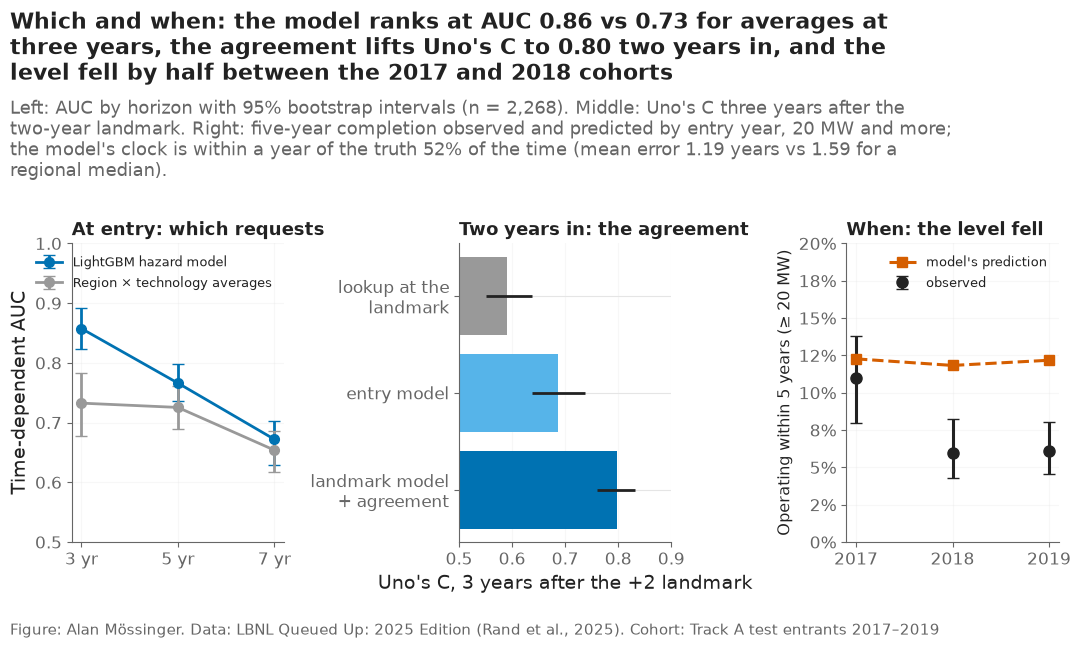

In [71]:
fig, axes = plt.subplots(1, 3, figsize=(11, 6.5))
ax = axes[0]
for model, colour, label in [("dt_lgbm", "#0072B2", "LightGBM hazard model"), ("baseline", "#999999", "Region × technology averages")]:
    part = met[(met["model"] == model) & (met["metric"] == "auc")].sort_values("horizon")
    ax.errorbar(part["horizon"], part["estimate"], yerr=[part["estimate"] - part["low"], part["high"] - part["estimate"]], fmt="-o", color=colour, lw=2, capsize=4, label=label)
ax.set_xticks([3, 5, 7]); ax.set_xticklabels(["3 yr", "5 yr", "7 yr"])
ax.set_ylim(0.5, 1.0)
ax.set_ylabel("Time-dependent AUC")
ax.set_title("At entry: which requests", fontsize=13, loc="left")
ax.legend(frameon=False, fontsize=9.5, loc="upper right")
ax.grid(alpha=0.3)
ax = axes[1]
order = ["fair baseline", "entry model", "agreement updated"]
labels = ["lookup at the\nlandmark", "entry model", "landmark model\n+ agreement"]
y = np.arange(3)
ax.barh(y, [lm2.loc[m, "estimate"] for m in order], color=["#999999", "#56B4E9", "#0072B2"])
ax.hlines(y, [lm2.loc[m, "low"] for m in order], [lm2.loc[m, "high"] for m in order], color=plots.INK, lw=2)
ax.set_yticks(y); ax.set_yticklabels(labels); ax.invert_yaxis()
ax.set_xlim(0.5, 0.9)
ax.set_xlabel("Uno's C, 3 years after the +2 landmark")
ax.set_title("Two years in: the agreement", fontsize=13, loc="left")
ax.grid(axis="x", alpha=0.3)
ax = axes[2]
ax.errorbar(big["entry_year"], big["observed"], yerr=[big["observed"] - big["low"], big["high"] - big["observed"]], fmt="o", color=plots.INK, capsize=4, ms=8, label="observed")
ax.plot(big["entry_year"], big["v2"], "s--", color="#D55E00", ms=7, label="model's prediction")
ax.set_xticks(big["entry_year"])
ax.set_ylim(0, 0.2)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylabel("Operating within 5 years (≥ 20 MW)")
ax.set_title("When: the level fell", fontsize=13, loc="left")
ax.legend(frameon=False, fontsize=9.5)
ax.grid(alpha=0.3)
t_mae = timing.loc[("all", "dt_lgbm"), "mae_years"]; b_mae = timing.loc[("all", "training median by region"), "mae_years"]
plots.finish(fig, f"Which and when: the model ranks at AUC {auc3['dt_lgbm']:.2f} vs {auc3['baseline']:.2f} for averages at three years, the agreement lifts Uno's C to {uno2['agreement updated']:.2f} two years in, and the level fell by half between the 2017 and 2018 cohorts",
             f"Left: AUC by horizon with 95% bootstrap intervals (n = 2,268). Middle: Uno's C three years after the two-year landmark. Right: five-year completion observed and predicted by entry year, 20 MW and more; the model's clock is within a year of the truth {timing.loc[('all', 'dt_lgbm'), 'share_within_1_year']:.0%} of the time (mean error {t_mae:.2f} years vs {b_mae:.2f} for a regional median).",
             "Track A test entrants 2017–2019")
dsave(fig, "D2_which_and_when", "Decision 2, which and when: ranking at entry against averages, the landmark gain from the agreement, and the fall of the level across entry cohorts.")
plt.show()

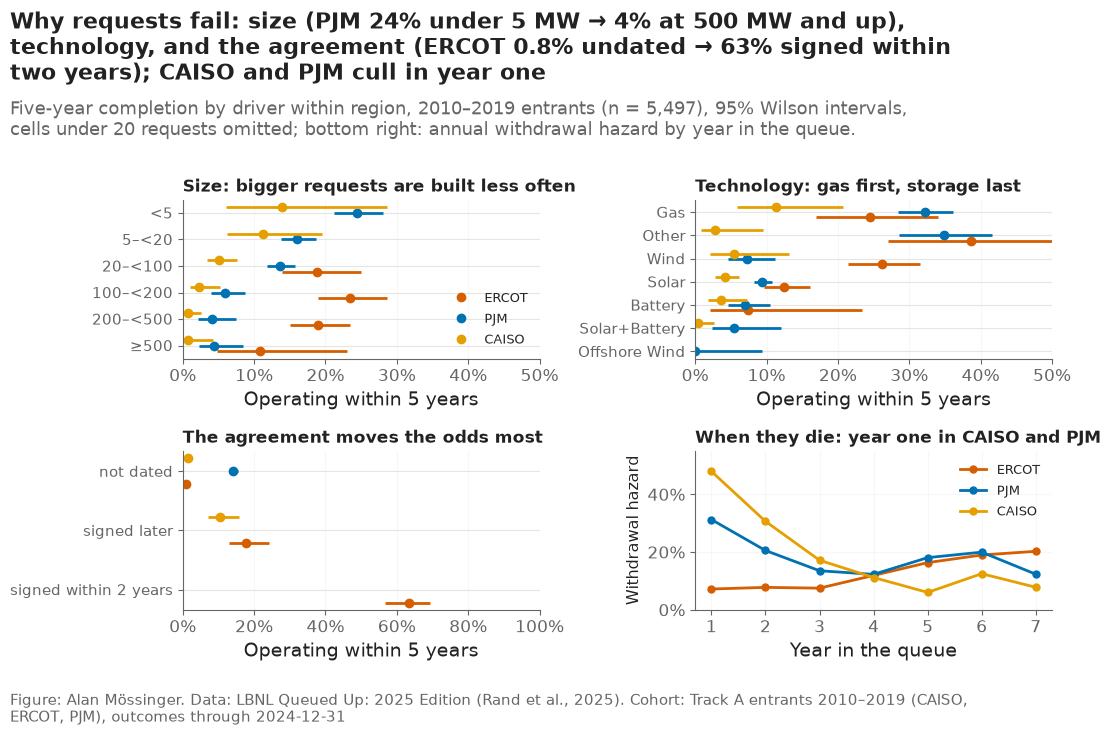

In [72]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.4))
offsets = {"ERCOT": 0.22, "PJM": 0.0, "CAISO": -0.22}


def driver_panel(ax, driver, levels, title, xmax):
    sub = drv[(drv["driver"] == driver) & ~drv["thin"]]
    for region in REGIONS:
        r = sub[sub["region"] == region].set_index("level").reindex(levels)
        y = np.arange(len(levels)) + offsets[region]
        ax.hlines(y, r["low"], r["high"], color=RC[region], lw=2)
        ax.plot(r["rate"], y, "o", color=RC[region], ms=6, label=region)
    ax.set_yticks(np.arange(len(levels))); ax.set_yticklabels(levels, fontsize=10.5); ax.invert_yaxis()
    ax.set_xlim(0, xmax); ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_xlabel("Operating within 5 years"); ax.set_title(title, fontsize=12.5, loc="left"); ax.grid(axis="x", alpha=0.3)


driver_panel(axes[0, 0], "Size at entry (MW)", config.SIZE_LABELS, "Size: bigger requests are built less often", 0.5)
driver_panel(axes[0, 1], "Technology", ["Gas", "Other", "Wind", "Solar", "Battery", "Solar+Battery", "Offshore Wind"], "Technology: gas first, storage last", 0.5)
driver_panel(axes[1, 0], "Agreement (2025 file)", ["not dated", "signed later", "signed within 2 years"], "The agreement moves the odds most", 1.0)
axes[0, 0].legend(frameon=False, fontsize=9.5, loc="lower right")
ax = axes[1, 1]
for region in REGIONS:
    h = hz[hz["region"] == region]
    ax.plot(h["year_in_queue"], h["h_withdrawal"], "-o", color=RC[region], lw=2, ms=5, label=f"{region}")
ax.set_ylim(0, 0.55); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("Year in the queue"); ax.set_ylabel("Withdrawal hazard")
ax.set_title("When they die: year one in CAISO and PJM", fontsize=12.5, loc="left")
ax.legend(frameon=False, fontsize=9.5); ax.grid(alpha=0.3)
plots.finish(fig, f"Why requests fail: size (PJM {size_pjm_small:.0%} under 5 MW → {size_pjm_big:.0%} at 500 MW and up), technology, and the agreement (ERCOT {ia_ercot_none:.1%} undated → {ia_ercot_in2:.0%} signed within two years); CAISO and PJM cull in year one",
             "Five-year completion by driver within region, 2010–2019 entrants (n = 5,497), 95% Wilson intervals, cells under 20 requests omitted; bottom right: annual withdrawal hazard by year in the queue.",
             "Track A entrants 2010–2019 (CAISO, ERCOT, PJM), outcomes through 2024-12-31")
dsave(fig, "D3_why", "Decision 3, why requests fail: five-year completion by size, technology and the executed agreement within each region, and the annual withdrawal hazard by year in the queue.")
plt.show()

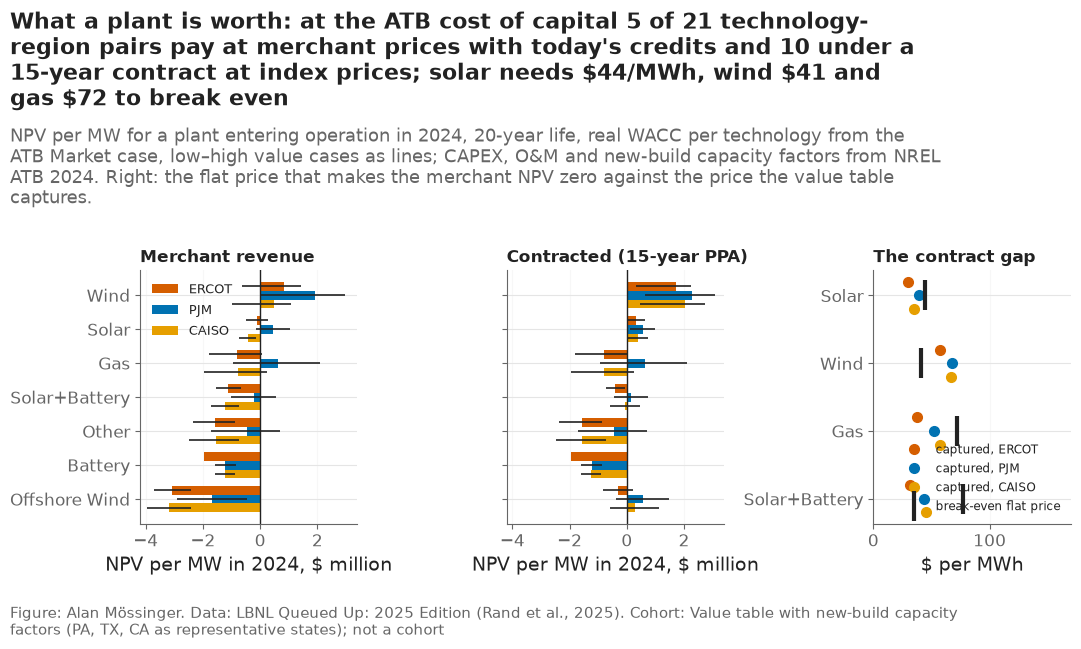

In [73]:
fig, axes = plt.subplots(1, 3, figsize=(11, 6.5), gridspec_kw={"width_ratios": [1.1, 1.1, 1]})
order = ["Wind", "Solar", "Gas", "Solar+Battery", "Other", "Battery", "Offshore Wind"]
width = 0.26
at = n24.set_index(["tech", "region"])
for ax, col, title in [(axes[0], "npv_per_mw", "Merchant revenue"), (axes[1], "npv_contracted", "Contracted (15-year PPA)")]:
    y = np.arange(len(order))
    for k, region in enumerate(REGIONS):
        part = at.xs(region, level="region").reindex(order)
        yy = y + (k - 1) * width
        ax.barh(yy, part[f"{col}_base"] / 1e6, height=width, color=RC[region], label=region)
        ax.hlines(yy, part[f"{col}_low"] / 1e6, part[f"{col}_high"] / 1e6, color=plots.INK, lw=1.2)
    ax.axvline(0, color=plots.INK, lw=1)
    ax.set_yticks(y); ax.set_yticklabels(order if ax is axes[0] else [""] * len(order)); ax.invert_yaxis()
    ax.set_xlim(-4.2, 3.4)
    ax.set_xlabel("NPV per MW in 2024, \\$ million")
    ax.set_title(title, fontsize=12.5, loc="left")
    ax.grid(axis="x", alpha=0.3)
axes[0].legend(frameon=False, fontsize=9.5, loc="upper left")
ax = axes[2]
techs = ["Solar", "Wind", "Gas", "Solar+Battery"]
y = np.arange(len(techs))
for k, region in enumerate(REGIONS):
    cap = [at.loc[(t, region), "captured_price_base"] for t in techs]
    ax.plot(cap, y + (k - 1) * 0.2, "o", color=RC[region], ms=7, label=f"captured, {region}")
ax.plot([at.loc[(t, "PJM"), "breakeven_price_base"] for t in techs], y, "|", color=plots.INK, ms=22, mew=3, label="break-even flat price")
ax.set_yticks(y); ax.set_yticklabels(techs); ax.invert_yaxis()
ax.set_xlim(0, 170); ax.set_xlabel("\\$ per MWh")
ax.set_title("The contract gap", fontsize=12.5, loc="left")
ax.legend(frameon=False, fontsize=8.5, loc="lower right"); ax.grid(axis="x", alpha=0.3)
plots.finish(fig, f"What a plant is worth: at the ATB cost of capital {positive24} of 21 technology-region pairs pay at merchant prices with today's credits and {positive24c} under a 15-year contract at index prices; solar needs \\${be['Solar']:.0f}/MWh, wind \\${be['Wind']:.0f} and gas \\${be['Gas']:.0f} to break even",
             "NPV per MW for a plant entering operation in 2024, 20-year life, real WACC per technology from the ATB Market case, low–high value cases as lines; CAPEX, O&M and new-build capacity factors from NREL ATB 2024. Right: the flat price that makes the merchant NPV zero against the price the value table captures.",
             "Value table with new-build capacity factors (PA, TX, CA as representative states); not a cohort")
dsave(fig, "D4_worth", "Decision 4, what a plant is worth: NPV per MW by technology and region at a 2024 operation date under merchant and contracted revenue, and the break-even flat price against the captured energy price.")
plt.show()

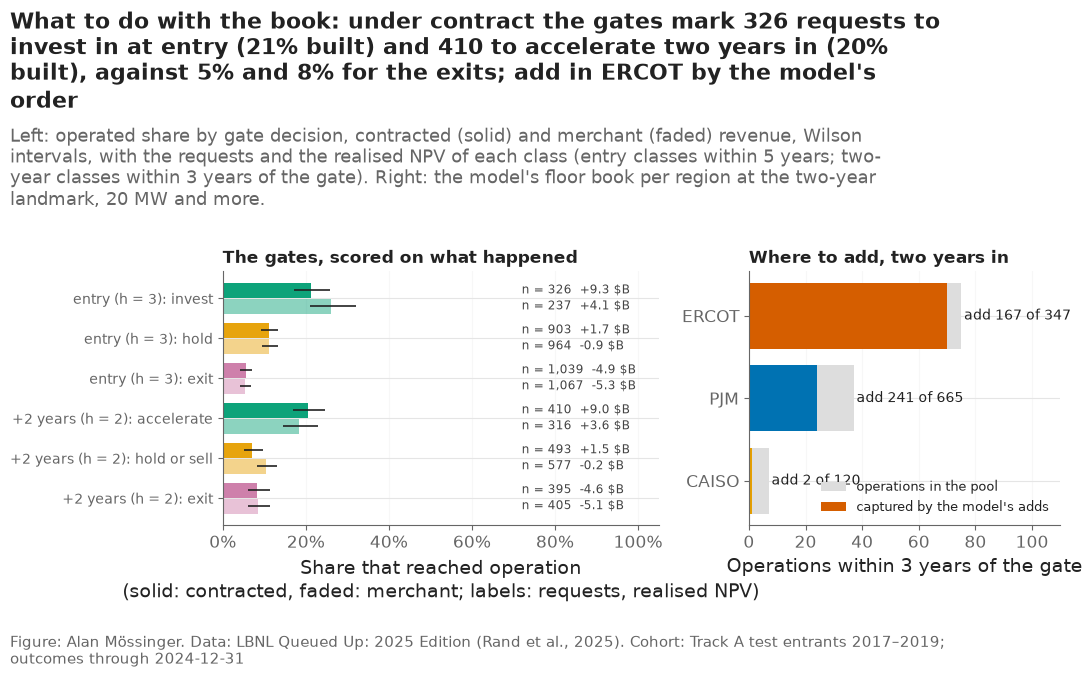

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.8), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
rows = [("G1 entry", "invest"), ("G1 entry", "hold"), ("G1 entry", "exit"), ("G2 two years", "accelerate"), ("G2 two years", "hold or sell"), ("G2 two years", "exit")]
palette = {"invest": "#009E73", "accelerate": "#009E73", "hold": "#E69F00", "hold or sell": "#E69F00", "exit": "#CC79A7"}
y = np.arange(len(rows))
for rc, dy, alpha, marker in [("contracted", -0.2, 0.95, "o"), ("merchant", 0.2, 0.45, "s")]:
    sel = pd.concat([gate_tab[(g, rc)].loc[[d_]] for g, d_ in rows])
    ax.barh(y + dy, sel["operated_share"], height=0.38, color=[palette[d_] for _, d_ in rows], alpha=alpha, label=f"{rc} revenue")
    ax.hlines(y + dy, sel["low"], sel["high"], color=plots.INK, lw=1.2)
    for yy, (_, r) in zip(y + dy, sel.iterrows()):
        ax.text(0.72, yy, f"n = {int(r['n']):,}  {r['realised_npv_$M'] / 1e3:+.1f} \\$B", va="center", fontsize=8.5, color="#444444")
ax.set_yticks(y); ax.set_yticklabels([f"{'entry (h = 3)' if g == 'G1 entry' else '+2 years (h = 2)'}: {d_}" for g, d_ in rows], fontsize=10); ax.invert_yaxis()
ax.set_xlim(0, 1.05); ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Share that reached operation" + chr(10) + "(solid: contracted, faded: merchant; labels: requests, realised NPV)"); ax.set_title("The gates, scored on what happened", fontsize=12.5, loc="left"); ax.grid(axis="x", alpha=0.3)
ax = axes[1]
y = np.arange(3)
ax.barh(y, bm.loc[REGIONS, "pool_operations"], color="#DDDDDD", label="operations in the pool")
ax.barh(y, bm.loc[REGIONS, "realised_operations"], color=[RC[r] for r in REGIONS], label="captured by the model's adds")
for yy, r in zip(y, REGIONS):
    ax.text(bm.loc[r, "pool_operations"] + 1, yy, f"add {int(bm.loc[r, 'requests_added'])} of {int(bm.loc[r, 'pool_requests'])}", va="center", fontsize=10)
ax.set_yticks(y); ax.set_yticklabels(REGIONS); ax.invert_yaxis()
ax.set_xlim(0, 110); ax.set_xlabel("Operations within 3 years of the gate")
ax.set_title("Where to add, two years in", fontsize=12.5, loc="left"); ax.legend(frameon=False, fontsize=9, loc="lower right"); ax.grid(axis="x", alpha=0.3)
plots.finish(fig, f"What to do with the book: under contract the gates mark {int(g1.loc['invest', 'n'])} requests to invest in at entry ({g1.loc['invest', 'operated_share']:.0%} built) and {int(g2.loc['accelerate', 'n'])} to accelerate two years in ({g2.loc['accelerate', 'operated_share']:.0%} built), against {g1.loc['exit', 'operated_share']:.0%} and {g2.loc['exit', 'operated_share']:.0%} for the exits; add in ERCOT by the model's order",
             "Left: operated share by gate decision, contracted (solid) and merchant (faded) revenue, Wilson intervals, with the requests and the realised NPV of each class (entry classes within 5 years; two-year classes within 3 years of the gate). Right: the model's floor book per region at the two-year landmark, 20 MW and more.",
             "Track A test entrants 2017–2019; outcomes through 2024-12-31")
dsave(fig, "D5_book", "Decision 5, the book: the gate classes scored on what happened under contracted and merchant revenue, and the model's floor book per region two years in.")
plt.show()

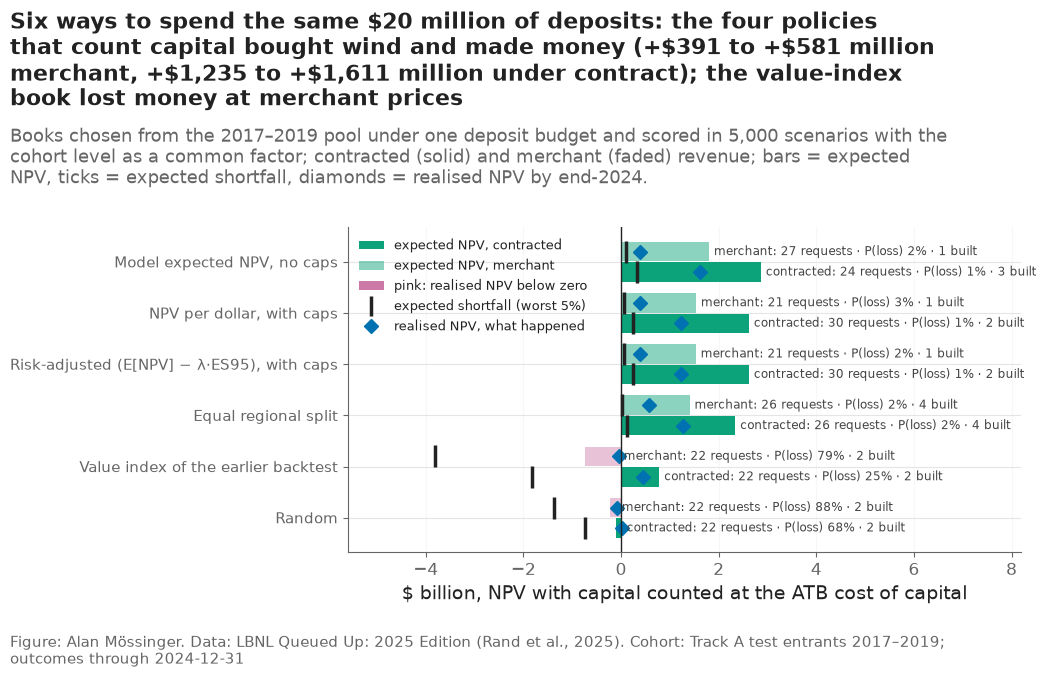

In [75]:
fig, ax = plt.subplots(figsize=(11, 6.8))
short = {"equal regional split": "Equal regional split", "NPV per dollar, with caps": "NPV per dollar, with caps", "model expected NPV, no caps": "Model expected NPV, no caps",
         "risk-adjusted (E[NPV] − λ·ES95), with caps": "Risk-adjusted (E[NPV] − λ·ES95), with caps", "fair baseline, value index (section 5)": "Value index of the earlier backtest", "random (section 5)": "Random"}
p = pol.copy()
p["label"] = p["policy"].map(short)
order_pol = p[p["revenue_case"] == "contracted"].sort_values("expected_npv_$M")["label"].tolist()
y = np.arange(len(order_pol))
for rc, dy, alpha in [("contracted", -0.2, 0.95), ("merchant", 0.2, 0.45)]:
    q = p[p["revenue_case"] == rc].set_index("label").loc[order_pol]
    colours = ["#009E73" if v > 0 else "#CC79A7" for v in q["realised_npv_$M"]]
    ax.barh(y + dy, q["expected_npv_$M"] / 1e3, height=0.38, color=colours, alpha=alpha, label=f"expected NPV, {rc}")
    ax.plot(q["es95_$M"] / 1e3, y + dy, "|", color=plots.INK, ms=16, mew=2.5, label="expected shortfall (worst 5%)" if rc == "contracted" else None)
    ax.plot(q["realised_npv_$M"] / 1e3, y + dy, "D", color="#0072B2", ms=7, label="realised NPV, what happened" if rc == "contracted" else None)
    for yy, (_, r) in zip(y + dy, q.iterrows()):
        ax.text(max(r["expected_npv_$M"], r["realised_npv_$M"]) / 1e3 + 0.1, yy, f"{rc}: {int(r['requests'])} requests · P(loss) {r['p_negative_npv']:.0%} · {int(r['realised_operations_5yr'])} built", va="center", fontsize=8.5, color="#444444")
ax.axvline(0, color=plots.INK, lw=1)
ax.set_yticks(y); ax.set_yticklabels(order_pol, fontsize=10.5)
ax.set_xlim(-5.6, 8.2)  # room for the labels on the right; the legend sits in the empty space left of zero on the top rows
ax.set_xlabel("\\$ billion, NPV with capital counted at the ATB cost of capital")
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#009E73", alpha=0.95, label="expected NPV, contracted"), Patch(color="#009E73", alpha=0.45, label="expected NPV, merchant"), Patch(color="#CC79A7", label="pink: realised NPV below zero"),
                   Line2D([], [], color=plots.INK, marker="|", ms=14, mew=2.5, ls="none", label="expected shortfall (worst 5%)"), Line2D([], [], color="#0072B2", marker="D", ms=7, ls="none", label="realised NPV, what happened")],
          frameon=False, fontsize=9, loc="upper left")
ax.grid(axis="x", alpha=0.3)
NPV_POLICIES = ["Equal regional split", "NPV per dollar, with caps", "Model expected NPV, no caps", "Risk-adjusted (E[NPV] − λ·ES95), with caps"]
pc = p[(p["revenue_case"] == "contracted") & p["label"].isin(NPV_POLICIES)]
pm = p[(p["revenue_case"] == "merchant") & p["label"].isin(NPV_POLICIES)]
old_book = p[(p["revenue_case"] == "contracted") & (p["label"] == "Value index of the earlier backtest")]["realised_npv_$M"].iloc[0]
plots.finish(fig, f"Six ways to spend the same \${BUDGET_M:.0f} million of deposits: the four policies that count capital bought wind and made money (+\${pm['realised_npv_$M'].min():,.0f} to +\${pm['realised_npv_$M'].max():,.0f} million merchant, +\${pc['realised_npv_$M'].min():,.0f} to +\${pc['realised_npv_$M'].max():,.0f} million under contract); the value-index book lost money at merchant prices",
             "Books chosen from the 2017–2019 pool under one deposit budget and scored in 5,000 scenarios with the cohort level as a common factor; contracted (solid) and merchant (faded) revenue; bars = expected NPV, ticks = expected shortfall, diamonds = realised NPV by end-2024.",
             "Track A test entrants 2017–2019; outcomes through 2024-12-31")
dsave(fig, "D6_policies", "Decision 5, continued: six allocation policies under the same deposit budget, contracted and merchant revenue: expected NPV, expected shortfall and realised NPV.")
plt.show()

**Reading this.** The seven images carry the report's decisions one per page: D0 the board, D1 where (ERCOT and the PJM core; CAISO only with an agreement), D2 which and when (the model at AUC 0.86 against 0.73 at entry, the agreement two years in, the level that fell by half), D3 why (size, technology, the agreement; year one in CAISO and PJM, after year four in ERCOT), D4 worth (five of 21 pairs positive at merchant prices; break-even solar $57, wind $51, gas $80 per MWh) D5 the book (the gate classes, where to add) and D6 the six ways to spend the same budget. Every number on them is read from a result table in this run, so they change when the results change.

## 5. Checks

In [76]:
checks = pd.DataFrame([
    {"check": "decision board: seven images saved as PNG and SVG", "value": 14,
     "pass": all((paths.FIGURES / f"{n}.{ext}").exists() for n in ["D0_decision_board", "D1_where", "D2_which_and_when", "D3_why", "D4_worth", "D5_book", "D6_policies"] for ext in ["png", "svg"])},
    {"check": "every registered criterion is scored on each of its horizons", "value": f"{len(scored)} lines scored for {len(criteria)} registered rows",
     "pass": len(scored) == sum(len(str(h).split(", ")) if cid not in ("C8", "C9", "C10", "C11", "C12") else {"C8": 2, "C9": 1, "C10": 1, "C11": 1, "C12": 1}[cid]
                                for cid, h in zip(criteria["id"], criteria["horizons"]))},
    {"check": "no registered line dropped", "value": sorted(scored["id"].unique()), "pass": set(scored["id"]) == set(criteria["id"])},
    {"check": "the v1 verdict file is untouched (8 of 12)", "value": int((v1["result"] == "PASS").sum()), "pass": int((v1["result"] == "PASS").sum()) == 8 and len(v1) == 12},
])
checks.to_csv(R / "evaluate_v2_checks.csv", index=False)
assert checks["pass"].all(), checks
checks

,check,value,pass
0,decision board: seven images saved as PNG and SVG,14,True
1,every registered criterion is scored on each of its horizons,12 lines scored for 8 registered rows,True
2,no registered line dropped,"[C10, C11, C12, C6, C7, C8, C9]",True
3,the v1 verdict file is untouched (8 of 12),8,True


## Takeaways — Part D

- 3 of 12 pre-registered v2 lines pass: the landmark gain at +24 months (C8), the simulated band's coverage (C11) and the leakage guard (C12).
- At entry, for utility-scale requests, the model and the fair baseline are indistinguishable (C6 0 of 4); the level stays too high after repair (C7 0 of 2); the registered backtest is a tie (C9, C10).
- The v1 verdict (8 of 12) is untouched and reported beside the v2 one; the difference is the benchmark and the question, not the model.
- Track B's calibrated LightGBM tracks the observed share built across its bins (figure 18_02).
- **What goes to the report:** the scored table and figure 18_01; the two-verdict summary; the sentence that the value of the model is at the milestones, not at entry.

## Takeaways

- **Part A** — Evaluation on the held-out cohorts: its *Takeaways — Part A* cell above says what it found and what goes to the report.
- **Part B** — Post-hoc improvements (labelled post-hoc): its *Takeaways — Part B* cell above says what it found and what goes to the report.
- **Part C** — What drives the predictions, and what a developer would do with them: its *Takeaways — Part C* cell above says what it found and what goes to the report.
- **Part D** — The v2 verdict: criteria C6–C12 scored as registered: its *Takeaways — Part D* cell above says what it found and what goes to the report.

**What goes to the report.** Report figures drawn here: F5_auc_brier_by_horizon, F4_calibration_by_horizon, F22_tournament, F6_hazard_ratios, F7_shap_summary. Every number the report cites from this notebook is read from `results/` by `src/report_numbers.py`.